<a href="https://colab.research.google.com/github/rissl/PINNs/blob/master/Clean_PINN_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# =========================================================
# Cell 1 — Imports + Device setup (Colab T4)
# =========================================================
import os
import numpy as np
import scipy.io as sio
import torch
import torch.nn as nn
import time
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import matplotlib.animation as animation
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator
from IPython.display import clear_output
import matplotlib as mpl
from concurrent.futures import ThreadPoolExecutor
from google.colab import drive


# --- Device ---
if torch.cuda.is_available():
    device = "cuda"
    torch.backends.cudnn.benchmark = True
    print(f"Using GPU : {torch.cuda.get_device_name(0)}")
    print(f"VRAM total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    device = "cpu"
    print("CUDA not available — using CPU")

# --- CPU threading (Colab has 2 vCPUs) ---
N_IO_WORKERS    = 4    # parallel .mat file loaders
N_TORCH_THREADS = 2    # Colab only has 2 vCPUs
torch.set_num_threads(N_TORCH_THREADS)
print(f"I/O loader workers  : {N_IO_WORKERS}")
print(f"PyTorch CPU threads : {torch.get_num_threads()}")

# --- VRAM helpers ---
def print_vram():
    if device == "cuda":
        alloc    = torch.cuda.memory_allocated()  / 1e6
        reserved = torch.cuda.memory_reserved()   / 1e6
        total    = torch.cuda.get_device_properties(0).total_memory / 1e6
        print(f"VRAM — allocated: {alloc:.0f} MB | "
              f"reserved: {reserved:.0f} MB | "
              f"total: {total:.0f} MB | "
              f"free: {total - reserved:.0f} MB")

VRAM_SAFETY_MB = 2000

def should_pin_to_gpu(tensor_list):
    if device == "cpu":
        return False
    total_mb = sum(t.element_size() * t.nelement() / 1e6 for t in tensor_list)
    free_mb  = (torch.cuda.get_device_properties(0).total_memory
                - torch.cuda.memory_reserved()) / 1e6
    fits     = total_mb < (free_mb - VRAM_SAFETY_MB)
    print(f"Data tensors total : {total_mb:.0f} MB")
    print(f"VRAM free          : {free_mb:.0f} MB")
    print(f"Pin to GPU         : {fits}")
    return fits

def to_gpu(t):
    """Move tensor to GPU only if data is stored on CPU."""
    return t.to(device) if t.device.type == "cpu" else t

print("\nSetup complete")
print_vram()

Using GPU : Tesla T4
VRAM total: 15.6 GB
I/O loader workers  : 4
PyTorch CPU threads : 2

Setup complete
VRAM — allocated: 0 MB | reserved: 0 MB | total: 15637 MB | free: 15637 MB


In [2]:
# =========================================================
# Cell 2 — Settings
# =========================================================
drive.mount('/content/drive')


DATA_DIR = "/content/drive/MyDrive/PINN/"

straight_files = [
    "LPBF_PINN_set_1_corner_x+.mat",
    "LPBF_PINN_set_1_corner_x-.mat",
    "LPBF_PINN_set_1_corner_y+.mat",
    "LPBF_PINN_set_1_corner_y-.mat",

    "LPBF_PINN_set_2_edgexc_x+.mat",
    "LPBF_PINN_set_2_edgexc_x-.mat",
    "LPBF_PINN_set_2_edgexc_y+.mat",
    "LPBF_PINN_set_2_edgexc_y-.mat",

    "LPBF_PINN_set_3_edgeyc_x+.mat",
    "LPBF_PINN_set_3_edgeyc_x-.mat",
    "LPBF_PINN_set_3_edgeyc_y+.mat",
    "LPBF_PINN_set_3_edgeyc_y-.mat",

    "LPBF_PINN_set_4_center_x+.mat",
    "LPBF_PINN_set_4_center_x-.mat",
    "LPBF_PINN_set_4_center_y+.mat",
    "LPBF_PINN_set_4_center_y-.mat",
   ]
turnaround_files = [
    "LPBF_PINN_set_5_turnaround_center_up.mat",
    "LPBF_PINN_set_5_turnaround_corner_up.mat",
    "LPBF_PINN_set_5_turnaround_edgexc_up.mat",
    "LPBF_PINN_set_5_turnaround_edgeyc_up.mat",

    "LPBF_PINN_set_6_turnaround_center_right.mat",
    "LPBF_PINN_set_6_turnaround_corner_right.mat",
    "LPBF_PINN_set_6_turnaround_edgexc_right.mat",
    "LPBF_PINN_set_6_turnaround_edgeyc_right.mat",
]

diagonal_files = [
    "LPBF_PINN_set_7_xy--.mat",
    "LPBF_PINN_set_7_xy+-.mat",
    "LPBF_PINN_set_7_xy-+.mat",
    "LPBF_PINN_set_7_xy++.mat",
]
Power_files = [
    "LPBF_PINN_set_9_P150.mat",
    "LPBF_PINN_set_9_P250.mat",
    "LPBF_PINN_set_9_P150_diagonal.mat",
    "LPBF_PINN_set_9_P250_diagonal.mat",
]
test=["Triangle_Serial_Structured.mat"]

# experiment_sim= ["experiment_ap_0_s1_pi3_np32.mat"]

experiment_sim= ["new opt.mat"]

triangle= [
    "Triangle_Reverse_s1_pi3_np32.mat",
           ]

EXP_FILE = ["Experimental_Solved_Data_3.mat" ]
run_files = diagonal_files + Power_files +straight_files

TRAIN_FILE = ["Experimental_Solved_Data_2.mat"]
VAL_FILE   = ["Experimental_Solved_Data_3.mat" ]

run_files= EXP_FILE
Tamb   = 295.0
plateX = 0.05
plateY = 0.05

print(f"Runs to load: {len(run_files)}")
for f in run_files:
    print(f"  {f}")

Mounted at /content/drive
Runs to load: 1
  Experimental_Solved_Data_3.mat


In [3]:
# =========================================================
# Cell 3 — Load and align all runs  (+ FRACTION_TO_USE trim)
# =========================================================
all_runs = []
DATA_MODE = "sim"   # ← "sim" (nodes in plate frame) or "experimental" (nodes laser-relative)
FRACTION_TO_USE = 1   # ← keep this fraction of the time steps (1.0 = all)


def load_single_run(fname):
    mat_r = sio.loadmat(os.path.join(DATA_DIR, fname),
                        struct_as_record=False, squeeze_me=True)
    allT_r      = np.asarray(mat_r["allT"])
    phase_r     = np.asarray(mat_r["PHASE_time"])
    xPath_r     = np.asarray(mat_r["xPath"]).reshape(-1)
    yPath_r     = np.asarray(mat_r["yPath"]).reshape(-1)
    tPath_r     = np.asarray(mat_r["tPath"]).reshape(-1)
    Power_r     = np.asarray(mat_r["Power"]).reshape(-1)
    meshNodes_r = np.asarray(mat_r["meshNodes"])
    xNodes_r    = meshNodes_r[0, :].reshape(-1)
    yNodes_r    = meshNodes_r[1, :].reshape(-1)
    Nnodes_r    = len(xNodes_r)

    T_r = allT_r if allT_r.shape[0] == Nnodes_r else allT_r.T

    phase_tmp_r = phase_r if phase_r.shape[0] == Nnodes_r else phase_r.T
    Nt_T = T_r.shape[1]; Nt_P = phase_tmp_r.shape[1]
    if Nt_P == Nt_T:
        PHASE_r = phase_tmp_r
    elif Nt_P == Nt_T - 1:
        PHASE_r = np.hstack([phase_tmp_r[:, [0]], phase_tmp_r])
    else:
        PHASE_r = np.zeros_like(T_r)

    # --- trim to a fraction of the time steps (keep the FIRST fraction) ---
    Nt_full = T_r.shape[1]
    n_keep  = max(2, int(FRACTION_TO_USE * Nt_full))
    xPath_r = xPath_r[:n_keep]
    yPath_r = yPath_r[:n_keep]
    tPath_r = tPath_r[:n_keep]
    Power_r = Power_r[:n_keep] if Power_r.size > 1 else Power_r
    T_r     = T_r[:, :n_keep]
    PHASE_r = PHASE_r[:, :n_keep]

    return {
        'fname'  : fname,
        'xPath'  : xPath_r, 'yPath': yPath_r, 'tPath': tPath_r, 'Power': Power_r,
        'T'      : T_r, 'PHASE': PHASE_r,
        'xNodes' : xNodes_r, 'yNodes': yNodes_r, 'Nnodes': Nnodes_r,
        'Ts'     : float(np.asarray(mat_r["Ts"]).reshape(-1)[0]),
        'Tl'     : float(np.asarray(mat_r["Tl"]).reshape(-1)[0]),
        'Lfus'   : float(np.asarray(mat_r["Lfus"]).reshape(-1)[0]),
    }

with ThreadPoolExecutor(max_workers=N_IO_WORKERS) as ex:
    all_runs = list(ex.map(load_single_run, run_files))

for run in all_runs:
    print(f"Loaded {run['fname']}: {run['Nnodes']} nodes, {run['T'].shape[1]} steps "
          f"(fraction={FRACTION_TO_USE})")
print(f"\nTotal runs loaded: {len(all_runs)}")

# =========================================================
# Set evaluation run
# =========================================================
eval_run_idx = 0
xNodes           = all_runs[eval_run_idx]['xNodes']
yNodes           = all_runs[eval_run_idx]['yNodes']
Nnodes           = all_runs[eval_run_idx]['Nnodes']
T_nodes_time     = all_runs[eval_run_idx]['T']
PHASE_nodes_time = all_runs[eval_run_idx]['PHASE']
xPath            = all_runs[eval_run_idx]['xPath']
yPath            = all_runs[eval_run_idx]['yPath']
tPath            = all_runs[eval_run_idx]['tPath']
Power            = all_runs[eval_run_idx]['Power']
t_start          = tPath[0]

dt_eval = np.diff(tPath)
vx_path = np.concatenate([[0], np.diff(xPath) / dt_eval])
vy_path = np.concatenate([[0], np.diff(yPath) / dt_eval])

print(f"\nEvaluation run : {all_runs[eval_run_idx]['fname']}")
print(f"  Nodes        : {Nnodes}")
print(f"  Steps        : {len(tPath)}")
print(f"  x range      : [{xPath.min()*1000:.2f}, {xPath.max()*1000:.2f}] mm")
print(f"  y range      : [{yPath.min()*1000:.2f}, {yPath.max()*1000:.2f}] mm")

Ts   = all_runs[0]['Ts']; Tl = all_runs[0]['Tl']; Lfus = all_runs[0]['Lfus']
print(f"Ts={Ts}K  Tl={Tl}K  Lfus={Lfus}J/kg")

Loaded new opt.mat: 8338 nodes, 9153 steps (fraction=1)

Total runs loaded: 1

Evaluation run : new opt.mat
  Nodes        : 8338
  Steps        : 9153
  x range      : [29.77, 30.49] mm
  y range      : [6.05, 27.95] mm
Ts=1533.0K  Tl=1609.0K  Lfus=209200.0J/kg


In [3]:
!pip install mat73

In [ ]:
# =========================================================
# Load TWO experimental sets: training + validation
#   train_run = file to learn from ; val_run = held-out for validation loss
# =========================================================
DATA_MODE = "experimental"
FRACTION_TO_USE_TRAIN = 0.025
FRACTION_TO_USE_VAL = 0.92

TRAIN_FILE = "Experimental_Solved_Data_2.mat"   # <-- your training .mat
VAL_FILE   = "Experimental_Solved_Data_3.mat"   # <-- your validation .mat (different build/scan)

def loadmat_any(path):
    try: return sio.loadmat(path, struct_as_record=False, squeeze_me=True)
    except NotImplementedError:
        import mat73; return mat73.loadmat(path)
def to_dict(obj):
    return obj if isinstance(obj,dict) else {f:getattr(obj,f) for f in obj._fieldnames}

def load_single_run(fname):
    mat_r = loadmat_any(os.path.join(DATA_DIR, fname))
    top=[k for k in mat_r.keys() if not k.startswith('__')]
    if len(top)==1 and 'xPath' not in mat_r: mat_r=to_dict(mat_r[top[0]])
    allT_r=np.asarray(mat_r["allT"]); phase_r=np.asarray(mat_r["PHASE_time"])
    xPath_r=np.asarray(mat_r["xPath"]).reshape(-1); yPath_r=np.asarray(mat_r["yPath"]).reshape(-1)
    tPath_r=np.asarray(mat_r["tPath"]).reshape(-1); Power_r=np.asarray(mat_r["Power"]).reshape(-1)
    meshNodes_r=np.asarray(mat_r["meshNodes"])
    xNodes_r=meshNodes_r[0,:].reshape(-1); yNodes_r=meshNodes_r[1,:].reshape(-1); Nnodes_r=len(xNodes_r)
    T_r=allT_r if allT_r.shape[0]==Nnodes_r else allT_r.T
    phase_tmp=phase_r if phase_r.shape[0]==Nnodes_r else phase_r.T
    Nt_T=T_r.shape[1]; Nt_P=phase_tmp.shape[1]
    if Nt_P==Nt_T: PHASE_r=phase_tmp
    elif Nt_P==Nt_T-1: PHASE_r=np.hstack([phase_tmp[:,[0]],phase_tmp])
    else: PHASE_r=np.zeros_like(T_r)
    return {'fname':fname,'xPath':xPath_r,'yPath':yPath_r,'tPath':tPath_r,'Power':Power_r,
            'T':T_r,'PHASE':PHASE_r,'xNodes':xNodes_r,'yNodes':yNodes_r,'Nnodes':Nnodes_r,
            'Ts':float(np.asarray(mat_r["Ts"]).reshape(-1)[0]),
            'Tl':float(np.asarray(mat_r["Tl"]).reshape(-1)[0]),
            'Lfus':float(np.asarray(mat_r["Lfus"]).reshape(-1)[0])}

def trim(run, frac):
    n=max(2,int(frac*len(run['tPath'])))
    run['xPath']=run['xPath'][:n]; run['yPath']=run['yPath'][:n]; run['tPath']=run['tPath'][:n]
    run['Power']=run['Power'][:n] if run['Power'].size>1 else run['Power']
    run['T']=run['T'][:,:n]; run['PHASE']=run['PHASE'][:,:n]
    return run

train_run = trim(load_single_run(TRAIN_FILE), FRACTION_TO_USE_TRAIN)
val_run   = trim(load_single_run(VAL_FILE),   FRACTION_TO_USE_VAL)

print(f"TRAIN: {train_run['fname']}  {train_run['Nnodes']} nodes, {train_run['T'].shape[1]} steps")
print(f"VAL  : {val_run['fname']}  {val_run['Nnodes']} nodes, {val_run['T'].shape[1]} steps")
print(f"train dt={np.diff(train_run['tPath']).mean()*1e6:.1f}us  val dt={np.diff(val_run['tPath']).mean()*1e6:.1f}us")

# material props (from train run)
Ts=train_run['Ts']; Tl=train_run['Tl']; Lfus=train_run['Lfus']
print(f"Ts={Ts}K Tl={Tl}K Lfus={Lfus}J/kg")
# =========================================================
# Set globals from the TRAIN run (matches original loader's downstream vars)
# =========================================================
run = train_run
xNodes           = run['xNodes']
yNodes           = run['yNodes']
Nnodes           = run['Nnodes']
T_nodes_time     = run['T']
PHASE_nodes_time = run['PHASE']
xPath            = run['xPath']
yPath            = run['yPath']
tPath            = run['tPath']
Power            = run['Power']
t_start          = tPath[0]

# velocity for the train run
dt_eval = np.diff(tPath); dt_eval = np.where(dt_eval<1e-12, 1e-12, dt_eval)
vx_path = np.concatenate([[0], np.diff(xPath)/dt_eval])
vy_path = np.concatenate([[0], np.diff(yPath)/dt_eval])

# also keep a combined all_runs so existing cells (rollout cache, Stage-2) work:
all_runs = [train_run, val_run]       # index 0 = train, index 1 = validation
eval_run_idx = 0
# attach velocities to each run (Stage-2 cache uses run['vx_path'])
for r in all_runs:
    de=np.diff(r['tPath']); de=np.where(de<1e-12,1e-12,de)
    r['vx_path']=np.concatenate([[0],np.diff(r['xPath'])/de]).astype(np.float32)
    r['vy_path']=np.concatenate([[0],np.diff(r['yPath'])/de]).astype(np.float32)

print(f"Globals set from TRAIN run: {run['fname']}  ({Nnodes} nodes, {len(tPath)} steps)")
print(f"all_runs: [0]=train ({all_runs[0]['fname']}), [1]=val ({all_runs[1]['fname']})")

KeyboardInterrupt: 

In [4]:
# =========================================================
# Cell 3 — Load and align all runs (EXPERIMENTAL)
# =========================================================
all_runs = []
DATA_MODE = "experimental"   # ← "sim" (nodes in plate frame) or "experimental" (nodes laser-relative)
FRACTION_TO_USE = 0.92 # ~2.5% -> ~651 of 26049 steps or 92% for layer 3


def loadmat_any(path):
    """v7 and earlier -> scipy; v7.3 (HDF5) -> mat73."""
    try:
        return sio.loadmat(path, struct_as_record=False, squeeze_me=True)
    except NotImplementedError:
        import mat73
        return mat73.loadmat(path)

def to_dict(obj):
    if isinstance(obj, dict):
        return obj
    return {f: getattr(obj, f) for f in obj._fieldnames}

def load_single_run(fname):
    mat_r = loadmat_any(os.path.join(DATA_DIR, fname))
    top = [k for k in mat_r.keys() if not k.startswith('__')]
    if len(top) == 1 and 'xPath' not in mat_r:      # unwrap solved_data struct
        mat_r = to_dict(mat_r[top[0]])

    allT_r      = np.asarray(mat_r["allT"])
    phase_r     = np.asarray(mat_r["PHASE_time"])
    xPath_r     = np.asarray(mat_r["xPath"]).reshape(-1)
    yPath_r     = np.asarray(mat_r["yPath"]).reshape(-1)
    tPath_r     = np.asarray(mat_r["tPath"]).reshape(-1)
    Power_r     = np.asarray(mat_r["Power"]).reshape(-1)
    meshNodes_r = np.asarray(mat_r["meshNodes"])
    xNodes_r    = meshNodes_r[0, :].reshape(-1)
    yNodes_r    = meshNodes_r[1, :].reshape(-1)
    Nnodes_r    = len(xNodes_r)

    T_r = allT_r if allT_r.shape[0] == Nnodes_r else allT_r.T

    phase_tmp_r = phase_r if phase_r.shape[0] == Nnodes_r else phase_r.T
    Nt_T = T_r.shape[1]
    Nt_P = phase_tmp_r.shape[1]
    if Nt_P == Nt_T:
        PHASE_r = phase_tmp_r
    elif Nt_P == Nt_T - 1:
        PHASE_r = np.hstack([phase_tmp_r[:, [0]], phase_tmp_r])
    else:
        PHASE_r = np.zeros_like(T_r)

    return {
        'fname'  : fname,
        'xPath'  : xPath_r,
        'yPath'  : yPath_r,
        'tPath'  : tPath_r,
        'Power'  : Power_r,
        'T'      : T_r,
        'PHASE'  : PHASE_r,
        'xNodes' : xNodes_r,
        'yNodes' : yNodes_r,
        'Nnodes' : Nnodes_r,
        'Ts'     : float(np.asarray(mat_r["Ts"]).reshape(-1)[0]),
        'Tl'     : float(np.asarray(mat_r["Tl"]).reshape(-1)[0]),
        'Lfus'   : float(np.asarray(mat_r["Lfus"]).reshape(-1)[0]),
    }

# parallel load
with ThreadPoolExecutor(max_workers=N_IO_WORKERS) as ex:
    all_runs = list(ex.map(load_single_run, run_files))

# --- keep only the first FRACTION_TO_USE of steps (memory) ---
for run in all_runs:
    n_use = max(2, int(FRACTION_TO_USE * len(run['tPath'])))
    run['xPath'] = run['xPath'][:n_use]
    run['yPath'] = run['yPath'][:n_use]
    run['tPath'] = run['tPath'][:n_use]
    run['Power'] = run['Power'][:n_use] if run['Power'].size > 1 else run['Power']
    run['T']     = run['T'][:, :n_use]
    run['PHASE'] = run['PHASE'][:, :n_use]
    print(f"Loaded {run['fname']}: {run['Nnodes']} nodes, {run['T'].shape[1]} steps kept "
          f"(of {len(run['tPath']) if False else n_use})")

# print(f"\nTotal runs loaded: {len(all_runs)}  (FRACTION_TO_USE={FRACTION_TO_USE})")
# all_runs = []
# DATA_MODE = "experimental"

# # --- per-file fraction: {filename: fraction} ---
# FRACTIONS = {
#     "Experimental_Solved_Data_2.mat": 0.025,   # train file — 2.5%
#     "Experimental_Solved_Data_3.mat": 0.92,    # val file — 92% (layer 3)
# }
# DEFAULT_FRACTION = 1.0     # used if a file isn't in FRACTIONS

# def loadmat_any(path):
#     try:
#         return sio.loadmat(path, struct_as_record=False, squeeze_me=True)
#     except NotImplementedError:
#         import mat73
#         return mat73.loadmat(path)

# def to_dict(obj):
#     if isinstance(obj, dict): return obj
#     return {f: getattr(obj, f) for f in obj._fieldnames}

# def load_single_run(fname):
#     mat_r = loadmat_any(os.path.join(DATA_DIR, fname))
#     top = [k for k in mat_r.keys() if not k.startswith('__')]
#     if len(top) == 1 and 'xPath' not in mat_r:
#         mat_r = to_dict(mat_r[top[0]])
#     allT_r      = np.asarray(mat_r["allT"])
#     phase_r     = np.asarray(mat_r["PHASE_time"])
#     xPath_r     = np.asarray(mat_r["xPath"]).reshape(-1)
#     yPath_r     = np.asarray(mat_r["yPath"]).reshape(-1)
#     tPath_r     = np.asarray(mat_r["tPath"]).reshape(-1)
#     Power_r     = np.asarray(mat_r["Power"]).reshape(-1)
#     meshNodes_r = np.asarray(mat_r["meshNodes"])
#     xNodes_r    = meshNodes_r[0, :].reshape(-1)
#     yNodes_r    = meshNodes_r[1, :].reshape(-1)
#     Nnodes_r    = len(xNodes_r)
#     T_r = allT_r if allT_r.shape[0] == Nnodes_r else allT_r.T
#     phase_tmp_r = phase_r if phase_r.shape[0] == Nnodes_r else phase_r.T
#     Nt_T = T_r.shape[1]; Nt_P = phase_tmp_r.shape[1]
#     if Nt_P == Nt_T:
#         PHASE_r = phase_tmp_r
#     elif Nt_P == Nt_T - 1:
#         PHASE_r = np.hstack([phase_tmp_r[:, [0]], phase_tmp_r])
#     else:
#         PHASE_r = np.zeros_like(T_r)
#     return {
#         'fname'  : fname,
#         'xPath'  : xPath_r, 'yPath': yPath_r, 'tPath': tPath_r, 'Power': Power_r,
#         'T'      : T_r, 'PHASE': PHASE_r,
#         'xNodes' : xNodes_r, 'yNodes': yNodes_r, 'Nnodes': Nnodes_r,
#         'Ts'     : float(np.asarray(mat_r["Ts"]).reshape(-1)[0]),
#         'Tl'     : float(np.asarray(mat_r["Tl"]).reshape(-1)[0]),
#         'Lfus'   : float(np.asarray(mat_r["Lfus"]).reshape(-1)[0]),
#     }

# # parallel load
# with ThreadPoolExecutor(max_workers=N_IO_WORKERS) as ex:
#     all_runs = list(ex.map(load_single_run, run_files))

# # --- trim each run by ITS OWN fraction ---
# for run in all_runs:
#     frac = FRACTIONS.get(run['fname'], DEFAULT_FRACTION)
#     n_use = max(2, int(frac * len(run['tPath'])))
#     run['xPath'] = run['xPath'][:n_use]
#     run['yPath'] = run['yPath'][:n_use]
#     run['tPath'] = run['tPath'][:n_use]
#     run['Power'] = run['Power'][:n_use] if run['Power'].size > 1 else run['Power']
#     run['T']     = run['T'][:, :n_use]
#     run['PHASE'] = run['PHASE'][:, :n_use]
#     print(f"Loaded {run['fname']}: {run['Nnodes']} nodes, {run['T'].shape[1]} steps kept "
#           f"(fraction={frac})")

# print(f"\nTotal runs loaded: {len(all_runs)}")
# ========================================================= (unchanged below)
eval_run_idx     = 0

xNodes           = all_runs[eval_run_idx]['xNodes']
yNodes           = all_runs[eval_run_idx]['yNodes']
Nnodes           = all_runs[eval_run_idx]['Nnodes']
T_nodes_time     = all_runs[eval_run_idx]['T']
PHASE_nodes_time = all_runs[eval_run_idx]['PHASE']
xPath            = all_runs[eval_run_idx]['xPath']
yPath            = all_runs[eval_run_idx]['yPath']
tPath            = all_runs[eval_run_idx]['tPath']
Power            = all_runs[eval_run_idx]['Power']
t_start          = tPath[0]

dt_eval = np.diff(tPath)
vx_path = np.concatenate([[0], np.diff(xPath) / dt_eval])
vy_path = np.concatenate([[0], np.diff(yPath) / dt_eval])

print(f"\nEvaluation run : {all_runs[eval_run_idx]['fname']}")
print(f"  Nodes        : {Nnodes}")
print(f"  Steps        : {len(tPath)}")
print(f"  x range      : [{xPath.min()*1000:.2f}, {xPath.max()*1000:.2f}] mm")
print(f"  y range      : [{yPath.min()*1000:.2f}, {yPath.max()*1000:.2f}] mm")

Ts   = all_runs[0]['Ts']
Tl   = all_runs[0]['Tl']
Lfus = all_runs[0]['Lfus']
print(f"Ts={Ts}K  Tl={Tl}K  Lfus={Lfus}J/kg")


# =========================================================
# Remove empty (pre-laser) frames + reset time to 0 at first real frame
#   "empty" = thermal field at ambient (laser not yet heating),
#   even though power may be logged. Operates on all_runs[eval_run_idx].
# =========================================================
AMBIENT_MARGIN = 50.0     # a frame is "empty" if max(T) < Tamb + this

run = all_runs[eval_run_idx]
T_r  = run['T']
Nt   = T_r.shape[1]

# max temperature per frame
frame_maxT = T_r.max(axis=0)

# first frame where the field actually heats up (laser started)
hot_frames = np.where(frame_maxT > 1270 + AMBIENT_MARGIN)[0]
if len(hot_frames)==0:
    print("WARNING: no hot frames found — check AMBIENT_MARGIN / data")
else:
    k0 = hot_frames[0]
    print(f"first real (hot) frame: {k0}  (removing {k0} empty frames before it)")
    print(f"  frame {k0-1} maxT={frame_maxT[max(k0-1,0)]:.0f}K  ->  frame {k0} maxT={frame_maxT[k0]:.0f}K")

    # --- trim all per-frame arrays from k0 onward ---
    run['T']     = run['T'][:, k0:]
    run['PHASE'] = run['PHASE'][:, k0:]
    run['xPath'] = run['xPath'][k0:]
    run['yPath'] = run['yPath'][k0:]
    run['tPath'] = run['tPath'][k0:]
    run['Power'] = run['Power'][k0:] if run['Power'].size>1 else run['Power']

    # --- reset time to start at 0 ---
    run['tPath'] = run['tPath'] - run['tPath'][0]

    # --- refresh the eval globals from the trimmed run ---
    T_nodes_time     = run['T']
    PHASE_nodes_time = run['PHASE']
    xPath            = run['xPath']
    yPath            = run['yPath']
    tPath            = run['tPath']
    Power            = run['Power']
    t_start          = tPath[0]           # now 0

    # --- recompute velocities on the trimmed/retimed path ---
    dt_eval = np.diff(tPath); dt_eval = np.where(dt_eval<1e-12, 1e-12, dt_eval)
    vx_path = np.concatenate([[0], np.diff(xPath)/dt_eval])
    vy_path = np.concatenate([[0], np.diff(yPath)/dt_eval])
    run['vx_path'] = vx_path.astype(np.float32)
    run['vy_path'] = vy_path.astype(np.float32)

    print(f"\nAfter trim:")
    print(f"  frames: {Nt} -> {run['T'].shape[1]}")
    print(f"  tPath : [{tPath[0]*1e3:.3f}, {tPath[-1]*1e3:.3f}] ms  (reset to start at 0)")
    print(f"  first frame maxT: {run['T'][:,0].max():.0f}K")

Loaded Experimental_Solved_Data_3.mat: 12544 nodes, 644 steps kept (of 644)

Evaluation run : Experimental_Solved_Data_3.mat
  Nodes        : 12544
  Steps        : 644
  x range      : [29.77, 30.49] mm
  y range      : [6.05, 27.95] mm
Ts=1533.0K  Tl=1609.0K  Lfus=209200.0J/kg
first real (hot) frame: 7  (removing 7 empty frames before it)
  frame 6 maxT=273K  ->  frame 7 maxT=2105K

After trim:
  frames: 644 -> 637
  tPath : [0.000, 317.650] ms  (reset to start at 0)
  first frame maxT: 2105K


In [5]:
patch_half_width  = 0.0025/2
patch_half_height = 0.0025/2
patch_offset      = 0.000   # 0.1mm backward offset

# patch_half_width  = 0.00023
# patch_half_height = 0.00023
# patch_offset      = 0.00003   # 0.1mm backward offset

def get_patch_mask(xN, yN, xL, yL, hx, hy,
                   xL_patch=None, yL_patch=None):
    """
    Return boolean mask for nodes inside the laser patch.
    xL_patch, yL_patch: patch center (may differ from laser position)
    """
    if xL_patch is None:
        xL_patch = xL
    if yL_patch is None:
        yL_patch = yL
    return (
        (xN >= xL_patch - hx) & (xN <= xL_patch + hx) &
        (yN >= yL_patch - hy) & (yN <= yL_patch + hy)
    )

def get_scan_direction(k):
    """Return normalised scan direction at step k."""
    if k == 0:
        k = 1
    vx = xPath[k] - xPath[k-1]
    vy = yPath[k] - yPath[k-1]
    speed = np.sqrt(vx**2 + vy**2) + 1e-12
    return vx / speed, vy / speed

def get_patch_center(k, offset=patch_offset):
    """Return patch center offset backward from laser."""
    vx_n, vy_n = get_scan_direction(k)
    xL = xPath[k];  yL = yPath[k]
    return xL - offset * vx_n, yL - offset * vy_n


def get_patch_boundary_mask(xP, yP, xL, yL, hx, hy, tol=1e-5):
    left   = np.isclose(xP, xL - hx, atol=tol)
    right  = np.isclose(xP, xL + hx, atol=tol)
    bottom = np.isclose(yP, yL - hy, atol=tol)
    top    = np.isclose(yP, yL + hy, atol=tol)
    return left | right | bottom | top


def get_segment_starts(vx_arr, vy_arr):
    segs = [0]
    for k in range(1, len(vx_arr)):
        prev_dom_y = abs(vy_arr[k-1]) > abs(vx_arr[k-1])
        curr_dom_y = abs(vy_arr[k])   > abs(vx_arr[k])
        if prev_dom_y != curr_dom_y:
            segs.append(k)
        elif (abs(vy_arr[k])>0.3 and abs(vy_arr[k-1])>0.3 and
              np.sign(vy_arr[k]) != np.sign(vy_arr[k-1])):
            segs.append(k)
        elif (abs(vx_arr[k])>0.3 and abs(vx_arr[k-1])>0.3 and
              np.sign(vx_arr[k]) != np.sign(vx_arr[k-1])):
            segs.append(k)
    return segs

def get_t_feat_segment(k, tPath_arr, seg_starts, TAU=0.5e-3):
    seg_start = 0
    for s in reversed(seg_starts):
        if k >= s:
            seg_start = s
            break
    t_rel = float(tPath_arr[k]) - float(tPath_arr[seg_start])
    return np.tanh(t_rel / TAU)

In [6]:
# compute velocity components at each time step
dt_path = np.diff(tPath)   # time step sizes
vx_path = np.diff(xPath) / dt_path   # x velocity m/s
vy_path = np.diff(yPath) / dt_path   # y velocity m/s

# prepend first value to match tPath length
vx_path = np.concatenate([[vx_path[0]], vx_path])
vy_path = np.concatenate([[vy_path[0]], vy_path])

print(f"Velocity range:")
print(f"  vx: [{vx_path.min():.3f}, {vx_path.max():.3f}] m/s")
print(f"  vy: [{vy_path.min():.3f}, {vy_path.max():.3f}] m/s")
print(f"  speed: [{np.sqrt(vx_path**2+vy_path**2).min():.3f}, "
      f"{np.sqrt(vx_path**2+vy_path**2).max():.3f}] m/s")


# compute minimum distance from each node to any laser position
threshold = 0.01  # 3 beam widths

min_dist_to_laser = np.full(Nnodes, np.inf)
for k in range(len(tPath)):
    dist = np.sqrt((xNodes - xPath[k])**2 + (yNodes - yPath[k])**2)
    min_dist_to_laser = np.minimum(min_dist_to_laser, dist)

was_melted_geom = (min_dist_to_laser < threshold).astype(float)
print(f"Threshold         : {threshold*1000:.3f} mm")
print(f"Nodes ever melted : {was_melted_geom.sum():.0f} out of {Nnodes}")
print(f"Fraction melted   : {was_melted_geom.mean():.3f}")


# compute was_melted for evaluation run mesh
min_dist_eval = np.full(Nnodes, np.inf)
for k in range(len(tPath)):
    dist = np.sqrt((xNodes - xPath[k])**2 +
                   (yNodes - yPath[k])**2)
    min_dist_eval = np.minimum(min_dist_eval, dist)
was_melted_geom = (min_dist_eval < threshold).astype(float)
print(f"Eval run nodes ever melted: {was_melted_geom.sum():.0f} / {Nnodes}")

Velocity range:
  vx: [-0.181, 0.000] m/s
  vy: [-0.905, 0.604] m/s
  speed: [0.000, 0.905] m/s
Threshold         : 10.000 mm
Nodes ever melted : 0 out of 12544
Fraction melted   : 0.000
Eval run nodes ever melted: 0 / 12544


In [7]:
# =========================================================
# Cell 5 — Data assembly (no BC, 2kHz + startup,
#           thermal-history-based was_melted)
# =========================================================
#DATA_MODE = "sim"   # ← "sim" (nodes in plate frame) or "experimental" (nodes laser-relative)

plateX = 0.05
plateY = 0.05
#TAU    = 4*10**(-3)
TAU = 0.1
V_MAX  = 0.65

# sampling settings
fs_sim        = 28000
fs_exp        = 2000
step_interval = int(fs_sim / fs_exp)   # 14 — regular 2kHz
step_interval=1
N_STARTUP     = 1 # it was 50

print(f"DATA_MODE   : {DATA_MODE}")
print(f"Subsampling : every {step_interval} steps ({fs_exp}Hz)")
print(f"Startup     : first {N_STARTUP} steps at full resolution")

# Remove stale assembly variables from previous executions.
for variable_name in [
    "X_data",
    "Y_data",
    "was_melted_batch_all",
    "sample_run_id",
    "sample_step_id",
]:
    globals().pop(variable_name, None)

X_list = []
Y_list = []
WM_list = []
RUN_ID_list = []
STEP_ID_list = []

for run_idx, run in enumerate(all_runs):
    xPath_r   = run['xPath'];  yPath_r = run['yPath']
    tPath_r   = run['tPath'];  Power_r = run['Power']
    T_r       = run['T']
    xNodes_r  = run['xNodes']; yNodes_r = run['yNodes']
    t_start_r = tPath_r[0]

    # velocity — clip to V_MAX
    dt_r = np.diff(tPath_r)
    dt_r = np.where(dt_r < 1e-12, 1e-12, dt_r)
    vx_r = np.clip(np.concatenate([[0], np.diff(xPath_r) / dt_r]),
                   -V_MAX, V_MAX)
    vy_r = np.clip(np.concatenate([[0], np.diff(yPath_r) / dt_r]),
                   -V_MAX, V_MAX)
    run["vx_path"] = vx_r.astype(np.float32)
    run["vy_path"] = vy_r.astype(np.float32)

    # thermal-history-based was_melted — reset per run
    ever_melted_r = np.zeros(run['Nnodes'], dtype=bool)

    # build step list: startup at full res + corner steps + regular 2kHz
    # startup_steps = list(range(1, min(N_STARTUP + 1, len(tPath_r))))
    # corner_steps  = [k for k in range(len(tPath_r))
    #                  if abs(vx_r[k]) > 0.3 and abs(vy_r[k]) > 0.3]
    # regular_steps = list(range(N_STARTUP + 1, len(tPath_r), step_interval))
    # all_steps     = sorted(set(startup_steps + corner_steps + regular_steps))
    regular_steps = list(range(step_interval, len(tPath_r), step_interval))
    all_steps     = regular_steps

    fname = run['fname'].split('/')[-1][:40]
    print(f"  {fname:<40}: "
          f"{len(tPath_r)} steps → "
          # f"{len(startup_steps)} startup + "
          # f"{len(corner_steps)} corner + "
          f"{len(regular_steps)} regular = "
          f"{len(all_steps)} total")

    for k in range(len(tPath_r)):
        # update thermal history up to step k (all steps, not just sampled)
        ever_melted_r |= (T_r[:, k] >= Tl)

        # only assemble data for sampled steps
        if k not in all_steps:
            continue
        if k == 0:
            continue

        xL     = xPath_r[k];  yL = yPath_r[k]
        t_rel  = tPath_r[k] - t_start_r
        t_feat = np.tanh(t_rel / TAU)
        p      = Power_r[k] if Power_r.size > 1 else float(Power_r[0])
        vx     = float(vx_r[k]);  vy = float(vy_r[k])

        vx_n     = vx / (np.sqrt(vx**2 + vy**2) + 1e-12)
        vy_n     = vy / (np.sqrt(vx**2 + vy**2) + 1e-12)

        # ---- FRAME-DEPENDENT: patch mask ----
        if DATA_MODE == "experimental":
            # nodes are laser-relative -> mask in local frame (laser at 0,0)
            xL_patch = -patch_offset * vx_n
            yL_patch = -patch_offset * vy_n
            mask_patch = get_patch_mask(xNodes_r, yNodes_r, 0.0, 0.0,
                                        patch_half_width, patch_half_height,
                                        xL_patch, yL_patch)
        else:
            # sim: nodes in absolute plate frame
            xL_patch = xL - patch_offset * vx_n
            yL_patch = yL - patch_offset * vy_n
            mask_patch = get_patch_mask(xNodes_r, yNodes_r, xL, yL,
                                        patch_half_width, patch_half_height,
                                        xL_patch, yL_patch)
        if mask_patch.sum() == 0:
            continue

        xPatch = xNodes_r[mask_patch];  yPatch = yNodes_r[mask_patch]

        # ---- FRAME-DEPENDENT: dx/dy and edge distance ----
        if DATA_MODE == "experimental":
            dx = xPatch * 1000                 # already laser-relative
            dy = yPatch * 1000
            xabs = xPatch + xL                 # reconstruct absolute for edge dist
            yabs = yPatch + yL
            dist_x_patch = np.minimum(xabs, plateX - xabs) * 1000
            dist_y_patch = np.minimum(yabs, plateY - yabs) * 1000
        else:
            dx = (xPatch - xL) * 1000
            dy = (yPatch - yL) * 1000
            dist_x_patch = np.minimum(xPatch, plateX - xPatch) * 1000
            dist_y_patch = np.minimum(yPatch, plateY - yPatch) * 1000

        # Temperature at the same material nodes one simulation step earlier.
        # H_STEPS =step_interval  # horizon: predict T(k) from T(k - H_STEPS). 1 = your current 1-step map.
        H_STEPS =1
# ... inside the per-k loop, replace the T_previous block with:
        if k - H_STEPS < 0:
            continue                      # not enough history for this horizon
        T_previous = np.clip(
              T_r[mask_patch, k - H_STEPS].reshape(-1), Tamb, None
        ) - Tamb


        Xk = np.column_stack([
            np.full_like(xPatch, t_feat),
            dx, dy,
            np.full_like(xPatch, p),
            dist_x_patch, dist_y_patch,
            np.full_like(xPatch, vx),
            np.full_like(xPatch, vy),
            T_previous,
        ])
        Tk = np.clip(T_r[mask_patch, k].reshape(-1, 1), Tamb, None) - Tamb
        # T_now  = np.clip(T_r[mask_patch, k].reshape(-1), Tamb, None)
        # T_prev = np.clip(T_r[mask_patch, k - H_STEPS].reshape(-1), Tamb, None)
        # Tk = (T_now - T_prev).reshape(-1, 1)        # RESIDUAL target: change over the step



        # thermal-history was_melted for this patch at this timestep
        was_melted_patch = ever_melted_r[mask_patch].astype(float)

        X_list.append(Xk)
        Y_list.append(Tk)
        WM_list.append(was_melted_patch)

        n_patch = Xk.shape[0]

        RUN_ID_list.append(
            np.full(n_patch, run_idx, dtype=np.int32)
        )

        STEP_ID_list.append(
            np.full(n_patch, k, dtype=np.int32)
        )

# ---------------------------------------------------------
# Combine assembled patches
# ---------------------------------------------------------
X_data = np.vstack(X_list).astype(np.float64)
Y_data = np.vstack(Y_list).astype(np.float64)

# true absolute temperature at each sample = previous ΔT (input col 8) + residual change + ambient
# T_abs_samples = X_data[:, 8] + Y_data.reshape(-1) + Tamb

was_melted_batch_all = np.concatenate(
    WM_list
).astype(np.float32)

sample_run_id = np.concatenate(
    RUN_ID_list
).astype(np.int32)

sample_step_id = np.concatenate(
    STEP_ID_list
).astype(np.int32)

print("\nAssembly sizes:")
print("X_data                 :", X_data.shape)
print("Y_data                 :", Y_data.shape)
print("was_melted_batch_all   :", was_melted_batch_all.shape)
print("sample_run_id          :", sample_run_id.shape)
print("sample_step_id         :", sample_step_id.shape)

assert X_data.shape[0] == Y_data.shape[0], (
    f"X_data has {X_data.shape[0]} rows, "
    f"but Y_data has {Y_data.shape[0]}"
)

assert X_data.shape[0] == was_melted_batch_all.shape[0], (
    f"X_data has {X_data.shape[0]} rows, "
    f"but was_melted has {was_melted_batch_all.shape[0]}"
)

assert X_data.shape[0] == sample_run_id.shape[0], (
    f"X_data has {X_data.shape[0]} rows, "
    f"but run IDs have {sample_run_id.shape[0]}"
)

assert X_data.shape[0] == sample_step_id.shape[0], (
    f"X_data has {X_data.shape[0]} rows, "
    f"but step IDs have {sample_step_id.shape[0]}"
)

print("All assembly arrays have matching lengths.")

print(f"Stored run IDs  : {sample_run_id.shape}")
print(f"Stored step IDs : {sample_step_id.shape}")

print(f"\nX_data shape : {X_data.shape}")
print(f"Y_data shape : {Y_data.shape}")
print(f"t_feat range : [{X_data[:,0].min():.4f}, {X_data[:,0].max():.4f}]")
print(f"T range      : [{(Y_data+Tamb).min():.1f}, {(Y_data+Tamb).max():.1f}] K")
print(f"was_melted=1 : {(was_melted_batch_all>0).sum():,} "
      f"({(was_melted_batch_all>0).mean()*100:.1f}%)")
print(f"was_melted=0 : {(was_melted_batch_all==0).sum():,} "
      f"({(was_melted_batch_all==0).mean()*100:.1f}%)")

# --- step-based transient/steady split ---
dt_mean    = float(np.diff(all_runs[0]['tPath']).mean())
t_rel_70   = 70 * dt_mean
TAU_THRESH = float(np.tanh(t_rel_70 / TAU))
print(f"\ndt_mean    : {dt_mean*1e6:.2f} μs")
print(f"t_rel_70   : {t_rel_70*1e3:.3f} ms")
print(f"TAU_THRESH : {TAU_THRESH:.4f}")

trans_mask     = X_data[:, 0] < TAU_THRESH
steady_mask    = ~trans_mask
trans_indices  = np.where(trans_mask)[0]
steady_indices = np.where(steady_mask)[0]
hot_mask       = Y_data.reshape(-1) > 1500
hot_indices    = np.where(hot_mask)[0]
steady_hot     = np.intersect1d(steady_indices, hot_indices)

print(f"Transient  : {trans_mask.sum():,} ({trans_mask.mean()*100:.1f}%)")
print(f"Steady     : {steady_mask.sum():,} ({steady_mask.mean()*100:.1f}%)")
print(f"Hot        : {hot_mask.sum():,}")
print(f"Steady+hot : {len(steady_hot):,}")

DATA_MODE   : experimental
Subsampling : every 1 steps (2000Hz)
Startup     : first 1 steps at full resolution
  Experimental_Solved_Data_3.mat          : 637 steps → 636 regular = 636 total

Assembly sizes:
X_data                 : (7977984, 9)
Y_data                 : (7977984, 1)
was_melted_batch_all   : (7977984,)
sample_run_id          : (7977984,)
sample_step_id         : (7977984,)
All assembly arrays have matching lengths.
Stored run IDs  : (7977984,)
Stored step IDs : (7977984,)

X_data shape : (7977984, 9)
Y_data shape : (7977984, 1)
t_feat range : [0.0050, 0.9965]
T range      : [295.0, 4037.1] K
was_melted=1 : 6,907,582 (86.6%)
was_melted=0 : 1,070,402 (13.4%)

dt_mean    : 499.45 μs
t_rel_70   : 34.962 ms
TAU_THRESH : 0.3360
Transient  : 878,080 (11.0%)
Steady     : 7,099,904 (89.0%)
Hot        : 900,672
Steady+hot : 808,097


In [8]:
# =========================================================
# Rebalance X_data by velocity direction group
# =========================================================

# recompute normalization and indices — required after rebalancing
X_mean = X_data.mean(axis=0, keepdims=True)
X_std  = X_data.std(axis=0,  keepdims=True)
X_std  = np.where(X_std < 1e-8, 1.0, X_std)
Y_mean = Y_data.mean(keepdims=True)
Y_std  = Y_data.std(keepdims=True)

# fix t_feat normalization — independent of dataset composition
X_mean[0, 0] = 0.0
X_std[0, 0]  = 1.0
print(f"t_feat normalization fixed: mean=0, std=1")
print(f"t_feat=0 in normalized space: {(0.0-X_mean[0,0])/X_std[0,0]:.4f}")  # → 0.0

dt_mean    = float(np.diff(all_runs[0]['tPath']).mean())
t_rel_70   = 70 * dt_mean
TAU_THRESH = float(np.tanh(t_rel_70 / TAU))

trans_mask     = X_data[:, 0] < TAU_THRESH
steady_mask    = ~trans_mask
trans_indices  = np.where(trans_mask)[0]
steady_indices = np.where(steady_mask)[0]
hot_mask       = Y_data.reshape(-1) > 1500
hot_indices    = np.where(hot_mask)[0]
steady_hot     = np.intersect1d(steady_indices, hot_indices)

print(f"\nNew X_mean: {X_mean}")
print(f"New X_std : {X_std}")
print(f"Steady+hot: {len(steady_hot):,}")

t_feat normalization fixed: mean=0, std=1
t_feat=0 in normalized space: 0.0000

New X_mean: [[ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.90000000e+02
   1.98653781e+01  1.66802863e+01 -2.27026229e-03 -4.18500645e-02
   7.16721229e+02]]
New X_std : [[1.00000000e+00 7.20966276e-01 7.20966276e-01 1.00000000e+00
  7.55457695e-01 5.70757198e+00 1.87474037e-02 5.95115899e-01
  7.05253905e+02]]
Steady+hot: 808,097


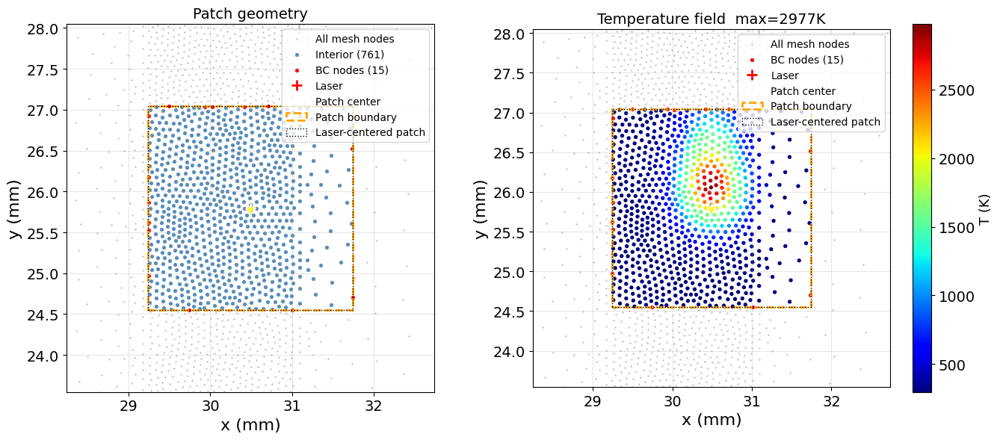

Patch stats:
  Total nodes  : 776
  Interior     : 761
  Boundary     : 15
  Offset       : 0.0mm backward
  Scan dir     : (0.000, -1.000)
  T max        : 2977.5 K
  T min        : 294.9 K
  Nodes > Tl   : 67
  Nodes > Ts   : 103


In [ ]:
def plot_training_patch(k, show_background=True):

    FONTSIZE    = 16
    TITLE_FS    = 14
    SUPTITLE_FS = 18
    LEGEND_FS   = 10
    CBAR_FS     = 13

    xL = xPath[k];  yL = yPath[k]
    p  = Power[k] if Power.size > 1 else float(Power[0])

    xL_patch, yL_patch = get_patch_center(k)
    mask_patch = get_patch_mask(xNodes, yNodes, xL, yL,
                                patch_half_width, patch_half_height,
                                xL_patch, yL_patch)
    bnd_mask = get_patch_boundary_mask(
        xNodes[mask_patch], yNodes[mask_patch],
        xL_patch, yL_patch, patch_half_width, patch_half_height
    )

    xPatch = xNodes[mask_patch];  yPatch = yNodes[mask_patch]
    xBnd   = xPatch[bnd_mask];    yBnd   = yPatch[bnd_mask]
    xInt   = xPatch[~bnd_mask];   yInt   = yPatch[~bnd_mask]
    T_patch = T_nodes_time[mask_patch, k]
    T_int   = T_patch[~bnd_mask]

    vx_n, vy_n = get_scan_direction(k)
    margin = patch_half_width * 0.8

    # Convert to mm
    xL_mm       = xL       * 1000;  yL_mm       = yL       * 1000
    xL_patch_mm = xL_patch * 1000;  yL_patch_mm = yL_patch * 1000
    xNodes_mm   = xNodes   * 1000;  yNodes_mm   = yNodes   * 1000
    xInt_mm     = xInt     * 1000;  yInt_mm     = yInt     * 1000
    xBnd_mm     = xBnd     * 1000;  yBnd_mm     = yBnd     * 1000
    margin_mm   = margin   * 1000
    phw_mm      = patch_half_width  * 1000
    phh_mm      = patch_half_height * 1000

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    '''fig.suptitle(
        f"Training patch — k={k}  t={tPath[k]:.4f}s  "
        f"laser=({xL:.4f},{yL:.4f})  "
        f"patch center=({xL_patch:.4f},{yL_patch:.4f})  "
        f"nodes={mask_patch.sum()}",
        fontsize=SUPTITLE_FS
    )'''

    for ax_idx, (ax, show_T) in enumerate(zip(axes, [False, True])):

        ax.scatter(xNodes_mm, yNodes_mm, s=1, color='grey',
                   alpha=0.3, label='All mesh nodes')

        if show_T:
            sc = ax.scatter(xInt_mm, yInt_mm, c=T_int, cmap='jet', s=8,
                            vmin=Tamb, vmax=T_nodes_time[:, k].max())
            cbar = fig.colorbar(sc, ax=ax)
            cbar.set_label("T (K)", fontsize=CBAR_FS)
            cbar.ax.tick_params(labelsize=FONTSIZE - 2)
        else:
            ax.scatter(xInt_mm, yInt_mm, s=8, color='steelblue', alpha=0.8,
                       label=f'Interior ({(~bnd_mask).sum()})')

        ax.scatter(xBnd_mm, yBnd_mm, s=8, color='red', alpha=0.9,
                   label=f'BC nodes ({bnd_mask.sum()})')

        ax.plot(xL_mm, yL_mm, 'r+', ms=10, mew=2, label='Laser')
        ax.plot(xL_patch_mm, yL_patch_mm, 'w+', ms=10, mew=2, label='Patch center')

        ax.annotate('', xy=(xL_mm + 0.1*vx_n, yL_mm + 0.1*vy_n),
                    xytext=(xL_mm, yL_mm),
                    arrowprops=dict(arrowstyle='->', color='yellow', lw=2))

        ax.add_patch(plt.Rectangle(
            (xL_patch_mm - phw_mm, yL_patch_mm - phh_mm),
            2*phw_mm, 2*phh_mm,
            fill=False, edgecolor='orange',
            linewidth=2, linestyle='--', label='Patch boundary'
        ))
        ax.add_patch(plt.Rectangle(
            (xL_mm - phw_mm, yL_mm - phh_mm),
            2*phw_mm, 2*phh_mm,
            fill=False, edgecolor='black',
            linewidth=1, linestyle=':', label='Laser-centered patch'
        ))

        ax.set_xlabel("x (mm)", fontsize=FONTSIZE)
        ax.set_ylabel("y (mm)", fontsize=FONTSIZE)
        ax.tick_params(axis="both", labelsize=FONTSIZE - 2)
        titles = ["Patch geometry", f"Temperature field  max={T_nodes_time[mask_patch,k].max():.0f}K"]
        ax.set_title(titles[ax_idx], fontsize=TITLE_FS)
        ax.legend(fontsize=LEGEND_FS, loc='upper right')
        ax.set_aspect("equal")
        ax.set_xlim(xL_patch_mm - phw_mm - margin_mm,
                    xL_patch_mm + phw_mm + margin_mm)
        ax.set_ylim(yL_patch_mm - phh_mm - margin_mm,
                    yL_patch_mm + phh_mm + margin_mm)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    fig.savefig("Patch_Area.png", dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Patch stats:")
    print(f"  Total nodes  : {mask_patch.sum()}")
    print(f"  Interior     : {(~bnd_mask).sum()}")
    print(f"  Boundary     : {bnd_mask.sum()}")
    print(f"  Offset       : {patch_offset*1000:.1f}mm backward")
    print(f"  Scan dir     : ({vx_n:.3f}, {vy_n:.3f})")
    print(f"  T max        : {T_nodes_time[mask_patch, k].max():.1f} K")
    print(f"  T min        : {T_nodes_time[mask_patch, k].min():.1f} K")
    print(f"  Nodes > Tl   : {(T_nodes_time[mask_patch, k] >= Tl).sum()}")
    print(f"  Nodes > Ts   : {(T_nodes_time[mask_patch, k] >= Ts).sum()}")

plot_training_patch(k=100)

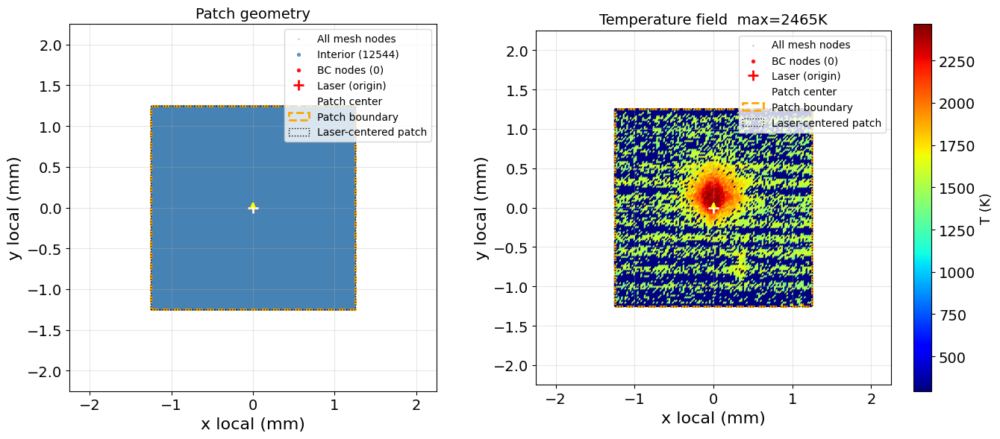

Patch stats:
  Total nodes  : 12544
  Interior     : 12544
  Boundary     : 0
  Scan dir     : (0.000, 1.000)
  T max        : 2465.1 K
  T min        : 273.1 K
  Nodes > Tl   : 1638
  Nodes > Ts   : 2925


In [ ]:
# =========================================================
# Only for experiments
# =========================================================

def plot_training_patch_EXP(k, show_background=True):

    FONTSIZE, TITLE_FS, SUPTITLE_FS, LEGEND_FS, CBAR_FS = 16, 14, 18, 10, 13

    p = Power[k] if Power.size > 1 else float(Power[0])

    # nodes are LASER-RELATIVE -> laser at local (0,0); patch center offset in local frame
    vx_n, vy_n = get_scan_direction(k)
    xLp_local = -patch_offset * vx_n
    yLp_local = -patch_offset * vy_n

    mask_patch = get_patch_mask(xNodes, yNodes, 0.0, 0.0,
                                patch_half_width, patch_half_height,
                                xLp_local, yLp_local)
    if mask_patch.sum() == 0:
        print(f"No patch nodes at k={k}")
        return

    xPatch = xNodes[mask_patch];  yPatch = yNodes[mask_patch]
    bnd_mask = get_patch_boundary_mask(xPatch, yPatch,
                                       xLp_local, yLp_local,
                                       patch_half_width, patch_half_height)
    xBnd, yBnd = xPatch[bnd_mask], yPatch[bnd_mask]
    xInt, yInt = xPatch[~bnd_mask], yPatch[~bnd_mask]
    T_patch = T_nodes_time[mask_patch, k]
    T_int   = T_patch[~bnd_mask]

    margin = patch_half_width * 0.8

    # to mm (local frame; laser at 0,0)
    xL_mm = yL_mm = 0.0                          # laser at local origin
    xLp_mm, yLp_mm = xLp_local*1000, yLp_local*1000
    xNodes_mm, yNodes_mm = xNodes*1000, yNodes*1000
    xInt_mm, yInt_mm = xInt*1000, yInt*1000
    xBnd_mm, yBnd_mm = xBnd*1000, yBnd*1000
    margin_mm = margin*1000
    phw_mm, phh_mm = patch_half_width*1000, patch_half_height*1000

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    for ax_idx, (ax, show_T) in enumerate(zip(axes, [False, True])):
        ax.scatter(xNodes_mm, yNodes_mm, s=1, color='grey', alpha=0.3, label='All mesh nodes')

        if show_T:
            sc = ax.scatter(xInt_mm, yInt_mm, c=T_int, cmap='jet', s=8,
                            vmin=Tamb, vmax=T_nodes_time[:, k].max())
            cbar = fig.colorbar(sc, ax=ax)
            cbar.set_label("T (K)", fontsize=CBAR_FS)
            cbar.ax.tick_params(labelsize=FONTSIZE-2)
        else:
            ax.scatter(xInt_mm, yInt_mm, s=8, color='steelblue', alpha=0.8,
                       label=f'Interior ({(~bnd_mask).sum()})')

        ax.scatter(xBnd_mm, yBnd_mm, s=8, color='red', alpha=0.9,
                   label=f'BC nodes ({bnd_mask.sum()})')
        ax.plot(xL_mm, yL_mm, 'r+', ms=10, mew=2, label='Laser (origin)')
        ax.plot(xLp_mm, yLp_mm, 'w+', ms=10, mew=2, label='Patch center')

        ax.annotate('', xy=(xL_mm + 0.1*vx_n, yL_mm + 0.1*vy_n),
                    xytext=(xL_mm, yL_mm),
                    arrowprops=dict(arrowstyle='->', color='yellow', lw=2))

        ax.add_patch(plt.Rectangle((xLp_mm - phw_mm, yLp_mm - phh_mm),
                     2*phw_mm, 2*phh_mm, fill=False, edgecolor='orange',
                     linewidth=2, linestyle='--', label='Patch boundary'))
        ax.add_patch(plt.Rectangle((xL_mm - phw_mm, yL_mm - phh_mm),
                     2*phw_mm, 2*phh_mm, fill=False, edgecolor='black',
                     linewidth=1, linestyle=':', label='Laser-centered patch'))

        ax.set_xlabel("x local (mm)", fontsize=FONTSIZE)
        ax.set_ylabel("y local (mm)", fontsize=FONTSIZE)
        ax.tick_params(axis="both", labelsize=FONTSIZE-2)
        titles = ["Patch geometry", f"Temperature field  max={T_patch.max():.0f}K"]
        ax.set_title(titles[ax_idx], fontsize=TITLE_FS)
        ax.legend(fontsize=LEGEND_FS, loc='upper right')
        ax.set_aspect("equal")
        ax.set_xlim(xLp_mm - phw_mm - margin_mm, xLp_mm + phw_mm + margin_mm)
        ax.set_ylim(yLp_mm - phh_mm - margin_mm, yLp_mm + phh_mm + margin_mm)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    fig.savefig("Patch_Area.png", dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Patch stats:")
    print(f"  Total nodes  : {mask_patch.sum()}")
    print(f"  Interior     : {(~bnd_mask).sum()}")
    print(f"  Boundary     : {bnd_mask.sum()}")
    print(f"  Scan dir     : ({vx_n:.3f}, {vy_n:.3f})")
    print(f"  T max        : {T_patch.max():.1f} K")
    print(f"  T min        : {T_patch.min():.1f} K")
    print(f"  Nodes > Tl   : {(T_patch >= Tl).sum()}")
    print(f"  Nodes > Ts   : {(T_patch >= Ts).sum()}")

plot_training_patch_EXP(k=100)

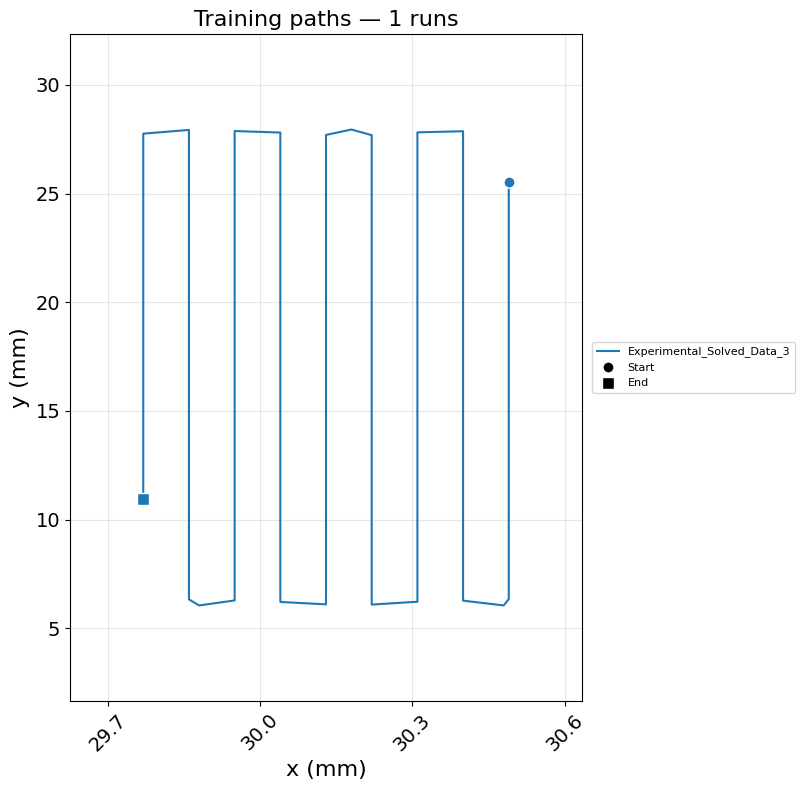

In [9]:
# =========================================================
# Visualise all training paths
# =========================================================
import matplotlib.cm as cm
FONTSIZE    = 16
TITLE_FS    = 16
SUPTITLE_FS = 18
LEGEND_FS   = 10
CBAR_FS     = 13
fig, ax = plt.subplots(figsize=(10, 8))
colors = cm.tab10(np.linspace(0, 1, len(all_runs)))

for run, color in zip(all_runs, colors):
    label = run['fname'].replace('LPBF_run_ML_solver_PINN_', '').replace('.mat', '')

    ax.plot(run['xPath'] * 1000, run['yPath'] * 1000,
            color=color, linewidth=1.5, label=label)
    ax.plot(run['xPath'][0]  * 1000, run['yPath'][0]  * 1000,
            'o', color=color, ms=8, markeredgecolor='white', linewidth=0.5)
    ax.plot(run['xPath'][-1] * 1000, run['yPath'][-1] * 1000,
            's', color=color, ms=8, markeredgecolor='white', linewidth=0.5)

# legend for markers
ax.plot([], [], 'ko', ms=8, markeredgecolor='white', label='Start')
ax.plot([], [], 'ks', ms=8, markeredgecolor='white', label='End')

ax.set_xlabel("x (mm)", fontsize=FONTSIZE)
ax.set_ylabel("y (mm)", fontsize=FONTSIZE)
ax.set_title(f"Training paths — {len(all_runs)} runs", fontsize=TITLE_FS)
ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02, 0.5),
          borderaxespad=0)
ax.grid(True, alpha=0.3)
ax.set_xmargin(0.2)   # 25% extra on x only
ax.set_ymargin(0.2)
ax.autoscale_view()         # 8% of the data range on all sides
ax.autoscale_view()
ax.tick_params(labelsize=FONTSIZE-2)
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune='both'))
ax.tick_params(axis='x', labelrotation=45, labelsize=FONTSIZE-2)
plt.tight_layout(rect=[0, 0, 0.82, 1])
fig.savefig("Training_paths.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
# =========================================================
# Cell 6 — IC: exact t=0 points only, no band
#           transient PDE handles all t_feat > 0
# =========================================================
X_ic_list = []
Y_ic_list = []

for run in all_runs:
    xPath_r  = run['xPath'];  yPath_r = run['yPath']
    tPath_r  = run['tPath'];  Power_r = run['Power']
    xNodes_r = run['xNodes']; yNodes_r = run['yNodes']

    xL_ic = xPath_r[0];  yL_ic = yPath_r[0]
    p_ic  = Power_r[0] if Power_r.size > 1 else float(Power_r[0])

    # use actual initial velocity direction
    dt_r  = np.diff(tPath_r)
    dt_r  = np.where(dt_r < 1e-12, 1e-12, dt_r)
    vx_r  = np.clip(np.concatenate([[0], np.diff(xPath_r)/dt_r]), -V_MAX, V_MAX)
    vy_r  = np.clip(np.concatenate([[0], np.diff(yPath_r)/dt_r]), -V_MAX, V_MAX)
    vx_ic_0 = float(vx_r[1]) if len(vx_r) > 1 else 0.0
    vy_ic_0 = float(vy_r[1]) if len(vy_r) > 1 else 1.0
    speed_ic = np.sqrt(vx_ic_0**2 + vy_ic_0**2) + 1e-12
    vx_n = vx_ic_0 / speed_ic
    vy_n = vy_ic_0 / speed_ic

    xL_patch_ic = xL_ic - patch_offset * vx_n
    yL_patch_ic = yL_ic - patch_offset * vy_n

    mask_ic = get_patch_mask(xNodes_r, yNodes_r, xL_ic, yL_ic,
                              patch_half_width, patch_half_height,
                              xL_patch_ic, yL_patch_ic)
    if mask_ic.sum() == 0:
        continue

    xIC   = xNodes_r[mask_ic];  yIC = yNodes_r[mask_ic]
    dx_ic = (xIC - xL_ic) * 1000
    dy_ic = (yIC - yL_ic) * 1000
    dist_x_ic = np.minimum(xIC, plateX - xIC) * 1000
    dist_y_ic = np.minimum(yIC, plateY - yIC) * 1000

    X_ic_r = np.column_stack([
        np.zeros_like(xIC),           # t_feat = 0 exactly
        dx_ic, dy_ic,
        np.full_like(xIC, p_ic),
        dist_x_ic, dist_y_ic,
        np.full_like(xIC, vx_ic_0),   # real initial velocity
        np.full_like(xIC, vy_ic_0),
        np.zeros_like(xIC),
    ])
    X_ic_list.append(X_ic_r)
    Y_ic_list.append(np.zeros((X_ic_r.shape[0], 1)))

# --- combine and normalize ---
X_ic = np.vstack(X_ic_list).astype(np.float64)
Y_ic = np.zeros((X_ic.shape[0], 1))

X_ic_n = (X_ic - X_mean) / X_std
Y_ic_n = (Y_ic - Y_mean) / Y_std

X_ic_tensor = torch.tensor(X_ic_n, dtype=torch.float32, device=device)
Y_ic_tensor = torch.tensor(Y_ic_n, dtype=torch.float32, device=device)

# rebuild IC tensors with current (fixed) normalization
X_ic_n = (X_ic - X_mean) / X_std
Y_ic_n = (Y_ic - Y_mean) / Y_std
X_ic_tensor = torch.tensor(X_ic_n, dtype=torch.float32, device=device)
Y_ic_tensor = torch.tensor(Y_ic_n, dtype=torch.float32, device=device)
print(f"IC tensor rebuilt with fixed normalization")
print(f"IC t_feat normalized range: [{X_ic_tensor[:,0].min():.4f}, {X_ic_tensor[:,0].max():.4f}]")
# should print [0.0000, 0.0000] — all IC points at t_feat_norm=0

print(f"IC points: {X_ic.shape[0]:,}  (exact t=0 only, no band)")
print(f"t_feat in IC: [{X_ic[:,0].min():.4f}, {X_ic[:,0].max():.4f}]  ← should be all 0")
print(f"vx in IC: [{X_ic[:,6].min():.3f}, {X_ic[:,6].max():.3f}]")
print(f"vy in IC: [{X_ic[:,7].min():.3f}, {X_ic[:,7].max():.3f}]")

IC tensor rebuilt with fixed normalization
IC t_feat normalized range: [0.0000, 0.0000]
IC points: 712  (exact t=0 only, no band)
t_feat in IC: [0.0000, 0.0000]  ← should be all 0
vx in IC: [0.000, 0.000]
vy in IC: [-0.600, -0.600]


In [9]:
# =========================================================
# Cell 6 — Only for experiments
# =========================================================


X_ic_list = []
Y_ic_list = []

for run in all_runs:
    xPath_r  = run['xPath'];  yPath_r = run['yPath']
    tPath_r  = run['tPath'];  Power_r = run['Power']
    xNodes_r = run['xNodes']; yNodes_r = run['yNodes']

    xL_ic = xPath_r[0];  yL_ic = yPath_r[0]
    p_ic  = Power_r[0] if Power_r.size > 1 else float(Power_r[0])

    dt_r  = np.diff(tPath_r)
    dt_r  = np.where(dt_r < 1e-12, 1e-12, dt_r)
    vx_r  = np.clip(np.concatenate([[0], np.diff(xPath_r)/dt_r]), -V_MAX, V_MAX)
    vy_r  = np.clip(np.concatenate([[0], np.diff(yPath_r)/dt_r]), -V_MAX, V_MAX)
    vx_ic_0 = float(vx_r[1]) if len(vx_r) > 1 else 0.0
    vy_ic_0 = float(vy_r[1]) if len(vy_r) > 1 else 1.0
    speed_ic = np.sqrt(vx_ic_0**2 + vy_ic_0**2) + 1e-12
    vx_n = vx_ic_0 / speed_ic
    vy_n = vy_ic_0 / speed_ic

    # ---- FRAME-DEPENDENT: patch mask ----
    if DATA_MODE == "experimental":
        xL_patch_ic = -patch_offset * vx_n
        yL_patch_ic = -patch_offset * vy_n
        mask_ic = get_patch_mask(xNodes_r, yNodes_r, 0.0, 0.0,
                                 patch_half_width, patch_half_height,
                                 xL_patch_ic, yL_patch_ic)
    else:
        xL_patch_ic = xL_ic - patch_offset * vx_n
        yL_patch_ic = yL_ic - patch_offset * vy_n
        mask_ic = get_patch_mask(xNodes_r, yNodes_r, xL_ic, yL_ic,
                                 patch_half_width, patch_half_height,
                                 xL_patch_ic, yL_patch_ic)
    if mask_ic.sum() == 0:
        continue

    xIC = xNodes_r[mask_ic];  yIC = yNodes_r[mask_ic]

    # ---- FRAME-DEPENDENT: dx/dy and edge distance ----
    if DATA_MODE == "experimental":
        dx_ic = xIC * 1000                 # already laser-relative
        dy_ic = yIC * 1000
        xabs = xIC + xL_ic;  yabs = yIC + yL_ic
        dist_x_ic = np.minimum(xabs, plateX - xabs) * 1000
        dist_y_ic = np.minimum(yabs, plateY - yabs) * 1000
    else:
        dx_ic = (xIC - xL_ic) * 1000
        dy_ic = (yIC - yL_ic) * 1000
        dist_x_ic = np.minimum(xIC, plateX - xIC) * 1000
        dist_y_ic = np.minimum(yIC, plateY - yIC) * 1000

    X_ic_r = np.column_stack([
        np.zeros_like(xIC),           # t_feat = 0 exactly
        dx_ic, dy_ic,
        np.full_like(xIC, p_ic),
        dist_x_ic, dist_y_ic,
        np.full_like(xIC, vx_ic_0),
        np.full_like(xIC, vy_ic_0),
        np.zeros_like(xIC),
    ])
    X_ic_list.append(X_ic_r)
    Y_ic_list.append(np.zeros((X_ic_r.shape[0], 1)))

# --- combine and normalize ---
X_ic = np.vstack(X_ic_list).astype(np.float64)
Y_ic = np.zeros((X_ic.shape[0], 1))

X_ic_n = (X_ic - X_mean) / X_std
Y_ic_n = (Y_ic - Y_mean) / Y_std
X_ic_tensor = torch.tensor(X_ic_n, dtype=torch.float32, device=device)
Y_ic_tensor = torch.tensor(Y_ic_n, dtype=torch.float32, device=device)

print(f"IC points: {X_ic.shape[0]:,}  (exact t=0 only, no band)")
print(f"IC t_feat normalized range: [{X_ic_tensor[:,0].min():.4f}, {X_ic_tensor[:,0].max():.4f}]")
print(f"t_feat in IC: [{X_ic[:,0].min():.4f}, {X_ic[:,0].max():.4f}]  ← should be all 0")
print(f"vx in IC: [{X_ic[:,6].min():.3f}, {X_ic[:,6].max():.3f}]")
print(f"vy in IC: [{X_ic[:,7].min():.3f}, {X_ic[:,7].max():.3f}]")

IC points: 12,544  (exact t=0 only, no band)
IC t_feat normalized range: [0.0000, 0.0000]
t_feat in IC: [0.0000, 0.0000]  ← should be all 0
vx in IC: [0.000, 0.000]
vy in IC: [-0.602, -0.602]


In [10]:
X_mean = X_data.mean(axis=0, keepdims=True)
X_std  = X_data.std(axis=0,  keepdims=True) + 1e-12

# power column = 3
power_ref    = float(np.mean(X_data[:, 3]))
X_mean[0, 3] = power_ref
X_std[0, 3]  = max(abs(power_ref), 1.0)

# robust std
min_std = {
    0: 1e-4,   # t_rel
    1: 0.1,   # dx
    2: 0.1,   # dy
    4: 1,  # dist_x
    5: 1,  # dist_y
    6: 0.1,    # vx
    7: 0.1,    # vy
    8: 50.0,
}
for col, min_val in min_std.items():
    if X_std[0, col] < min_val:
        print(f"  Warning: X_std[{col}] too small — setting to {min_val}")
        X_std[0, col] = min_val

print("Normalisation stats:")
for i, name in enumerate(['t_rel','dx','dy','P','dist_x','dist_y','vx','vy',"T_previous"]):
    print(f"  {name:8s}: mean={X_mean[0,i]:.5f}  std={X_std[0,i]:.5f}")

Y_mean = Y_data.mean(axis=0, keepdims=True)
Y_std  = Y_data.std(axis=0,  keepdims=True) + 1e-12

# normalise
Xn    = (X_data    - X_mean) / X_std

Yn    = (Y_data    - Y_mean) / Y_std

Xic_n = (X_ic      - X_mean) / X_std
Yic_n = (Y_ic      - Y_mean) / Y_std

X_tensor    = torch.tensor(Xn,    dtype=torch.float32, device=device)
Y_tensor    = torch.tensor(Yn,    dtype=torch.float32, device=device)

X_ic_tensor = torch.tensor(Xic_n, dtype=torch.float32, device=device)
Y_ic_tensor = torch.tensor(Yic_n, dtype=torch.float32, device=device)
X_mean_t    = torch.tensor(X_mean, dtype=torch.float32, device=device)
X_std_t     = torch.tensor(X_std,  dtype=torch.float32, device=device)
Y_mean_t    = torch.tensor(Y_mean, dtype=torch.float32, device=device)
Y_std_t     = torch.tensor(Y_std,  dtype=torch.float32, device=device)

print(f"\nX_tensor : {X_tensor.shape}")
print(f"Y_tensor : {Y_tensor.shape}")

# --- decide where to store data tensors ---
candidate_tensors = [
    torch.tensor(Xn,     dtype=torch.float32),
    torch.tensor(Yn,     dtype=torch.float32),
    torch.tensor(Xic_n,  dtype=torch.float32),
]
USE_GPU_DATA = should_pin_to_gpu(candidate_tensors)
data_device  = device if USE_GPU_DATA else "cpu"
print(f"Data device: {data_device}")

X_tensor    = torch.tensor(Xn,    dtype=torch.float32, device=data_device)
Y_tensor    = torch.tensor(Yn,    dtype=torch.float32, device=data_device)

X_ic_tensor = torch.tensor(Xic_n, dtype=torch.float32, device=data_device)
Y_ic_tensor = torch.tensor(Yic_n, dtype=torch.float32, device=data_device)

print_vram()

Normalisation stats:
  t_rel   : mean=0.78279  std=0.27172
  dx      : mean=0.00000  std=0.72097
  dy      : mean=0.00000  std=0.72097
  P       : mean=190.00000  std=190.00000
  dist_x  : mean=19.86538  std=1.00000
  dist_y  : mean=16.68029  std=5.70757
  vx      : mean=-0.00227  std=0.10000
  vy      : mean=-0.04185  std=0.59512
  T_previous: mean=716.72123  std=705.25391

X_tensor : torch.Size([7977984, 9])
Y_tensor : torch.Size([7977984, 1])
Data tensors total : 320 MB
VRAM free          : 15314 MB
Pin to GPU         : True
Data device: cuda
VRAM — allocated: 320 MB | reserved: 610 MB | total: 15637 MB | free: 15027 MB


In [11]:
# =========================================================
# Cell 8 — Plain PINN (no Fourier)
# =========================================================
class PINN(nn.Module):
    def __init__(self, in_dim=9, hidden_dim=128, depth=5, out_dim=1):
        super().__init__()
        layers = [nn.Linear(in_dim, hidden_dim), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden_dim, hidden_dim), nn.Tanh()]
        layers += [nn.Linear(hidden_dim, out_dim)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

model    = PINN(in_dim=9, hidden_dim=128, depth=5).to(device)
opt      = torch.optim.Adam(model.parameters(), lr=1e-3)
mse_loss = nn.MSELoss()

def bc_loss(mdl, X_bc, Y_bc):
    return mse_loss(mdl(X_bc), Y_bc)

print(f"Plain PINN initialised")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Plain PINN initialised
Parameters: 67,457


In [13]:
params = {
    "Tamb"       : 295.0,
    "Ts"         : Ts,
    "Tl"         : Tl,
    "Lfus"       : Lfus,
    "rho_powder" : 3500.0,
    "rho_liquid" : 8190.0,
    "rho_solid"  : 8190.0,
    "cp_base"    : 500.0,
    "k_powder"   : 0.08715,
    "k_liquid"   : 25.405,
    "k_solid"    : 13.744,
    "sigma"      : 10**(-3.684),
    "absorb"     : 1.0,
    "depth"      : 10**(-4.517),
    "beta"       : 1.0*10**(9.8717),
    "e"          : 0.35842,
    "sigma_sb"   : 5.670374419*10**(-8),
    "tau" : TAU,
    }

sigma  = params["sigma"]
depth  = params["depth"]
absorb = params["absorb"]
P_ref  = float(np.mean(X_data[:, 3][X_data[:, 3] > 0]))
'''Q_ref  = absorb * P_ref / (2 * np.pi * sigma**2 * depth)
q_scale = Q_ref
print(f"P_ref   = {P_ref:.2f} W")
print(f"q_scale = {q_scale:.3e}")'''

'Q_ref  = absorb * P_ref / (2 * np.pi * sigma**2 * depth)\nq_scale = Q_ref\nprint(f"P_ref   = {P_ref:.2f} W")\nprint(f"q_scale = {q_scale:.3e}")'

In [12]:
# =========================================================
# Cell 7b — Neighboring-time inputs for transient PDE
# =========================================================

def build_same_material_neighbor_inputs(
    X_current,
    run_ids,
    step_ids,
    step_offset,
):
    """
    Construct network inputs at the SAME physical plate points
    but at another timestep.

    X_current columns:
      0 t_feat
      1 dx [mm]
      2 dy [mm]
      3 P [W]
      4 dist_x [mm]
      5 dist_y [mm]
      6 vx [m/s]
      7 vy [m/s]

    Parameters
    ----------
    X_current : ndarray, shape (N,8)
        Raw, non-normalized PINN inputs.

    run_ids : ndarray, shape (N,)
        Original dataset/run for each point.

    step_ids : ndarray, shape (N,)
        Original timestep for each point.

    step_offset : int
        For example -1 or +1.

    Returns
    -------
    X_neighbor : ndarray, shape (N,8)
    neighbor_steps : ndarray, shape (N,)
    valid : ndarray of bool, shape (N,)
    """

    X_current = np.asarray( X_current,dtype=np.float32)

    run_ids = np.asarray(run_ids,dtype=np.int32)

    step_ids = np.asarray(step_ids,dtype=np.int32 )

    X_neighbor = X_current.copy()
    neighbor_steps = step_ids + int(step_offset)

    valid = np.ones(len(X_current),dtype=bool )

    for run_id in np.unique(run_ids):

        rows = np.where(run_ids == run_id)[0]
        run = all_runs[int(run_id)]
        x_path = np.asarray( run["xPath"]).reshape(-1)
        y_path = np.asarray(run["yPath"]).reshape(-1)
        t_path = np.asarray(run["tPath"]).reshape(-1)
        vx_path = np.asarray(run["vx_path"]).reshape(-1)
        vy_path = np.asarray(run["vy_path"]).reshape(-1)
        power_path = np.asarray(run["Power"]).reshape(-1)

        k_current = step_ids[rows]
        k_neighbor = neighbor_steps[rows]

        valid_local = ((k_neighbor >= 0) & (k_neighbor < len(t_path)) )

        valid[rows] = valid_local

        if not np.any(valid_local):
            continue

        rows_valid = rows[valid_local]
        kc = k_current[valid_local]
        kn = k_neighbor[valid_local]

        # Recover the absolute material coordinates.
        # dx = x_material - x_laser
        x_material = ( x_path[kc] + X_current[rows_valid, 1] / 1000.0 )
        y_material = ( y_path[kc] + X_current[rows_valid, 2] / 1000.0 )

        # Relative coordinates of those SAME material points
        # with respect to the neighboring laser position.
        X_neighbor[rows_valid, 1] = (
            x_material - x_path[kn] ) * 1000.0

        X_neighbor[rows_valid, 2] = (
            y_material - y_path[kn] ) * 1000.0

        t_rel_neighbor = (
            t_path[kn] - t_path[0] )

        X_neighbor[rows_valid, 0] = np.tanh(
            t_rel_neighbor / TAU )

        if power_path.size == 1:
            X_neighbor[rows_valid, 3] = float(
                power_path[0] )
        else:
            X_neighbor[rows_valid, 3] = (
                power_path[kn] )

        # dist_x and dist_y remain unchanged because the
        # material coordinates are unchanged.
        X_neighbor[rows_valid, 6] = vx_path[kn]
        X_neighbor[rows_valid, 7] = vy_path[kn]

    return X_neighbor, neighbor_steps, valid


def get_neighbor_time_interval(
    run_ids,
    previous_steps,
    next_steps,
):
    """
    Return t_next - t_previous for every sample.
    """

    run_ids = np.asarray(
        run_ids,
        dtype=np.int32
    )

    previous_steps = np.asarray(
        previous_steps,
        dtype=np.int32
    )

    next_steps = np.asarray(
        next_steps,
        dtype=np.int32
    )

    dt_values = np.empty(
        len(run_ids),
        dtype=np.float32
    )

    for run_id in np.unique(run_ids):

        rows = np.where(run_ids == run_id)[0]

        t_path = np.asarray(
            all_runs[int(run_id)]["tPath"]
        ).reshape(-1)

        dt_values[rows] = (
            t_path[next_steps[rows]]
            - t_path[previous_steps[rows]]
        ).astype(np.float32)

    return dt_values


print("Neighboring-time PDE helpers defined.")

Neighboring-time PDE helpers defined.


In [14]:
def src_from_laser_ellipse(x, y, xL, yL, power, sigma, absorb, depth):
    amp = absorb * power / (2.0 * np.pi * sigma**2 * depth)
    r2  = ((x - xL)**2 + (y - yL)**2) / (2.0 * sigma**2)
    return amp * torch.exp(-r2)

def k_phase(phi, k_powder, k_liquid, k_solid):
    k = torch.zeros_like(phi)
    k = torch.where(phi == 0, torch.full_like(phi, k_powder), k)
    k = torch.where(phi == 1, torch.full_like(phi, k_liquid), k)
    k = torch.where(phi == 2, torch.full_like(phi, k_solid),  k)
    return k

def rho_phase(phi, rho_powder, rho_liquid, rho_solid):
    rho = torch.zeros_like(phi)
    rho = torch.where(phi == 0, torch.full_like(phi, rho_powder), rho)
    rho = torch.where(phi == 1, torch.full_like(phi, rho_liquid), rho)
    rho = torch.where(phi == 2, torch.full_like(phi, rho_solid),  rho)
    return rho

def cp_apparent(T, Ts, Tl, Lfus, cp_base=500.0):
    mushy  = ((T >= Ts) & (T <= Tl)).float()
    dfl_dT = mushy / (Tl - Ts)
    return cp_base + Lfus * dfl_dT


def model_deltaT_phys(X_phys):
    """X_phys is RAW (not normalised). Normalises internally."""
    X_norm  = (X_phys - X_mean_t) / X_std_t
    dT_norm = model(X_norm)
    return dT_norm * Y_std_t + Y_mean_t

def pde_residual_phase(
    model_fn,
    X,
    p,
    q_scale=1.0,
    was_melted_batch=None,
    use_transient=False,
    X_previous=None,
    X_next=None,
    dt_previous_next=None,
):
    """
    X is RAW, non-normalized input.

    Columns:
      0: tanh(t_rel/tau)
      1: dx [mm]
      2: dy [mm]
      3: P [W]
      4: dist_x [mm]
      5: dist_y [mm]
      6: vx [m/s]
      7: vy [m/s]

    When use_transient=True, the laboratory-frame derivative
    is calculated from predictions at the same material point:

        Tt = [T(x,y,t_next)-T(x,y,t_previous)]
             / [t_next-t_previous]
    """

    X = X.requires_grad_(True)

    dT = model_fn(X)

    T = torch.clamp(
        dT + p["Tamb"],
        p["Tamb"],
        5000.0
    )

    g1 = torch.autograd.grad(
        dT,
        X,
        grad_outputs=torch.ones_like(dT),
        create_graph=True
    )[0]

    # Spatial gradients with respect to dx_mm and dy_mm.
    Tx_mm = g1[:, 1:2]
    Ty_mm = g1[:, 2:3]

    # K/mm -> K/m
    Tx = Tx_mm * 1000.0
    Ty = Ty_mm * 1000.0

    dx_mm = X[:, 1:2]
    dy_mm = X[:, 2:3]
    P = X[:, 3:4]

    dx_m = dx_mm / 1000.0
    dy_m = dy_mm / 1000.0

    r2_m = dx_m**2 + dy_m**2

    # -----------------------------------------------------
    # Material phase
    # -----------------------------------------------------
    is_liquid = (T > p["Tl"]).float()

    is_mushy = (
        (T >= p["Ts"])
        & (T <= p["Tl"])
    ).float()

    is_cold = (T < p["Ts"]).float()

    if was_melted_batch is None:
        was_melted = torch.ones_like(T)
    else:
        was_melted = was_melted_batch.to( X.device )

    rho = ( is_cold * ( was_melted * p["rho_solid"] + (1.0 - was_melted) * p["rho_powder"] )+ is_mushy * p["rho_liquid"] + is_liquid * p["rho_liquid"]  )

    k_material = ( is_cold * ( was_melted * p["k_solid"] + (1.0 - was_melted) * p["k_powder"] ) + is_mushy * p["k_liquid"]  + is_liquid * p["k_liquid"] )

    cp = cp_apparent(T, p["Ts"], p["Tl"], p["Lfus"], p["cp_base"])

    # -----------------------------------------------------
    # Laser source
    # -----------------------------------------------------
    Q = (p["absorb"]* P/ (2.0* np.pi * p["sigma"]**2 * p["depth"] )* torch.exp(-r2_m/ (2.0 * p["sigma"]**2 ) ) )

    # -----------------------------------------------------
    # Conduction
    # -----------------------------------------------------
    kTx = k_material * Tx
    kTy = k_material * Ty

    # IMPORTANT:
    # Autograd differentiates with respect to dx in mm.
    # Another ×1000 is required to obtain derivative per meter.
    d_kTx_dx = 1000.0 * torch.autograd.grad(
        kTx,
        X,
        grad_outputs=torch.ones_like(kTx),
        create_graph=True
    )[0][:, 1:2]

    d_kTy_dy = 1000.0 * torch.autograd.grad(
        kTy,
        X,
        grad_outputs=torch.ones_like(kTy),
        create_graph=True
    )[0][:, 2:3]

    conduction = d_kTx_dx + d_kTy_dy

    # -----------------------------------------------------
    # Sink terms
    # -----------------------------------------------------
    q_sink = p["beta"] * dT

    q_rad = (p["e"]* p["sigma_sb"]* torch.clamp(T**4 - p["Tamb"]**4,min=0.0 ))

    # -----------------------------------------------------
    # Laboratory-frame transient derivative
    # -----------------------------------------------------
    if use_transient:
        if (X_previous is None
            or X_next is None
            or dt_previous_next is None
        ):
            raise ValueError("Transient PDE requires X_previous, "
                "X_next and dt_previous_next.")

        dT_previous = model_fn(X_previous)
        dT_next = model_fn(X_next)

        dt_safe = torch.clamp(dt_previous_next,min=1e-12 )

        Tt_lab = (dT_next - dT_previous) / dt_safe
        res = (rho * cp * Tt_lab- conduction- Q+ q_sink+ q_rad)
    else:
        res = (-conduction- Q + q_sink + q_rad )
    return res / q_scale


# safe velocity function — add once before prediction cells
def get_safe_velocity(k, vx_arr, vy_arr, min_speed=0.1):
    vx = float(vx_arr[k]);  vy = float(vy_arr[k])
    # clip first
    vx = np.clip(vx, -V_MAX, V_MAX)
    vy = np.clip(vy, -V_MAX, V_MAX)
    speed = np.sqrt(vx**2 + vy**2)
    if speed < min_speed:
        # look back for last nonzero velocity
        for k_back in range(k-1, max(0, k-10), -1):
            vx_b = np.clip(float(vx_arr[k_back]), -V_MAX, V_MAX)
            vy_b = np.clip(float(vy_arr[k_back]), -V_MAX, V_MAX)
            if np.sqrt(vx_b**2 + vy_b**2) >= min_speed:
                return vx_b, vy_b
    return vx, vy

# =========================================================
# Prediction helper — run before any training/evaluation
# =========================================================


def _predict_at_step(k):

    xL = xPath[k]
    yL = yPath[k]

    p = (
        Power[k]
        if Power.size > 1
        else float(Power[0])
    )

    vx, vy = get_safe_velocity( k, vx_path, vy_path )

    t_rel = tPath[k] - t_start
    t_feat = np.tanh(t_rel / TAU)

    vx_n = vx / ( np.sqrt(vx**2 + vy**2) + 1e-12 )

    vy_n = vy / ( np.sqrt(vx**2 + vy**2) + 1e-12 )

    xL_patch = xL - patch_offset * vx_n
    yL_patch = yL - patch_offset * vy_n

    # CURRENT patch
    mask = get_patch_mask(
        xNodes,
        yNodes,
        xL,
        yL,
        patch_half_width,
        patch_half_height,
        xL_patch,
        yL_patch)

    if mask.sum() == 0:
        return None, None

    xP = xNodes[mask]
    yP = yNodes[mask]

    dx = (xP - xL) * 1000.0
    dy = (yP - yL) * 1000.0

    dist_x = np.minimum(xP,plateX - xP ) * 1000.0
    dist_y = np.minimum(yP,plateY - yP ) * 1000.0

    # =====================================================
    # PREVIOUS TEMPERATURE:
    # SAME PHYSICAL NODES AS CURRENT PATCH
    # =====================================================
    if k - H_STEPS >= 0:
        T_previous = np.clip(T_nodes_time[mask, k - H_STEPS].reshape(-1), Tamb, None) - Tamb
    else:
        T_previous = np.zeros(mask.sum(), dtype=float)

    # Safety check
    assert (
        len(xP)
        == len(dx)
        == len(dy)
        == len(dist_x)
        == len(dist_y)
        == len(T_previous)
    ), (
        f"k={k}: input size mismatch: "
        f"xP={len(xP)}, "
        f"T_previous={len(T_previous)}"
    )

    # 9-input model
    Xk = np.column_stack([
        np.full_like(xP, t_feat),
        dx,
        dy,
        np.full_like(xP, p),
        dist_x,
        dist_y,
        np.full_like(xP, vx),
        np.full_like(xP, vy),
        T_previous,
    ])

    Xk_n = (Xk - X_mean) / X_std
    Xk_t = torch.tensor(Xk_n, dtype=torch.float32,device=device)
    with torch.no_grad():
        Tk_pred_n = (model(Xk_t).cpu().numpy())

    Tk_pred = np.clip((Tk_pred_n* Y_std+ Y_mean).reshape(-1)+ Tamb,Tamb,None )
    # dT_pred = (Tk_pred_n * Y_std + Y_mean).reshape(-1)          # predicted CHANGE
    # T_prev_phys = np.clip(T_nodes_time[mask_patch, k - H_STEPS].reshape(-1), Tamb, None)
    # Tk_pred = np.clip(T_prev_phys + dT_pred, Tamb, None)       # reconstruct temperature

    Tk_true = T_nodes_time[mask,k].reshape(-1)
    return Tk_true, Tk_pred

print("_predict_at_step defined ✓")


# =========================================================
# Far-field ambient loss — add to Stage 2 and Stage 3
# =========================================================

def sample_far_field_points(n=2048, min_dist_um=80.0):
    dx = np.random.uniform(-patch_half_width*1000, patch_half_width*1000, n)
    dy = np.random.uniform(-patch_half_height*1000, patch_half_height*1000, n)

    dist_from_center = np.sqrt(dx**2 + dy**2)  # in um (since dx,dy already in mm*1000=um... check units)
    # dx,dy here are in mm (patch_half_width is in m, *1000 -> mm), so convert min_dist to mm
    far_mask = dist_from_center > (min_dist_um/1000.0)
    dx = dx[far_mask];  dy = dy[far_mask]
    n_actual = len(dx)

    t_feat = np.random.uniform(0.0, t_feat_max_train, n_actual)
    P      = np.random.uniform(120.0, 280.0, n_actual)
    vx     = np.random.uniform(-0.6, 0.6, n_actual)
    vy     = np.random.uniform(-0.6, 0.6, n_actual)
    dist_x = np.random.uniform(1.0, 25.0, n_actual)
    dist_y = np.random.uniform(1.0, 25.0, n_actual)

    X_far = np.column_stack([t_feat, dx, dy, P, dist_x, dist_y, vx, vy])
    X_far_n = (X_far - X_mean) / X_std

    Y_far_target = np.zeros((n_actual, 1))  # ΔT = 0 → ambient
    Y_far_n = (Y_far_target - Y_mean) / Y_std

    return (torch.tensor(X_far_n, dtype=torch.float32, device=device),
            torch.tensor(Y_far_n, dtype=torch.float32, device=device))


# --- boundary-region indices (new) ---
boundary_band     = 100.0   # K — |T - Tl| < this band
T_data_flat       = Y_data.reshape(-1) + Tamb
boundary_mask = (T_data_flat > Ts - 200) & (T_data_flat < Tl + 200)
boundary_indices  = np.where(boundary_mask)[0]
# boundary_indices = np.where(np.abs(T_abs_samples - Tl) < boundary_band)[0]

_predict_at_step defined ✓


In [15]:
T_vals  = Y_data.reshape(-1)
weights = np.clip(T_vals, 0, None) + 1.0
weights /= weights.sum()
print("Sampling weights computed")
print(f"Hot fraction (T>500K): {(T_vals > 500).mean():.4f}")

Sampling weights computed
Hot fraction (T>500K): 0.5272


  DATASET INFO  —  SIM
  DATA_MODE               : sim
  File                    : new opt.mat
  — MESH / GEOMETRY —     : 
  Mesh nodes (total)      : 8,338  (same set every frame)
  Time frames             : 9,153
  Sampling rate           : 28,000 Hz   (dt=35.71 us)
  Scan duration           : 326.86 ms
  Node frame extent       : x[0.00,50.00] y[0.00,50.00] mm  (plate)
  Scan extent (path)      : x[29.77,30.49] y[6.05,27.95] mm
  Scan path length        : 196.05 mm
  — PATCH (per frame) —   : 
  Patch nodes / frame     : mean 784  (min 651, max 887)
  Unique nodes ever used  : 7,865 / 8,338  (94.3%)
  — SAMPLES (total) —     : 
  Total patch samples     : 7,177,877
  Assembled X_data        : 7,177,877 rows x 9 feat
  — PROCESS —             : 
  Power                   : [190, 190] W
  Scan speed (active)     : [0.425, 0.600] m/s
  Max temperature         : 3774 K
  Nodes ever melted       : 4,735 / 8,338  (56.8%)
  Ts / Tl                 : 1533 / 1609 K


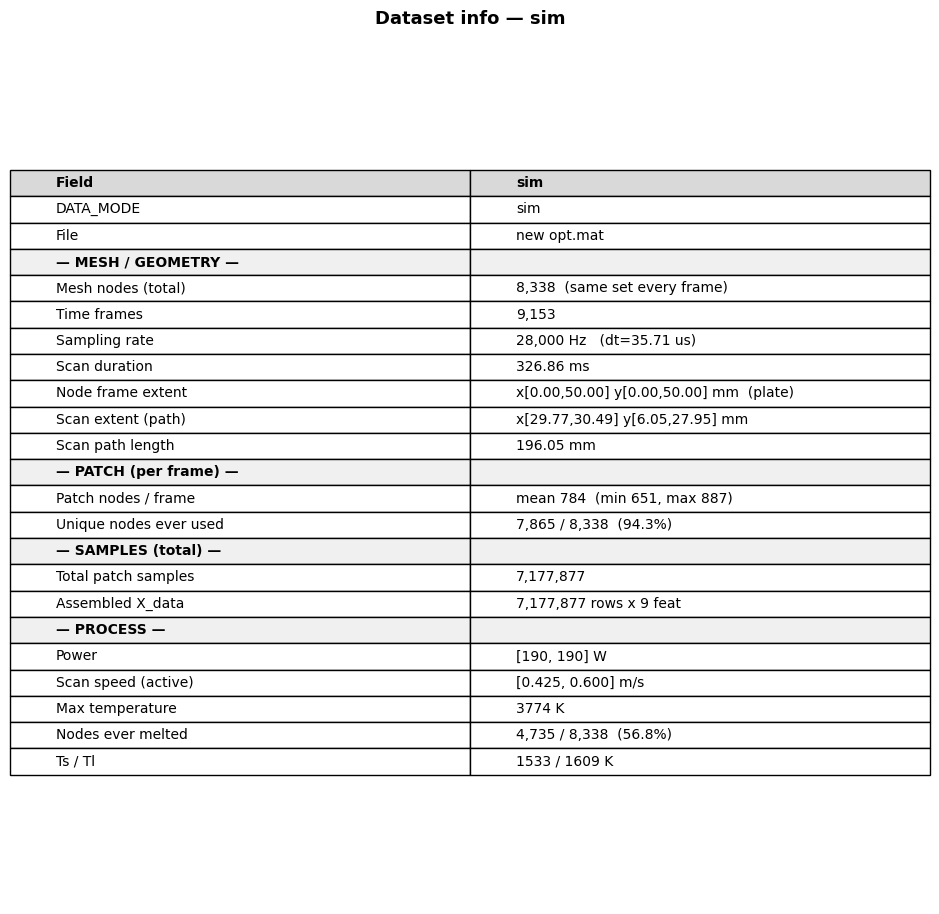

Saved: dataset_info_sim.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,sim
DATA_MODE,sim
File,new opt.mat
— MESH / GEOMETRY —,
Mesh nodes (total),"8,338 (same set every frame)"
Time frames,"9,153"
Sampling rate,"28,000 Hz (dt=35.71 us)"
Scan duration,326.86 ms
Node frame extent,"x[0.00,50.00] y[0.00,50.00] mm (plate)"
Scan extent (path),"x[29.77,30.49] y[6.05,27.95] mm"
Scan path length,196.05 mm


In [ ]:
# =========================================================
# Dataset info for the paper — run ONCE per loaded dataset
#   prints the table, saves it as a PNG, and downloads it
# =========================================================
import pandas as pd
import matplotlib.pyplot as plt

run = all_runs[0]
N_nodes = len(xNodes)
N_frames = len(tPath)
dt = np.diff(tPath); dt_mean=float(np.mean(dt)); fs=1.0/dt_mean
duration=float(tPath[-1]-tPath[0])

x_min,x_max=xNodes.min()*1000,xNodes.max()*1000
y_min,y_max=yNodes.min()*1000,yNodes.max()*1000
px_min,px_max=xPath.min()*1000,xPath.max()*1000
py_min,py_max=yPath.min()*1000,yPath.max()*1000
scan_len=np.sum(np.sqrt(np.diff(xPath)**2+np.diff(yPath)**2))*1000

P=np.asarray(Power).ravel()
P_min,P_max=(P.min(),P.max()) if P.size>1 else (float(P[0]),float(P[0]))
spd=np.sqrt(vx_path**2+vy_path**2); spd_active=spd[spd>1e-6]
Tmax_all=float(T_nodes_time.max())
ever_melt=(T_nodes_time>=Tl).any(axis=1); melt_frac=ever_melt.mean()*100

# --- per-frame patch stats + total unique nodes ---
patch_counts=[]; union_nodes=np.zeros(N_nodes,dtype=bool)
for k in range(1,N_frames):
    xL=float(xPath[k]); yL=float(yPath[k]); vx,vy=get_safe_velocity(k,vx_path,vy_path)
    sp=np.sqrt(vx**2+vy**2)+1e-12; vx_n,vy_n=vx/sp,vy/sp
    if DATA_MODE=="experimental":
        m=get_patch_mask(xNodes,yNodes,0.0,0.0,patch_half_width,patch_half_height,
                         -patch_offset*vx_n,-patch_offset*vy_n)
    else:
        m=get_patch_mask(xNodes,yNodes,xL,yL,patch_half_width,patch_half_height,
                         xL-patch_offset*vx_n,yL-patch_offset*vy_n)
    patch_counts.append(int(m.sum())); union_nodes|=m
patch_counts=np.array(patch_counts)
n_unique_used=int(union_nodes.sum())
total_patch_samples=int(patch_counts.sum())

try:
    n_samples=X_data.shape[0]; n_feat=X_data.shape[1]
    samp_str=f"{n_samples:,} rows x {n_feat} feat"
except Exception:
    samp_str="(X_data not built for this dataset)"

info = {
    "DATA_MODE"              : DATA_MODE,
    "File"                   : run.get('fname','?').split('/')[-1],
    "— MESH / GEOMETRY —"    : "",
    "Mesh nodes (total)"     : f"{N_nodes:,}  (same set every frame)",
    "Time frames"            : f"{N_frames:,}",
    "Sampling rate"          : f"{fs:,.0f} Hz   (dt={dt_mean*1e6:.2f} us)",
    "Scan duration"          : f"{duration*1e3:.2f} ms",
    "Node frame extent"      : f"x[{x_min:.2f},{x_max:.2f}] y[{y_min:.2f},{y_max:.2f}] mm"
                               + ("  (camera window)" if DATA_MODE=="experimental" else "  (plate)"),
    "Scan extent (path)"     : f"x[{px_min:.2f},{px_max:.2f}] y[{py_min:.2f},{py_max:.2f}] mm",
    "Scan path length"       : f"{scan_len:.2f} mm",
    "— PATCH (per frame) —"  : "",
    "Patch nodes / frame"    : f"mean {patch_counts.mean():.0f}  (min {patch_counts.min()}, max {patch_counts.max()})",
    "Unique nodes ever used" : f"{n_unique_used:,} / {N_nodes:,}  ({100*n_unique_used/N_nodes:.1f}%)",
    "— SAMPLES (total) —"    : "",
    "Total patch samples"    : f"{total_patch_samples:,}",
    "Assembled X_data"       : samp_str,
    "— PROCESS —"            : "",
    "Power"                  : f"[{P_min:.0f}, {P_max:.0f}] W",
    "Scan speed (active)"    : f"[{spd_active.min():.3f}, {spd_active.max():.3f}] m/s" if spd_active.size else "n/a",
    "Max temperature"        : f"{Tmax_all:.0f} K",
    "Nodes ever melted"      : f"{int(ever_melt.sum()):,} / {N_nodes:,}  ({melt_frac:.1f}%)",
    "Ts / Tl"                : f"{Ts:.0f} / {Tl:.0f} K",
}

# --- print ---
print("="*64)
print(f"  DATASET INFO  —  {DATA_MODE.upper()}")
print("="*64)
for k_,v_ in info.items():
    print(f"  {k_:<24}: {v_}")
print("="*64)

# --- save as a table image ---
rows=[[k_,v_] for k_,v_ in info.items()]
figt,axt=plt.subplots(figsize=(9.5,0.42*len(rows)))
axt.axis('off')
tbl=axt.table(cellText=rows, colLabels=["Field",DATA_MODE],
              cellLoc='left', colLoc='left', loc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1,1.3)
for (r,c),cell in tbl.get_celld().items():
    if r==0:
        cell.set_text_props(weight='bold'); cell.set_facecolor('#d9d9d9')
    elif r-1<len(rows) and rows[r-1][0].startswith("—"):
        cell.set_text_props(weight='bold'); cell.set_facecolor('#f0f0f0')
axt.set_title(f"Dataset info — {DATA_MODE}", fontsize=13, weight='bold', pad=12)
plt.tight_layout()
out_png=f"dataset_info_{DATA_MODE}.png"
figt.savefig(out_png, dpi=300, bbox_inches="tight"); plt.show()
print(f"Saved: {out_png}")

# --- download (Colab) ---
try:
    from google.colab import files
    files.download(out_png)
except Exception:
    print("(not on Colab — file saved in working directory)")

pd.DataFrame.from_dict(info, orient='index', columns=[DATA_MODE])

Training here

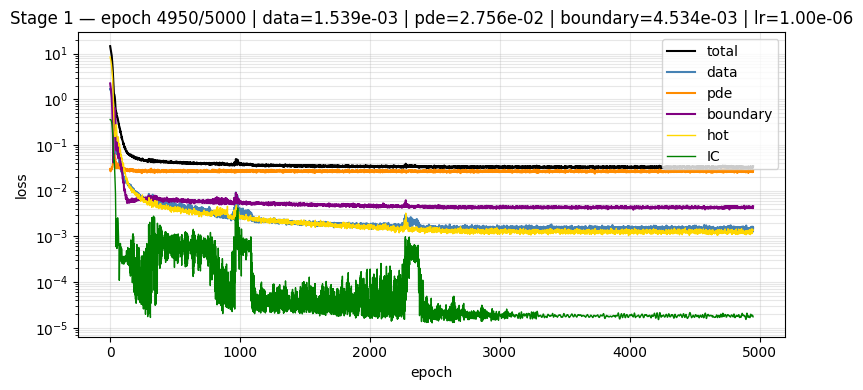

epoch    0 | loss=1.455e+01 | data=1.683e+00 | pde=2.999e-02 | boundary=2.228e+00 | hot=8.401e+00 | ic=3.604e-01 | lr=2.00e-04 | time=5.31s
epoch   50 | loss=4.379e-01 | data=6.457e-02 | pde=3.401e-02 | boundary=7.941e-02 | hot=2.171e-01 | ic=1.580e-03 | lr=2.00e-04 | time=0.95s
epoch  100 | loss=1.077e-01 | data=2.064e-02 | pde=2.831e-02 | boundary=1.616e-02 | hot=3.627e-02 | ic=3.041e-04 | lr=2.00e-04 | time=0.56s
epoch  150 | loss=6.101e-02 | data=1.318e-02 | pde=2.826e-02 | boundary=5.807e-03 | hot=1.179e-02 | ic=1.823e-04 | lr=2.00e-04 | time=0.54s
epoch  200 | loss=4.965e-02 | data=9.574e-03 | pde=2.549e-02 | boundary=6.536e-03 | hot=7.676e-03 | ic=3.431e-05 | lr=2.00e-04 | time=0.90s
epoch  250 | loss=4.761e-02 | data=7.102e-03 | pde=2.758e-02 | boundary=6.886e-03 | hot=6.043e-03 | ic=2.534e-04 | lr=2.00e-04 | time=0.54s
epoch  300 | loss=4.696e-02 | data=5.874e-03 | pde=2.827e-02 | boundary=6.745e-03 | hot=5.433e-03 | ic=1.027e-03 | lr=2.00e-04 | time=0.58s
epoch  350 | loss=4.

In [ ]:
# =========================================================
# Cell 13 — Stage 1: Teacher - Forced approach
# =========================================================
import gc
gc.collect()
torch.cuda.empty_cache()

X_mean_t = torch.tensor(X_mean, dtype=torch.float32, device=device)
X_std_t  = torch.tensor(X_std,  dtype=torch.float32, device=device)
Y_mean_t = torch.tensor(Y_mean, dtype=torch.float32, device=device)
Y_std_t  = torch.tensor(Y_std,  dtype=torch.float32, device=device)
t_feat_max_train = float(X_data[:, 0].max())


for g in opt.param_groups:
    g['lr'] = 2e-4

scheduler_s2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode='min', factor=0.5, patience=150, min_lr=1e-6
)

# Physical source scale used to normalize the residual.
P_ref = float(np.mean(X_data[X_data[:, 3] > 0, 3]))

q_scale = (params["absorb"]* P_ref / ( 2.0* np.pi* params["sigma"]**2* params["depth"]))

q_scale_bnd = q_scale
q_scale_far = q_scale

print(f"P_ref   : {P_ref:.3f} W")
print(f"q_scale : {q_scale:.3e} W/m^3")


# --- generate far-field collocation points once (resampled each epoch below) ---
def sample_far_pde_points(n=512, min_dist_mm=0.15):
    dx = np.random.uniform(-patch_half_width*1000,  patch_half_width*1000,  n*4)
    dy = np.random.uniform(-patch_half_height*1000, patch_half_height*1000, n*4)
    dist = np.sqrt(dx**2 + dy**2)
    far  = dist > min_dist_mm
    dx   = dx[far][:n];  dy = dy[far][:n]
    n_act = len(dx)

    t_feat = np.random.uniform(0.0,   t_feat_max_train, n_act)
    P      = np.random.uniform(120.0, 280.0,            n_act)
    vx     = np.random.uniform(-0.6,  0.6,              n_act)
    vy     = np.random.uniform(-0.6,  0.6,              n_act)
    dist_x = np.random.uniform(1.0,   25.0,             n_act)
    dist_y = np.random.uniform(1.0,   25.0,             n_act)

    X_far = np.column_stack([t_feat, dx, dy, P, dist_x, dist_y, vx, vy])
    return (X_far - X_mean) / X_std, n_act, dx, dy, t_feat   # <-- added t_feat

# --- loss weights ---
w_pde          = 1
w_data         = 1
w_IC           = 1
w_transient    = 1.0
w_hot          = 1.3
w_boundary     = 0.7
w_pde_far      = 0
n_pde          = 8096
n_pde_far      = 512
w_pde_bnd      = 0
N_STEADY_BATCH = 4096
w_turnaround = 0.0
w_pde_turn = 0.0
FD_HALF_WINDOW = 1

# --- recompute indices if needed ---
if 'steady_indices' not in dir():
    TAU_THRESH     = np.tanh(2.0)
    trans_mask     = X_data[:, 0] < TAU_THRESH
    steady_indices = np.where(~trans_mask)[0]
    trans_indices  = np.where(trans_mask)[0]

hot_mask_train = Y_data.reshape(-1) > 1550
hot_indices    = np.where(hot_mask_train)[0]

# hot_mask = T_abs_samples > 1550
# hot_indices = np.where(hot_mask)[0]

speed_all = np.sqrt(X_data[:, 6]**2 + X_data[:, 7]**2)
turnaround_indices = np.where(speed_all < 0.1 * V_MAX)[0]
print(f"Turnaround indices: {len(turnaround_indices):,} "
      f"({len(turnaround_indices)/len(X_data)*100:.3f}%)")

print(f"Hot indices (>1550K)              : {len(hot_indices):,}")
print(f"Boundary indices (|T-Tl|<{boundary_band:.0f}K)  : {len(boundary_indices):,}")
print(f"q_scale     : {q_scale:.3e}")
print(f"q_scale_far : {q_scale_far:.3e}")
print(f"w_pde       : {w_pde:.3e}")
print(f"w_pde_bnd       : {w_pde_bnd:.3e}")
print(f"w_pde_far   : {w_pde_far:.3e}")
print(f"w_boundary  : {w_boundary:.3e}")

epochs        = 3000
loss_hist     = []
data_hist     = []
trans_hist    = []
pde_hist      = []
pde_bnd_hist  = []
pde_far_hist  = []
boundary_hist = []
IC_hist       = []
hot_hist      = []
turn_hist     = []
log           = []

# --- snapshots of sampled points per category, for the sampling video ---
epoch_snapshots = []
SNAPSHOT_EVERY  = 50
# Samples with both a previous and a next timestep.
valid_pde_mask = np.ones(
    len(X_data),
    dtype=bool
)

for run_idx, run in enumerate(all_runs):

    run_rows = sample_run_id == run_idx
    n_steps_run = len(run["tPath"])

    valid_pde_mask[run_rows] = (
        (sample_step_id[run_rows] >= FD_HALF_WINDOW)
        & (
            sample_step_id[run_rows]
            < n_steps_run - FD_HALF_WINDOW
        )
    )

valid_pde_indices = np.where(valid_pde_mask)[0]

print(f"Valid transient PDE samples: "
    f"{len(valid_pde_indices):,} / {len(X_data):,}")


for epoch in range(epochs):
    t0 = time.time()
    opt.zero_grad()

    # --- steady data loss ---
    idx_steady  = np.random.choice(steady_indices,size=min(N_STEADY_BATCH, len(steady_indices)), replace=False)
    loss_steady = mse_loss(model(to_gpu(X_tensor[idx_steady])), to_gpu(Y_tensor[idx_steady]))

    # --- transient data loss ---
    t_samp     = np.random.choice(trans_indices,size=min(len(trans_indices), 2048),replace=True)
    loss_trans = mse_loss( model(to_gpu(X_tensor[t_samp])), to_gpu(Y_tensor[t_samp]))
    if DATA_MODE == "experimental":
      loss_data =  w_transient * loss_trans
    else:
      loss_data = loss_steady + w_transient * loss_trans

    # --- hot batch ---
    n_hot      = min(2048, len(hot_indices))
    hot_sample = np.random.choice(hot_indices, size=n_hot, replace=False)
    loss_hot   = mse_loss(
        model(to_gpu(X_tensor[hot_sample])),
        to_gpu(Y_tensor[hot_sample])
    )

    # --- boundary batch ---
    n_boundary      = min(2048, len(boundary_indices))
    boundary_sample = np.random.choice(boundary_indices, size=n_boundary,
                                        replace=False)
    loss_boundary   = mse_loss(
        model(to_gpu(X_tensor[boundary_sample])),
        to_gpu(Y_tensor[boundary_sample])
    )

    # --- IC ---
    loss_ic = mse_loss(model(to_gpu(X_ic_tensor)),
                        to_gpu(Y_ic_tensor))
    # --- turnaround batch (oversampled, low-velocity regime) ---
    n_turn      = min(1024, len(turnaround_indices))
    turn_sample = np.random.choice(turnaround_indices, size=n_turn, replace=True)
    loss_turnaround = mse_loss(
        model(to_gpu(X_tensor[turn_sample])),
        to_gpu(Y_tensor[turn_sample])
    )
# ---------------------------------------------------------
# Main transient PDE collocation
# Same physical points at previous/current/next path states
# ---------------------------------------------------------

    n_pde_actual = min(
        n_pde,
        len(valid_pde_indices)
    )

    idx_pde = np.random.choice(
        valid_pde_indices,
        size=n_pde_actual,
        replace=False
    )

    X_current_np = X_data[idx_pde].astype(np.float32)

    run_batch = sample_run_id[idx_pde]
    step_batch = sample_step_id[idx_pde]

    X_previous_np, previous_steps, valid_previous = (build_same_material_neighbor_inputs(X_current_np,run_batch,step_batch,step_offset=-FD_HALF_WINDOW,))

    X_next_np, next_steps, valid_next = (build_same_material_neighbor_inputs(X_current_np,run_batch,step_batch,step_offset=+FD_HALF_WINDOW,))

    valid_neighbors = (valid_previous & valid_next)

# This should normally contain only True because we sampled
# from valid_pde_indices, but keep the protection.
    if not np.all(valid_neighbors):

        idx_pde = idx_pde[valid_neighbors]
        run_batch = run_batch[valid_neighbors]

        X_current_np = X_current_np[valid_neighbors]
        X_previous_np = X_previous_np[valid_neighbors]
        X_next_np = X_next_np[valid_neighbors]

        previous_steps = previous_steps[valid_neighbors]
        next_steps = next_steps[valid_neighbors]

    dt_previous_next_np = get_neighbor_time_interval( run_batch,previous_steps,next_steps,)

    Xpde = torch.tensor(X_current_np,dtype=torch.float32,device=device,requires_grad=True)

    Xpde_previous = torch.tensor(X_previous_np,dtype=torch.float32, device=device)

    Xpde_next = torch.tensor(X_next_np,dtype=torch.float32,device=device)

    dt_previous_next = torch.tensor(dt_previous_next_np,dtype=torch.float32,device=device).reshape(-1, 1)

    wm_pde = torch.tensor(was_melted_batch_all[idx_pde],dtype=torch.float32,device=device).unsqueeze(1)

    res = pde_residual_phase(
        model_deltaT_phys,
        Xpde,
        params,
        q_scale=q_scale,
        was_melted_batch=wm_pde,
        use_transient=True,
        X_previous=Xpde_previous,
        X_next=Xpde_next,
        dt_previous_next=dt_previous_next,
    )

    loss_pde = torch.mean(res**2 )

    if not torch.isfinite(loss_pde):
        print("Warning: non-finite PDE loss")
        loss_pde = torch.zeros(
            (),
            dtype=torch.float32,
            device=device
        )

    del (Xpde,Xpde_previous, Xpde_next,dt_previous_next,wm_pde,res, )


    loss = (w_data*loss_data + w_hot*loss_hot +  w_boundary *loss_boundary +w_IC*loss_ic +
            w_pde *loss_pde )

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    opt.step()
    scheduler_s2.step(loss_data.item())

    if epoch % SNAPSHOT_EVERY == 0:
        data_idx = np.concatenate([idx_steady, t_samp])
        epoch_snapshots.append({
            'epoch'    : epoch,
            'data'     : X_data[data_idx, 1:3].copy(),
            'data_t'   : X_data[data_idx, 0].copy(),
            'hot'      : X_data[hot_sample, 1:3].copy(),
            'hot_t'    : X_data[hot_sample, 0].copy(),
            'pde'      : X_data[idx_pde, 1:3].copy(),
            'pde_t'    : X_data[idx_pde, 0].copy(),
            'boundary' : X_data[boundary_sample, 1:3].copy(),
            'boundary_t': X_data[boundary_sample, 0].copy(),
            })

    if epoch % 10 == 0:
        torch.cuda.empty_cache()

    t1 = time.time()
    loss_hist.append(loss.item())
    data_hist.append(loss_data.item())
    trans_hist.append(loss_trans.item())
    pde_hist.append(loss_pde.item())

    boundary_hist.append(loss_boundary.item())
    IC_hist.append(loss_ic.item())
    hot_hist.append(loss_hot.item())
    turn_hist.append(loss_turnaround.item())

    if epoch % 50 == 0:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(loss_hist,     label="total",     color='black',     lw=1.5)
        ax.plot(data_hist,     label="data",      color='steelblue', lw=1.5)
        # ax.plot(trans_hist,    label="transient", color='crimson',   lw=1.5)
        ax.plot(pde_hist,      label="pde",       color='darkorange',lw=1.5)
        # ax.plot(pde_bnd_hist,  label="pde_bnd",   color='red',       lw=1.0)
        ax.plot(boundary_hist, label="boundary",  color='purple',    lw=1.5)
        ax.plot(hot_hist,      label="hot",       color='gold',      lw=1.0)
        ax.plot(IC_hist,       label="IC",        color='green',     lw=1.0)
        # ax.plot(turn_hist,       label="TRN",     color='blue',     lw=1.0)
        ax.set_yscale("log")
        ax.set_xlabel("epoch");  ax.set_ylabel("loss")
        ax.set_title(
            f"Stage 1 — epoch {epoch}/{epochs} | "
            f"data={loss_data.item():.3e} | "
            f"pde={loss_pde.item():.3e} | "

            f"boundary={loss_boundary.item():.3e} | "
            f"lr={opt.param_groups[0]['lr']:.2e}"
        )
        ax.legend();  ax.grid(True, which="both", alpha=0.3)
        plt.tight_layout();  plt.show()

        log.append(
            f"epoch {epoch:4d} | loss={loss.item():.3e} | "
            f"data={loss_data.item():.3e} | "
            # f"trans={loss_trans.item():.3e} | "
            f"pde={loss_pde.item():.3e} | "
            f"boundary={loss_boundary.item():.3e} | "
            f"hot={loss_hot.item():.3e} | "
            f"ic={loss_ic.item():.3e} | "
            f"lr={opt.param_groups[0]['lr']:.2e} | "
            f"time={t1-t0:.2f}s"
        )
        print("\n".join(log))

fig.savefig(f"loss_epoch_{epoch}_stage2.png",
            dpi=300, bbox_inches="tight")
torch.save(model.state_dict(), "model_stage2_1_set.pt")
print("Stage 2 weights saved")

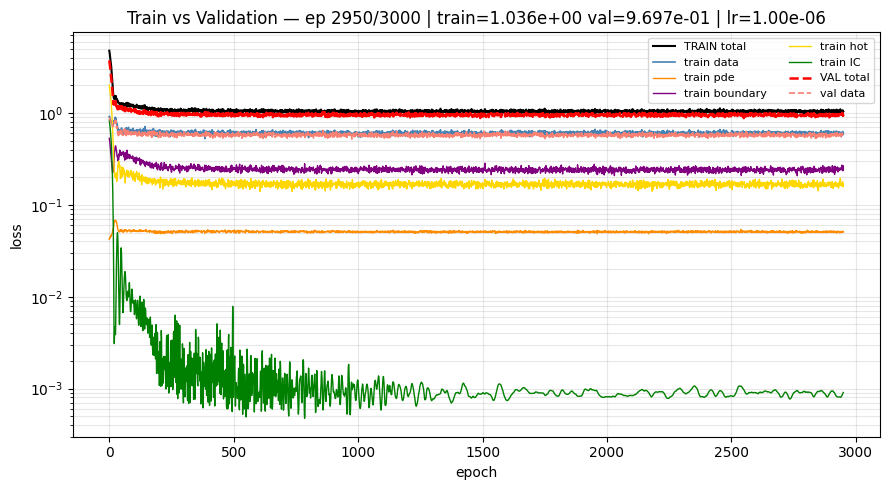

ep    0 | train=4.771e+00 | val=3.737e+00 | train_data=9.153e-01 val_data=8.949e-01 | t=1.70s
ep   50 | train=1.245e+00 | val=1.175e+00 | train_data=6.406e-01 val_data=6.439e-01 | t=0.48s
ep  100 | train=1.173e+00 | val=1.094e+00 | train_data=6.289e-01 val_data=6.211e-01 | t=0.47s
ep  150 | train=1.103e+00 | val=1.016e+00 | train_data=6.154e-01 val_data=5.757e-01 | t=0.45s
ep  200 | train=1.083e+00 | val=9.645e-01 | train_data=6.047e-01 val_data=5.803e-01 | t=0.48s
ep  250 | train=1.075e+00 | val=9.798e-01 | train_data=6.457e-01 val_data=6.012e-01 | t=0.53s
ep  300 | train=1.083e+00 | val=1.006e+00 | train_data=6.246e-01 val_data=6.247e-01 | t=0.49s
ep  350 | train=1.067e+00 | val=9.805e-01 | train_data=6.164e-01 val_data=5.886e-01 | t=0.46s
ep  400 | train=1.025e+00 | val=9.383e-01 | train_data=5.732e-01 val_data=5.589e-01 | t=0.53s
ep  450 | train=1.056e+00 | val=9.522e-01 | train_data=6.069e-01 val_data=5.992e-01 | t=0.49s
ep  500 | train=1.065e+00 | val=9.600e-01 | train_data=6.041

In [ ]:
import gc; gc.collect(); torch.cuda.empty_cache()

X_mean_t=torch.tensor(X_mean,dtype=torch.float32,device=device)
X_std_t =torch.tensor(X_std, dtype=torch.float32,device=device)
Y_mean_t=torch.tensor(Y_mean,dtype=torch.float32,device=device)
Y_std_t =torch.tensor(Y_std, dtype=torch.float32,device=device)
t_feat_max_train=float(X_data[:,0].max())

for g in opt.param_groups: g['lr']=2e-4
w_pde=1; w_data=1; w_IC=1; w_transient=1.0; w_hot=1.3; w_boundary=0.7
n_pde=8096; N_STEADY_BATCH=4096; FD_HALF_WINDOW=1
TAU_THRESH=np.tanh(2.0)

# =========================================================
# TRAIN / VAL split by run_id  (run 0 = train, run 1 = validation)
#   training samples ONLY from run 0; run 1 is held out for validation loss
# =========================================================
tr_idx = np.where(sample_run_id==0)[0]
va_idx = np.where(sample_run_id==1)[0]
print(f"train samples: {len(tr_idx):,}   val samples: {len(va_idx):,}")

# --- TRAIN index sets (run 0 only) ---
steady_indices = tr_idx[ X_data[tr_idx,0] >= TAU_THRESH ]
trans_indices  = tr_idx[ X_data[tr_idx,0] <  TAU_THRESH ]
hot_indices    = tr_idx[ Y_data[tr_idx].reshape(-1) > 1550 ]
boundary_indices = tr_idx[ np.abs((Y_data[tr_idx].reshape(-1)+Tamb) - Tl) < boundary_band ]
speed_tr = np.sqrt(X_data[tr_idx,6]**2 + X_data[tr_idx,7]**2)
turnaround_indices = tr_idx[ speed_tr < 0.1*V_MAX ]

# --- VAL index sets (run 1 only) ---
va_steady = va_idx[ X_data[va_idx,0] >= TAU_THRESH ]
va_trans  = va_idx[ X_data[va_idx,0] <  TAU_THRESH ]
va_hot    = va_idx[ Y_data[va_idx].reshape(-1) > 1550 ]
va_bnd    = va_idx[ np.abs((Y_data[va_idx].reshape(-1)+Tamb) - Tl) < boundary_band ]
print(f"TRAIN: steady={len(steady_indices)} trans={len(trans_indices)} hot={len(hot_indices)} bnd={len(boundary_indices)}")
print(f"VAL  : steady={len(va_steady)} trans={len(va_trans)} hot={len(va_hot)} bnd={len(va_bnd)}")

# --- valid PDE samples (train run only) ---
valid_pde_mask = np.zeros(len(X_data), dtype=bool)
for run_idx, run in enumerate(all_runs):
    if run_idx != 0: continue                      # PDE only on train run
    rows = sample_run_id==run_idx
    n_steps_run = len(run["tPath"])
    valid_pde_mask[rows] = ((sample_step_id[rows]>=FD_HALF_WINDOW) &
                            (sample_step_id[rows]<n_steps_run-FD_HALF_WINDOW))
valid_pde_indices = np.where(valid_pde_mask)[0]
print(f"Valid transient PDE samples (train): {len(valid_pde_indices):,}")

epochs=3000
loss_hist=[]; data_hist=[]; pde_hist=[]; boundary_hist=[]; IC_hist=[]; hot_hist=[]
val_hist=[]; val_data_hist=[]
log=[]

for epoch in range(epochs):
    t0=time.time()
    opt.zero_grad()

    # ---- TRAIN losses (run 0) ----
    idx_steady=np.random.choice(steady_indices,size=min(N_STEADY_BATCH,len(steady_indices)),replace=False)
    loss_steady=mse_loss(model(to_gpu(X_tensor[idx_steady])),to_gpu(Y_tensor[idx_steady]))
    t_samp=np.random.choice(trans_indices,size=min(len(trans_indices),2048),replace=True)
    loss_trans=mse_loss(model(to_gpu(X_tensor[t_samp])),to_gpu(Y_tensor[t_samp]))
    if DATA_MODE=="experimental": loss_data=w_transient*loss_trans
    else: loss_data=loss_steady+w_transient*loss_trans

    hot_sample=np.random.choice(hot_indices,size=min(2048,len(hot_indices)),replace=False)
    loss_hot=mse_loss(model(to_gpu(X_tensor[hot_sample])),to_gpu(Y_tensor[hot_sample]))
    boundary_sample=np.random.choice(boundary_indices,size=min(2048,len(boundary_indices)),replace=False)
    loss_boundary=mse_loss(model(to_gpu(X_tensor[boundary_sample])),to_gpu(Y_tensor[boundary_sample]))
    loss_ic=mse_loss(model(to_gpu(X_ic_tensor)),to_gpu(Y_ic_tensor))

    # ---- transient PDE (train run) ----
    n_pde_actual=min(n_pde,len(valid_pde_indices))
    idx_pde=np.random.choice(valid_pde_indices,size=n_pde_actual,replace=False)
    X_current_np=X_data[idx_pde].astype(np.float32)
    run_batch=sample_run_id[idx_pde]; step_batch=sample_step_id[idx_pde]
    X_previous_np,previous_steps,valid_previous=build_same_material_neighbor_inputs(X_current_np,run_batch,step_batch,step_offset=-FD_HALF_WINDOW)
    X_next_np,next_steps,valid_next=build_same_material_neighbor_inputs(X_current_np,run_batch,step_batch,step_offset=+FD_HALF_WINDOW)
    valid_neighbors=valid_previous&valid_next
    if not np.all(valid_neighbors):
        idx_pde=idx_pde[valid_neighbors]; run_batch=run_batch[valid_neighbors]
        X_current_np=X_current_np[valid_neighbors]; X_previous_np=X_previous_np[valid_neighbors]
        X_next_np=X_next_np[valid_neighbors]; previous_steps=previous_steps[valid_neighbors]; next_steps=next_steps[valid_neighbors]
    dt_pn_np=get_neighbor_time_interval(run_batch,previous_steps,next_steps)
    Xpde=torch.tensor(X_current_np,dtype=torch.float32,device=device,requires_grad=True)
    Xpde_prev=torch.tensor(X_previous_np,dtype=torch.float32,device=device)
    Xpde_next=torch.tensor(X_next_np,dtype=torch.float32,device=device)
    dt_pn=torch.tensor(dt_pn_np,dtype=torch.float32,device=device).reshape(-1,1)
    wm_pde=torch.tensor(was_melted_batch_all[idx_pde],dtype=torch.float32,device=device).unsqueeze(1)
    res=pde_residual_phase(model_deltaT_phys,Xpde,params,q_scale=q_scale,was_melted_batch=wm_pde,
                           use_transient=True,X_previous=Xpde_prev,X_next=Xpde_next,dt_previous_next=dt_pn)
    loss_pde=torch.mean(res**2)
    if not torch.isfinite(loss_pde): loss_pde=torch.zeros((),device=device)
    del Xpde,Xpde_prev,Xpde_next,dt_pn,wm_pde,res

    loss=(w_data*loss_data + w_hot*loss_hot + w_boundary*loss_boundary + w_IC*loss_ic + w_pde*loss_pde)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
    opt.step()
    scheduler_s2.step(loss_data.item())

    # ---- VALIDATION loss (run 1, NO backprop) ----
    model.eval()
    with torch.no_grad():
        vt=np.random.choice(va_trans if len(va_trans)>0 else va_idx, size=min(2048,max(1,len(va_trans))), replace=True)
        v_data=mse_loss(model(to_gpu(X_tensor[vt])),to_gpu(Y_tensor[vt]))
        if len(va_hot)>0:
            vh=np.random.choice(va_hot,size=min(2048,len(va_hot)),replace=True)
            v_hot=mse_loss(model(to_gpu(X_tensor[vh])),to_gpu(Y_tensor[vh]))
        else: v_hot=torch.zeros((),device=device)
        if len(va_bnd)>0:
            vb=np.random.choice(va_bnd,size=min(2048,len(va_bnd)),replace=True)
            v_bnd=mse_loss(model(to_gpu(X_tensor[vb])),to_gpu(Y_tensor[vb]))
        else: v_bnd=torch.zeros((),device=device)
        v_total=w_data*v_data + w_hot*v_hot + w_boundary*v_bnd
    model.train()

    if epoch%10==0: torch.cuda.empty_cache()
    t1=time.time()
    loss_hist.append(loss.item()); data_hist.append(loss_data.item()); pde_hist.append(loss_pde.item())
    boundary_hist.append(loss_boundary.item()); IC_hist.append(loss_ic.item()); hot_hist.append(loss_hot.item())
    val_hist.append(v_total.item()); val_data_hist.append(v_data.item())

    if epoch%50==0:
        clear_output(wait=True)
        fig,ax=plt.subplots(figsize=(9,5))
        ax.plot(loss_hist,label="TRAIN total",color='black',lw=1.5)
        ax.plot(data_hist,label="train data",color='steelblue',lw=1.2)
        ax.plot(pde_hist,label="train pde",color='darkorange',lw=1.0)
        ax.plot(boundary_hist,label="train boundary",color='purple',lw=1.0)
        ax.plot(hot_hist,label="train hot",color='gold',lw=1.0)
        ax.plot(IC_hist,label="train IC",color='green',lw=1.0)
        ax.plot(val_hist,label="VAL total",color='red',lw=1.8,ls='--')
        ax.plot(val_data_hist,label="val data",color='salmon',lw=1.2,ls='--')
        ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
        ax.set_title(f"Train vs Validation — ep {epoch}/{epochs} | "
                     f"train={loss.item():.3e} val={v_total.item():.3e} | lr={opt.param_groups[0]['lr']:.2e}")
        ax.legend(fontsize=8,ncol=2); ax.grid(True,which="both",alpha=0.3)
        plt.tight_layout(); plt.show()
        log.append(f"ep {epoch:4d} | train={loss.item():.3e} | val={v_total.item():.3e} | "
                   f"train_data={loss_data.item():.3e} val_data={v_data.item():.3e} | t={t1-t0:.2f}s")
        print("\n".join(log))

fig.savefig("loss_train_val.png",dpi=300,bbox_inches="tight")
torch.save(model.state_dict(),"model_stage1_trainval.pt")
print("saved")

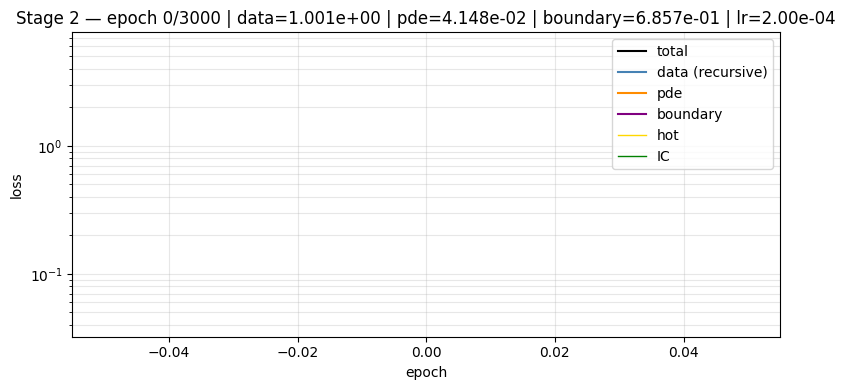

epoch    0 | loss=6.012e+00 | data=1.001e+00 | pde=4.148e-02 | boundary=6.857e-01 | hot=2.607e+00 | ic=1.100e+00 | lr=2.00e-04 | time=4.62s
  [caching rollout features for run 1 ...]


KeyboardInterrupt: 

In [ ]:
# =========================================================
# Cell 13 — Stage 1: recursive (cached, chunked) data + PDE + boundary
# =========================================================
import gc
gc.collect()
torch.cuda.empty_cache()

X_mean_t = torch.tensor(X_mean, dtype=torch.float32, device=device)
X_std_t  = torch.tensor(X_std,  dtype=torch.float32, device=device)
Y_mean_t = torch.tensor(Y_mean, dtype=torch.float32, device=device)
Y_std_t  = torch.tensor(Y_std,  dtype=torch.float32, device=device)
t_feat_max_train = float(X_data[:, 0].max())

for g in opt.param_groups:
    g['lr'] = 2e-4

scheduler_s2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode='min', factor=0.5, patience=150, min_lr=1e-6
)

# Physical source scale used to normalize the residual.
P_ref = float(np.mean(X_data[X_data[:, 3] > 0, 3]))
q_scale = (params["absorb"] * P_ref
           / (2.0 * np.pi * params["sigma"]**2 * params["depth"]))
q_scale_bnd = q_scale
q_scale_far = q_scale
print(f"P_ref   : {P_ref:.3f} W")
print(f"q_scale : {q_scale:.3e} W/m^3")


def sample_far_pde_points(n=512, min_dist_mm=0.15):
    dx = np.random.uniform(-patch_half_width*1000,  patch_half_width*1000,  n*4)
    dy = np.random.uniform(-patch_half_height*1000, patch_half_height*1000, n*4)
    dist = np.sqrt(dx**2 + dy**2)
    far  = dist > min_dist_mm
    dx   = dx[far][:n];  dy = dy[far][:n]
    n_act = len(dx)
    t_feat = np.random.uniform(0.0,   t_feat_max_train, n_act)
    P      = np.random.uniform(120.0, 280.0,            n_act)
    vx     = np.random.uniform(-0.6,  0.6,              n_act)
    vy     = np.random.uniform(-0.6,  0.6,              n_act)
    dist_x = np.random.uniform(1.0,   25.0,             n_act)
    dist_y = np.random.uniform(1.0,   25.0,             n_act)
    X_far = np.column_stack([t_feat, dx, dy, P, dist_x, dist_y, vx, vy])
    return (X_far - X_mean) / X_std, n_act, dx, dy, t_feat


# --- loss weights ---
w_pde          = 1
w_data         = 1
w_IC           = 1
w_transient    = 1.0
w_hot          = 1.3
w_boundary     = 0.7
w_pde_far      = 0
n_pde          = 8096
n_pde_far      = 512
w_pde_bnd      = 0
N_STEADY_BATCH = 4096
w_turnaround   = 0.0
w_pde_turn     = 0.0
FD_HALF_WINDOW = 1

# --- recursive rollout config ---
W_RECURSIVE = 256     # frames per episode; None = full track
CHUNK       = 32      # frames per backward; lower to 16/8 if OOM
CACHE_ON_GPU = True   # False -> keep cached features on CPU (saves GPU mem, a bit slower)

if 'steady_indices' not in dir():
    TAU_THRESH     = np.tanh(2.0)
    trans_mask     = X_data[:, 0] < TAU_THRESH
    steady_indices = np.where(~trans_mask)[0]
    trans_indices  = np.where(trans_mask)[0]

hot_mask_train = Y_data.reshape(-1) > 1550
hot_indices    = np.where(hot_mask_train)[0]

speed_all = np.sqrt(X_data[:, 6]**2 + X_data[:, 7]**2)
turnaround_indices = np.where(speed_all < 0.1 * V_MAX)[0]
print(f"Turnaround indices: {len(turnaround_indices):,} "
      f"({len(turnaround_indices)/len(X_data)*100:.3f}%)")
print(f"Hot indices (>1550K)              : {len(hot_indices):,}")
print(f"Boundary indices (|T-Tl|<{boundary_band:.0f}K)  : {len(boundary_indices):,}")
print(f"q_scale     : {q_scale:.3e}")
print(f"w_pde       : {w_pde:.3e}")
print(f"w_boundary  : {w_boundary:.3e}")

epochs        = 3000
loss_hist=[]; data_hist=[]; trans_hist=[]; pde_hist=[]
pde_bnd_hist=[]; pde_far_hist=[]; boundary_hist=[]; IC_hist=[]; hot_hist=[]; turn_hist=[]
log=[]
epoch_snapshots = []
SNAPSHOT_EVERY  = 50

valid_pde_mask = np.ones(len(X_data), dtype=bool)
for run_idx, run in enumerate(all_runs):
    run_rows = sample_run_id == run_idx
    n_steps_run = len(run["tPath"])
    valid_pde_mask[run_rows] = (
        (sample_step_id[run_rows] >= FD_HALF_WINDOW)
        & (sample_step_id[run_rows] < n_steps_run - FD_HALF_WINDOW))
valid_pde_indices = np.where(valid_pde_mask)[0]
print(f"Valid transient PDE samples: {len(valid_pde_indices):,} / {len(X_data):,}")


# =========================================================
# Precompute per-frame rollout inputs ONCE per run.
# Everything except T_previous depends only on scan path + mesh,
# so it never changes across epochs. Only T_previous is dynamic.
# =========================================================
_rollout_cache = {}

assert DATA_MODE in ("sim", "experimental"), f"bad DATA_MODE: {DATA_MODE}"
print(f"Rollout cache frame mode: {DATA_MODE}")

def precompute_rollout_cache(run):
    xNodes_r=run['xNodes']; yNodes_r=run['yNodes']
    xPath_r=run['xPath']; yPath_r=run['yPath']; tPath_r=run['tPath']; Power_r=run['Power']
    T_r=run['T']; vx_r=run['vx_path']; vy_r=run['vy_path']; Nt=T_r.shape[1]
    dev = device if CACHE_ON_GPU else 'cpu'
    Xm8 = X_mean_t[:, :8].to(dev); Xs8 = X_std_t[:, :8].to(dev)
    Ym  = Y_mean_t.to(dev);        Ys  = Y_std_t.to(dev)
    frames=[None]*Nt
    for k in range(1, Nt):
        xL=float(xPath_r[k]); yL=float(yPath_r[k])
        p=float(Power_r[k]) if Power_r.size>1 else float(Power_r[0])
        vx,vy=get_safe_velocity(k,vx_r,vy_r)
        t_feat=np.tanh((tPath_r[k]-tPath_r[0])/TAU)
        speed=np.sqrt(vx**2+vy**2)+1e-12; vx_n,vy_n=vx/speed,vy/speed

        # ---- FRAME-DEPENDENT: patch mask ----
        if DATA_MODE == "experimental":
            mask=get_patch_mask(xNodes_r,yNodes_r,0.0,0.0,
                                patch_half_width,patch_half_height,
                                -patch_offset*vx_n, -patch_offset*vy_n)
        else:
            mask=get_patch_mask(xNodes_r,yNodes_r,xL,yL,
                                patch_half_width,patch_half_height,
                                xL-patch_offset*vx_n, yL-patch_offset*vy_n)
        if mask.sum()==0:
            continue
        idx=np.where(mask)[0]; xP=xNodes_r[idx]; yP=yNodes_r[idx]

        # ---- FRAME-DEPENDENT: dx/dy and edge distance ----
        if DATA_MODE == "experimental":
            dxk = xP*1000.0                        # already laser-relative
            dyk = yP*1000.0
            xabs = xP+xL; yabs = yP+yL             # reconstruct absolute
            dist_xk = np.minimum(xabs, plateX-xabs)*1000.0
            dist_yk = np.minimum(yabs, plateY-yabs)*1000.0
        else:
            dxk = (xP-xL)*1000.0
            dyk = (yP-yL)*1000.0
            dist_xk = np.minimum(xP, plateX-xP)*1000.0
            dist_yk = np.minimum(yP, plateY-yP)*1000.0

        static=np.column_stack([
            np.full_like(xP,t_feat), dxk, dyk, np.full_like(xP,p),
            dist_xk, dist_yk,
            np.full_like(xP,vx), np.full_like(xP,vy)]).astype(np.float32)

        idx_t=torch.tensor(idx,dtype=torch.long,device=dev)
        static_n=(torch.tensor(static,device=dev)-Xm8)/Xs8
        tgt=torch.clamp(torch.tensor(T_r[:,k][idx],dtype=torch.float32,device=dev)-Tamb,min=0.0).unsqueeze(1)
        tgt_n=(tgt-Ym)/Ys
        frames[k]=(idx_t, static_n, tgt_n)
    return frames

def get_rollout_cache(ri, run):
    if ri not in _rollout_cache:
        print(f"  [caching rollout features for run {ri} ...]")
        _rollout_cache[ri]=precompute_rollout_cache(run)
    return _rollout_cache[ri]


def recursive_data_backward_cached(run, cache, weight=1.0, k_start=1, window=None, chunk=32):
    """
    Recursive data loss with cached per-frame features + chunked backward.
    T_previous = model's own prediction (detached between frames).
    Accumulates grads into model params; does NOT zero_grad or step.
    Returns mean per-frame MSE (float).
    """
    T_r=run['T']; Nt=T_r.shape[1]
    k_end=(Nt-1) if window is None else min(k_start+window, Nt-1)
    if k_end<=k_start: return 0.0
    n_frames=k_end-k_start
    T_state=torch.clamp(torch.tensor(T_r[:,k_start],dtype=torch.float32,device=device)-Tamb,min=0.0).detach()
    xm8=float(X_mean_t[0,8]); xs8=float(X_std_t[0,8])
    chunk_losses=[]; total_t=torch.zeros((),device=device)

    def _flush(cl):
        if cl: (torch.stack(cl).sum()*(weight/n_frames)).backward()

    for k in range(k_start+1, k_end+1):
        fr=cache[k]
        if fr is None: continue
        idx_t, static_n, tgt_n = fr
        if not CACHE_ON_GPU:
            idx_t=idx_t.to(device, non_blocking=True)
            static_n=static_n.to(device, non_blocking=True)
            tgt_n=tgt_n.to(device, non_blocking=True)
        Tprev_n=((T_state[idx_t]-xm8)/xs8).unsqueeze(1)
        pred_n=model(torch.cat([static_n, Tprev_n], dim=1))
        mse_k=mse_loss(pred_n, tgt_n)
        chunk_losses.append(mse_k); total_t+=mse_k.detach()
        pred_dT=torch.clamp(pred_n*Y_std_t+Y_mean_t, min=0.0).squeeze(1)
        T_state.index_copy_(0, idx_t, pred_dT.detach())     # in-place, no clone
        if len(chunk_losses)>=chunk: _flush(chunk_losses); chunk_losses=[]
    _flush(chunk_losses)
    return float(total_t)/n_frames


for epoch in range(epochs):
    t0 = time.time()
    opt.zero_grad()

    # --- recursive data loss (cached, chunked backward) ---
    ri = np.random.randint(len(all_runs)); run_r = all_runs[ri]
    cache = get_rollout_cache(ri, run_r)
    Nt_r  = run_r['T'].shape[1]
    k0    = 1 if W_RECURSIVE is None else np.random.randint(1, max(2, Nt_r - W_RECURSIVE))
    data_val = recursive_data_backward_cached(run_r, cache, weight=w_data,
                                              k_start=k0, window=W_RECURSIVE, chunk=CHUNK)

    # --- hot batch ---
    n_hot      = min(2048, len(hot_indices))
    hot_sample = np.random.choice(hot_indices, size=n_hot, replace=False)
    loss_hot   = mse_loss(model(to_gpu(X_tensor[hot_sample])), to_gpu(Y_tensor[hot_sample]))

    # --- boundary batch ---
    n_boundary      = min(2048, len(boundary_indices))
    boundary_sample = np.random.choice(boundary_indices, size=n_boundary, replace=False)
    loss_boundary   = mse_loss(model(to_gpu(X_tensor[boundary_sample])),
                               to_gpu(Y_tensor[boundary_sample]))

    # --- IC ---
    loss_ic = mse_loss(model(to_gpu(X_ic_tensor)), to_gpu(Y_ic_tensor))

    # --- turnaround (guarded: triangle set may have none) ---
    if len(turnaround_indices) > 0:
        n_turn      = min(1024, len(turnaround_indices))
        turn_sample = np.random.choice(turnaround_indices, size=n_turn, replace=True)
        loss_turnaround = mse_loss(model(to_gpu(X_tensor[turn_sample])),
                                   to_gpu(Y_tensor[turn_sample]))
    else:
        loss_turnaround = torch.tensor(0.0, device=device)

    # --- transient PDE collocation (STILL teacher-forced: sim neighbors) ---
    n_pde_actual = min(n_pde, len(valid_pde_indices))
    idx_pde = np.random.choice(valid_pde_indices, size=n_pde_actual, replace=False)
    X_current_np = X_data[idx_pde].astype(np.float32)
    run_batch  = sample_run_id[idx_pde]
    step_batch = sample_step_id[idx_pde]

    X_previous_np, previous_steps, valid_previous = build_same_material_neighbor_inputs(
        X_current_np, run_batch, step_batch, step_offset=-FD_HALF_WINDOW)
    X_next_np, next_steps, valid_next = build_same_material_neighbor_inputs(
        X_current_np, run_batch, step_batch, step_offset=+FD_HALF_WINDOW)
    valid_neighbors = valid_previous & valid_next
    if not np.all(valid_neighbors):
        idx_pde       = idx_pde[valid_neighbors]
        run_batch     = run_batch[valid_neighbors]
        X_current_np  = X_current_np[valid_neighbors]
        X_previous_np = X_previous_np[valid_neighbors]
        X_next_np     = X_next_np[valid_neighbors]
        previous_steps = previous_steps[valid_neighbors]
        next_steps     = next_steps[valid_neighbors]

    dt_previous_next_np = get_neighbor_time_interval(run_batch, previous_steps, next_steps)
    Xpde          = torch.tensor(X_current_np,  dtype=torch.float32, device=device, requires_grad=True)
    Xpde_previous = torch.tensor(X_previous_np, dtype=torch.float32, device=device)
    Xpde_next     = torch.tensor(X_next_np,     dtype=torch.float32, device=device)
    dt_previous_next = torch.tensor(dt_previous_next_np, dtype=torch.float32, device=device).reshape(-1, 1)
    wm_pde = torch.tensor(was_melted_batch_all[idx_pde], dtype=torch.float32, device=device).unsqueeze(1)

    res = pde_residual_phase(model_deltaT_phys, Xpde, params, q_scale=q_scale,
                             was_melted_batch=wm_pde, use_transient=True,
                             X_previous=Xpde_previous, X_next=Xpde_next,
                             dt_previous_next=dt_previous_next)
    loss_pde = torch.mean(res**2)
    if not torch.isfinite(loss_pde):
        print("Warning: non-finite PDE loss")
        loss_pde = torch.zeros((), dtype=torch.float32, device=device)
    del Xpde, Xpde_previous, Xpde_next, dt_previous_next, wm_pde, res

    # --- backward the NON-recursive losses (recursive part already backwarded) ---
    loss_other = (w_hot*loss_hot + w_boundary*loss_boundary + w_IC*loss_ic + w_pde*loss_pde)
    loss_other.backward()

    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    opt.step()
    scheduler_s2.step(data_val)

    loss_other_val = float(loss_other.detach())
    total_val = w_data*data_val + loss_other_val

    if epoch % SNAPSHOT_EVERY == 0:
        epoch_snapshots.append({
            'epoch'     : epoch,
            'hot'       : X_data[hot_sample, 1:3].copy(),
            'hot_t'     : X_data[hot_sample, 0].copy(),
            'pde'       : X_data[idx_pde, 1:3].copy(),
            'pde_t'     : X_data[idx_pde, 0].copy(),
            'boundary'  : X_data[boundary_sample, 1:3].copy(),
            'boundary_t': X_data[boundary_sample, 0].copy(),
        })

    t1 = time.time()
    loss_hist.append(total_val)
    data_hist.append(data_val)
    pde_hist.append(loss_pde.item())
    boundary_hist.append(loss_boundary.item())
    IC_hist.append(loss_ic.item())
    hot_hist.append(loss_hot.item())
    turn_hist.append(float(loss_turnaround.detach()))

    if epoch % 50 == 0:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(loss_hist,     label="total",            color='black',      lw=1.5)
        ax.plot(data_hist,     label="data (recursive)", color='steelblue',  lw=1.5)
        ax.plot(pde_hist,      label="pde",              color='darkorange', lw=1.5)
        ax.plot(boundary_hist, label="boundary",         color='purple',     lw=1.5)
        ax.plot(hot_hist,      label="hot",              color='gold',       lw=1.0)
        ax.plot(IC_hist,       label="IC",               color='green',      lw=1.0)
        ax.set_yscale("log")
        ax.set_xlabel("epoch");  ax.set_ylabel("loss")
        ax.set_title(
            f"Stage 2 — epoch {epoch}/{epochs} | data={data_val:.3e} | "
            f"pde={loss_pde.item():.3e} | boundary={loss_boundary.item():.3e} | "
            f"lr={opt.param_groups[0]['lr']:.2e}")
        ax.legend();  ax.grid(True, which="both", alpha=0.3)
        plt.tight_layout();  plt.show()

        log.append(
            f"epoch {epoch:4d} | loss={total_val:.3e} | data={data_val:.3e} | "
            f"pde={loss_pde.item():.3e} | boundary={loss_boundary.item():.3e} | "
            f"hot={loss_hot.item():.3e} | ic={loss_ic.item():.3e} | "
            f"lr={opt.param_groups[0]['lr']:.2e} | time={t1-t0:.2f}s")
        print("\n".join(log))

fig.savefig(f"loss_epoch_{epoch}_stage2.png", dpi=300, bbox_inches="tight")
torch.save(model.state_dict(), "model_stage2_1_set.pt")
print("Stage 2 weights saved")

In [15]:
# =========================================================
# M-STEP-AHEAD rollout loss (Model 5 addition)
#   unroll M_AHEAD steps from a true seed, penalize EVERY step vs truth,
#   gradient flows through the whole rollout (no detach) -> trains stability.
#   Uses the rollout cache (per-frame static_n, tgt_n, idx_t).
# =========================================================
M_AHEAD        = 13          # penalize steps 1..M_AHEAD (changeable)
N_MSTEP_STARTS = 8           # how many start frames to roll per epoch
W_MSTEP        = 1.0

def mstep_rollout_loss(run, cache, m_ahead=M_AHEAD, n_starts=N_MSTEP_STARTS):
    T_r = run['T']; Nt = T_r.shape[1]
    # valid start frames: need m_ahead consecutive non-None cache frames ahead
    valid_starts = [k for k in range(1, Nt - m_ahead)
                    if all(cache[k+j] is not None for j in range(0, m_ahead+1))]
    if len(valid_starts) == 0:
        return None
    starts = np.random.choice(valid_starts, size=min(n_starts, len(valid_starts)), replace=False)

    xm8_s = float(X_mean_t[0,8]); xs8_s = float(X_std_t[0,8])
    total = 0.0; nterms = 0
    for k0 in starts:
        # seed state (ΔT above ambient) from TRUE field at k0, over ALL nodes
        T_state = torch.clamp(torch.tensor(T_r[:,k0], dtype=torch.float32, device=device) - Tamb, min=0.0)
        for j in range(1, m_ahead+1):
            fr = cache[k0+j]
            idx_t, static_n, tgt_n = fr
            # input: static features + previous ΔT (normalized), from the maintained state
            Tprev_n = ((T_state[idx_t] - xm8_s) / xs8_s).unsqueeze(1)
            pred_n  = model(torch.cat([static_n, Tprev_n], dim=1))     # normalized ΔT prediction
            # --- PENALIZE this step against truth (per-step loss) ---
            total = total + mse_loss(pred_n, tgt_n)
            nterms += 1
            # feed prediction forward (de-normalize to ΔT), KEEP GRAPH (no detach)
            pred_dT = torch.clamp(pred_n * Y_std_t.squeeze() + Y_mean_t.squeeze(), 0.0).squeeze(-1)
            T_state = T_state.clone()
            T_state[idx_t] = pred_dT                                   # <-- gradient flows through
    if nterms == 0:
        return None
    return total / nterms

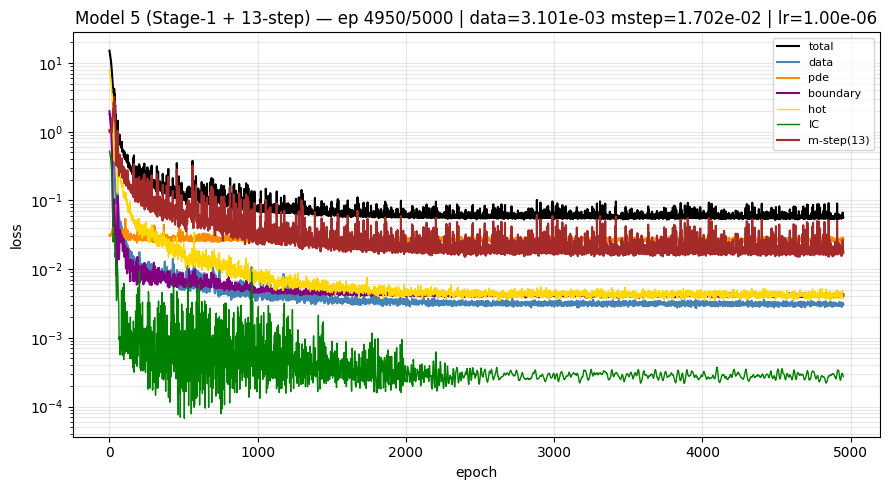

ep    0 | loss=1.511e+01 | data=1.788e+00 | pde=3.147e-02 | mstep=1.060e+00 | t=4.05s
ep   50 | loss=8.882e-01 | data=9.947e-02 | pde=3.148e-02 | mstep=3.757e-01 | t=0.83s
ep  100 | loss=4.899e-01 | data=2.415e-02 | pde=2.801e-02 | mstep=2.483e-01 | t=1.14s
ep  150 | loss=2.949e-01 | data=1.771e-02 | pde=2.839e-02 | mstep=1.662e-01 | t=0.84s
ep  200 | loss=3.359e-01 | data=1.259e-02 | pde=2.794e-02 | mstep=2.188e-01 | t=0.82s
ep  250 | loss=1.818e-01 | data=9.056e-03 | pde=2.757e-02 | mstep=9.645e-02 | t=0.85s
ep  300 | loss=1.631e-01 | data=6.915e-03 | pde=3.157e-02 | mstep=7.893e-02 | t=1.24s
ep  350 | loss=1.775e-01 | data=9.435e-03 | pde=2.762e-02 | mstep=1.009e-01 | t=0.83s
ep  400 | loss=1.276e-01 | data=6.907e-03 | pde=2.855e-02 | mstep=5.797e-02 | t=0.83s
ep  450 | loss=1.422e-01 | data=7.263e-03 | pde=2.742e-02 | mstep=7.827e-02 | t=0.84s
ep  500 | loss=1.248e-01 | data=5.434e-03 | pde=3.044e-02 | mstep=5.388e-02 | t=1.21s
ep  550 | loss=1.155e-01 | data=6.931e-03 | pde=3.064e

In [18]:
import gc; gc.collect(); torch.cuda.empty_cache()

X_mean_t = torch.tensor(X_mean, dtype=torch.float32, device=device)
X_std_t  = torch.tensor(X_std,  dtype=torch.float32, device=device)
Y_mean_t = torch.tensor(Y_mean, dtype=torch.float32, device=device)
Y_std_t  = torch.tensor(Y_std,  dtype=torch.float32, device=device)
t_feat_max_train = float(X_data[:, 0].max())
P_ref   = float(np.mean(X_data[X_data[:,3] > 0, 3]))
q_scale = (params["absorb"]*P_ref)/(2.0*np.pi*params["sigma"]**2*params["depth"])
print(f"P_ref: {P_ref:.3f} W   q_scale: {q_scale:.3e} W/m^3")

for g in opt.param_groups: g['lr'] = 2e-4
scheduler_s2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode='min', factor=0.5, patience=150, min_lr=1e-6
)
# --- loss weights ---
w_pde=1; w_data=1; w_IC=1; w_transient=1.0; w_hot=1.3; w_boundary=0.7
n_pde=8096; N_STEADY_BATCH=4096; FD_HALF_WINDOW=1
# --- m-step-ahead (Model 5) ---
W_MSTEP        = 1.0
M_AHEAD        = 13          # penalize steps 1..M_AHEAD (sim: truth at every step)
N_MSTEP_STARTS = 8           # start frames rolled per epoch (memory-bound)

if 'steady_indices' not in dir():
    TAU_THRESH=np.tanh(2.0); trans_mask=X_data[:,0]<TAU_THRESH
    steady_indices=np.where(~trans_mask)[0]; trans_indices=np.where(trans_mask)[0]
hot_indices=np.where(Y_data.reshape(-1)>1550)[0]
speed_all=np.sqrt(X_data[:,6]**2+X_data[:,7]**2)
turnaround_indices=np.where(speed_all<0.1*V_MAX)[0]
print(f"Hot:{len(hot_indices):,} Boundary:{len(boundary_indices):,} Turn:{len(turnaround_indices):,}")

# --- sim rollout cache for the m-step loss ---
run_r = all_runs[0]
cache = get_rollout_cache(0, run_r)
xm8_s=float(X_mean_t[0,8]); xs8_s=float(X_std_t[0,8])

def mstep_rollout_loss(run, cache, m_ahead=M_AHEAD, n_starts=N_MSTEP_STARTS):
    """unroll m_ahead steps from a TRUE seed; penalize EVERY step vs truth;
       gradient flows through the whole rollout (no detach)."""
    T_r=run['T']; Nt=T_r.shape[1]
    valid=[k for k in range(1,Nt-m_ahead) if all(cache[k+j] is not None for j in range(0,m_ahead+1))]
    if len(valid)==0: return None
    starts=np.random.choice(valid, size=min(n_starts,len(valid)), replace=False)
    total=0.0; nterms=0
    for k0 in starts:
        T_state=torch.clamp(torch.tensor(T_r[:,k0],dtype=torch.float32,device=device)-Tamb,min=0.0)
        for j in range(1,m_ahead+1):
            idx_t,static_n,tgt_n=cache[k0+j]
            Tprev_n=((T_state[idx_t]-xm8_s)/xs8_s).unsqueeze(1)
            pred_n=model(torch.cat([static_n,Tprev_n],dim=1))
            total=total+mse_loss(pred_n,tgt_n); nterms+=1                   # penalize THIS step
            pred_dT=torch.clamp(pred_n*Y_std_t.squeeze()+Y_mean_t.squeeze(),0.0).squeeze(-1)
            T_state=T_state.clone(); T_state[idx_t]=pred_dT                 # NO detach: grad flows
    return (total/nterms) if nterms>0 else None

epochs=5000
loss_hist=[]; data_hist=[]; pde_hist=[]; boundary_hist=[]; IC_hist=[]; hot_hist=[]; mstep_hist=[]; log=[]

# valid transient PDE samples
valid_pde_mask=np.ones(len(X_data),dtype=bool)
for run_idx,run in enumerate(all_runs):
    rows=sample_run_id==run_idx; n_steps_run=len(run["tPath"])
    valid_pde_mask[rows]=((sample_step_id[rows]>=FD_HALF_WINDOW)&(sample_step_id[rows]<n_steps_run-FD_HALF_WINDOW))
valid_pde_indices=np.where(valid_pde_mask)[0]

for epoch in range(epochs):
    t0=time.time(); opt.zero_grad()

    # --- data (steady+transient) ---
    idx_steady=np.random.choice(steady_indices,size=min(N_STEADY_BATCH,len(steady_indices)),replace=False)
    loss_steady=mse_loss(model(to_gpu(X_tensor[idx_steady])),to_gpu(Y_tensor[idx_steady]))
    t_samp=np.random.choice(trans_indices,size=min(len(trans_indices),2048),replace=True)
    loss_trans=mse_loss(model(to_gpu(X_tensor[t_samp])),to_gpu(Y_tensor[t_samp]))
    loss_data = w_transient*loss_trans if DATA_MODE=="experimental" else loss_steady+w_transient*loss_trans

    # --- hot / boundary / IC ---
    hot_sample=np.random.choice(hot_indices,size=min(2048,len(hot_indices)),replace=False)
    loss_hot=mse_loss(model(to_gpu(X_tensor[hot_sample])),to_gpu(Y_tensor[hot_sample]))
    boundary_sample=np.random.choice(boundary_indices,size=min(2048,len(boundary_indices)),replace=False)
    loss_boundary=mse_loss(model(to_gpu(X_tensor[boundary_sample])),to_gpu(Y_tensor[boundary_sample]))
    loss_ic=mse_loss(model(to_gpu(X_ic_tensor)),to_gpu(Y_ic_tensor))

    # --- transient PDE ---
    n_pde_actual=min(n_pde,len(valid_pde_indices))
    idx_pde=np.random.choice(valid_pde_indices,size=n_pde_actual,replace=False)
    X_current_np=X_data[idx_pde].astype(np.float32)
    run_batch=sample_run_id[idx_pde]; step_batch=sample_step_id[idx_pde]
    X_prev_np,prev_steps,v_prev=build_same_material_neighbor_inputs(X_current_np,run_batch,step_batch,step_offset=-FD_HALF_WINDOW)
    X_next_np,next_steps,v_next=build_same_material_neighbor_inputs(X_current_np,run_batch,step_batch,step_offset=+FD_HALF_WINDOW)
    vn=v_prev&v_next
    if not np.all(vn):
        idx_pde=idx_pde[vn]; run_batch=run_batch[vn]; X_current_np=X_current_np[vn]
        X_prev_np=X_prev_np[vn]; X_next_np=X_next_np[vn]; prev_steps=prev_steps[vn]; next_steps=next_steps[vn]
    dt_pn_np=get_neighbor_time_interval(run_batch,prev_steps,next_steps)
    Xpde=torch.tensor(X_current_np,dtype=torch.float32,device=device,requires_grad=True)
    Xpde_prev=torch.tensor(X_prev_np,dtype=torch.float32,device=device)
    Xpde_next=torch.tensor(X_next_np,dtype=torch.float32,device=device)
    dt_pn=torch.tensor(dt_pn_np,dtype=torch.float32,device=device).reshape(-1,1)
    wm_pde=torch.tensor(was_melted_batch_all[idx_pde],dtype=torch.float32,device=device).unsqueeze(1)
    res=pde_residual_phase(model_deltaT_phys,Xpde,params,q_scale=q_scale,was_melted_batch=wm_pde,
                           use_transient=True,X_previous=Xpde_prev,X_next=Xpde_next,dt_previous_next=dt_pn)
    loss_pde=torch.mean(res**2)
    if not torch.isfinite(loss_pde): loss_pde=torch.zeros((),device=device)
    del Xpde,Xpde_prev,Xpde_next,dt_pn,wm_pde,res

    # --- M-STEP-AHEAD rollout loss (Model 5) ---
    ml=mstep_rollout_loss(run_r,cache,M_AHEAD,N_MSTEP_STARTS)
    loss_mstep = ml if ml is not None else torch.zeros((),device=device)

    loss=(w_data*loss_data + w_hot*loss_hot + w_boundary*loss_boundary +
          w_IC*loss_ic + w_pde*loss_pde + W_MSTEP*loss_mstep)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
    opt.step(); scheduler_s2.step(loss_data.item())

    if epoch%10==0: torch.cuda.empty_cache()
    t1=time.time()
    loss_hist.append(loss.item()); data_hist.append(loss_data.item()); pde_hist.append(loss_pde.item())
    boundary_hist.append(loss_boundary.item()); IC_hist.append(loss_ic.item()); hot_hist.append(loss_hot.item())
    mstep_hist.append(float(loss_mstep.detach()) if torch.is_tensor(loss_mstep) else loss_mstep)

    if epoch%50==0:
        clear_output(wait=True)
        fig,ax=plt.subplots(figsize=(9,5))
        ax.plot(loss_hist,label="total",color='black',lw=1.5)
        ax.plot(data_hist,label="data",color='steelblue',lw=1.5)
        ax.plot(pde_hist,label="pde",color='darkorange',lw=1.5)
        ax.plot(boundary_hist,label="boundary",color='purple',lw=1.5)
        ax.plot(hot_hist,label="hot",color='gold',lw=1.0)
        ax.plot(IC_hist,label="IC",color='green',lw=1.0)
        ax.plot(mstep_hist,label=f"m-step({M_AHEAD})",color='brown',lw=1.5)
        ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
        ax.set_title(f"Model 5 (Stage-1 + {M_AHEAD}-step) — ep {epoch}/{epochs} | "
                     f"data={loss_data.item():.3e} mstep={mstep_hist[-1]:.3e} | lr={opt.param_groups[0]['lr']:.2e}")
        ax.legend(fontsize=8); ax.grid(True,which="both",alpha=0.3)
        plt.tight_layout(); plt.show()
        log.append(f"ep {epoch:4d} | loss={loss.item():.3e} | data={loss_data.item():.3e} | "
                   f"pde={loss_pde.item():.3e} | mstep={mstep_hist[-1]:.3e} | t={t1-t0:.2f}s")
        print("\n".join(log))

fig.savefig(f"loss_model5_epoch.png",dpi=300,bbox_inches="tight")
torch.save(model.state_dict(),"model5_stage1_mstep.pt")
print("Model 5 saved: model5_stage1_mstep.pt")

In [15]:
# --- rollout cache (extracted from Stage-1 cell so Stage-2 can run standalone) ---
_rollout_cache = {}
CACHE_ON_GPU = True

def precompute_rollout_cache(run):
    xNodes_r=run['xNodes']; yNodes_r=run['yNodes']
    xPath_r=run['xPath']; yPath_r=run['yPath']; tPath_r=run['tPath']; Power_r=run['Power']
    T_r=run['T']; vx_r=run['vx_path']; vy_r=run['vy_path']; Nt=T_r.shape[1]
    dev = device if CACHE_ON_GPU else 'cpu'
    Xm8 = X_mean_t[:, :8].to(dev); Xs8 = X_std_t[:, :8].to(dev)
    Ym  = Y_mean_t.to(dev);        Ys  = Y_std_t.to(dev)
    frames=[None]*Nt
    for k in range(1, Nt):
        xL=float(xPath_r[k]); yL=float(yPath_r[k])
        p=float(Power_r[k]) if Power_r.size>1 else float(Power_r[0])
        vx,vy=get_safe_velocity(k,vx_r,vy_r)
        t_feat=np.tanh((tPath_r[k]-tPath_r[0])/TAU)
        speed=np.sqrt(vx**2+vy**2)+1e-12; vx_n,vy_n=vx/speed,vy/speed
        if DATA_MODE == "experimental":
            mask=get_patch_mask(xNodes_r,yNodes_r,0.0,0.0,
                                patch_half_width,patch_half_height,
                                -patch_offset*vx_n, -patch_offset*vy_n)
        else:
            mask=get_patch_mask(xNodes_r,yNodes_r,xL,yL,
                                patch_half_width,patch_half_height,
                                xL-patch_offset*vx_n, yL-patch_offset*vy_n)
        if mask.sum()==0: continue
        idx=np.where(mask)[0]; xP=xNodes_r[idx]; yP=yNodes_r[idx]
        if DATA_MODE == "experimental":
            dxk=xP*1000.0; dyk=yP*1000.0
            xabs=xP+xL; yabs=yP+yL
            dist_xk=np.minimum(xabs,plateX-xabs)*1000.0
            dist_yk=np.minimum(yabs,plateY-yabs)*1000.0
        else:
            dxk=(xP-xL)*1000.0; dyk=(yP-yL)*1000.0
            dist_xk=np.minimum(xP,plateX-xP)*1000.0
            dist_yk=np.minimum(yP,plateY-yP)*1000.0
        static=np.column_stack([
            np.full_like(xP,t_feat), dxk, dyk, np.full_like(xP,p),
            dist_xk, dist_yk,
            np.full_like(xP,vx), np.full_like(xP,vy)]).astype(np.float32)
        idx_t=torch.tensor(idx,dtype=torch.long,device=dev)
        static_n=(torch.tensor(static,device=dev)-Xm8)/Xs8
        tgt=torch.clamp(torch.tensor(T_r[:,k][idx],dtype=torch.float32,device=dev)-Tamb,min=0.0).unsqueeze(1)
        tgt_n=(tgt-Ym)/Ys
        frames[k]=(idx_t, static_n, tgt_n)
    return frames

def get_rollout_cache(ri, run):
    if ri not in _rollout_cache:
        print(f"  [caching rollout features for run {ri} ...]")
        _rollout_cache[ri]=precompute_rollout_cache(run)
    return _rollout_cache[ri]

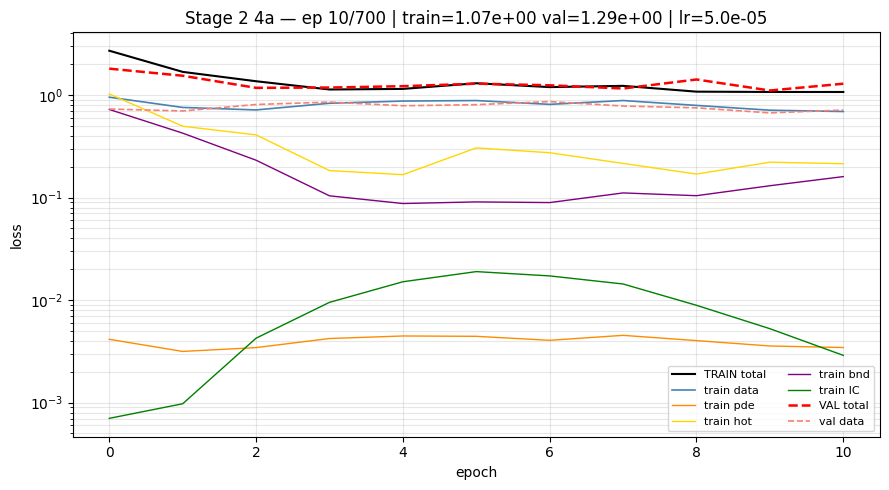

ep    0 | train=2.71e+00 val=1.81e+00 val_data=7.31e-01 | data=9.53e-01 pde=4.15e-03 | t=6.5s
ep   10 | train=1.07e+00 val=1.29e+00 val_data=7.14e-01 | data=6.91e-01 pde=3.45e-03 | t=6.0s


KeyboardInterrupt: 

In [ ]:
# =========================================================
# Stage 2 (Model 4a) — TRAIN on run 0, VALIDATION loss on run 1
#   data@anchors + transient PDE@in-between + IC + hot/boundary
#   validation = same losses on held-out run, no backprop. Plot both.
# =========================================================
import gc; gc.collect(); torch.cuda.empty_cache()
from scipy.ndimage import label, generate_binary_structure

STAGE1_WEIGHTS = "model_stage2_1_set.pt"

STEP_INTERVAL  = 14
LR_STAGE2      = 5e-5
EPOCHS_S2      = 700
CHUNK          = 8
PDE_EVERY      = 3
W_DATA=1.0; W_PDE=0.1; W_IC=1.0; W_HOT=1.3; W_BOUNDARY=0.7
HOT_MARGIN=150.0; BND_BAND=100.0; WINDOW=500
TRAIN_RI=0; VAL_RI=1

model.load_state_dict(torch.load(STAGE1_WEIGHTS, map_location=device))
opt=torch.optim.Adam(model.parameters(),lr=LR_STAGE2)
scheduler_s2=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=0.5,patience=100,min_lr=1e-7)

X_mean_t=torch.tensor(X_mean,dtype=torch.float32,device=device)
X_std_t =torch.tensor(X_std, dtype=torch.float32,device=device)
Y_mean_t=torch.tensor(Y_mean,dtype=torch.float32,device=device)
Y_std_t =torch.tensor(Y_std, dtype=torch.float32,device=device)
xm8=float(X_mean_t[0,8]); xs8=float(X_std_t[0,8]); Xm8_t=X_mean_t[:,:8]; Xs8_t=X_std_t[:,:8]
P_ref=float(np.mean(X_data[X_data[:,3]>0,3]))
q_scale=(params["absorb"]*P_ref)/(2.0*np.pi*params["sigma"]**2*params["depth"])
def model_fn_raw(X_phys): return model((X_phys-X_mean_t)/X_std_t)*Y_std_t+Y_mean_t

def pde_residual_backward_euler(model_fn,X,p,q_scale,prev_dT,dt,was_melted_batch=None):
    X=X.requires_grad_(True); dT=model_fn(X); T=torch.clamp(dT+p["Tamb"],p["Tamb"],5000.0)
    g1=torch.autograd.grad(dT,X,grad_outputs=torch.ones_like(dT),create_graph=True)[0]
    Tx=g1[:,1:2]*1000.0; Ty=g1[:,2:3]*1000.0
    dx_m=X[:,1:2]/1000.0; dy_m=X[:,2:3]/1000.0; P=X[:,3:4]; r2_m=dx_m**2+dy_m**2
    is_liquid=(T>p["Tl"]).float(); is_mushy=((T>=p["Ts"])&(T<=p["Tl"])).float(); is_cold=(T<p["Ts"]).float()
    wm=torch.ones_like(T) if was_melted_batch is None else was_melted_batch.to(X.device)
    rho=is_cold*(wm*p["rho_solid"]+(1-wm)*p["rho_powder"])+(is_mushy+is_liquid)*p["rho_liquid"]
    k_material=is_cold*(wm*p["k_solid"]+(1-wm)*p["k_powder"])+(is_mushy+is_liquid)*p["k_liquid"]
    cp=cp_apparent(T,p["Ts"],p["Tl"],p["Lfus"],p["cp_base"])
    Q=p["absorb"]*P/(2.0*np.pi*p["sigma"]**2*p["depth"])*torch.exp(-r2_m/(2.0*p["sigma"]**2))
    kTx=k_material*Tx; kTy=k_material*Ty
    d_kTx=1000.0*torch.autograd.grad(kTx,X,grad_outputs=torch.ones_like(kTx),create_graph=True)[0][:,1:2]
    d_kTy=1000.0*torch.autograd.grad(kTy,X,grad_outputs=torch.ones_like(kTy),create_graph=True)[0][:,2:3]
    conduction=d_kTx+d_kTy; q_sink=p["beta"]*dT
    q_rad=p["e"]*p["sigma_sb"]*torch.clamp(T**4-p["Tamb"]**4,min=0.0)
    Tt_lab=(dT-prev_dT.reshape(-1,1))/max(dt,1e-12)
    return (rho*cp*Tt_lab-conduction-Q+q_sink+q_rad)/q_scale

# caches / anchors
run_tr=all_runs[TRAIN_RI]; cache_tr=get_rollout_cache(TRAIN_RI,run_tr); Nt_tr=run_tr['T'].shape[1]
anchor_set_tr=set(k for k in range(STEP_INTERVAL,Nt_tr,STEP_INTERVAL) if cache_tr[k] is not None)
tPath_tr=run_tr['tPath']
HAS_VAL = len(all_runs)>VAL_RI
if HAS_VAL:
    run_va=all_runs[VAL_RI]; cache_va=get_rollout_cache(VAL_RI,run_va); Nt_va=run_va['T'].shape[1]
    anchor_set_va=set(k for k in range(STEP_INTERVAL,Nt_va,STEP_INTERVAL) if cache_va[k] is not None)
    print(f"TRAIN {len(anchor_set_tr)} anchors | VAL {len(anchor_set_va)} anchors")
else:
    print(f"TRAIN {len(anchor_set_tr)} anchors | NO val run")
X_ic_t=X_ic_tensor; Y_ic_t=Y_ic_tensor

# blob (train mesh) for hot/boundary
_xs=np.unique(np.round(run_tr['xNodes'],9)); _ys=np.unique(np.round(run_tr['yNodes'],9))
_grid_ok=(len(_xs)*len(_ys)==len(run_tr['xNodes']))
if _grid_ok:
    _ci=np.searchsorted(_xs,np.round(run_tr['xNodes'],9)); _ri=np.searchsorted(_ys,np.round(run_tr['yNodes'],9)); _st=generate_binary_structure(2,1)
def blob_mask(Tk_full,thr,run):
    hot=Tk_full>=thr
    if (not _grid_ok) or hot.sum()<3: return hot
    g=np.zeros((len(_ys),len(_xs)),bool); g[_ri,_ci]=hot
    lbl,n=label(g,structure=_st)
    if n==0: return np.zeros_like(hot)
    ln=np.argmin(run['xNodes']**2+run['yNodes']**2); L=lbl[_ri[ln],_ci[ln]]
    if L==0:
        s=np.bincount(lbl.ravel()); s[0]=0; L=s.argmax()
    return (lbl==L)[_ri,_ci]
def anchor_region_sel(run,k,idx_t):
    Tk_full=run['T'][:,k]; idx_np=idx_t.cpu().numpy(); Tk_p=Tk_full[idx_np]
    if DATA_MODE=="experimental":
        pool=blob_mask(Tk_full,Tl,run); in_pool=pool[idx_np]
        return in_pool&(Tk_p>Tl+HOT_MARGIN), in_pool&(np.abs(Tk_p-Tl)<BND_BAND)
    return Tk_p>Tl+HOT_MARGIN, np.abs(Tk_p-Tl)<BND_BAND

def run_pass(run, cache, anchor_set, tPath_r, chunk, backprop):
    T_r=run['T']; Nt_=T_r.shape[1]
    data_tot=0.0; pde_tot=0.0; hot_tot=0.0; bnd_tot=0.0; nd=0; npde=0; chunk_losses=[]
    def flush(c):
        if c and backprop: torch.stack(c).sum().backward()
    k0=max(np.random.randint(2,max(3,Nt_-WINDOW)),2)
    T_state=torch.clamp(torch.tensor(T_r[:,k0],dtype=torch.float32,device=device)-Tamb,min=0.0).detach()
    ctx=torch.enable_grad() if backprop else torch.no_grad()
    with ctx:
        for k in range(k0+1,min(k0+WINDOW,Nt_)):
            fr=cache[k]
            if fr is None: continue
            idx_t,static_n,tgt_n=fr
            if k in anchor_set:
                Tprev_n=((T_state[idx_t]-xm8)/xs8).unsqueeze(1)
                pred_n=model(torch.cat([static_n,Tprev_n],dim=1))
                dl=W_DATA*mse_loss(pred_n,tgt_n)
                if backprop: chunk_losses.append(dl)
                data_tot+=float(dl.detach()); nd+=1
                hsel,bsel=anchor_region_sel(run,k,idx_t)
                if hsel.sum()>0:
                    hs=torch.tensor(hsel,device=device); hl=W_HOT*mse_loss(pred_n[hs],tgt_n[hs])
                    if backprop: chunk_losses.append(hl)
                    hot_tot+=float(hl.detach())
                if bsel.sum()>0:
                    bs=torch.tensor(bsel,device=device); bl=W_BOUNDARY*mse_loss(pred_n[bs],tgt_n[bs])
                    if backprop: chunk_losses.append(bl)
                    bnd_tot+=float(bl.detach())
                T_state=torch.clamp(torch.tensor(T_r[:,k],dtype=torch.float32,device=device)-Tamb,min=0.0).detach()
            else:
                if backprop and (k%PDE_EVERY)==0:
                    static_raw=static_n*Xs8_t+Xm8_t; prev_state=T_state[idx_t].detach()
                    Xk_raw=torch.cat([static_raw,prev_state.unsqueeze(1)],dim=1); dt_k=float(tPath_r[k]-tPath_r[k-1])
                    res=pde_residual_backward_euler(model_fn_raw,Xk_raw,params,q_scale,prev_dT=prev_state,dt=dt_k)
                    pl=W_PDE*torch.mean(res**2)
                    if not torch.isfinite(pl): pl=torch.zeros((),device=device)
                    chunk_losses.append(pl); pde_tot+=float(pl.detach()); npde+=1
                    with torch.no_grad(): pred_dT=torch.clamp(model_fn_raw(Xk_raw),0.0).squeeze(1)
                else:
                    with torch.no_grad():
                        static_raw=static_n*Xs8_t+Xm8_t
                        pred_dT=torch.clamp(model_fn_raw(torch.cat([static_raw,T_state[idx_t].unsqueeze(1)],dim=1)),0.0).squeeze(1)
                T_state=T_state.clone(); T_state[idx_t]=pred_dT.detach()
            if backprop and len(chunk_losses)>=chunk:
                flush(chunk_losses); chunk_losses=[]
        flush(chunk_losses)
    return data_tot/max(nd,1), pde_tot/max(npde,1), hot_tot/max(nd,1), bnd_tot/max(nd,1)

loss_hist=[]; data_hist=[]; pde_hist=[]; hot_hist=[]; bnd_hist=[]; IC_hist=[]
val_data_hist=[]; val_total_hist=[]; log=[]
print("Training Stage 2 (4a, train/val) ...")
for epoch in range(EPOCHS_S2):
    t0=time.time(); opt.zero_grad()
    data_val,pde_val,hot_val,bnd_val = run_pass(run_tr,cache_tr,anchor_set_tr,tPath_tr,CHUNK,backprop=True)
    loss_ic=W_IC*mse_loss(model(X_ic_t),Y_ic_t); loss_ic.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step(); scheduler_s2.step(data_val)

    if HAS_VAL:
        model.eval()
        with torch.no_grad():
            v_data,_,v_hot,v_bnd = run_pass(run_va,cache_va,anchor_set_va,run_va['tPath'],CHUNK,backprop=False)
        v_total = W_DATA*v_data + W_HOT*v_hot + W_BOUNDARY*v_bnd
        model.train()
    else:
        v_data=np.nan; v_total=np.nan

    if epoch%5==0: torch.cuda.empty_cache()
    t1=time.time()
    data_hist.append(data_val); pde_hist.append(pde_val); hot_hist.append(hot_val); bnd_hist.append(bnd_val); IC_hist.append(loss_ic.item())
    loss_hist.append(data_val+pde_val+hot_val+bnd_val+loss_ic.item())
    val_data_hist.append(v_data); val_total_hist.append(v_total)

    if epoch%10==0:
        clear_output(wait=True)
        fig,ax=plt.subplots(figsize=(9,5))
        ax.plot(loss_hist,label="TRAIN total",color='black',lw=1.5)
        ax.plot(data_hist,label="train data",color='steelblue',lw=1.2)
        ax.plot(pde_hist,label="train pde",color='darkorange',lw=1.0)
        ax.plot(hot_hist,label="train hot",color='gold',lw=1.0)
        ax.plot(bnd_hist,label="train bnd",color='purple',lw=1.0)
        ax.plot(IC_hist,label="train IC",color='green',lw=1.0)
        if HAS_VAL:
            ax.plot(val_total_hist,label="VAL total",color='red',lw=1.8,ls='--')
            ax.plot(val_data_hist,label="val data",color='salmon',lw=1.2,ls='--')
        ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
        ax.set_title(f"Stage 2 4a — ep {epoch}/{EPOCHS_S2} | train={loss_hist[-1]:.2e}"
                     + (f" val={v_total:.2e}" if HAS_VAL else "") + f" | lr={opt.param_groups[0]['lr']:.1e}")
        ax.legend(fontsize=8,ncol=2); ax.grid(True,which="both",alpha=0.3)
        plt.tight_layout(); plt.show()
        log.append(f"ep {epoch:4d} | train={loss_hist[-1]:.2e}"
                   + (f" val={v_total:.2e} val_data={v_data:.2e}" if HAS_VAL else "")
                   + f" | data={data_val:.2e} pde={pde_val:.2e} | t={t1-t0:.1f}s")
        print("\n".join(log))

fig.savefig("stage2_4a_trainval.png",dpi=300,bbox_inches="tight")
torch.save(model.state_dict(),"model_4a_stage2.pt")
print("saved model_4a_stage2.pt")

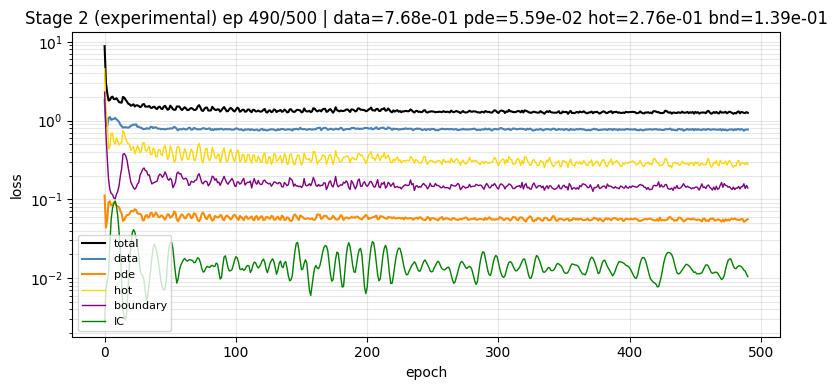

ep    0 | data=1.83e+00 pde=1.11e-01 hot=4.56e+00 bnd=2.29e+00 ic=2.69e-03 | t=12.5s
ep   10 | data=1.00e+00 pde=8.14e-02 hot=5.45e-01 bnd=1.27e-01 ic=6.07e-02 | t=5.5s
ep   20 | data=8.58e-01 pde=7.09e-02 hot=4.18e-01 bnd=1.65e-01 ic=2.57e-02 | t=5.6s
ep   30 | data=7.80e-01 pde=5.40e-02 hot=5.25e-01 bnd=2.50e-01 ic=9.42e-03 | t=5.7s
ep   40 | data=7.98e-01 pde=6.40e-02 hot=3.47e-01 bnd=1.70e-01 ic=2.01e-02 | t=5.6s
ep   50 | data=7.95e-01 pde=5.82e-02 hot=4.79e-01 bnd=1.85e-01 ic=2.82e-02 | t=5.5s
ep   60 | data=7.90e-01 pde=6.13e-02 hot=3.70e-01 bnd=1.80e-01 ic=1.70e-02 | t=5.6s
ep   70 | data=7.77e-01 pde=6.03e-02 hot=3.69e-01 bnd=1.76e-01 ic=1.69e-02 | t=5.6s
ep   80 | data=7.96e-01 pde=6.38e-02 hot=3.09e-01 bnd=1.57e-01 ic=1.36e-02 | t=5.6s
ep   90 | data=7.70e-01 pde=5.58e-02 hot=4.04e-01 bnd=1.79e-01 ic=1.43e-02 | t=5.6s
ep  100 | data=7.94e-01 pde=6.08e-02 hot=3.50e-01 bnd=1.45e-01 ic=1.87e-02 | t=5.6s
ep  110 | data=7.75e-01 pde=5.66e-02 hot=3.70e-01 bnd=1.64e-01 ic=1.42e-02 

In [16]:
# =========================================================
# Cell — Stage 2 (Model 4a): data@anchors + transient PDE@in-between + IC
#        + HOT/BOUNDARY losses at anchors:
#          experimental -> blob (connected pool, noise-filtered)
#          sim          -> temperature threshold (old way)
# =========================================================
import gc; gc.collect(); torch.cuda.empty_cache()
from scipy.ndimage import label, generate_binary_structure

STAGE1_WEIGHTS = "model_stage2_1_set.pt"
# STAGE1_WEIGHTS = "model5_stage1_mstep.pt"
STEP_INTERVAL  = 14
LR_STAGE2      = 1e-4
EPOCHS_S2      = 500
CHUNK          = 8
PDE_EVERY      = 3
W_DATA         = 1.0
W_PDE          = 1
W_IC           = 1.0
W_HOT          =1.3
W_BOUNDARY     = 0.7
HOT_MARGIN     = 150.0     # hot = pool nodes with T > Tl + margin
BND_BAND       = 100.0     # boundary = pool nodes within band of Tl
WINDOW         = 500

model.load_state_dict(torch.load(STAGE1_WEIGHTS, map_location=device))
opt = torch.optim.Adam(model.parameters(), lr=LR_STAGE2)
scheduler_s2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode='min', factor=0.5, patience=100, min_lr=1e-7)

X_mean_t = torch.tensor(X_mean, dtype=torch.float32, device=device)
X_std_t  = torch.tensor(X_std,  dtype=torch.float32, device=device)
Y_mean_t = torch.tensor(Y_mean, dtype=torch.float32, device=device)
Y_std_t  = torch.tensor(Y_std,  dtype=torch.float32, device=device)
xm8=float(X_mean_t[0,8]); xs8=float(X_std_t[0,8])
Xm8_t = X_mean_t[:, :8]; Xs8_t = X_std_t[:, :8]

P_ref   = float(np.mean(X_data[X_data[:,3] > 0, 3]))
q_scale = (params["absorb"]*P_ref)/(2.0*np.pi*params["sigma"]**2*params["depth"])

def model_fn_raw(X_phys):
    return model((X_phys - X_mean_t)/X_std_t) * Y_std_t + Y_mean_t

# --- backward-Euler transient PDE residual (free-run safe) ---
def pde_residual_backward_euler(model_fn, X, p, q_scale, prev_dT, dt, was_melted_batch=None):
    X = X.requires_grad_(True)
    dT = model_fn(X)
    T  = torch.clamp(dT + p["Tamb"], p["Tamb"], 5000.0)
    g1 = torch.autograd.grad(dT, X, grad_outputs=torch.ones_like(dT), create_graph=True)[0]
    Tx = g1[:,1:2]*1000.0; Ty = g1[:,2:3]*1000.0
    dx_m=X[:,1:2]/1000.0; dy_m=X[:,2:3]/1000.0; P=X[:,3:4]
    r2_m = dx_m**2 + dy_m**2
    is_liquid=(T>p["Tl"]).float(); is_mushy=((T>=p["Ts"])&(T<=p["Tl"])).float(); is_cold=(T<p["Ts"]).float()
    was_melted = torch.ones_like(T) if was_melted_batch is None else was_melted_batch.to(X.device)
    rho = is_cold*(was_melted*p["rho_solid"]+(1-was_melted)*p["rho_powder"]) + (is_mushy+is_liquid)*p["rho_liquid"]
    k_material = is_cold*(was_melted*p["k_solid"]+(1-was_melted)*p["k_powder"]) + (is_mushy+is_liquid)*p["k_liquid"]
    cp = cp_apparent(T, p["Ts"], p["Tl"], p["Lfus"], p["cp_base"])
    Q = p["absorb"]*P/(2.0*np.pi*p["sigma"]**2*p["depth"]) * torch.exp(-r2_m/(2.0*p["sigma"]**2))
    kTx=k_material*Tx; kTy=k_material*Ty
    d_kTx_dx = 1000.0*torch.autograd.grad(kTx,X,grad_outputs=torch.ones_like(kTx),create_graph=True)[0][:,1:2]
    d_kTy_dy = 1000.0*torch.autograd.grad(kTy,X,grad_outputs=torch.ones_like(kTy),create_graph=True)[0][:,2:3]
    conduction = d_kTx_dx + d_kTy_dy
    q_sink = p["beta"]*dT
    q_rad  = p["e"]*p["sigma_sb"]*torch.clamp(T**4 - p["Tamb"]**4, min=0.0)
    Tt_lab = (dT - prev_dT.reshape(-1,1)) / max(dt, 1e-12)
    res = rho*cp*Tt_lab - conduction - Q + q_sink + q_rad
    return res / q_scale

ri = 0; run_r = all_runs[ri]
cache = get_rollout_cache(ri, run_r)
Nt = run_r['T'].shape[1]
anchor_ks = [k for k in range(STEP_INTERVAL, Nt, STEP_INTERVAL) if cache[k] is not None]
anchor_set = set(anchor_ks)
print(f"{len(anchor_ks)} anchor frames (every {STEP_INTERVAL})")
X_ic_t = X_ic_tensor; Y_ic_t = Y_ic_tensor
tPath_r = run_r['tPath']

# --- blob setup (experimental: connected pool, structured grid) ---
_xs=np.unique(np.round(run_r['xNodes'],9)); _ys=np.unique(np.round(run_r['yNodes'],9))
_grid_ok=(len(_xs)*len(_ys)==len(run_r['xNodes']))
if _grid_ok:
    _ci=np.searchsorted(_xs,np.round(run_r['xNodes'],9))
    _ri=np.searchsorted(_ys,np.round(run_r['yNodes'],9))
    _st=generate_binary_structure(2,1)
print(f"blob grid available: {_grid_ok}")

def blob_mask(Tk_full, thr):
    hot = Tk_full >= thr
    if (not _grid_ok) or hot.sum()<3: return hot
    g=np.zeros((len(_ys),len(_xs)),bool); g[_ri,_ci]=hot
    lbl,n=label(g,structure=_st)
    if n==0: return np.zeros_like(hot)
    ln=np.argmin(run_r['xNodes']**2+run_r['yNodes']**2)
    L=lbl[_ri[ln],_ci[ln]]
    if L==0:
        s=np.bincount(lbl.ravel()); s[0]=0; L=s.argmax()
    return (lbl==L)[_ri,_ci]

def anchor_region_sel(k, idx_t):
    """return (hot_sel, bnd_sel) boolean arrays over the patch nodes idx_t."""
    Tk_full = run_r['T'][:, k]
    idx_np  = idx_t.cpu().numpy()
    Tk_p    = Tk_full[idx_np]
    if DATA_MODE == "experimental":
        pool = blob_mask(Tk_full, Tl)             # connected pool (noise-filtered)
        in_pool = pool[idx_np]
        hot_sel = in_pool & (Tk_p > Tl + HOT_MARGIN)
        bnd_sel = in_pool & (np.abs(Tk_p - Tl) < BND_BAND)
    else:
        # sim: plain temperature threshold (old way)
        hot_sel = Tk_p > Tl + HOT_MARGIN
        bnd_sel = np.abs(Tk_p - Tl) < BND_BAND
    return hot_sel, bnd_sel


def stage2_4a_backward(run, cache, chunk=4):
    T_r = run['T']; Nt_ = T_r.shape[1]
    chunk_losses=[]; data_tot=torch.zeros((),device=device); pde_tot=torch.zeros((),device=device)
    hot_tot=torch.zeros((),device=device); bnd_tot=torch.zeros((),device=device)
    nd=0; npde=0
    def flush(c):
        if c: torch.stack(c).sum().backward()

    k0 = np.random.randint(2, max(3, Nt_ - WINDOW))
    k0 = max(k0, 2)
    T_state = torch.clamp(torch.tensor(T_r[:,k0],dtype=torch.float32,device=device)-Tamb, min=0.0).detach()

    for k in range(k0+1, min(k0+WINDOW, Nt_)):
        fr = cache[k]
        if fr is None: continue
        idx_t, static_n, tgt_n = fr

        if k in anchor_set:
            # DATA loss at anchor
            Tprev_n = ((T_state[idx_t]-xm8)/xs8).unsqueeze(1)
            pred_n  = model(torch.cat([static_n, Tprev_n], dim=1))
            dloss = W_DATA * mse_loss(pred_n, tgt_n)
            chunk_losses.append(dloss); data_tot += dloss.detach(); nd += 1

            # HOT + BOUNDARY (blob for exp / threshold for sim)
            hot_sel, bnd_sel = anchor_region_sel(k, idx_t)
            if hot_sel.sum() > 0:
                hs = torch.tensor(hot_sel, device=device)
                hloss = W_HOT * mse_loss(pred_n[hs], tgt_n[hs])
                chunk_losses.append(hloss); hot_tot += hloss.detach()
            if bnd_sel.sum() > 0:
                bs = torch.tensor(bnd_sel, device=device)
                bloss = W_BOUNDARY * mse_loss(pred_n[bs], tgt_n[bs])
                chunk_losses.append(bloss); bnd_tot += bloss.detach()

            # re-anchor state to TRUE field
            T_state = torch.clamp(
                torch.tensor(T_r[:,k], dtype=torch.float32, device=device) - Tamb, min=0.0).detach()
        else:
            if (k % PDE_EVERY) == 0:
                static_raw = static_n * Xs8_t + Xm8_t
                prev_state = T_state[idx_t].detach()
                Xk_raw = torch.cat([static_raw, prev_state.unsqueeze(1)], dim=1)
                dt_k = float(tPath_r[k] - tPath_r[k-1])
                res = pde_residual_backward_euler(model_fn_raw, Xk_raw, params, q_scale,
                                                  prev_dT=prev_state, dt=dt_k, was_melted_batch=None)
                ploss = W_PDE * torch.mean(res**2)
                if not torch.isfinite(ploss): ploss = torch.zeros((), device=device)
                chunk_losses.append(ploss); pde_tot += ploss.detach(); npde += 1
                with torch.no_grad():
                    pred_dT = torch.clamp(model_fn_raw(Xk_raw), 0.0).squeeze(1)
            else:
                with torch.no_grad():
                    static_raw = static_n * Xs8_t + Xm8_t
                    Tprev_raw  = T_state[idx_t].unsqueeze(1)
                    pred_dT = torch.clamp(model_fn_raw(torch.cat([static_raw, Tprev_raw], dim=1)), 0.0).squeeze(1)
            T_state = T_state.clone(); T_state[idx_t] = pred_dT.detach()

        if len(chunk_losses) >= chunk:
            flush(chunk_losses); chunk_losses=[]
    flush(chunk_losses)
    return (float(data_tot)/max(nd,1), float(pde_tot)/max(npde,1),
            float(hot_tot)/max(nd,1), float(bnd_tot)/max(nd,1))


loss_hist=[]; data_hist=[]; pde_hist=[]; hot_hist=[]; bnd_hist=[]; IC_hist=[]; log=[]
print(f"Training Stage 2 (4a + hot/boundary, {DATA_MODE}) ...")
for epoch in range(EPOCHS_S2):
    t0=time.time()
    opt.zero_grad()
    data_val, pde_val, hot_val, bnd_val = stage2_4a_backward(run_r, cache, chunk=CHUNK)
    loss_ic = W_IC * mse_loss(model(X_ic_t), Y_ic_t)
    loss_ic.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    scheduler_s2.step(data_val)
    if epoch % 5 == 0: torch.cuda.empty_cache()

    t1=time.time()
    data_hist.append(data_val); pde_hist.append(pde_val); hot_hist.append(hot_val)
    bnd_hist.append(bnd_val); IC_hist.append(loss_ic.item())
    loss_hist.append(data_val + pde_val + hot_val + bnd_val + loss_ic.item())
    if epoch % 10 == 0:
        clear_output(wait=True)
        fig,ax=plt.subplots(figsize=(8,4))
        ax.plot(loss_hist,label="total",color='black',lw=1.5)
        ax.plot(data_hist,label="data",color='steelblue',lw=1.5)
        ax.plot(pde_hist,label="pde",color='darkorange',lw=1.5)
        ax.plot(hot_hist,label="hot",color='gold',lw=1.0)
        ax.plot(bnd_hist,label="boundary",color='purple',lw=1.0)
        ax.plot(IC_hist,label="IC",color='green',lw=1.0)
        ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
        ax.set_title(f"Stage 2 ({DATA_MODE}) ep {epoch}/{EPOCHS_S2} | "
                     f"data={data_val:.2e} pde={pde_val:.2e} hot={hot_val:.2e} bnd={bnd_val:.2e}")
        ax.legend(fontsize=8); ax.grid(True,which="both",alpha=0.3)
        plt.tight_layout(); plt.show()
        log.append(f"ep {epoch:4d} | data={data_val:.2e} pde={pde_val:.2e} "
                   f"hot={hot_val:.2e} bnd={bnd_val:.2e} ic={loss_ic.item():.2e} | t={t1-t0:.1f}s")
        print("\n".join(log))
fig.savefig(f"4a.png",dpi=300,bbox_inches="tight")
torch.save(model.state_dict(), "model_4a_stage2.pt")
print("Stage 2 (4a + hot/boundary) weights saved")

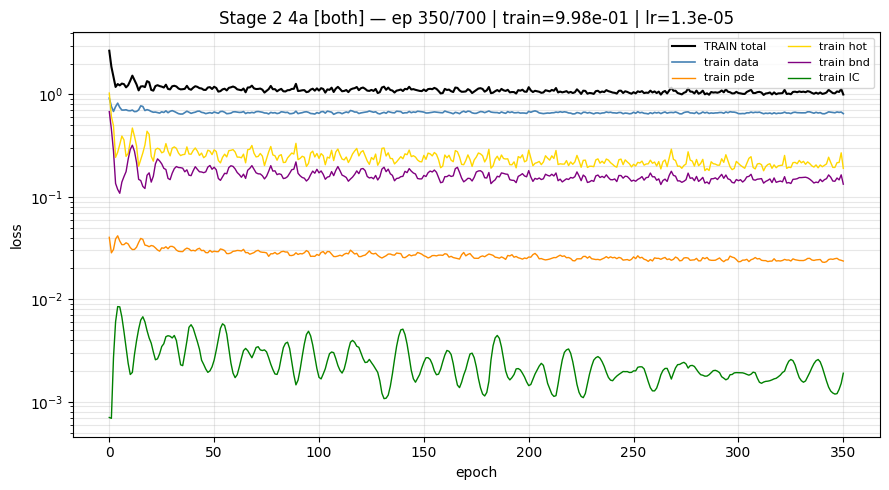

ep    0 | train=2.67e+00 | data=9.20e-01 pde=4.03e-02 | t=14.0s
ep   10 | train=1.36e+00 | data=6.93e-01 pde=3.20e-02 | t=10.8s
ep   20 | train=1.11e+00 | data=6.82e-01 pde=3.35e-02 | t=10.8s
ep   30 | train=1.20e+00 | data=6.95e-01 pde=3.29e-02 | t=10.9s
ep   40 | train=1.16e+00 | data=6.64e-01 pde=3.01e-02 | t=10.9s
ep   50 | train=1.19e+00 | data=6.74e-01 pde=2.95e-02 | t=10.9s
ep   60 | train=1.17e+00 | data=6.77e-01 pde=2.96e-02 | t=10.8s
ep   70 | train=1.13e+00 | data=6.79e-01 pde=2.96e-02 | t=10.9s
ep   80 | train=1.07e+00 | data=6.50e-01 pde=2.76e-02 | t=10.9s
ep   90 | train=1.08e+00 | data=6.50e-01 pde=2.74e-02 | t=10.9s
ep  100 | train=1.09e+00 | data=6.54e-01 pde=2.68e-02 | t=10.9s
ep  110 | train=1.13e+00 | data=6.63e-01 pde=2.69e-02 | t=10.9s
ep  120 | train=1.15e+00 | data=6.60e-01 pde=2.61e-02 | t=10.9s
ep  130 | train=1.17e+00 | data=6.58e-01 pde=2.53e-02 | t=10.9s
ep  140 | train=1.08e+00 | data=6.55e-01 pde=2.57e-02 | t=10.9s
ep  150 | train=1.12e+00 | data=6.72e-01

KeyboardInterrupt: 

In [ ]:
# =========================================================
# Stage 2 (Model 4a) — flexible TRAIN_MODE:
#   "single"     : train on run 0 only (no validation)
#   "train_val"  : train on run 0, validation loss on run 1 (no backprop)
#   "both"       : train on run 0 AND run 1 (no validation)
# =========================================================
import gc; gc.collect(); torch.cuda.empty_cache()
from scipy.ndimage import label, generate_binary_structure

TRAIN_MODE = "both"          # "single" | "train_val" | "both"

STAGE1_WEIGHTS = "model_stage2_1_set.pt"
STEP_INTERVAL  = 14
LR_STAGE2      = 5e-5
EPOCHS_S2      = 700
CHUNK          = 8
PDE_EVERY      = 3
W_DATA=1.0; W_PDE=1; W_IC=1.0; W_HOT=1.3; W_BOUNDARY=0.7
HOT_MARGIN=150.0; BND_BAND=100.0; WINDOW=500

model.load_state_dict(torch.load(STAGE1_WEIGHTS, map_location=device))
opt=torch.optim.Adam(model.parameters(),lr=LR_STAGE2)
scheduler_s2=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=0.5,patience=100,min_lr=1e-7)

X_mean_t=torch.tensor(X_mean,dtype=torch.float32,device=device)
X_std_t =torch.tensor(X_std, dtype=torch.float32,device=device)
Y_mean_t=torch.tensor(Y_mean,dtype=torch.float32,device=device)
Y_std_t =torch.tensor(Y_std, dtype=torch.float32,device=device)
xm8=float(X_mean_t[0,8]); xs8=float(X_std_t[0,8]); Xm8_t=X_mean_t[:,:8]; Xs8_t=X_std_t[:,:8]
P_ref=float(np.mean(X_data[X_data[:,3]>0,3]))
q_scale=(params["absorb"]*P_ref)/(2.0*np.pi*params["sigma"]**2*params["depth"])
def model_fn_raw(X_phys): return model((X_phys-X_mean_t)/X_std_t)*Y_std_t+Y_mean_t

def pde_residual_backward_euler(model_fn,X,p,q_scale,prev_dT,dt,was_melted_batch=None):
    X=X.requires_grad_(True); dT=model_fn(X); T=torch.clamp(dT+p["Tamb"],p["Tamb"],5000.0)
    g1=torch.autograd.grad(dT,X,grad_outputs=torch.ones_like(dT),create_graph=True)[0]
    Tx=g1[:,1:2]*1000.0; Ty=g1[:,2:3]*1000.0
    dx_m=X[:,1:2]/1000.0; dy_m=X[:,2:3]/1000.0; P=X[:,3:4]; r2_m=dx_m**2+dy_m**2
    is_liquid=(T>p["Tl"]).float(); is_mushy=((T>=p["Ts"])&(T<=p["Tl"])).float(); is_cold=(T<p["Ts"]).float()
    wm=torch.ones_like(T) if was_melted_batch is None else was_melted_batch.to(X.device)
    rho=is_cold*(wm*p["rho_solid"]+(1-wm)*p["rho_powder"])+(is_mushy+is_liquid)*p["rho_liquid"]
    k_material=is_cold*(wm*p["k_solid"]+(1-wm)*p["k_powder"])+(is_mushy+is_liquid)*p["k_liquid"]
    cp=cp_apparent(T,p["Ts"],p["Tl"],p["Lfus"],p["cp_base"])
    Q=p["absorb"]*P/(2.0*np.pi*p["sigma"]**2*p["depth"])*torch.exp(-r2_m/(2.0*p["sigma"]**2))
    kTx=k_material*Tx; kTy=k_material*Ty
    d_kTx=1000.0*torch.autograd.grad(kTx,X,grad_outputs=torch.ones_like(kTx),create_graph=True)[0][:,1:2]
    d_kTy=1000.0*torch.autograd.grad(kTy,X,grad_outputs=torch.ones_like(kTy),create_graph=True)[0][:,2:3]
    conduction=d_kTx+d_kTy; q_sink=p["beta"]*dT
    q_rad=p["e"]*p["sigma_sb"]*torch.clamp(T**4-p["Tamb"]**4,min=0.0)
    Tt_lab=(dT-prev_dT.reshape(-1,1))/max(dt,1e-12)
    return (rho*cp*Tt_lab-conduction-Q+q_sink+q_rad)/q_scale

# --- decide which runs are train vs val based on mode ---
if TRAIN_MODE=="single":
    TRAIN_RIS=[0]; VAL_RI=None
elif TRAIN_MODE=="train_val":
    TRAIN_RIS=[0]; VAL_RI=1
elif TRAIN_MODE=="both":
    TRAIN_RIS=list(range(len(all_runs))); VAL_RI=None
else:
    raise ValueError("TRAIN_MODE must be single|train_val|both")
print(f"TRAIN_MODE={TRAIN_MODE}  train runs={TRAIN_RIS}  val run={VAL_RI}")

# --- precompute per-run: cache, anchors, and blob grid (meshes may differ) ---
def run_setup(ri):
    run=all_runs[ri]; cache=get_rollout_cache(ri,run); Nt=run['T'].shape[1]
    anchors=set(k for k in range(STEP_INTERVAL,Nt,STEP_INTERVAL) if cache[k] is not None)
    xs=np.unique(np.round(run['xNodes'],9)); ys=np.unique(np.round(run['yNodes'],9))
    grid_ok=(len(xs)*len(ys)==len(run['xNodes']))
    if grid_ok:
        ci=np.searchsorted(xs,np.round(run['xNodes'],9)); ri_=np.searchsorted(ys,np.round(run['yNodes'],9))
        st=generate_binary_structure(2,1)
        blob=(xs,ys,ci,ri_,st,grid_ok)
    else:
        blob=(None,None,None,None,None,False)
    return {'run':run,'cache':cache,'anchors':anchors,'blob':blob,'tPath':run['tPath']}

setups = {ri: run_setup(ri) for ri in set(TRAIN_RIS + ([VAL_RI] if VAL_RI is not None else []))}
for ri,s in setups.items():
    print(f"  run {ri}: {len(s['anchors'])} anchors, blob_grid={s['blob'][5]}")
X_ic_t=X_ic_tensor; Y_ic_t=Y_ic_tensor

def blob_mask(Tk_full, thr, blob, run):
    xs,ys,ci,ri_,st,ok=blob
    hot=Tk_full>=thr
    if (not ok) or hot.sum()<3: return hot
    g=np.zeros((len(ys),len(xs)),bool); g[ri_,ci]=hot
    lbl,n=label(g,structure=st)
    if n==0: return np.zeros_like(hot)
    ln=np.argmin(run['xNodes']**2+run['yNodes']**2); L=lbl[ri_[ln],ci[ln]]
    if L==0:
        s=np.bincount(lbl.ravel()); s[0]=0; L=s.argmax()
    return (lbl==L)[ri_,ci]
def anchor_region_sel(setup,k,idx_t):
    run=setup['run']; Tk_full=run['T'][:,k]; idx_np=idx_t.cpu().numpy(); Tk_p=Tk_full[idx_np]
    if DATA_MODE=="experimental":
        pool=blob_mask(Tk_full,Tl,setup['blob'],run); in_pool=pool[idx_np]
        return in_pool&(Tk_p>Tl+HOT_MARGIN), in_pool&(np.abs(Tk_p-Tl)<BND_BAND)
    return Tk_p>Tl+HOT_MARGIN, np.abs(Tk_p-Tl)<BND_BAND

def run_pass(setup, chunk, backprop):
    run=setup['run']; cache=setup['cache']; anchor_set=setup['anchors']; tPath_r=setup['tPath']
    T_r=run['T']; Nt_=T_r.shape[1]
    data_tot=0.0; pde_tot=0.0; hot_tot=0.0; bnd_tot=0.0; nd=0; npde=0; chunk_losses=[]
    def flush(c):
        if c and backprop: torch.stack(c).sum().backward()
    k0=max(np.random.randint(2,max(3,Nt_-WINDOW)),2)
    T_state=torch.clamp(torch.tensor(T_r[:,k0],dtype=torch.float32,device=device)-Tamb,min=0.0).detach()
    ctx=torch.enable_grad() if backprop else torch.no_grad()
    with ctx:
        for k in range(k0+1,min(k0+WINDOW,Nt_)):
            fr=cache[k]
            if fr is None: continue
            idx_t,static_n,tgt_n=fr
            if k in anchor_set:
                Tprev_n=((T_state[idx_t]-xm8)/xs8).unsqueeze(1)
                pred_n=model(torch.cat([static_n,Tprev_n],dim=1))
                dl=W_DATA*mse_loss(pred_n,tgt_n)
                if backprop: chunk_losses.append(dl)
                data_tot+=float(dl.detach()); nd+=1
                hsel,bsel=anchor_region_sel(setup,k,idx_t)
                if hsel.sum()>0:
                    hs=torch.tensor(hsel,device=device); hl=W_HOT*mse_loss(pred_n[hs],tgt_n[hs])
                    if backprop: chunk_losses.append(hl)
                    hot_tot+=float(hl.detach())
                if bsel.sum()>0:
                    bs=torch.tensor(bsel,device=device); bl=W_BOUNDARY*mse_loss(pred_n[bs],tgt_n[bs])
                    if backprop: chunk_losses.append(bl)
                    bnd_tot+=float(bl.detach())
                T_state=torch.clamp(torch.tensor(T_r[:,k],dtype=torch.float32,device=device)-Tamb,min=0.0).detach()
            else:
                if backprop and (k%PDE_EVERY)==0:
                    static_raw=static_n*Xs8_t+Xm8_t; prev_state=T_state[idx_t].detach()
                    Xk_raw=torch.cat([static_raw,prev_state.unsqueeze(1)],dim=1); dt_k=float(tPath_r[k]-tPath_r[k-1])
                    res=pde_residual_backward_euler(model_fn_raw,Xk_raw,params,q_scale,prev_dT=prev_state,dt=dt_k)
                    pl=W_PDE*torch.mean(res**2)
                    if not torch.isfinite(pl): pl=torch.zeros((),device=device)
                    chunk_losses.append(pl); pde_tot+=float(pl.detach()); npde+=1
                    with torch.no_grad(): pred_dT=torch.clamp(model_fn_raw(Xk_raw),0.0).squeeze(1)
                else:
                    with torch.no_grad():
                        static_raw=static_n*Xs8_t+Xm8_t
                        pred_dT=torch.clamp(model_fn_raw(torch.cat([static_raw,T_state[idx_t].unsqueeze(1)],dim=1)),0.0).squeeze(1)
                T_state=T_state.clone(); T_state[idx_t]=pred_dT.detach()
            if backprop and len(chunk_losses)>=chunk:
                flush(chunk_losses); chunk_losses=[]
        flush(chunk_losses)
    return data_tot/max(nd,1), pde_tot/max(npde,1), hot_tot/max(nd,1), bnd_tot/max(nd,1)

loss_hist=[]; data_hist=[]; pde_hist=[]; hot_hist=[]; bnd_hist=[]; IC_hist=[]
val_data_hist=[]; val_total_hist=[]; log=[]
print(f"Training Stage 2 (4a, mode={TRAIN_MODE}) ...")
for epoch in range(EPOCHS_S2):
    t0=time.time(); opt.zero_grad()
    # --- TRAIN on all TRAIN_RIS ---
    dsum=psum=hsum=bsum=0.0
    for ri in TRAIN_RIS:
        d,p_,h,b = run_pass(setups[ri], CHUNK, backprop=True)
        dsum+=d; psum+=p_; hsum+=h; bsum+=b
    nR=len(TRAIN_RIS); data_val=dsum/nR; pde_val=psum/nR; hot_val=hsum/nR; bnd_val=bsum/nR
    loss_ic=W_IC*mse_loss(model(X_ic_t),Y_ic_t); loss_ic.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step(); scheduler_s2.step(data_val)

    # --- VALIDATION ---
    if VAL_RI is not None:
        model.eval()
        with torch.no_grad():
            v_data,_,v_hot,v_bnd = run_pass(setups[VAL_RI], CHUNK, backprop=False)
        v_total=W_DATA*v_data+W_HOT*v_hot+W_BOUNDARY*v_bnd; model.train()
    else:
        v_data=np.nan; v_total=np.nan

    if epoch%5==0: torch.cuda.empty_cache()
    t1=time.time()
    data_hist.append(data_val); pde_hist.append(pde_val); hot_hist.append(hot_val); bnd_hist.append(bnd_val); IC_hist.append(loss_ic.item())
    loss_hist.append(data_val+pde_val+hot_val+bnd_val+loss_ic.item())
    val_data_hist.append(v_data); val_total_hist.append(v_total)

    if epoch%10==0:
        clear_output(wait=True)
        fig,ax=plt.subplots(figsize=(9,5))
        ax.plot(loss_hist,label="TRAIN total",color='black',lw=1.5)
        ax.plot(data_hist,label="train data",color='steelblue',lw=1.2)
        ax.plot(pde_hist,label="train pde",color='darkorange',lw=1.0)
        ax.plot(hot_hist,label="train hot",color='gold',lw=1.0)
        ax.plot(bnd_hist,label="train bnd",color='purple',lw=1.0)
        ax.plot(IC_hist,label="train IC",color='green',lw=1.0)
        if VAL_RI is not None:
            ax.plot(val_total_hist,label="VAL total",color='red',lw=1.8,ls='--')
            ax.plot(val_data_hist,label="val data",color='salmon',lw=1.2,ls='--')
        ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
        ax.set_title(f"Stage 2 4a [{TRAIN_MODE}] — ep {epoch}/{EPOCHS_S2} | train={loss_hist[-1]:.2e}"
                     + (f" val={v_total:.2e}" if VAL_RI is not None else "") + f" | lr={opt.param_groups[0]['lr']:.1e}")
        ax.legend(fontsize=8,ncol=2); ax.grid(True,which="both",alpha=0.3)
        plt.tight_layout(); plt.show()
        log.append(f"ep {epoch:4d} | train={loss_hist[-1]:.2e}"
                   + (f" val={v_total:.2e}" if VAL_RI is not None else "")
                   + f" | data={data_val:.2e} pde={pde_val:.2e} | t={t1-t0:.1f}s")
        print("\n".join(log))

fig.savefig(f"stage2_4a_{TRAIN_MODE}.png",dpi=300,bbox_inches="tight")
torch.save(model.state_dict(),f"model_4a_stage2_{TRAIN_MODE}.pt")
print(f"saved model_4a_stage2_{TRAIN_MODE}.pt")

In [ ]:
# =========================================================
# Cell — Inspect sampled points from last training epoch
# =========================================================
print("Last epoch sampled indices summary:")
for name, idx in last_epoch_indices.items():
    if len(idx) == 0:
        print(f"  {name:12s}: not used")
        continue
    tf  = X_data[idx, 0]
    vx  = X_data[idx, 6]
    vy  = X_data[idx, 7]
    T   = Y_data[idx].reshape(-1) + Tamb
    print(f"\n  {name:12s}: {len(idx):,} points")
    print(f"    t_feat : [{tf.min():.4f}, {tf.max():.4f}]  mean={tf.mean():.4f}")
    print(f"    T (K)  : [{T.min():.1f}, {T.max():.1f}]  mean={T.mean():.1f}")
    print(f"    vx     : [{vx.min():.3f}, {vx.max():.3f}]")
    print(f"    vy     : [{vy.min():.3f}, {vy.max():.3f}]")

    # velocity distribution
    vx_r = np.round(vx, 1);  vy_r = np.round(vy, 1)
    from collections import Counter
    vel_counts = Counter(zip(vx_r, vy_r))
    print(f"    velocity distribution:")
    for (vx_v, vy_v), count in sorted(vel_counts.items()):
        print(f"      vx={vx_v:+.1f} vy={vy_v:+.1f}: {count:,} ({count/len(idx)*100:.1f}%)")

# spatial distribution plot
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
names = [n for n in last_epoch_indices if len(last_epoch_indices[n])>0]

for ax, name in zip(axes, names):
    idx = last_epoch_indices[name]
    dx  = X_data[idx, 1]   # dx in mm
    dy  = X_data[idx, 2]   # dy in mm
    tf  = X_data[idx, 0]
    sc  = ax.scatter(dx, dy, c=tf, cmap='viridis', s=1, alpha=0.3)
    plt.colorbar(sc, ax=ax, label='t_feat')
    ax.set_xlabel('dx (mm)');  ax.set_ylabel('dy (mm)')
    ax.set_title(f'{name} ({len(idx):,} pts)')
    ax.set_aspect('equal')

# hide unused axes
for ax in axes[len(names):]:
    ax.set_visible(False)

plt.suptitle('Sampled points — last training epoch', fontsize=SUPTITLE_FS)
plt.tight_layout()
plt.show()

# t_feat histogram for all groups
fig2, ax2 = plt.subplots(figsize=(8, 4))
colors_hist = ['steelblue','crimson','darkorange','purple','green','pink']
for (name, idx), color in zip(last_epoch_indices.items(), colors_hist):
    if len(idx) == 0: continue
    ax2.hist(X_data[idx, 0], bins=30, alpha=0.5, label=name, color=color)
ax2.set_xlabel('t_feat');  ax2.set_ylabel('count')
ax2.set_title('t_feat distribution of sampled points')
ax2.legend(fontsize=LEGEND_FS)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Anomaly detection inputs

In [ ]:
import torch

artifact_bundle = {
    # --- model ---
    "state_dict": model.state_dict(),
    "in_dim":     8,
    "hidden_dim": 128,
    "depth":      5,
    "out_dim":    1,

    # --- normalization (computed from training data) ---
    "X_mean": X_mean,   # shape (1, 8)
    "X_std":  X_std,
    "Y_mean": Y_mean,
    "Y_std":  Y_std,

    # --- physics / material constants ---
    "Tamb": Tamb,
    "Ts":   Ts,
    "Tl":   Tl,
    "Lfus": Lfus,

    # --- domain / geometry ---
    "plateX": plateX,
    "plateY": plateY,

    # --- patch extraction geometry (must match training) ---
    "patch_half_width":  patch_half_width,
    "patch_half_height": patch_half_height,
    "patch_offset":      patch_offset,

    # --- time-feature / velocity normalization ---
    "TAU":   TAU,
    "V_MAX": V_MAX,
    "t_feat_max_train": float(X_data[:, 0].max()),
}

torch.save(artifact_bundle, "pinn_artifacts.pt")
print("Saved pinn_artifacts.pt — contains model weights + all constants "
      "needed for standalone inference.")
print(f"File size: {__import__('os').path.getsize('pinn_artifacts.pt')/1e6:.2f} MB")

# Experiments Change folder

In [ ]:
def get_predictions_at_step_EXP(k):
    xL = xPath[k];  yL = yPath[k]           # absolute laser pos (for edge dist only)
    p  = Power[k] if Power.size > 1 else float(Power[0])
    vx, vy = get_safe_velocity(k, vx_path, vy_path)

    t_rel  = tPath[k] - tPath[0]
    t_feat = np.tanh(t_rel / TAU)

    # nodes are ALREADY laser-relative (camera follows laser) -> patch mask in LOCAL frame, laser at (0,0)
    vx_n = vx / (np.sqrt(vx**2+vy**2)+1e-12)
    vy_n = vy / (np.sqrt(vx**2+vy**2)+1e-12)
    xLp_local = -patch_offset * vx_n         # patch center in local frame
    yLp_local = -patch_offset * vy_n
    mask_patch = get_patch_mask(xNodes, yNodes, 0.0, 0.0,
                                patch_half_width, patch_half_height,
                                xLp_local, yLp_local)
    if mask_patch.sum() == 0:
        return (None,)*6

    xloc = xNodes[mask_patch];  yloc = yNodes[mask_patch]

    dx = xloc * 1000                          # laser-relative already
    dy = yloc * 1000

    xabs = xloc + xL;  yabs = yloc + yL       # reconstruct absolute for edge distance
    dist_x_patch = np.minimum(xabs, plateX - xabs) * 1000
    dist_y_patch = np.minimum(yabs, plateY - yabs) * 1000

    if k - H_STEPS >= 0:
        T_previous = np.clip(
            T_nodes_time[mask_patch, k - H_STEPS].reshape(-1), Tamb, None
        ) - Tamb
    else:
        T_previous = np.zeros(mask_patch.sum(), dtype=float)

    Xk = np.column_stack([
        np.full(xloc.shape, t_feat),
        dx, dy,
        np.full(xloc.shape, p),
        dist_x_patch, dist_y_patch,
        np.full(xloc.shape, vx),
        np.full(xloc.shape, vy),
        T_previous,
    ])
    Xk_n = (Xk - X_mean) / X_std
    with torch.no_grad():
        Tk_pred = np.clip((model(torch.tensor(Xk_n, dtype=torch.float32, device=device)
                          ).cpu().numpy() * Y_std + Y_mean).reshape(-1) + Tamb, Tamb, None)

    Tk_true  = T_nodes_time[mask_patch, k].reshape(-1)

    phi_true = PHASE_nodes_time[mask_patch, k].reshape(-1).astype(np.int64)
    wm       = ever_melted_time[mask_patch, k]
    phi_pred = derive_phase_from_T(Tk_pred, Ts, Tl, was_melted=wm)

    # return absolute coords for plotting on the same axes as the path
    return xabs, yabs, Tk_true, Tk_pred, phi_true, phi_pred
    # with torch.no_grad():
    #     Tk_pred_n = model(torch.tensor(Xk_n, dtype=torch.float32, device=device)).cpu().numpy()

    # dT_pred     = (Tk_pred_n * Y_std + Y_mean).reshape(-1)
    # T_prev_phys = np.clip(T_nodes_time[mask_patch, k - H_STEPS].reshape(-1), Tamb, None)
    # Tk_pred     = np.clip(T_prev_phys + dT_pred, Tamb, None)

    # Tk_true  = T_nodes_time[mask_patch, k].reshape(-1)
    # phi_true = PHASE_nodes_time[mask_patch, k].reshape(-1).astype(np.int64)
    # wm       = ever_melted_time[mask_patch, k]
    # phi_pred = derive_phase_from_T(Tk_pred, Ts, Tl, was_melted=wm)

    # return xabs, yabs, Tk_true, Tk_pred, phi_true, phi_pred




    # =========================================================
# Cell 14b — Zoom-only plots for any time step (single run)
# =========================================================
# --- plot ---
FONTSIZE    = 16
TITLE_FS    = 14
SUPTITLE_FS = 18
LEGEND_FS   = 10
CBAR_FS     = 13


print("Precomputing ever_melted from temperature history...")
ever_melted_time = np.zeros((len(xNodes), len(tPath)), dtype=np.float32)
ever_above_liq   = np.zeros(len(xNodes), dtype=bool)

for k in range(len(tPath)):
    # check if any node exceeded liquidus at this step
    ever_above_liq |= (T_nodes_time[:, k] >= Tl)
    ever_melted_time[:, k] = ever_above_liq.astype(float)

    if k % 50 == 0:
        print(f"  k={k:3d}: {ever_above_liq.sum()} nodes ever melted")

print(f"Done. Shape: {ever_melted_time.shape}")
print(f"Memory: {ever_melted_time.nbytes/1e6:.1f} MB")


def derive_phase_from_T(T_pred, Ts, Tl, was_melted=None):
    phi = np.zeros_like(T_pred, dtype=np.int64)   # default powder=0
    phi[(T_pred >= Ts) & (T_pred <= Tl)] = 1       # mushy → liquid
    phi[T_pred > Tl]                      = 1       # liquid
    if was_melted is not None:
        cold_and_melted = (T_pred < Ts) & (was_melted > 0)
        phi[cold_and_melted] = 2                    # solid
    return phi


def get_predictions_at_step(k):
    xL   = xPath[k];  yL = yPath[k]
    p    = Power[k] if Power.size > 1 else float(Power[0])
    vx, vy = get_safe_velocity(k, vx_path, vy_path)

    t_rel  = tPath[k] - tPath[0]
    t_scan_total = float(tPath[-1] - tPath[0])
    t_feat = np.tanh(t_rel / TAU)

    vx_n     = vx / (np.sqrt(vx**2 + vy**2) + 1e-12)
    vy_n     = vy / (np.sqrt(vx**2 + vy**2) + 1e-12)
    xL_patch = xL - patch_offset * vx_n
    yL_patch = yL - patch_offset * vy_n

    mask_patch = get_patch_mask(xNodes, yNodes, xL, yL,
                                patch_half_width, patch_half_height,
                                xL_patch, yL_patch)
    if mask_patch.sum() == 0:
        return None, None, None, None, None, None

    xPatch = xNodes[mask_patch];  yPatch = yNodes[mask_patch]
    dx     = (xPatch - xL) * 1000
    dy     = (yPatch - yL) * 1000
    dist_x_patch = np.minimum(xPatch, plateX - xPatch) * 1000
    dist_y_patch = np.minimum(yPatch, plateY - yPatch) * 1000

    # if k - H_STEPS >= 0:
    #     T_previous = np.clip(
    #         T_nodes_time[mask_patch, k - H_STEPS].reshape(-1), Tamb, None
    #     ) - Tamb
    # else:
    #     T_previous = np.zeros(mask_patch.sum(), dtype=float)

    # Xk = np.column_stack([
    #     np.full_like(xPatch, t_feat),
    #     dx, dy,
    #     np.full_like(xPatch, p),
    #     dist_x_patch, dist_y_patch,
    #     np.full_like(xPatch, vx),
    #     np.full_like(xPatch, vy),
    #     T_previous
    # ])

    if k - 2*H_STEPS >= 0:
        T_previous  = np.clip(
            T_nodes_time[mask_patch, k - H_STEPS].reshape(-1), Tamb, None
        ) - Tamb
        T_previous2 = np.clip(
            T_nodes_time[mask_patch, k - 2*H_STEPS].reshape(-1), Tamb, None
        ) - Tamb
    else:
        T_previous  = np.zeros(mask_patch.sum(), dtype=float)
        T_previous2 = np.zeros(mask_patch.sum(), dtype=float)

    Xk = np.column_stack([
        np.full_like(xPatch, t_feat),
        dx, dy,
        np.full_like(xPatch, p),
        dist_x_patch, dist_y_patch,
        np.full_like(xPatch, vx),
        np.full_like(xPatch, vy),
        T_previous,
        # T_previous2,
    ])

    Xk_n      = (Xk - X_mean) / X_std
    Xk_tensor = torch.tensor(Xk_n, dtype=torch.float32, device=device)

    with torch.no_grad():
        Tk_pred_n = model(Xk_tensor).cpu().numpy()

    Tk_pred          = np.clip(
        (Tk_pred_n * Y_std + Y_mean).reshape(-1) + Tamb, Tamb, None
    )
    Tk_true          = T_nodes_time[mask_patch, k].reshape(-1)
    phi_true         = PHASE_nodes_time[mask_patch, k].reshape(-1).astype(np.int64)
    was_melted_patch = ever_melted_time[mask_patch, k]
    phi_from_pred    = derive_phase_from_T(Tk_pred, Ts, Tl,
                                            was_melted=was_melted_patch)

    return xPatch, yPatch, Tk_true, Tk_pred, phi_true, phi_from_pred

Precomputing ever_melted from temperature history...
  k=  0: 506 nodes ever melted
  k= 50: 9326 nodes ever melted
  k=100: 10754 nodes ever melted
Done. Shape: (12544, 133)
Memory: 6.7 MB


# Post & Results Loading

In [16]:
# model.load_state_dict(torch.load("model_stage2_1_set.pt", map_location=device))
model.load_state_dict(torch.load("model_4a_stage2.pt", map_location=device))
# model.load_state_dict(torch.load("model5_stage1_mstep.pt", map_location=device))
print("Combined model loaded")


Combined model loaded


In [16]:
t_feat_max_train = float(X_data[:, 0].max())
print(f"t_feat_max_train: {t_feat_max_train:.4f}")
model.eval()
print(f"{'k':>5} {'T_true max':>12} {'T_pred max':>12} {'RMSE':>8}")
print("-" * 45)
for k in [1, 2, 3, 5, 10, 20, 50, 100, 150, 200, 250, 299, 400, 500,600,700,800,900, 1000,1500,2000]:
    if k >= len(tPath) or k < H_STEPS: continue
    Tk_true, Tk_pred = _predict_at_step(k)
    if Tk_true is None: continue
    rmse = np.sqrt(np.mean((Tk_pred-Tk_true)**2))
    print(f"{k:>5} {Tk_true.max():>12.1f} {Tk_pred.max():>12.1f} {rmse:>8.1f} K")

t_feat_max_train: 0.9971
    k   T_true max   T_pred max     RMSE
---------------------------------------------
    1        490.0        299.7     46.2 K
    2        674.9        506.9     41.1 K
    3        849.1        703.5     36.1 K
    5       1173.2       1065.7     27.2 K
   10       1764.5       1701.3     13.7 K
   20       2486.3       2464.7     10.0 K
   50       2953.4       2904.3     13.7 K
  100       2977.5       2921.5     16.6 K
  150       2944.9       2896.4     16.8 K
  200       2908.5       2877.3     16.1 K
  250       2938.8       2904.0     15.5 K
  299       2943.2       2913.5     15.0 K
  400       2984.6       2957.3     16.5 K
  500       2927.9       2913.0     17.6 K
  600       2917.5       2903.9     17.2 K
  700       2922.5       2901.3     15.7 K
  800       2924.7       2907.6     15.3 K
  900       2916.2       2896.7     15.5 K
 1000       2936.5       2906.2     16.8 K
 1500       2957.2       2949.4     14.8 K
 2000       2939.5       290

In [17]:
k = len(tPath) // 2
Tk_true, Tk_pred = _predict_at_step(k)

if Tk_true is not None:
    err = Tk_pred - Tk_true
    print(f"k={k}")
    print(f"RMSE = {np.sqrt(np.mean(err**2)):.4f} K")
    print(f"MAE  = {np.mean(np.abs(err)):.4f} K")
    print(f"True  min/max: {Tk_true.min():.1f} / {Tk_true.max():.1f} K")
    print(f"Pred  min/max: {Tk_pred.min():.1f} / {Tk_pred.max():.1f} K")

k=4576
RMSE = 14.5991 K
MAE  = 7.9459 K
True  min/max: 295.0 / 2900.7 K
Pred  min/max: 295.0 / 2887.3 K


In [ ]:
def predict_at_step(k):
    """Dispatch to the right predictor based on DATA_MODE.
    Returns (xPatch, yPatch, Tk_true, Tk_pred, phi_true, phi_pred)."""
    if DATA_MODE == "experimental":
        return get_predictions_at_step_EXP(k)
    else:
        return get_predictions_at_step(k)

In [ ]:
# =========================================================
# Cell 15 — RMSE and MAE per time step (single run)
# =========================================================
T_hot_threshold = 300   # K above ambient

rmse_per_t     = []
mae_per_t      = []
rmse_hot_per_t = []
mae_hot_per_t  = []
t_vals         = []

DELAY = 1   # set 1 for the lag test

for k in range(1, len(tPath)):
    xPatch, yPatch, Tk_true, Tk_pred,_,_ = predict_at_step(k)
    if Tk_true is None or len(Tk_pred)==0:
        continue
    # shift true to k-DELAY on the same patch nodes (for lag test)
    if DELAY > 0:
        vx,vy = get_safe_velocity(k, vx_path, vy_path)
        if DATA_MODE=="experimental":
            idx_cmp=np.where(get_patch_mask(xNodes,yNodes,0.0,0.0,patch_half_width,patch_half_height,
                     -patch_offset*vx/(np.hypot(vx,vy)+1e-12),-patch_offset*vy/(np.hypot(vx,vy)+1e-12)))[0]
        else:
            xL,yL=xPath[k],yPath[k]
            idx_cmp=np.where(get_patch_mask(xNodes,yNodes,xL,yL,patch_half_width,patch_half_height,
                     xL-patch_offset*vx/(np.hypot(vx,vy)+1e-12),yL-patch_offset*vy/(np.hypot(vx,vy)+1e-12)))[0]
        m2=min(len(idx_cmp),len(Tk_pred))
        Tk_true = np.clip(T_nodes_time[idx_cmp[:m2], max(k-DELAY,0)], Tamb, None)
        Tk_pred = Tk_pred[:m2]
    err = Tk_pred - Tk_true
    ...

    if len(err) == 0:
        continue

    rmse_per_t.append(np.sqrt(np.mean(err**2)))
    mae_per_t.append(np.mean(np.abs(err)))

    hot_mask = Tk_true > T_hot_threshold
    if hot_mask.sum() > 0:
        err_hot = err[hot_mask]
        rmse_hot_per_t.append(np.sqrt(np.mean(err_hot**2)))
        mae_hot_per_t.append(np.mean(np.abs(err_hot)))
    else:
        rmse_hot_per_t.append(np.nan)
        mae_hot_per_t.append(np.nan)

    t_vals.append(tPath[k])

rmse_per_t     = np.array(rmse_per_t)
mae_per_t      = np.array(mae_per_t)
rmse_hot_per_t = np.array(rmse_hot_per_t)
mae_hot_per_t  = np.array(mae_hot_per_t)
t_vals         = np.array(t_vals)

print("--- Single run ---")
print(f"\nAll nodes:")
print(f"  Mean RMSE : {rmse_per_t.mean():.3f} K")
print(f"  Mean MAE  : {mae_per_t.mean():.3f} K")
print(f"  Max  RMSE : {rmse_per_t.max():.3f} K  at t={t_vals[rmse_per_t.argmax()]:.4f}s")

print(f"\nHot nodes only (T > {T_hot_threshold}K above ambient):")
print(f"  Mean RMSE : {np.nanmean(rmse_hot_per_t):.3f} K")
print(f"  Mean MAE  : {np.nanmean(mae_hot_per_t):.3f} K")
print(f"  Max  RMSE : {np.nanmax(rmse_hot_per_t):.3f} K  at t={t_vals[np.nanargmax(rmse_hot_per_t)]:.4f}s")

fig, axes = plt.subplots(2, 1, figsize=(6, 4), sharex=True)
fig.suptitle("Error per time step", fontsize=12)

axes[0].plot(t_vals, rmse_per_t, color='steelblue',
             label="All nodes", alpha=0.5)
axes[0].plot(t_vals, rmse_hot_per_t, color='crimson',
             label=f"T > {T_hot_threshold} K", linewidth=2)
axes[0].set_ylabel("RMSE (K)", fontsize=11)
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].tick_params(labelsize=10)

axes[1].plot(t_vals, mae_per_t, color='steelblue',
             label="All nodes", alpha=0.5)
axes[1].plot(t_vals, mae_hot_per_t, color='darkorange',
             label=f"T > {T_hot_threshold} K", linewidth=2)
axes[1].set_ylabel("MAE (K)", fontsize=11)
axes[1].set_xlabel("Time (s)", fontsize=11)
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)
axes[1].tick_params(labelsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig("Error through time.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# =========================================================
# Scatter: predicted vs true (all time steps) + 2 std bands
# =========================================================
T_true_all = []
T_pred_all = []

for k in range(1, len(tPath)):
    xPatch, yPatch, Tk_true, Tk_pred, _, _ = predict_at_step(k)
    T_true_all.append(Tk_true)
    T_pred_all.append(Tk_pred)

T_true_all = np.concatenate(T_true_all)
T_pred_all = np.concatenate(T_pred_all)
err_all    = T_pred_all - T_true_all

# --- compute mean and std per temperature bin ---
n_bins      = 30
bin_edges   = np.linspace(T_true_all.min(), T_true_all.max(), n_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_pred_mean = np.full(n_bins, np.nan)
bin_std       = np.full(n_bins, np.nan)

for i in range(n_bins):
    mask = (T_true_all >= bin_edges[i]) & (T_true_all < bin_edges[i+1])
    if mask.sum() > 5:
        bin_pred_mean[i] = np.mean(T_pred_all[mask])
        bin_std[i]       = np.std(err_all[mask])

valid = ~np.isnan(bin_pred_mean)

# --- plot ---
fig, ax = plt.subplots(figsize=(6, 4.5))

ax.scatter(T_true_all, T_pred_all, s=1, alpha=0.05, color='steelblue',
           label='Predictions')

ax.plot([T_true_all.min(), T_true_all.max()],
        [T_true_all.min(), T_true_all.max()],
        'r--', linewidth=2, label='Perfect prediction')

ax.fill_between(
    bin_centers[valid],
    bin_pred_mean[valid] - 2 * bin_std[valid],
    bin_pred_mean[valid] + 2 * bin_std[valid],
    alpha=0.3, color='orange', label='±2 std'
)

ax.set_xlabel("True T (K)", fontsize=11)
ax.set_ylabel("Predicted T (K)", fontsize=11)
ax.set_title(
    f"Predicted vs True — all nodes, all time steps\n"
    f"RMSE = {np.sqrt(np.mean(err_all**2)):.2f} K   "
    f"MAE = {np.mean(np.abs(err_all)):.2f} K   "
    f"Bias = {np.mean(err_all):.2f} K",
    fontsize=11
)

ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.tick_params(labelsize=10)

plt.tight_layout()
fig.savefig("Predicted_vs_True_with_2std.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# =========================================================
# 1D temperature profiles — length (scan) and width (perp)
#   sim or experimental via DATA_MODE
#   TRUE : full mesh ;  PRED : patch nodes
# =========================================================
k = 150 #100, 150

# --- laser + scan geometry ---
xL_laser = xPath[k];  yL_laser = yPath[k]
vx, vy = get_safe_velocity(k, vx_path, vy_path)
speed = np.sqrt(vx**2 + vy**2) + 1e-12
sx, sy = vx/speed, vy/speed
px, py = -sy, sx

# patch center + per-mode settings
if DATA_MODE == "experimental":
    # nodes are LOCAL (laser at origin)
    xL_patch, yL_patch = -patch_offset*sx, -patch_offset*sy
    patch_mask_center  = (0.0, 0.0)
    perp_tol = patch_half_width * 0.001
    scan_tol = patch_half_width * 0.0015
    true_label = 'Experiment (full frame)'
else:
    # nodes are ABSOLUTE (plate frame)
    xL_patch, yL_patch = xL_laser - patch_offset*sx, yL_laser - patch_offset*sy
    patch_mask_center  = (xL_laser, yL_laser)
    perp_tol = patch_half_width * 0.1
    scan_tol = patch_half_width * 0.15
    true_label = 'MATLAB (full mesh)'

# --- full-mesh true field, projected about the true max-T node ---
Tk_true_full = T_nodes_time[:, max(k-DELAY, 0)]
imax   = np.argmax(Tk_true_full)
x0, y0 = xNodes[imax], yNodes[imax]        # in whatever frame xNodes is (local or absolute)
Tmax   = Tk_true_full[imax]

dxf = xNodes - x0;  dyf = yNodes - y0
proj_scan_f = dxf*sx + dyf*sy
proj_perp_f = dxf*px + dyf*py

in_patch_f = get_patch_mask(xNodes, yNodes, patch_mask_center[0], patch_mask_center[1],
                            patch_half_width, patch_half_height, xL_patch, yL_patch)

# --- predicted patch nodes, converted to the SAME frame as xNodes, same origin ---
xPatch, yPatch, _, Tk_pred, _, _ = predict_at_step(k)
if DATA_MODE == "experimental":
    xPatch = xPatch - xL_laser            # EXP fn returns absolute -> back to local
    yPatch = yPatch - yL_laser
dxp = xPatch - x0;  dyp = yPatch - y0
proj_scan_p = dxp*sx + dyp*sy
proj_perp_p = dxp*px + dyp*py

# ---- length strip (along scan) ----
strip_Lf = np.abs(proj_perp_f) < perp_tol
sLf = np.argsort(proj_scan_f[strip_Lf])
s_coords = proj_scan_f[strip_Lf][sLf]*1000;  T_true_L = Tk_true_full[strip_Lf][sLf]
strip_Lp = np.abs(proj_perp_p) < perp_tol
sLp = np.argsort(proj_scan_p[strip_Lp])
s_coords_p = proj_scan_p[strip_Lp][sLp]*1000;  T_pred_L = Tk_pred[strip_Lp][sLp]
inpatch_L = strip_Lf & in_patch_f
sb_lo, sb_hi = (proj_scan_f[inpatch_L].min()*1000, proj_scan_f[inpatch_L].max()*1000) if inpatch_L.sum()>0 else (None,None)

# ---- width strip (perp) ----
strip_Wf = np.abs(proj_scan_f) < scan_tol
sWf = np.argsort(proj_perp_f[strip_Wf])
p_coords = proj_perp_f[strip_Wf][sWf]*1000;  T_true_W = Tk_true_full[strip_Wf][sWf]
strip_Wp = np.abs(proj_scan_p) < scan_tol
sWp = np.argsort(proj_perp_p[strip_Wp])
p_coords_p = proj_perp_p[strip_Wp][sWp]*1000;  T_pred_W = Tk_pred[strip_Wp][sWp]
inpatch_W = strip_Wf & in_patch_f
pb_lo, pb_hi = (proj_perp_f[inpatch_W].min()*1000, proj_perp_f[inpatch_W].max()*1000) if inpatch_W.sum()>0 else (None,None)

# --- Plot 1: Length ---
fig1, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(s_coords,   T_true_L, color='blue', lw=1.5, label=true_label)
ax1.plot(s_coords_p, T_pred_L, color='red',  lw=1.5, ls='--', label='PINN (patch)')
ax1.axvline(0, color='black', ls=':', lw=1.5, label='Max T location')
ax1.axhline(Tl, color='orange', ls='--', lw=1.5, label=f'Liquidus {Tl}K')
ax1.axhline(Ts, color='green',  ls='--', lw=1.5, label=f'Solidus {Ts}K')
if sb_lo is not None:
    ax1.axvline(sb_lo, color='gray', ls='--', lw=1.5, label='Patch boundary')
    ax1.axvline(sb_hi, color='gray', ls='--', lw=1.5)
    span = sb_hi - sb_lo; ax1.set_xlim(sb_lo-0.45*span, sb_hi+0.45*span)
ax1.set_xlabel('Distance along scan direction (mm)', fontsize=FONTSIZE)
ax1.set_ylabel('Temperature (K)', fontsize=FONTSIZE)
ax1.set_title(f'Length profile — k={k}  Tmax={Tmax:.0f}K ({DATA_MODE})', fontsize=TITLE_FS)
ax1.tick_params(labelsize=FONTSIZE-2); ax1.legend(fontsize=LEGEND_FS); ax1.grid(True, alpha=0.3)
plt.tight_layout(); fig1.savefig("profile_length.png", dpi=300, bbox_inches='tight'); plt.show()

# --- Plot 2: Width ---
fig2, ax2 = plt.subplots(figsize=(8, 4))
ax2.plot(p_coords,   T_true_W, color='blue', lw=1.5, label=true_label)
ax2.plot(p_coords_p, T_pred_W, color='red',  lw=1.5, ls='--', label='PINN (patch)')
ax2.axvline(0, color='black', ls=':', lw=1.5, label='Max T location')
ax2.axhline(Tl, color='orange', ls='--', lw=1.5, label=f'Liquidus {Tl}K')
ax2.axhline(Ts, color='green',  ls='--', lw=1.5, label=f'Solidus {Ts}K')
if pb_lo is not None:
    ax2.axvline(pb_lo, color='gray', ls='--', lw=1.5, label='Patch boundary')
    ax2.axvline(pb_hi, color='gray', ls='--', lw=1.5)
    span = pb_hi - pb_lo; ax2.set_xlim(pb_lo-0.45*span, pb_hi+0.45*span)
ax2.set_xlabel('Distance perpendicular to scan (mm)', fontsize=FONTSIZE)
ax2.set_ylabel('Temperature (K)', fontsize=FONTSIZE)
ax2.set_title(f'Width profile — k={k}  Tmax={Tmax:.0f}K ({DATA_MODE})', fontsize=TITLE_FS)
ax2.tick_params(labelsize=FONTSIZE-2); ax2.legend(fontsize=LEGEND_FS); ax2.grid(True, alpha=0.3)
plt.tight_layout(); fig2.savefig("profile_width.png", dpi=300, bbox_inches='tight'); plt.show()

# --- extents + patch-crossing notes ---
mp_scan_t = T_true_L >= Tl; mp_perp_t = T_true_W >= Tl
mp_scan_p = T_pred_L >= Tl; mp_perp_p = T_pred_W >= Tl
if mp_scan_t.sum()>1: print(f"True length : {s_coords[mp_scan_t].max()-s_coords[mp_scan_t].min():.3f} mm")
if mp_perp_t.sum()>1: print(f"True width  : {p_coords[mp_perp_t].max()-p_coords[mp_perp_t].min():.3f} mm")
if mp_scan_p.sum()>1: print(f"Pred length : {s_coords_p[mp_scan_p].max()-s_coords_p[mp_scan_p].min():.3f} mm")
if mp_perp_p.sum()>1: print(f"Pred width  : {p_coords_p[mp_perp_p].max()-p_coords_p[mp_perp_p].min():.3f} mm")
if sb_lo is not None and mp_scan_t.sum()>1 and (s_coords[mp_scan_t].min()<=sb_lo or s_coords[mp_scan_t].max()>=sb_hi):
    print("NOTE: true pool reaches/exceeds patch along scan — length patch-limited for PINN.")
if pb_lo is not None and mp_perp_t.sum()>1 and (p_coords[mp_perp_t].min()<=pb_lo or p_coords[mp_perp_t].max()>=pb_hi):
    print("NOTE: true pool reaches/exceeds patch along width — width patch-limited for PINN.")

In [ ]:
# =========================================================
# Posterior phase comparison — derived from predicted T
# =========================================================
import matplotlib.colors as mcolors
from sklearn.metrics import classification_report, confusion_matrix

def derive_phase_from_T(T_pred, Ts, Tl, was_melted=None):
    phi = np.zeros_like(T_pred, dtype=np.int64)
    phi[(T_pred >= Ts) & (T_pred <= Tl)] = 1
    phi[T_pred > Tl]                      = 1
    if was_melted is not None:
        cold_and_melted = (T_pred < Ts) & (was_melted > 0)
        phi[cold_and_melted] = 2
    return phi

k = len(tPath) // 2

# use updated get_predictions_at_step which uses was_melted_time
xPatch, yPatch, Tk_true, Tk_pred, phi_true, phi_from_pred = \
    get_predictions_at_step_EXP(k)

xL  = xPath[k];  yL = yPath[k]
vx, vy = get_safe_velocity(k, vx_path, vy_path)
vx_n = vx/(np.sqrt(vx**2+vy**2)+1e-12)
vy_n = vy/(np.sqrt(vx**2+vy**2)+1e-12)
xL_patch = xL - patch_offset*vx_n
yL_patch = yL - patch_offset*vy_n

# colormaps
phase_cmap   = mcolors.ListedColormap(['grey', 'red', 'steelblue'])
phase_bounds = [-0.5, 0.5, 1.5, 2.5]
phase_norm   = mcolors.BoundaryNorm(phase_bounds, phase_cmap.N)
error_cmap   = mcolors.ListedColormap(['green', 'red'])
error_norm   = mcolors.BoundaryNorm([-0.5, 0.5, 1.5], 2)

phase_error = (phi_from_pred != phi_true).astype(int)
accuracy    = 100 * (phi_from_pred == phi_true).mean()

plot_half = patch_half_width * 1.1
xlim = (xL_patch - plot_half, xL_patch + plot_half)
ylim = (yL_patch - plot_half, yL_patch + plot_half)
in_plot = (
    (xPatch >= xlim[0]) & (xPatch <= xlim[1]) &
    (yPatch >= ylim[0]) & (yPatch <= ylim[1])
)

# --- main comparison plot ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(
    f"Posterior phase — derived from predicted T\n"
    f"k={k}  t={tPath[k]:.4f}s  "
    f"Accuracy={accuracy:.1f}%  "
    f"Wrong={phase_error[in_plot].sum()}/{in_plot.sum()}",
    fontsize=SUPTITLE_FS - 2
)

for col, (data, cmap, norm, title_str) in enumerate([
    (phi_true[in_plot],      phase_cmap, phase_norm, "MATLAB phase (true)"),
    (phi_from_pred[in_plot], phase_cmap, phase_norm, "Phase from predicted T"),
    (phase_error[in_plot],   error_cmap, error_norm, "Phase error"),
]):
    ax = axes[col]
    sc = ax.scatter(xPatch[in_plot]*1000, yPatch[in_plot]*1000,
                    c=data, cmap=cmap, norm=norm,
                    s=8, linewidths=0)
    if col < 2:
        cb = fig.colorbar(sc, ax=ax, ticks=[0, 1, 2])
        cb.ax.set_yticklabels(['Powder', 'Liquid', 'Solid'],
                               fontsize=CBAR_FS)
    else:
        cb = fig.colorbar(sc, ax=ax, ticks=[0, 1])
        cb.ax.set_yticklabels(['Correct', 'Wrong'], fontsize=CBAR_FS)
    #ax.plot(xL*1000,       yL*1000,       'k+', ms=10, mew=2, label='laser')
    #ax.plot(xL_patch*1000, yL_patch*1000, 'w+', ms=10, mew=2,label='patch center')
    ax.set_facecolor('navy')
    ax.set_xlim(np.array(xlim)*1000)
    ax.set_ylim(np.array(ylim)*1000)
    ax.set_xlabel("x (mm)", fontsize=FONTSIZE)
    ax.set_ylabel("y (mm)", fontsize=FONTSIZE)
    ax.tick_params(labelsize=FONTSIZE-2)
    ax.set_title(title_str, fontsize=TITLE_FS)
    ax.set_aspect("equal")
    ax.legend(fontsize=LEGEND_FS)

plt.tight_layout()
fig.savefig("posterior_phase.png",
            dpi=300, bbox_inches="tight")
plt.show()

# --- classification report ---
print("\nPosterior phase classification report:")
print(classification_report(
    phi_true[in_plot], phi_from_pred[in_plot],
    target_names=['Powder', 'Liquid', 'Solid'],
    zero_division=0
))

# --- confusion matrix ---
cm = confusion_matrix(phi_true[in_plot], phi_from_pred[in_plot],
                      labels=[0, 1, 2])
fig2, ax2 = plt.subplots(figsize=(5, 4))
im = ax2.imshow(cm, cmap='Blues')
fig2.colorbar(im, ax=ax2)
ax2.set_xticks([0,1,2]);  ax2.set_yticks([0,1,2])
ax2.set_xticklabels(['Powder','Liquid','Solid'], fontsize=FONTSIZE-2)
ax2.set_yticklabels(['Powder','Liquid','Solid'], fontsize=FONTSIZE-2)
ax2.set_xlabel("Derived from T pred", fontsize=FONTSIZE)
ax2.set_ylabel("MATLAB true",         fontsize=FONTSIZE)
ax2.set_title("Phase confusion matrix", fontsize=TITLE_FS)
for i in range(3):
    for j in range(3):
        ax2.text(j, i, str(cm[i,j]),
                 ha='center', va='center',
                 color='white' if cm[i,j] > cm.max()/2 else 'black',
                 fontsize=FONTSIZE)
plt.tight_layout()
fig2.savefig("phase_confusion.png",
             dpi=300, bbox_inches="tight")
plt.show()

# --- accuracy over all timesteps ---
acc_all    = []
acc_powder = []
acc_liquid = []
acc_solid  = []

for k_eval in range(1, len(tPath)):
    result = get_predictions_at_step(k_eval)
    if result[0] is None:
        acc_all.append(np.nan)
        acc_powder.append(np.nan)
        acc_liquid.append(np.nan)
        acc_solid.append(np.nan)
        continue
    _, _, _, _, phi_true_k, phi_pred_k = result
    acc_all.append(100*(phi_pred_k == phi_true_k).mean())
    for cls, lst in zip([0,1,2], [acc_powder, acc_liquid, acc_solid]):
        mask = phi_true_k == cls
        if mask.sum() > 0:
            lst.append(100*(phi_pred_k[mask]==phi_true_k[mask]).mean())
        else:
            lst.append(np.nan)

t_ms = (tPath[1:] - tPath[0]) * 1000

fig3, axes3 = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
fig3.suptitle("Posterior phase accuracy over time", fontsize=SUPTITLE_FS)

axes3[0].plot(t_ms, acc_all, color='steelblue', lw=1.5)
axes3[0].axhline(np.nanmean(acc_all), color='steelblue', ls='--', lw=1,
                  label=f'Mean={np.nanmean(acc_all):.1f}%')
axes3[0].set_ylabel("Overall accuracy (%)", fontsize=FONTSIZE)
axes3[0].set_ylim(0, 101)
axes3[0].legend(fontsize=LEGEND_FS)
axes3[0].grid(True, alpha=0.3)
axes3[0].tick_params(labelsize=FONTSIZE-2)

for lst, label, color in [
    (acc_powder, f"Powder (mean={np.nanmean(acc_powder):.1f}%)", 'grey'),
    (acc_liquid, f"Liquid (mean={np.nanmean(acc_liquid):.1f}%)", 'red'),
    (acc_solid,  f"Solid  (mean={np.nanmean(acc_solid):.1f}%)",  'steelblue'),
]:
    axes3[1].plot(t_ms, lst, color=color, lw=1.5, label=label)

axes3[1].set_ylabel("Per class accuracy (%)", fontsize=FONTSIZE)
axes3[1].set_xlabel("t (ms)",                 fontsize=FONTSIZE)
axes3[1].set_ylim(0, 101)
axes3[1].legend(fontsize=LEGEND_FS)
axes3[1].grid(True, alpha=0.3)
axes3[1].tick_params(labelsize=FONTSIZE-2)

plt.tight_layout()
fig3.savefig("phase_accuracy_over_time.png",
             dpi=300, bbox_inches="tight")
plt.show()

print(f"\nOverall mean accuracy : {np.nanmean(acc_all):.2f}%")
print(f"Powder mean accuracy  : {np.nanmean(acc_powder):.2f}%")
print(f"Liquid mean accuracy  : {np.nanmean(acc_liquid):.2f}%")
print(f"Solid  mean accuracy  : {np.nanmean(acc_solid):.2f}%")

In [ ]:
# =========================================================
# Posterior phase comparison — video over time
# =========================================================
import matplotlib.colors as mcolors
from matplotlib.animation import FuncAnimation, FFMpegWriter

# colormaps
phase_cmap   = mcolors.ListedColormap(['grey', 'red', 'steelblue'])
phase_bounds = [-0.5, 0.5, 1.5, 2.5]
phase_norm   = mcolors.BoundaryNorm(phase_bounds, phase_cmap.N)
error_cmap   = mcolors.ListedColormap(['green', 'red'])
error_norm   = mcolors.BoundaryNorm([-0.5, 0.5, 1.5], 2)

# select frames
n_frames   = min(300, len(tPath)-1)
k_frames   = list(range(1, len(tPath)))
frame_step = max(1, len(k_frames)//n_frames)
k_frames   = k_frames[::frame_step]

plot_half = patch_half_width * 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.subplots_adjust(left=0.05, right=0.95, top=0.82, bottom=0.12,
                     wspace=0.45)

titles = ['Experimental phase (true)', 'Phase from predicted T', 'Phase error']
sc_list = []
cb_list = []

for ax, title in zip(axes, titles):
    sc = ax.scatter([], [], s=8, linewidths=0)
    sc_list.append(sc)
    ax.set_facecolor('navy')
    ax.set_xlabel("x (mm)", fontsize=FONTSIZE)
    ax.set_ylabel("y (mm)", fontsize=FONTSIZE)
    ax.tick_params(labelsize=FONTSIZE-2)
    ax.set_title(title, fontsize=TITLE_FS)
    ax.set_aspect("equal")

# explicitly set cmap/norm AFTER creation — same as original working version
sc_list[0].set_cmap(phase_cmap);  sc_list[0].set_norm(phase_norm)
sc_list[1].set_cmap(phase_cmap);  sc_list[1].set_norm(phase_norm)
sc_list[2].set_cmap(error_cmap);  sc_list[2].set_norm(error_norm)

cb0 = fig.colorbar(sc_list[0], ax=axes[0], fraction=0.046, pad=0.04,
                    ticks=[0,1,2])
cb0.ax.set_yticklabels(['Powder','Liquid','Solid'], fontsize=CBAR_FS)

cb1 = fig.colorbar(sc_list[1], ax=axes[1], fraction=0.046, pad=0.04,
                    ticks=[0,1,2])
cb1.ax.set_yticklabels(['Powder','Liquid','Solid'], fontsize=CBAR_FS)

cb2 = fig.colorbar(sc_list[2], ax=axes[2], fraction=0.046, pad=0.04,
                    ticks=[0,1])
cb2.ax.set_yticklabels(['Correct','Wrong'], fontsize=CBAR_FS)

laser_dots = [ax.plot([], [], ms=10, mew=2)[0] for ax in axes]
patch_dots = [ax.plot([], [], ms=10, mew=2)[0] for ax in axes]

suptitle = fig.suptitle("", fontsize=SUPTITLE_FS - 2)

def update(k):
    result = get_predictions_at_step(k)
    if result[0] is None:
        return sc_list + [suptitle]

    xPatch, yPatch, Tk_true, Tk_pred, phi_true, phi_from_pred = result

    xL  = xPath[k];  yL = yPath[k]
    vx, vy = get_safe_velocity(k, vx_path, vy_path)
    vx_n = vx/(np.sqrt(vx**2+vy**2)+1e-12)
    vy_n = vy/(np.sqrt(vx**2+vy**2)+1e-12)
    xL_patch = xL - patch_offset*vx_n
    yL_patch = yL - patch_offset*vy_n

    phase_error = (phi_from_pred != phi_true).astype(int)
    accuracy    = 100 * (phi_from_pred == phi_true).mean()

    xlim = (xL_patch - plot_half, xL_patch + plot_half)
    ylim = (yL_patch - plot_half, yL_patch + plot_half)
    in_plot = (
        (xPatch >= xlim[0]) & (xPatch <= xlim[1]) &
        (yPatch >= ylim[0]) & (yPatch <= ylim[1])
    )

    xP_mm = xPatch[in_plot]*1000
    yP_mm = yPatch[in_plot]*1000

    sc_list[0].set_offsets(np.column_stack([xP_mm, yP_mm]))
    sc_list[0].set_array(phi_true[in_plot])

    sc_list[1].set_offsets(np.column_stack([xP_mm, yP_mm]))
    sc_list[1].set_array(phi_from_pred[in_plot])

    sc_list[2].set_offsets(np.column_stack([xP_mm, yP_mm]))
    sc_list[2].set_array(phase_error[in_plot])

    for ax in axes:
        ax.set_xlim(np.array(xlim)*1000)
        ax.set_ylim(np.array(ylim)*1000)

    for dot in laser_dots:
        dot.set_data([xL*1000], [yL*1000])
    for dot in patch_dots:
        dot.set_data([xL_patch*1000], [yL_patch*1000])

    suptitle.set_text(
        f"Posterior phase — derived from predicted T\n"
        f"k={k}  t={tPath[k]*1000:.3f}ms  "
        f"Accuracy={accuracy:.1f}%  "
        f"Wrong={phase_error[in_plot].sum()}/{in_plot.sum()}"
    )

    return sc_list + laser_dots + patch_dots + [suptitle]

anim = FuncAnimation(fig, update, frames=k_frames,
                      interval=100, blit=False)

video_path = "posterior_phase_video.mp4"
writer = FFMpegWriter(fps=10, bitrate=1800)
anim.save(video_path, writer=writer)
plt.close()
print(f"Video saved: {video_path}")

Video saved: posterior_phase_video.mp4


# Correection Model


In [ ]:
# =========================================================
# Physics-based residual correction — γ sweep, SIM or EXP
#   SUBSTEPS auto-detected; dt_k = training step (fixes the rate bug).
#   SIM: error on every in-between frame.  EXP: error at the 2kHz anchors.
# =========================================================
from scipy.ndimage import binary_opening, label, generate_binary_structure
MP_THRESHOLD=Tl; NEAR_R=0.003; PLO,PHI=2,98; CONNECTIVITY=1
OPEN_ITER=2                      # morphological opening (noise cleaning)

STEP_INTERVAL = 14
model.eval()
xN,yN = xNodes,yNodes; p = params
xP2,yP2=xPath,yPath; t2,Pow2=tPath,Power; T2=T_nodes_time; N2=T2.shape[1]

X_mean_t=torch.tensor(X_mean,dtype=torch.float32,device=device)
X_std_t =torch.tensor(X_std, dtype=torch.float32,device=device)
Y_mean_t=torch.tensor(Y_mean,dtype=torch.float32,device=device)
Y_std_t =torch.tensor(Y_std, dtype=torch.float32,device=device)
def model_fn_raw(X_phys): return model((X_phys-X_mean_t)/X_std_t)*Y_std_t+Y_mean_t
q_scale=(p["absorb"]*float(np.mean(X_data[X_data[:,3]>0,3])))/(2.0*np.pi*p["sigma"]**2*p["depth"])

# --- rate detection ---
DT_LOADED=float(np.median(np.diff(t2)))
DT_TRAIN =1.0/28000.0
SUBSTEPS =max(1,int(round(DT_LOADED/DT_TRAIN)))     # 1 for sim, ~14 for exp
print(f"loaded dt={DT_LOADED*1e6:.1f}us -> SUBSTEPS={SUBSTEPS}  (model dt={DT_TRAIN*1e6:.1f}us)")

def pde_residual_backward_euler(model_fn, X, p, q_scale, prev_dT, dt, was_melted_batch=None):
    X = X.requires_grad_(True)
    dT = model_fn(X)
    T  = torch.clamp(dT + p["Tamb"], p["Tamb"], 5000.0)
    g1 = torch.autograd.grad(dT, X, grad_outputs=torch.ones_like(dT), create_graph=True)[0]
    Tx = g1[:,1:2]*1000.0; Ty = g1[:,2:3]*1000.0
    dx_m=X[:,1:2]/1000.0; dy_m=X[:,2:3]/1000.0; P=X[:,3:4]
    r2_m = dx_m**2 + dy_m**2
    is_liquid=(T>p["Tl"]).float(); is_mushy=((T>=p["Ts"])&(T<=p["Tl"])).float(); is_cold=(T<p["Ts"]).float()
    was_melted = torch.ones_like(T) if was_melted_batch is None else was_melted_batch.to(X.device)
    rho = is_cold*(was_melted*p["rho_solid"]+(1-was_melted)*p["rho_powder"]) + (is_mushy+is_liquid)*p["rho_liquid"]
    k_material = is_cold*(was_melted*p["k_solid"]+(1-was_melted)*p["k_powder"]) + (is_mushy+is_liquid)*p["k_liquid"]
    cp = cp_apparent(T, p["Ts"], p["Tl"], p["Lfus"], p["cp_base"])
    Q = p["absorb"]*P/(2.0*np.pi*p["sigma"]**2*p["depth"]) * torch.exp(-r2_m/(2.0*p["sigma"]**2))
    kTx=k_material*Tx; kTy=k_material*Ty
    d_kTx_dx = 1000.0*torch.autograd.grad(kTx,X,grad_outputs=torch.ones_like(kTx),create_graph=True)[0][:,1:2]
    d_kTy_dy = 1000.0*torch.autograd.grad(kTy,X,grad_outputs=torch.ones_like(kTy),create_graph=True)[0][:,2:3]
    conduction = d_kTx_dx + d_kTy_dy
    q_sink = p["beta"]*dT
    q_rad  = p["e"]*p["sigma_sb"]*torch.clamp(T**4 - p["Tamb"]**4, min=0.0)
    Tt_lab = (dT - prev_dT.reshape(-1,1)) / max(dt, 1e-12)
    res = rho*cp*Tt_lab - conduction - Q + q_sink + q_rad
    return res / q_scale

def path_sub(m,s):
    if SUBSTEPS==1:
        return float(xP2[m]),float(yP2[m]),float(Pow2[m] if Pow2.size>1 else Pow2[0]),float(t2[m])
    f=s/SUBSTEPS; m2=min(m+1,N2-1)
    return (float((1-f)*xP2[m]+f*xP2[m2]), float((1-f)*yP2[m]+f*yP2[m2]),
            float(Pow2[m] if Pow2.size>1 else Pow2[0]), float((1-f)*t2[m]+f*t2[m2]))
def vel_sub(m,s):
    xa,ya,_,ta=path_sub(m,max(s-1,0)); xb,yb,_,tb=path_sub(m,min(s+1,SUBSTEPS)); dt=max(tb-ta,1e-9)
    return float(np.clip((xb-xa)/dt,-V_MAX,V_MAX)), float(np.clip((yb-ya)/dt,-V_MAX,V_MAX))
def _patch(xL,yL,vx,vy):
    sp=np.sqrt(vx**2+vy**2)+1e-12; vx_n,vy_n=vx/sp,vy/sp
    if DATA_MODE=="experimental":
        m=get_patch_mask(xN,yN,0.0,0.0,patch_half_width,patch_half_height,-patch_offset*vx_n,-patch_offset*vy_n)
    else:
        m=get_patch_mask(xN,yN,xL,yL,patch_half_width,patch_half_height,xL-patch_offset*vx_n,yL-patch_offset*vy_n)
    return np.where(m)[0]
def build_Xraw(xL,yL,P,t,vx,vy, idx, Tprev_dT):
    t_feat=np.tanh((t-t2[0])/TAU); xl=xN[idx]; yl=yN[idx]
    if DATA_MODE=="experimental":
        dx=xl*1000; dy=yl*1000; xa=xl+xL; ya=yl+yL
        dxx=np.minimum(xa,plateX-xa)*1000; dyy=np.minimum(ya,plateY-ya)*1000
    else:
        dx=(xl-xL)*1000; dy=(yl-yL)*1000
        dxx=np.minimum(xl,plateX-xl)*1000; dyy=np.minimum(yl,plateY-yl)*1000
    Xk=np.column_stack([np.full_like(xl,t_feat),dx,dy,np.full_like(xl,P),dxx,dyy,
                        np.full_like(xl,vx),np.full_like(xl,vy),np.asarray(Tprev_dT).ravel()]).astype(np.float32)
    return torch.tensor(Xk, device=device)
def rho_cp(T_phys):
    Tt=torch.clamp(T_phys,p["Tamb"],5000.0)
    is_liquid=(Tt>p["Tl"]).float(); is_mushy=((Tt>=p["Ts"])&(Tt<=p["Tl"])).float(); is_cold=(Tt<p["Ts"]).float()
    rho=is_cold*p["rho_solid"]+(is_mushy+is_liquid)*p["rho_liquid"]
    cp =cp_apparent(Tt,p["Ts"],p["Tl"],p["Lfus"],p["cp_base"])
    return rho,cp

# def corrected_step(xL,yL,P,t,vx,vy, idx, prev_dT, GAMMA):
#     Xraw=build_Xraw(xL,yL,P,t,vx,vy,idx,prev_dT)
#     prev_t=torch.tensor(prev_dT,dtype=torch.float32,device=device)
#     dt_k=DT_TRAIN                                    # <-- training step always (rate-bug fix)
#     res=pde_residual_backward_euler(model_fn_raw,Xraw,p,q_scale,prev_dT=prev_t,dt=dt_k,was_melted_batch=None)
#     res_Wm3=(res*q_scale).squeeze(1)
#     with torch.no_grad():
#         pred_dT=torch.clamp(model_fn_raw(Xraw),0.0).squeeze(1)
#     T_phys=pred_dT+p["Tamb"]; rho,cp=rho_cp(T_phys)
#     dT_corr=(dt_k/(rho.squeeze(-1)*cp.squeeze(-1)+1e-9))*res_Wm3
#     return torch.clamp(pred_dT-GAMMA*dT_corr,0.0).detach().cpu().numpy()

def step_pred(xL,yL,P,t,vx,vy,idx,prev_dT):
    Xraw=build_Xraw(xL,yL,P,t,vx,vy,idx,prev_dT)
    with torch.no_grad(): pred_dT=torch.clamp(model_fn_raw(Xraw),0.0).squeeze(1)
    if GAMMA==0.0: return pred_dT.detach().cpu().numpy()
    prev_t=torch.tensor(prev_dT,dtype=torch.float32,device=device)
    res=pde_residual_backward_euler(model_fn_raw,Xraw,p,q_scale,prev_dT=prev_t,dt=DT_TRAIN,was_melted_batch=None)
    res_Wm3=(res*q_scale).squeeze(1)
    T_phys=pred_dT+p["Tamb"]; rho,cp=rho_cp(T_phys)
    dT_corr=(DT_TRAIN/(rho.squeeze(-1)*cp.squeeze(-1)+1e-9))*res_Wm3
    return torch.clamp(pred_dT-GAMMA*dT_corr,0.0).detach().cpu().numpy()

def freerun_corrected(GAMMA):
    """return mean peak error.  SIM: every in-between frame vs truth.
       EXP: at each 2kHz anchor (14-step prediction vs next measurement)."""
    errs=[]
    for m in range(0, N2-1):
        T_state=np.clip(T2[:,m]-Tamb,0.0,None).astype(np.float64)   # re-anchor at measurement m
        for s in range(1, SUBSTEPS+1):
            xL,yL,P,t=path_sub(m,s); vx,vy=vel_sub(m,s)
            idx=_patch(xL,yL,vx,vy)
            if len(idx)==0: continue
            pred=np.asarray(step_pred(xL,yL,P,t,vx,vy,idx,T_state[idx])).ravel()
            T_state=T_state.copy(); T_state[idx]=pred
            if SUBSTEPS==1:
                # sim: compare this in-between frame directly
                true_dT=np.clip(T2[:,m+1]-Tamb,0.0,None) if s==SUBSTEPS else None
            # (sim per-frame handled below via the same m+1 compare for SUBSTEPS==1)
        # compare the arriving field to measurement m+1
        true_full=np.clip(T2[:,m+1],Tamb,None); pred_full=T_state+Tamb
        errs.append(abs(pred_full.max()-true_full.max()))
    return np.mean(errs) if errs else np.nan


# =========================================================
# CANONICAL melt-pool dimension measurement (opened blob for exp, percentile for sim)
#   define ONCE; all cells use this. Do NOT redefine _blob/dims_blob/measure elsewhere.
# =========================================================

_xs=np.unique(np.round(xNodes,9)); _ys=np.unique(np.round(yNodes,9))
_grid_ok=(len(_xs)*len(_ys)==len(xNodes))
if _grid_ok:
    _ci=np.searchsorted(_xs,np.round(xNodes,9)); _ri=np.searchsorted(_ys,np.round(yNodes,9))
    _st=generate_binary_structure(2,CONNECTIVITY)

def _blob(Tk, thr=MP_THRESHOLD):
    """connected melt pool at laser origin, with opening (noise-cleaned)."""
    hot=Tk>=thr
    if (not _grid_ok) or hot.sum()<3: return hot
    g=np.zeros((len(_ys),len(_xs)),bool); g[_ri,_ci]=hot
    if OPEN_ITER>0: g=binary_opening(g,iterations=OPEN_ITER)
    lbl,n=label(g,structure=_st)
    if n==0: return np.zeros_like(hot)
    ln=np.argmin(xNodes**2+yNodes**2); L=lbl[_ri[ln],_ci[ln]]
    if L==0:
        s=np.bincount(lbl.ravel()); s[0]=0; L=s.argmax()
    return (lbl==L)[_ri,_ci]

def dims_blob(Tk, vx, vy, thr=MP_THRESHOLD):
    sp=np.sqrt(vx**2+vy**2)+1e-12; sx,sy=vx/sp,vy/sp; px,py=-sy,sx
    mp=_blob(Tk, thr)
    if mp.sum()<3: return 0.0,0.0
    ds=xNodes[mp]*sx+yNodes[mp]*sy; dp=xNodes[mp]*px+yNodes[mp]*py
    return ds.max()-ds.min(), dp.max()-dp.min()      # length, width

def dims_pct(Tk, xL, yL, vx, vy, thr=MP_THRESHOLD):
    sp=np.sqrt(vx**2+vy**2)+1e-12; sx,sy=vx/sp,vy/sp; px,py=-sy,sx
    r=np.sqrt((xNodes-xL)**2+(yNodes-yL)**2); mp=(Tk>=thr)&(r<NEAR_R)
    if mp.sum()<3: return 0.0,0.0
    ds=(xNodes[mp]-xL)*sx+(yNodes[mp]-yL)*sy; dp=(xNodes[mp]-xL)*px+(yNodes[mp]-yL)*py
    return (np.percentile(ds,PHI)-np.percentile(ds,PLO)), (np.percentile(dp,PHI)-np.percentile(dp,PLO))

def measure(Tk, xL, yL, vx, vy):
    """canonical: exp -> opened blob (laser-relative nodes); sim -> percentile."""
    return dims_blob(Tk, vx, vy) if DATA_MODE=="experimental" else dims_pct(Tk, xL, yL, vx, vy)

def predict_at(M):
    m=max(M-1,0)
    T_state=np.clip(T2[:,m]-Tamb,0.0,None).astype(np.float64)
    for s in range(1,SUBSTEPS+1):
        xL,yL,P,t=path_sub(m,s); vx,vy=vel_sub(m,s); idx=_patch(xL,yL,vx,vy)
        if len(idx)==0: continue
        pred=np.asarray(step_pred(xL,yL,P,t,vx,vy,idx,T_state[idx])).ravel()
        T_state=T_state.copy(); T_state[idx]=pred
    return T_state+Tamb


# =========================================================
# CANONICAL clean-pool measurement — SVD + smooth + connectivity + projection dims
#   define ONCE; all plotting/metrics cells call clean_pool_grid + dims_proj + pool_area.
# =========================================================
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator
from scipy.ndimage import gaussian_filter, label, generate_binary_structure
RANK=15; SMOOTH_SIGMA=1.5; MASK_SIGMA=1.0
POOL_NX=POOL_NY=120; POOL_HALF=0.0025/2
_nodes_xy=np.column_stack([xNodes,yNodes]); _st2=generate_binary_structure(2,1)

def clean_pool_grid(field, M):
    """SVD+smooth+connectivity pool mask on a laser-centered grid. returns (mask,Xg,Yg,cell_size_m)."""
    xL=xPath[M]; yL=yPath[M]; vx,vy=get_safe_velocity(M,vx_path,vy_path)
    vx_n=vx/(np.hypot(vx,vy)+1e-12); vy_n=vy/(np.hypot(vx,vy)+1e-12)
    if DATA_MODE=="experimental": cx,cy=-patch_offset*vx_n,-patch_offset*vy_n
    else: cx,cy=xL-patch_offset*vx_n,yL-patch_offset*vy_n
    xg=np.linspace(cx-POOL_HALF,cx+POOL_HALF,POOL_NX); yg=np.linspace(cy-POOL_HALF,cy+POOL_HALF,POOL_NY)
    Xg,Yg=np.meshgrid(xg,yg)
    f=LinearNDInterpolator(_nodes_xy,field); img=f(Xg,Yg); mm=np.isnan(img)
    if mm.any(): img[mm]=NearestNDInterpolator(_nodes_xy,field)(Xg[mm],Yg[mm])
    img=np.clip(img,Tamb,None)
    U,S,Vt=np.linalg.svd(img-Tamb,full_matrices=False)
    r=min(RANK,len(S)); rec=(U[:,:r]*S[:r])@Vt[:r]+Tamb
    rec=gaussian_filter(np.clip(rec,Tamb,None),sigma=SMOOTH_SIGMA); rec=np.clip(rec,Tamb,None)
    hot=rec>=Tl
    if hot.sum()<3: return None,Xg,Yg,(xg[1]-xg[0])
    lbl,n=label(hot,structure=_st2)
    iy,ix=np.unravel_index(np.argmax(rec),rec.shape); L=lbl[iy,ix]
    if L==0:
        s=np.bincount(lbl.ravel()); s[0]=0; L=s.argmax()
    mask=gaussian_filter((lbl==L).astype(float),sigma=MASK_SIGMA)>0.5
    return mask,Xg,Yg,(xg[1]-xg[0])

def dims_proj(mask, Xg, Yg, vx, vy):
    """scan-projection length, width (meters) of a grid pool mask."""
    if mask is None or mask.sum()<3: return 0.0,0.0
    px=Xg[mask]; py=Yg[mask]; c=np.array([px.mean(),py.mean()])
    sp=np.sqrt(vx**2+vy**2)+1e-12; sx,sy=vx/sp,vy/sp; qx,qy=-sy,sx
    ds=(px-c[0])*sx+(py-c[1])*sy; dp=(px-c[0])*qx+(py-c[1])*qy
    return ds.max()-ds.min(), dp.max()-dp.min()

def measure_clean(field, M):
    """convenience: returns (length_m, width_m, area_m2) for a field at frame M."""
    vx,vy=get_safe_velocity(M,vx_path,vy_path)
    mask,Xg,Yg,cell=clean_pool_grid(field,M)
    L,W=dims_proj(mask,Xg,Yg,vx,vy)
    A=(mask.sum() if mask is not None else 0)*cell*cell
    return L,W,A

loaded dt=498.7us -> SUBSTEPS=14  (model dt=35.7us)


In [ ]:
# --- gamma sweep ---
gammas = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]
# gammas = [1.35, 1.5, 1.65]
print("gamma   mean_peak_err(K)")
results=[]
for g in gammas:
    e=freerun_corrected(g); results.append(e)
    print(f"{g:5.2f}   {e:8.2f}")
best_g=gammas[int(np.nanargmin(results))]
print(f"\nbest gamma = {best_g}  (peak err {np.nanmin(results):.2f} K)   [{DATA_MODE}, SUBSTEPS={SUBSTEPS}]")

import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(gammas,results,'o-'); plt.axvline(best_g,color='r',ls='--',alpha=0.5,label=f'best γ={best_g}')
plt.xlabel("γ"); plt.ylabel("mean peak error (K)")
plt.title(f"Physics correction γ sweep ({DATA_MODE})"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig(f"gamma_sweep_{DATA_MODE}.png", dpi=200, bbox_inches="tight"); plt.show()

gamma   mean_peak_err(K)


NameError: name 'GAMMA' is not defined

# Update cells

EXP data: 2.0 kHz, SUBSTEPS=14, STEP_INTERVAL=1


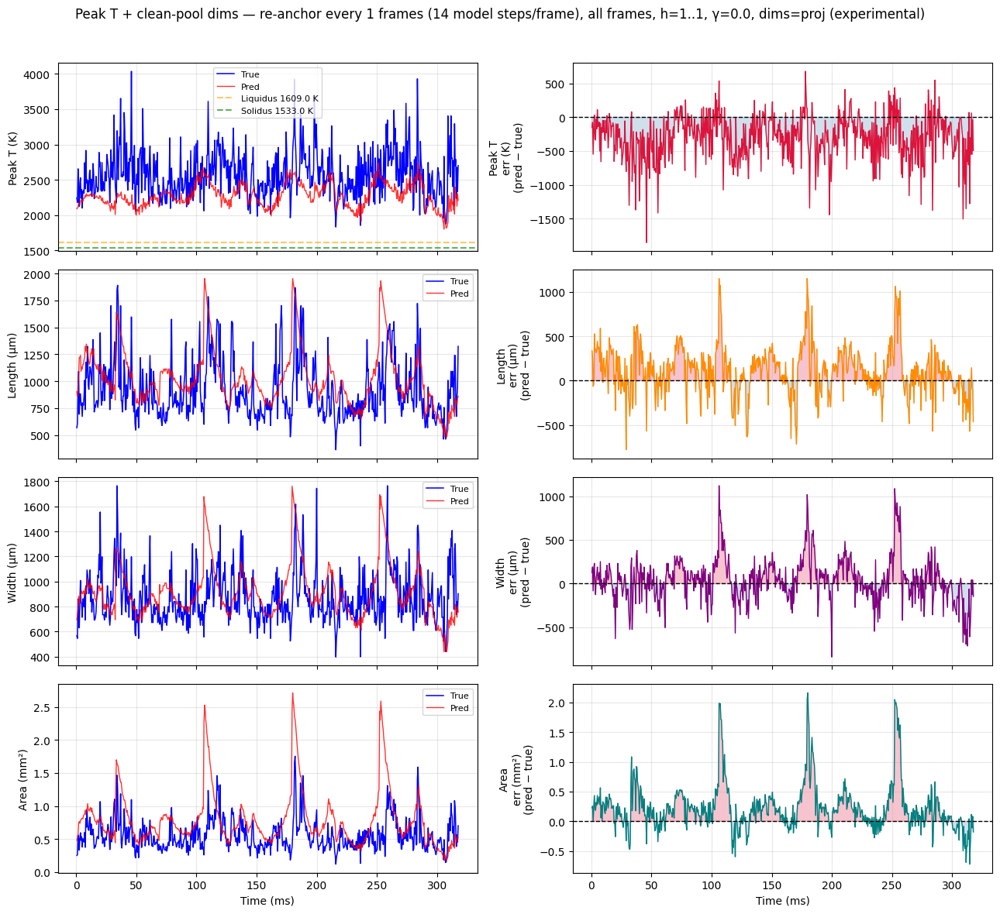

--- STEP_INTERVAL=1, SUBSTEPS=14, all frames, h=1..1, γ=0.0, proj, 636 frames ---
no pool: true 0 frames, pred 0 frames
Peak T: mean|err|=348.9K (12.72%)  bias=-299.7K  max|err|=1858.0K
Length: mean|err|=226.2μm (26.51%)  bias=108.3μm  max|err|=1148.5μm
Width : mean|err|=183.0μm (21.72%)  bias=42.2μm  max|err|=1120.1μm
Area  : mean|err|=0.3047mm² (63.93%)  bias=0.2306mm²  max|err|=2.1582mm²


In [17]:
# =========================================================
# Peak T + melt-pool dims — free-run between anchors, SIM (28 kHz) or EXP (2 kHz)
#   SUBSTEPS = round(dt_data / DT_TRAIN): model steps per data frame (sim 1, exp 14)
#     exp: the model steps SUBSTEPS times between measurements along the
#          linearly interpolated laser path (constant segment velocity);
#          if the chord matches neither neighbouring chord (within TURN_TOL) the interval
#          contains a turn and the path is piecewise:
#          first half continues from m with the velocity of interval (m-1,m),
#          second half arrives at k with the velocity of interval (k,k+1)  (from positions)
#   data type is detected from the rate:
#     SIM -> STEP_INTERVAL_SIM,  EXP -> STEP_INTERVAL_EXP (default 1: one-step at 2 kHz)
#   STEP_INTERVAL = n : TRUE field re-seeded every n DATA frames, n-1 free-run frames
#                 = 1 : sim -> one-step;  exp -> each measurement predicted from the
#                       previous one (SUBSTEPS model steps)
#   h is counted in data frames; model steps ahead = h·SUBSTEPS
#   EVAL_H = None : all predicted frames, h = 1..n-1 (anchor frames excluded)
#          = h    : only the h-step-ahead frame of each segment
#          = n    : diagnostic only (anchor frame, data exists there)
#   GAMMA  = 0    : plain model
#          > 0    : physics correction  dT = dT_model - γ·dt/(ρ·cp)·R_pde   (dt = 1/28 kHz)
#   Peak : max over the same patch nodes for TRUE and PRED (absolute K)
#   Pool : SVD(RANK) + smooth + threshold(Tl) + connectivity + mask smooth,
#          same grid & pipeline for TRUE and PRED;  dims by DIM_METHOD
# =========================================================
from scipy.interpolate import LinearNDInterpolator
from scipy.ndimage import gaussian_filter, label, generate_binary_structure
from scipy.spatial import Delaunay, cKDTree

STEP_INTERVAL_SIM = 14      # sim (28 kHz): re-anchor every n frames, n-1 free-run
STEP_INTERVAL_EXP = 1       # exp (2 kHz): 1 = each measurement from the previous one (14 model steps)
EVAL_H        = None        # None | 1..STEP_INTERVAL
GAMMA         = 0.0         # 0 = no correction
DIM_METHOD    = "proj"      # "proj" | "pca"
RANK=15; SMOOTH_SIGMA=1.5; MASK_SIGMA=1.0
POOL_N=120; POOL_HALF=0.0025/2
TURN_TOL = 0.05            # exp: interval is straight only if its chord velocity matches a neighbour's within 5%
model.eval()

DT_TRAIN = 1.0/float(fs_sim) if 'fs_sim' in globals() else 1.0/28000.0   # model (training) step
SUBSTEPS = max(1, int(round(float(np.median(np.diff(tPath)))/DT_TRAIN)))
IS_EXP   = SUBSTEPS > 1
STEP_INTERVAL = STEP_INTERVAL_EXP if IS_EXP else STEP_INTERVAL_SIM
print(f"{'EXP' if IS_EXP else 'SIM'} data: {1/float(np.median(np.diff(tPath)))/1000:.1f} kHz, "
      f"SUBSTEPS={SUBSTEPS}, STEP_INTERVAL={STEP_INTERVAL}")
N = len(tPath)
H_LAST = max(STEP_INTERVAL-1, 1)
if EVAL_H is not None: assert 1 <= EVAL_H <= STEP_INTERVAL

# ---------- physics correction (self-contained; same as the γ cell) ----------
p_ = params
X_mean_t=torch.tensor(X_mean,dtype=torch.float32,device=device); X_std_t=torch.tensor(X_std,dtype=torch.float32,device=device)
Y_mean_t=torch.tensor(Y_mean,dtype=torch.float32,device=device); Y_std_t=torch.tensor(Y_std,dtype=torch.float32,device=device)
def model_fn_raw(X_phys): return model((X_phys-X_mean_t)/X_std_t)*Y_std_t+Y_mean_t
q_scale=(p_["absorb"]*float(np.mean(X_data[X_data[:,3]>0,3])))/(2.0*np.pi*p_["sigma"]**2*p_["depth"])

def _pde_res(X, prev_dT, dt):
    X = X.requires_grad_(True)
    dT = model_fn_raw(X)
    T  = torch.clamp(dT + p_["Tamb"], p_["Tamb"], 5000.0)
    g1 = torch.autograd.grad(dT, X, grad_outputs=torch.ones_like(dT), create_graph=True)[0]
    Tx = g1[:,1:2]*1000.0; Ty = g1[:,2:3]*1000.0
    dx_m=X[:,1:2]/1000.0; dy_m=X[:,2:3]/1000.0; P=X[:,3:4]; r2_m=dx_m**2+dy_m**2
    is_liquid=(T>p_["Tl"]).float(); is_mushy=((T>=p_["Ts"])&(T<=p_["Tl"])).float(); is_cold=(T<p_["Ts"]).float()
    was_melted=torch.ones_like(T)
    rho=is_cold*(was_melted*p_["rho_solid"]+(1-was_melted)*p_["rho_powder"])+(is_mushy+is_liquid)*p_["rho_liquid"]
    k_m=is_cold*(was_melted*p_["k_solid"]+(1-was_melted)*p_["k_powder"])+(is_mushy+is_liquid)*p_["k_liquid"]
    cp=cp_apparent(T,p_["Ts"],p_["Tl"],p_["Lfus"],p_["cp_base"])
    Q=p_["absorb"]*P/(2.0*np.pi*p_["sigma"]**2*p_["depth"])*torch.exp(-r2_m/(2.0*p_["sigma"]**2))
    kTx=k_m*Tx; kTy=k_m*Ty
    d_kTx=1000.0*torch.autograd.grad(kTx,X,grad_outputs=torch.ones_like(kTx),create_graph=True)[0][:,1:2]
    d_kTy=1000.0*torch.autograd.grad(kTy,X,grad_outputs=torch.ones_like(kTy),create_graph=True)[0][:,2:3]
    q_sink=p_["beta"]*dT; q_rad=p_["e"]*p_["sigma_sb"]*torch.clamp(T**4-p_["Tamb"]**4,min=0.0)
    Tt=(dT-prev_dT.reshape(-1,1))/max(dt,1e-12)
    return (rho*cp*Tt-(d_kTx+d_kTy)-Q+q_sink+q_rad)/q_scale

def _rho_cp(T_phys):
    Tt=torch.clamp(T_phys,p_["Tamb"],5000.0)
    is_liquid=(Tt>p_["Tl"]).float(); is_mushy=((Tt>=p_["Ts"])&(Tt<=p_["Tl"])).float(); is_cold=(Tt<p_["Ts"]).float()
    rho=is_cold*p_["rho_solid"]+(is_mushy+is_liquid)*p_["rho_liquid"]
    return rho, cp_apparent(Tt,p_["Ts"],p_["Tl"],p_["Lfus"],p_["cp_base"])

# ---------- prediction ----------
def _patch(k):
    xL=float(xPath[k]); yL=float(yPath[k]); vx,vy=get_safe_velocity(k,vx_path,vy_path)
    sp=np.sqrt(vx**2+vy**2)+1e-12; vx_n,vy_n=vx/sp,vy/sp
    if DATA_MODE=="experimental":
        m=get_patch_mask(xNodes,yNodes,0.0,0.0,patch_half_width,patch_half_height,
                         -patch_offset*vx_n,-patch_offset*vy_n)
    else:
        m=get_patch_mask(xNodes,yNodes,xL,yL,patch_half_width,patch_half_height,
                         xL-patch_offset*vx_n,yL-patch_offset*vy_n)
    return np.where(m)[0]

def _patch_at(xL,yL,vx,vy):
    sp=np.sqrt(vx**2+vy**2)+1e-12; vx_n,vy_n=vx/sp,vy/sp
    if DATA_MODE=="experimental":
        m=get_patch_mask(xNodes,yNodes,0.0,0.0,patch_half_width,patch_half_height,
                         -patch_offset*vx_n,-patch_offset*vy_n)
    else:
        m=get_patch_mask(xNodes,yNodes,xL,yL,patch_half_width,patch_half_height,
                         xL-patch_offset*vx_n,yL-patch_offset*vy_n)
    return np.where(m)[0]

def _step_at(xL,yL,P,t,vx,vy,idx,Tprev_dT):
    t_feat=np.tanh((t-tPath[0])/TAU)
    xl=xNodes[idx]; yl=yNodes[idx]
    if DATA_MODE=="experimental":
        dx=xl*1000; dy=yl*1000; xa=xl+xL; ya=yl+yL
        dxx=np.minimum(xa,plateX-xa)*1000; dyy=np.minimum(ya,plateY-ya)*1000
    else:
        dx=(xl-xL)*1000; dy=(yl-yL)*1000
        dxx=np.minimum(xl,plateX-xl)*1000; dyy=np.minimum(yl,plateY-yl)*1000
    Xk=np.column_stack([np.full_like(xl,t_feat),dx,dy,np.full_like(xl,P),dxx,dyy,
                        np.full_like(xl,vx),np.full_like(xl,vy),np.asarray(Tprev_dT).ravel()])
    if GAMMA == 0.0:
        with torch.no_grad():
            pn=model(torch.tensor((Xk-X_mean)/X_std,dtype=torch.float32,device=device)).cpu().numpy().reshape(-1)
        return np.clip(pn*Y_std+Y_mean,0.0,None)
    Xraw=torch.tensor(Xk,dtype=torch.float32,device=device)
    with torch.no_grad(): pred=torch.clamp(model_fn_raw(Xraw),0.0).squeeze(1)
    prev_t=torch.tensor(np.asarray(Tprev_dT).ravel(),dtype=torch.float32,device=device)
    res=(_pde_res(Xraw.clone(),prev_t,DT_TRAIN)*q_scale).squeeze(1)
    rho,cp=_rho_cp(pred+p_["Tamb"])
    dT_corr=(DT_TRAIN/(rho*cp+1e-9))*res
    return torch.clamp(pred-GAMMA*dT_corr,0.0).detach().cpu().numpy().astype(np.float64)

def _step(k, idx, Tprev_dT):           # one model step at data frame k (sim)
    P=float(Power[k]) if Power.size>1 else float(Power[0])
    vx,vy=get_safe_velocity(k,vx_path,vy_path)
    return _step_at(float(xPath[k]),float(yPath[k]),P,float(tPath[k]),vx,vy,idx,Tprev_dT)

def _advance(m, T_state):
    """data frame m -> m+1.  sim: one model step at frame m+1.
       exp: SUBSTEPS model steps along the interpolated path m -> m+1.
       returns (T_state, idx of the last step)"""
    k=m+1
    if SUBSTEPS==1:
        idx=_patch(k)
        if len(idx)>0: T_state[idx]=_step(k,idx,T_state[idx])
        return T_state, idx
    dt=max(float(tPath[k]-tPath[m]),1e-12)
    P=float(Power[m]) if Power.size>1 else float(Power[0])
    def _segv(a,b):   # chord velocity between measurements a -> b (from positions)
        d=max(float(tPath[b]-tPath[a]),1e-12)
        return np.clip(np.array([(xPath[b]-xPath[a])/d,(yPath[b]-yPath[a])/d]),-V_MAX,V_MAX)
    def _same(u,w):   # same velocity vector within TURN_TOL (relative)
        nu,nw=np.linalg.norm(u),np.linalg.norm(w)
        return nu>1e-9 and nw>1e-9 and np.linalg.norm(u-w) <= TURN_TOL*max(nu,nw)
    nT=len(tPath)
    def _straight(j):  # interval j -> j+1 matches one of its neighbouring chords
        if j<0 or j+1>=nT: return False
        v=_segv(j,j+1)
        return (j-1>=0 and _same(v,_segv(j-1,j))) or (j+2<nT and _same(v,_segv(j+1,j+2)))
    vseg=_segv(m,k)
    vp=_segv(m-1,m) if m-1>=0 else vseg; vn=_segv(k,k+1) if k+1<nT else vseg
    turn = not (_same(vseg,vp) or _same(vseg,vn))  # chord matches neither neighbour -> turnaround
    if turn:          # entering/leaving velocity from the nearest STRAIGHT interval (turn may span 2 intervals)
        j=m-1
        while j>=max(0,m-6) and not _straight(j): j-=1
        v0=_segv(j,j+1) if j>=max(0,m-6) else vp
        j=k
        while j<=min(nT-2,k+5) and not _straight(j): j+=1
        v1=_segv(j,j+1) if j<=min(nT-2,k+5) else vn
    if not turn:      # straight interval: linear interpolation, constant segment velocity
        vx=float(np.clip((xPath[k]-xPath[m])/dt,-V_MAX,V_MAX)); vy=float(np.clip((yPath[k]-yPath[m])/dt,-V_MAX,V_MAX))
    for s in range(1, SUBSTEPS+1):
        f=s/SUBSTEPS; t=float((1-f)*tPath[m]+f*tPath[k])
        if not turn:
            xL=float((1-f)*xPath[m]+f*xPath[k]); yL=float((1-f)*yPath[m]+f*yPath[k])
        elif f<=0.5:  # turnaround, first half: keep going along the old direction from m
            vx,vy=float(v0[0]),float(v0[1])
            xL=float(xPath[m]+vx*(t-tPath[m])); yL=float(yPath[m]+vy*(t-tPath[m]))
        else:         # turnaround, second half: arrive at k along the new direction
            vx,vy=float(v1[0]),float(v1[1])
            xL=float(xPath[k]-vx*(tPath[k]-t)); yL=float(yPath[k]-vy*(tPath[k]-t))
        idx=_patch_at(xL,yL,vx,vy)
        if len(idx)>0: T_state[idx]=_step_at(xL,yL,P,t,vx,vy,idx,T_state[idx])
    return T_state, idx

def _seed(k):
    return np.clip(T_nodes_time[:,k]-Tamb,0.0,None).astype(np.float64)

# ---------- clean-pool measurement ----------
_nodes_xy=np.column_stack([xNodes,yNodes]); _st2=generate_binary_structure(2,1)
_tri=Delaunay(_nodes_xy); _kdt=cKDTree(_nodes_xy)

_W_CACHE = {}
def _grid_weights(Xg, Yg):
    """barycentric weights of the grid points in the mesh triangulation (cached per grid).
       identical to LinearNDInterpolator + nearest fill outside the hull."""
    key=(Xg.shape, round(float(Xg[0,0]),12), round(float(Yg[0,0]),12),
         round(float(Xg[0,-1]),12), round(float(Yg[-1,0]),12))
    w=_W_CACHE.get(key)
    if w is None:
        pts=np.column_stack([Xg.ravel(),Yg.ravel()])
        s=_tri.find_simplex(pts); ins=s>=0
        Tr=_tri.transform[s[ins]]
        bc=np.einsum('ijk,ik->ij',Tr[:,:2],pts[ins]-Tr[:,2])
        w=(ins, _tri.simplices[s[ins]], np.c_[bc,1.0-bc.sum(1)],
           _kdt.query(pts[~ins])[1] if (~ins).any() else np.empty(0,int))
        if len(_W_CACHE)>256: _W_CACHE.clear()
        _W_CACHE[key]=w
    return w

def _interp_grid(field, Xg, Yg):
    ins,verts,bw,nn=_grid_weights(Xg,Yg)
    out=np.empty(ins.size); out[ins]=(field[verts]*bw).sum(1); out[~ins]=field[nn]
    return out.reshape(Xg.shape)

def clean_pool_grid(field, k):
    xL=xPath[k]; yL=yPath[k]; vx,vy=get_safe_velocity(k,vx_path,vy_path)
    vx_n=vx/(np.hypot(vx,vy)+1e-12); vy_n=vy/(np.hypot(vx,vy)+1e-12)
    if DATA_MODE=="experimental": cx,cy=-patch_offset*vx_n,-patch_offset*vy_n
    else:                         cx,cy=xL-patch_offset*vx_n,yL-patch_offset*vy_n
    xg=np.linspace(cx-POOL_HALF,cx+POOL_HALF,POOL_N); yg=np.linspace(cy-POOL_HALF,cy+POOL_HALF,POOL_N)
    Xg,Yg=np.meshgrid(xg,yg)
    img=np.clip(_interp_grid(field,Xg,Yg),Tamb,None)
    U,S,Vt=np.linalg.svd(img-Tamb,full_matrices=False)
    r=min(RANK,len(S)); rec=(U[:,:r]*S[:r])@Vt[:r]+Tamb
    rec=gaussian_filter(np.clip(rec,Tamb,None),sigma=SMOOTH_SIGMA); rec=np.clip(rec,Tamb,None)
    hot=rec>=Tl
    if hot.sum()<3: return None,Xg,Yg,(xg[1]-xg[0])
    lbl,_=label(hot,structure=_st2)
    iy,ix=np.unravel_index(np.argmax(rec),rec.shape); L=lbl[iy,ix]
    if L==0:
        s=np.bincount(lbl.ravel()); s[0]=0; L=s.argmax()
    mask=gaussian_filter((lbl==L).astype(float),sigma=MASK_SIGMA)>0.5
    return mask,Xg,Yg,(xg[1]-xg[0])

def dims_proj(mask, Xg, Yg, vx, vy):
    if mask is None or mask.sum()<3: return 0.0,0.0
    px=Xg[mask]; py=Yg[mask]; c=np.array([px.mean(),py.mean()])
    sp=np.sqrt(vx**2+vy**2)+1e-12; sx,sy=vx/sp,vy/sp; qx,qy=-sy,sx
    ds=(px-c[0])*sx+(py-c[1])*sy; dp=(px-c[0])*qx+(py-c[1])*qy
    return ds.max()-ds.min(), dp.max()-dp.min()       # length, width

def dims_pca(mask, Xg, Yg):
    if mask is None or mask.sum()<3: return 0.0,0.0
    X=np.column_stack([Xg[mask],Yg[mask]]); X=X-X.mean(0)
    _,evec=np.linalg.eigh(np.cov(X.T)); a=X@evec[:,-1]; b=X@evec[:,0]
    return a.max()-a.min(), b.max()-b.min()            # length, width

def measure(field, k):
    vx,vy=get_safe_velocity(k,vx_path,vy_path)
    mask,Xg,Yg,cell=clean_pool_grid(field,k)
    L,W = dims_proj(mask,Xg,Yg,vx,vy) if DIM_METHOD=="proj" else dims_pca(mask,Xg,Yg)
    A=(mask.sum() if mask is not None else 0)*cell*cell
    return L,W,A,(mask is not None)

# ---------- roll the track ----------
rec_t,rec_h=[],[]
Pt,Pp,Lt,Wt,At,Lp,Wp,Ap,has_t,has_p=[],[],[],[],[],[],[],[],[],[]
T_state=_seed(0); h=0
for k in range(1, N):
    h += 1
    is_anchor = (k % STEP_INTERVAL == 0)
    keep = (h == EVAL_H) if EVAL_H is not None else (h <= H_LAST)
    T_state, idx = _advance(k-1, T_state)              # predict BEFORE any re-seed
    if len(idx) > 0:
        if keep:
            true_f=np.clip(T_nodes_time[:,k],Tamb,None); pred_f=T_state+Tamb
            Pt.append(true_f[idx].max()); Pp.append(pred_f[idx].max())
            lt,wt,at,ht = measure(true_f,k); lp,wp,ap,hp = measure(pred_f,k)
            Lt.append(lt);Wt.append(wt);At.append(at);Lp.append(lp);Wp.append(wp);Ap.append(ap)
            has_t.append(ht);has_p.append(hp);rec_t.append(tPath[k]);rec_h.append(h)
    if is_anchor:
        T_state=_seed(k); h=0

tv=np.array(rec_t)*1000; rec_h=np.array(rec_h); has_t=np.array(has_t); has_p=np.array(has_p)
Pt,Pp=np.array(Pt),np.array(Pp)
Lt,Wt,Lp,Wp=[np.array(a)*1e6 for a in (Lt,Wt,Lp,Wp)]     # μm
At,Ap=[np.array(a)*1e6 for a in (At,Ap)]                 # mm²
P_err=Pp-Pt; L_err=Lp-Lt; W_err=Wp-Wt; A_err=Ap-At

# ---------- plot: 4 rows x 2 cols ----------
mode_lbl = f"all frames, h=1..{H_LAST}" if EVAL_H is None else f"h={EVAL_H} only"
mk = '-' if EVAL_H is None else 'o-'
fig,ax=plt.subplots(4,2,figsize=(13,12),sharex=True)
fig.suptitle(f"Peak T + clean-pool dims — re-anchor every {STEP_INTERVAL} frames ({SUBSTEPS} model steps/frame), {mode_lbl}, "
             f"γ={GAMMA}, dims={DIM_METHOD} ({DATA_MODE})", fontsize=12)
for i,(yt,yp,e,lab,col) in enumerate([(Pt,Pp,P_err,"Peak T (K)","crimson"),
                                      (Lt,Lp,L_err,"Length (μm)","darkorange"),
                                      (Wt,Wp,W_err,"Width (μm)","purple"),
                                      (At,Ap,A_err,"Area (mm²)","teal")]):
    ax[i,0].plot(tv,yt,'b'+mk,ms=3,lw=1.1,label='True')
    ax[i,0].plot(tv,yp,'r'+mk,ms=3,lw=1.0,alpha=0.8,label='Pred')
    if i==0:
        ax[i,0].axhline(Tl,color='orange',ls='--',alpha=0.6,label=f'Liquidus {Tl} K')
        ax[i,0].axhline(Ts,color='green', ls='--',alpha=0.6,label=f'Solidus {Ts} K')
    ax[i,0].set_ylabel(lab); ax[i,0].legend(fontsize=8); ax[i,0].grid(alpha=0.3)
    ax[i,1].plot(tv,e,color=col,lw=1.0); ax[i,1].axhline(0,color='k',ls='--',lw=1)
    ax[i,1].fill_between(tv,e,0,where=e>0,alpha=0.25,color='crimson')
    ax[i,1].fill_between(tv,e,0,where=e<0,alpha=0.25,color='steelblue')
    ax[i,1].set_ylabel(lab.replace(" (","\nerr (")+"\n(pred − true)"); ax[i,1].grid(alpha=0.3)
ax[3,0].set_xlabel("Time (ms)"); ax[3,1].set_xlabel("Time (ms)")
plt.tight_layout(rect=[0,0,1,0.96])
tag = "full" if EVAL_H is None else f"h{EVAL_H}"
fig.savefig(f"PeakPool_{DIM_METHOD}_n{STEP_INTERVAL}_{tag}_g{GAMMA}_{DATA_MODE}.png", dpi=250, bbox_inches="tight")
plt.show()

# ---------- stats ----------
def _pct(e,yt):
    ok=yt>1e-9; return np.mean(np.abs(e[ok])/yt[ok])*100 if ok.any() else np.nan
print(f"--- STEP_INTERVAL={STEP_INTERVAL}, SUBSTEPS={SUBSTEPS}, {mode_lbl}, γ={GAMMA}, {DIM_METHOD}, {len(tv)} frames ---")
print(f"no pool: true {int((~has_t).sum())} frames, pred {int((~has_p).sum())} frames")
for nm,e,yt,u,f in [("Peak T",P_err,Pt,"K","{:.1f}"),("Length",L_err,Lt,"μm","{:.1f}"),
                    ("Width",W_err,Wt,"μm","{:.1f}"),("Area",A_err,At,"mm²","{:.4f}")]:
    print(f"{nm:6s}: mean|err|={f.format(np.mean(np.abs(e)))}{u} ({_pct(e,yt):.2f}%)  "
          f"bias={f.format(np.mean(e))}{u}  max|err|={f.format(np.max(np.abs(e)))}{u}")
if EVAL_H is None and H_LAST > 1:
    print(f"{'h':>3} {'steps':>6} {'Peak %':>8} {'L %':>7} {'W %':>7} {'A %':>7} {'n':>5}")
    for hh in range(1, H_LAST+1):
        m=rec_h==hh
        if m.any():
            print(f"{hh:>3} {hh*SUBSTEPS:>6} {_pct(P_err[m],Pt[m]):>8.2f} {_pct(L_err[m],Lt[m]):>7.2f} "
                  f"{_pct(W_err[m],Wt[m]):>7.2f} {_pct(A_err[m],At[m]):>7.2f} {m.sum():>5}")

In [17]:
print(f"rate {1/np.median(np.diff(tPath))/1000:.1f} kHz, SUBSTEPS={SUBSTEPS}, "
      f"{len(tv)} points over {tv[-1]-tv[0]:.2f} ms -> {len(tv)/(tv[-1]-tv[0]):.1f} points/ms")

rate 28.0 kHz, SUBSTEPS=1, 8499 points over 326.82 ms -> 26.0 points/ms


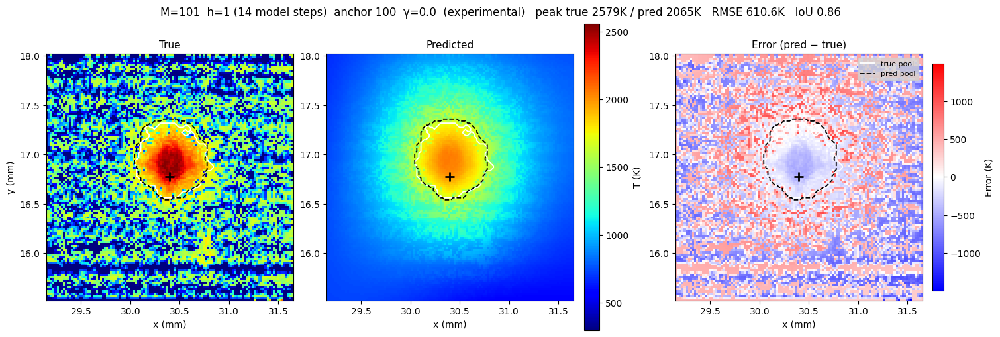

--- M=101, h=1 (14 model steps) (anchor 100), proj dims ---
quantity           true       pred      error    err %
Peak T (K)         2579       2065       -514   -19.95
Length (μm)         735        798         63    +8.57
Width (μm)          777        714        -63    -8.11
Area (mm²)       0.4162     0.4634     0.0472   +11.35
IoU=0.857   patch RMSE=610.6 K


In [24]:
# =========================================================
# Single frame — TRUE vs PRED vs ERROR, SIM or EXP (auto)
#   SIM (28 kHz): free-run from the last anchor before M (every STEP_INTERVAL_SIM frames)
#   EXP (2 kHz) : default STEP_INTERVAL_EXP = 1 -> M predicted from measurement M-1
#                 with SUBSTEPS (=14) model steps along the interpolated path
#   anchor = largest multiple of STEP_INTERVAL below M,  h = M - anchor (data frames)
#   (M on an anchor -> h = STEP_INTERVAL: prediction made before re-seeding)
#   reuses _advance/_seed/clean_pool_grid/dims_*/_tri/_kdt/GAMMA/DIM_METHOD/POOL_*
#   from the peak+pool cell (run it once first)
# =========================================================
STEP_INTERVAL_SIM = 14
STEP_INTERVAL_EXP = 1
M                 = 101          # data frame to show
ANCHOR            = 100         # None = auto (last anchor before M); int = free-run from this frame

SUBSTEPS = max(1, int(round(float(np.median(np.diff(tPath)))/DT_TRAIN)))
IS_EXP   = SUBSTEPS > 1
STEP_INTERVAL = STEP_INTERVAL_EXP if IS_EXP else STEP_INTERVAL_SIM
assert 1 <= M < len(tPath), f"M={M} out of range (1..{len(tPath)-1})"
anchor = ((M-1)//STEP_INTERVAL)*STEP_INTERVAL if ANCHOR is None else int(ANCHOR)
assert 0 <= anchor < M, f"anchor={anchor} must be < M={M}"
h_M    = M - anchor
h_lbl  = f"h={h_M}" + (f" ({h_M*SUBSTEPS} model steps)" if IS_EXP else "")

# --- free-run anchor -> M ---
T_state=_seed(anchor)
for m in range(anchor, M):
    T_state, idx_M = _advance(m, T_state)
pred_f = T_state+Tamb
true_f = np.clip(T_nodes_time[:,M],Tamb,None)

# --- same laser-centered grid as the pool pipeline ---
xL=xPath[M]; yL=yPath[M]; vx,vy=get_safe_velocity(M,vx_path,vy_path)
vx_n=vx/(np.hypot(vx,vy)+1e-12); vy_n=vy/(np.hypot(vx,vy)+1e-12)
if DATA_MODE=="experimental": cx,cy=-patch_offset*vx_n,-patch_offset*vy_n; ox,oy=xL,yL
else:                         cx,cy=xL-patch_offset*vx_n,yL-patch_offset*vy_n; ox,oy=0.0,0.0
xg=np.linspace(cx-POOL_HALF,cx+POOL_HALF,POOL_N); yg=np.linspace(cy-POOL_HALF,cy+POOL_HALF,POOL_N)
Xg,Yg=np.meshgrid(xg,yg)
def _itp(v):
    T=LinearNDInterpolator(_tri,v)(Xg,Yg); mm=np.isnan(T)
    if mm.any(): T[mm]=v[_kdt.query(np.column_stack([Xg[mm],Yg[mm]]))[1]]
    return np.clip(T,Tamb,None)
Tt=_itp(true_f); Tp=_itp(pred_f); err=Tp-Tt

# --- clean pools + metrics (same pipeline as the peak+pool cell) ---
def _pool(field, k):
    vx_,vy_=get_safe_velocity(k,vx_path,vy_path)
    mask,Xg_,Yg_,cell=clean_pool_grid(field,k)
    L,W = dims_proj(mask,Xg_,Yg_,vx_,vy_) if DIM_METHOD=="proj" else dims_pca(mask,Xg_,Yg_)
    if mask is None: mask=np.zeros((POOL_N,POOL_N),bool)
    return mask,L,W,mask.sum()*cell*cell
mt,lt,wt,at = _pool(true_f,M); mp,lp,wp,ap = _pool(pred_f,M)
inter=(mt&mp).sum(); uni=(mt|mp).sum(); iou=inter/uni if uni>0 else np.nan
pk_t=true_f[idx_M].max(); pk_p=pred_f[idx_M].max()
rmse=np.sqrt(np.mean((pred_f[idx_M]-true_f[idx_M])**2))     # on patch nodes (no interpolation)

# --- plot (one colorbar for True+Pred, one for Error) ---
ext=[(xg[0]+ox)*1000,(xg[-1]+ox)*1000,(yg[0]+oy)*1000,(yg[-1]+oy)*1000]
Xc,Yc=(Xg+ox)*1000,(Yg+oy)*1000
vmax=max(Tt.max(),Tp.max()); emax=max(np.abs(err).max(),1.0)
fig,axes=plt.subplots(1,3,figsize=(15,5),constrained_layout=True)
fig.suptitle(f"M={M}  {h_lbl}  anchor {anchor}  γ={GAMMA}  ({DATA_MODE})   "
             f"peak true {pk_t:.0f}K / pred {pk_p:.0f}K   RMSE {rmse:.1f}K   IoU {iou:.2f}", fontsize=12)
ims=[]
for ax,(d,cmap,vlo,vhi,ttl) in zip(axes,[(Tt,'jet',Tamb,vmax,'True'),
                                          (Tp,'jet',Tamb,vmax,'Predicted'),
                                          (err,'bwr',-emax,emax,'Error (pred − true)')]):
    ims.append(ax.imshow(d,origin='lower',cmap=cmap,vmin=vlo,vmax=vhi,extent=ext,aspect='equal'))
    if mt.any(): ax.contour(Xc,Yc,mt.astype(float),levels=[0.5],colors='white',linewidths=1.3)
    if mp.any(): ax.contour(Xc,Yc,mp.astype(float),levels=[0.5],colors='black',linewidths=1.3,linestyles='--')
    ax.plot(xL*1000, yL*1000,'k+',ms=10,mew=2)
    ax.set_xlabel("x (mm)"); ax.set_title(ttl,fontsize=11)
axes[0].set_ylabel("y (mm)")
fig.colorbar(ims[1],ax=axes[:2],fraction=0.046,pad=0.02,label="T (K)")
fig.colorbar(ims[2],ax=axes[2], fraction=0.046,pad=0.04,label="Error (K)")
axes[2].plot([],[],color='white',lw=1.3,label='true pool'); axes[2].plot([],[],'k--',lw=1.3,label='pred pool')
axes[2].legend(fontsize=8,loc='upper right',facecolor='lightgray')
fig.savefig(f"frame_M{M}_h{h_M}_n{STEP_INTERVAL}_g{GAMMA}_{DATA_MODE}.png", dpi=250, bbox_inches="tight")
plt.show()

print(f"--- M={M}, {h_lbl} (anchor {anchor}), {DIM_METHOD} dims ---")
print(f"{'quantity':12s} {'true':>10s} {'pred':>10s} {'error':>10s} {'err %':>8s}")
for nm,tv_,pv_,f in [("Peak T (K)",pk_t,pk_p,"{:>10.0f}"),("Length (μm)",lt*1e6,lp*1e6,"{:>10.0f}"),
                     ("Width (μm)",wt*1e6,wp*1e6,"{:>10.0f}"),("Area (mm²)",at*1e6,ap*1e6,"{:>10.4f}")]:
    pct=(pv_-tv_)/tv_*100 if tv_>1e-12 else np.nan
    print(f"{nm:12s} {f.format(tv_)} {f.format(pv_)} {f.format(pv_-tv_)} {pct:>+8.2f}")
print(f"IoU={iou:.3f}   patch RMSE={rmse:.1f} K")

In [24]:
# =========================================================
# Video — TRUE | PRED | ERROR along the track, SIM or EXP (auto)
#   SIM (28 kHz): re-anchor every STEP_INTERVAL_SIM frames, free-run in between
#   EXP (2 kHz) : default STEP_INTERVAL_EXP = 1 -> each measurement predicted from the
#                 previous one with SUBSTEPS (=14) model steps along the interpolated path
#   GAMMA = 0 plain model, > 0 physics correction
#   colorbars FIXED for the whole video:
#       T  : one bar shared by True and Pred, [Tamb, T_MAX]
#       Err: symmetric [-E_MAX, +E_MAX]
#     T_MAX / E_MAX = None -> taken from a first pass over the same frames
#   reuses _advance / _seed / clean_pool_grid / _tri / _kdt / POOL_* / DT_TRAIN
#   from the peak+pool cell (run it once first)
# =========================================================
import matplotlib.animation as animation

STEP_INTERVAL_SIM = 14
STEP_INTERVAL_EXP = 1
GAMMA         = 0.0
K_START, K_END = 1, len(tPath)-1     # frame range (inclusive)
K_STRIDE      = 13                    # render every n-th frame (rollout still steps every frame)
FPS           = 15
T_MAX         = None                 # K, None = auto (max true peak in range)
E_MAX         = 400                 # K, None = auto (max |err| in range)
SHOW_POOL     = True                 # SVD clean-pool outlines (white true, black dashed pred)

SUBSTEPS = max(1, int(round(float(np.median(np.diff(tPath)))/DT_TRAIN)))
IS_EXP   = SUBSTEPS > 1
STEP_INTERVAL = STEP_INTERVAL_EXP if IS_EXP else STEP_INTERVAL_SIM
VIDEO_PATH    = f"video_n{STEP_INTERVAL}_g{GAMMA}_{DATA_MODE}.mp4"
print(f"{'EXP' if IS_EXP else 'SIM'} data: SUBSTEPS={SUBSTEPS}, STEP_INTERVAL={STEP_INTERVAL}")
assert 1 <= K_START <= K_END < len(tPath)

def _rollout():
    """yields (k, h, idx, pred_field_abs) for k = K_START..K_END, same re-anchor rule as all cells"""
    anchor=((K_START-1)//STEP_INTERVAL)*STEP_INTERVAL
    T_state=_seed(anchor); last=anchor
    for k in range(anchor+1, K_END+1):
        T_state, idx = _advance(k-1, T_state)                    # predict BEFORE any re-seed
        if k>=K_START: yield k, k-last, idx, T_state+Tamb
        if k % STEP_INTERVAL == 0:
            T_state=_seed(k); last=k

# --- pass 1: fixed color limits ---
if T_MAX is None or E_MAX is None:
    tmax=Tamb; emax=1.0
    for k,h,idx,pred_f in _rollout():
        if len(idx)==0: continue
        tr=np.clip(T_nodes_time[idx,k],Tamb,None)
        tmax=max(tmax,tr.max(),pred_f[idx].max()); emax=max(emax,np.abs(pred_f[idx]-tr).max())
    T_MAX = tmax if T_MAX is None else T_MAX
    E_MAX = emax if E_MAX is None else E_MAX
print(f"color limits: T [{Tamb:.0f}, {T_MAX:.0f}] K   err ±{E_MAX:.0f} K")

# --- grid helpers (same laser-centered grid as the pool pipeline) ---
def _grid(k):
    xL=xPath[k]; yL=yPath[k]; vx,vy=get_safe_velocity(k,vx_path,vy_path)
    vx_n=vx/(np.hypot(vx,vy)+1e-12); vy_n=vy/(np.hypot(vx,vy)+1e-12)
    if DATA_MODE=="experimental": cx,cy=-patch_offset*vx_n,-patch_offset*vy_n; ox,oy=xL,yL
    else:                         cx,cy=xL-patch_offset*vx_n,yL-patch_offset*vy_n; ox,oy=0.0,0.0
    xg=np.linspace(cx-POOL_HALF,cx+POOL_HALF,POOL_N); yg=np.linspace(cy-POOL_HALF,cy+POOL_HALF,POOL_N)
    Xg,Yg=np.meshgrid(xg,yg); return Xg,Yg,ox,oy
def _itp(v,Xg,Yg):
    T=LinearNDInterpolator(_tri,v)(Xg,Yg); mm=np.isnan(T)
    if mm.any(): T[mm]=v[_kdt.query(np.column_stack([Xg[mm],Yg[mm]]))[1]]
    return np.clip(T,Tamb,None)

# --- figure with fixed colorbars ---
fig,axes=plt.subplots(1,3,figsize=(14,4.6),constrained_layout=True)
blank=np.full((POOL_N,POOL_N),Tamb)
imT=axes[0].imshow(blank,origin='lower',cmap='jet',vmin=Tamb,vmax=T_MAX,aspect='equal')
imP=axes[1].imshow(blank,origin='lower',cmap='jet',vmin=Tamb,vmax=T_MAX,aspect='equal')
imE=axes[2].imshow(blank*0,origin='lower',cmap='bwr',vmin=-E_MAX,vmax=E_MAX,aspect='equal')
fig.colorbar(imP,ax=axes[:2],fraction=0.046,pad=0.02,label="T (K)")
fig.colorbar(imE,ax=axes[2], fraction=0.046,pad=0.04,label="Error (K)")
for ax,ttl in zip(axes,["True","Predicted","Error (pred − true)"]):
    ax.set_title(ttl,fontsize=11); ax.set_xlabel("x (mm)")
axes[0].set_ylabel("y (mm)")
marks=[ax.plot([],[],'k+',ms=10,mew=2)[0] for ax in axes]
sup=fig.suptitle("",fontsize=12)
contours=[]

def _clear_contours():
    for c in contours:
        try: c.remove()
        except Exception:
            for coll in getattr(c,"collections",[]): coll.remove()
    contours.clear()

# --- pass 2: render ---
writer=animation.FFMpegWriter(fps=FPS,bitrate=2400)
n_out=0
with writer.saving(fig, VIDEO_PATH, dpi=120):
    for k,h,idx,pred_f in _rollout():
        if (k-K_START) % K_STRIDE: continue
        true_f=np.clip(T_nodes_time[:,k],Tamb,None)
        Xg,Yg,ox,oy=_grid(k); Xc,Yc=(Xg+ox)*1000,(Yg+oy)*1000
        ext=[Xc[0,0],Xc[0,-1],Yc[0,0],Yc[-1,0]]
        Tt=_itp(true_f,Xg,Yg); Tp=_itp(pred_f,Xg,Yg)
        for im,d in ((imT,Tt),(imP,Tp),(imE,Tp-Tt)):
            im.set_data(d); im.set_extent(ext)
        for ax,mk in zip(axes,marks):
            ax.set_xlim(ext[0],ext[1]); ax.set_ylim(ext[2],ext[3])
            mk.set_data([xPath[k]*1000],[yPath[k]*1000])
        _clear_contours()
        if SHOW_POOL:
            mt=clean_pool_grid(true_f,k)[0]; mp=clean_pool_grid(pred_f,k)[0]
            for ax in axes:
                if mt is not None: contours.append(ax.contour(Xc,Yc,mt.astype(float),levels=[0.5],colors='white',linewidths=1.1))
                if mp is not None: contours.append(ax.contour(Xc,Yc,mp.astype(float),levels=[0.5],colors='black',linewidths=1.1,linestyles='--'))
        pk_t=true_f[idx].max() if len(idx) else np.nan; pk_p=pred_f[idx].max() if len(idx) else np.nan
        rmse=np.sqrt(np.mean((pred_f[idx]-true_f[idx])**2)) if len(idx) else np.nan
        tag="  [anchor: h=%d before re-seed]"%h if (h==STEP_INTERVAL and STEP_INTERVAL>1) else ""
        stp=f" ({h*SUBSTEPS} model steps)" if IS_EXP else ""
        sup.set_text(f"k={k}  t={(tPath[k]-tPath[0])*1e3:.2f} ms  h={h}/{STEP_INTERVAL}{stp}{tag}   γ={GAMMA}   "
                     f"peak {pk_t:.0f}/{pk_p:.0f} K   RMSE {rmse:.0f} K")
        writer.grab_frame(); n_out+=1
plt.close(fig)
print(f"Saved: {VIDEO_PATH}  ({n_out} frames, {n_out/FPS:.1f} s)")

SIM data: SUBSTEPS=1, STEP_INTERVAL=14
color limits: T [295, 3774] K   err ±400 K
Saved: video_n14_g0.0_sim.mp4  (704 frames, 46.9 s)


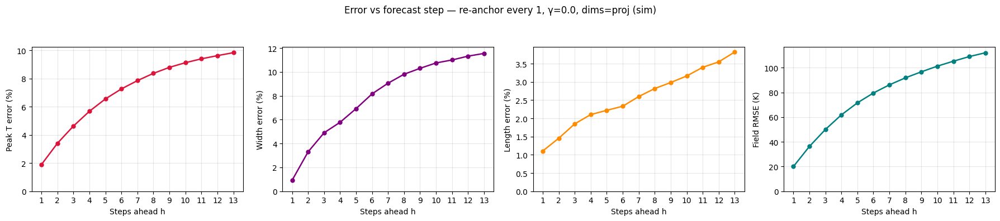

  h   Peak %  Width %  Length %   RMSE K
  1     1.89     0.92      1.10     20.0
  2     3.40     3.30      1.45     36.3
  3     4.62     4.90      1.85     50.0
  4     5.67     5.78      2.10     61.9
  5     6.55     6.92      2.22     71.6
  6     7.26     8.16      2.33     79.5
  7     7.85     9.06      2.60     86.1
  8     8.36     9.81      2.82     91.8
  9     8.79    10.30      2.98     96.7
 10     9.12    10.75      3.16    101.3
 11     9.40    11.00      3.40    105.3
 12     9.62    11.32      3.55    109.0
 13     9.83    11.55      3.82    112.1
excluded (no true pool): width 9, length 9 frames


In [29]:
# =========================================================
# Error vs forecast step h — 1 row, 4 plots
#   Peak T, Width, Length : mean |pred − true| / true × 100  (%)
#       peak % is relative to the true peak absolute temperature (K)
#       frames with no true pool (true dim = 0) are excluded from width/length %
#   Field RMSE (K)        : temperature RMSE on the patch nodes, pooled over frames at each h
#   uses R / hh / H_LAST from the fitness cell (run it with EVAL_H = None)
# =========================================================
assert EVAL_H is None, "run the fitness cell with EVAL_H = None (needs all h)"

H = np.arange(1, H_LAST+1)
def pct_h(t, p, ref_off=0.0):
    out, nex = [], 0
    for k in H:
        m=hh==k; yt=R[t][m]-ref_off; yp=R[p][m]-ref_off; ok=yt>1e-9
        nex += int((~ok).sum())
        out.append(np.mean(np.abs(yp[ok]-yt[ok])/yt[ok])*100 if ok.any() else np.nan)
    return np.array(out), nex

pk_pct, _    = pct_h("Pt","Pp")
w_pct,  w_ex = pct_h("Wt","Wp")
l_pct,  l_ex = pct_h("Lt","Lp")
rmse_h = np.array([np.sqrt(np.mean(R["RMSE"][hh==k]**2)) if (hh==k).any() else np.nan for k in H])

panels=[(pk_pct,"Peak T error (%)","crimson"),
        (w_pct, "Width error (%)", "purple"),
        (l_pct, "Length error (%)","darkorange"),
        (rmse_h,"Field RMSE (K)",  "teal")]

fig,axes=plt.subplots(1,4,figsize=(18,4))
fig.suptitle(f"Error vs forecast step — re-anchor every {STEP_INTERVAL}, γ={GAMMA}, "
             f"dims={DIM_METHOD} ({DATA_MODE})", fontsize=12)
for ax,(y,lab,col) in zip(axes,panels):
    ax.plot(H, y, 'o-', color=col, lw=1.8, ms=5)
    ax.set_xlabel("Steps ahead h"); ax.set_ylabel(lab)
    ax.set_xticks(H); ax.set_ylim(bottom=0); ax.grid(alpha=0.3)
plt.tight_layout(rect=[0,0,1,0.92])
fig.savefig(f"Err_vs_h_n{STEP_INTERVAL}_g{GAMMA}_{DIM_METHOD}_{DATA_MODE}.png", dpi=250, bbox_inches="tight")
plt.show()

print(f"{'h':>3} {'Peak %':>8} {'Width %':>8} {'Length %':>9} {'RMSE K':>8}")
for i,k in enumerate(H):
    print(f"{k:>3} {pk_pct[i]:>8.2f} {w_pct[i]:>8.2f} {l_pct[i]:>9.2f} {rmse_h[i]:>8.1f}")
print(f"excluded (no true pool): width {w_ex}, length {l_ex} frames")

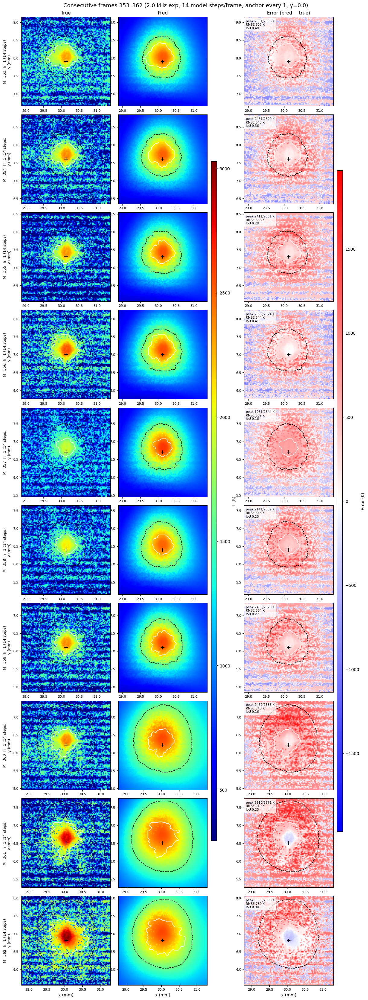

     M                 step  peak true  peak pred   err %  RMSE K   IoU
   353       h=1 (14 steps)       2381       2536   +6.49   606.8  0.40
   354       h=1 (14 steps)       2451       2520   +2.81   645.2  0.36
   355       h=1 (14 steps)       2411       2561   +6.22   666.4  0.29
   356       h=1 (14 steps)       2599       2574   -0.95   644.3  0.41
   357       h=1 (14 steps)       1961       2644  +34.80   609.5  0.16
   358       h=1 (14 steps)       2141       2507  +17.10   647.8  0.20
   359       h=1 (14 steps)       2433       2578   +5.96   663.8  0.27
   360       h=1 (14 steps)       2452       2583   +5.33   848.4  0.16
   361       h=1 (14 steps)       2910       2571  -11.67   918.9  0.20
   362       h=1 (14 steps)       3055       2586  -15.36   788.8  0.30


In [25]:
# =========================================================
# Consecutive frames — TRUE | PRED | ERROR, N_FRAMES rows, SIM or EXP (auto)
#   SIM (28 kHz): re-anchor every STEP_INTERVAL_SIM frames, free-run in between
#   EXP (2 kHz) : default STEP_INTERVAL_EXP = 1 -> each measurement predicted from the
#                 previous one with SUBSTEPS (=14) model steps along the interpolated path
#   h per row in data frames (+ model steps for exp)
#   colorbars: one shared by all True/Pred panels, one for all Error panels
#   pools: SVD clean-pool masks (white = true, black dashed = pred)
#   reuses _advance / _seed / clean_pool_grid / dims_* / _tri / _kdt / POOL_* /
#   GAMMA / DIM_METHOD / DT_TRAIN from the peak+pool cell (run it once first)
# =========================================================
STEP_INTERVAL_SIM = 14
STEP_INTERVAL_EXP = 1
M0                = 353         # first frame shown
N_FRAMES          = 10

SUBSTEPS = max(1, int(round(float(np.median(np.diff(tPath)))/DT_TRAIN)))
IS_EXP   = SUBSTEPS > 1
STEP_INTERVAL = STEP_INTERVAL_EXP if IS_EXP else STEP_INTERVAL_SIM
N_DATA = len(tPath)
assert N_FRAMES <= N_DATA-1, f"N_FRAMES={N_FRAMES} > available frames ({N_DATA-1})"
M0_max = N_DATA - N_FRAMES                     # last valid first frame
if not (1 <= M0 <= M0_max):
    print(f"M0={M0} out of range for {N_DATA} {'exp' if IS_EXP else 'sim'} frames "
          f"(valid 1..{M0_max}) -> using M0={min(max(M0,1),M0_max)}")
    M0 = min(max(M0,1), M0_max)
frames = list(range(M0, M0+N_FRAMES))

# --- rollout (same re-anchor rule as all cells) ---
preds, idxs, hlab = {}, {}, {}
anchor=((M0-1)//STEP_INTERVAL)*STEP_INTERVAL
T_state=_seed(anchor); last=anchor
for k in range(anchor+1, frames[-1]+1):
    T_state,idx=_advance(k-1,T_state)                 # predict BEFORE any re-seed
    if k in frames:
        h=k-last; preds[k]=T_state+Tamb; idxs[k]=idx
        hlab[k]=f"h={h}" + (f" ({h*SUBSTEPS} steps)" if IS_EXP else "") \
                + (" anchor" if (h==STEP_INTERVAL and STEP_INTERVAL>1) else "")
    if k % STEP_INTERVAL == 0:
        T_state=_seed(k); last=k

# --- grids (same laser-centered grid as the pool pipeline) ---
def _grid(k):
    xL=xPath[k]; yL=yPath[k]; vx,vy=get_safe_velocity(k,vx_path,vy_path)
    vx_n=vx/(np.hypot(vx,vy)+1e-12); vy_n=vy/(np.hypot(vx,vy)+1e-12)
    if DATA_MODE=="experimental": cx,cy=-patch_offset*vx_n,-patch_offset*vy_n; ox,oy=xL,yL
    else:                         cx,cy=xL-patch_offset*vx_n,yL-patch_offset*vy_n; ox,oy=0.0,0.0
    xg=np.linspace(cx-POOL_HALF,cx+POOL_HALF,POOL_N); yg=np.linspace(cy-POOL_HALF,cy+POOL_HALF,POOL_N)
    Xg,Yg=np.meshgrid(xg,yg); return Xg,Yg,ox,oy
def _itp(v,Xg,Yg):
    T=LinearNDInterpolator(_tri,v)(Xg,Yg); mm=np.isnan(T)
    if mm.any(): T[mm]=v[_kdt.query(np.column_stack([Xg[mm],Yg[mm]]))[1]]
    return np.clip(T,Tamb,None)
def _mask(field,k):
    m=clean_pool_grid(field,k)[0]
    return np.zeros((POOL_N,POOL_N),bool) if m is None else m

rows=[]
for k in frames:
    true_f=np.clip(T_nodes_time[:,k],Tamb,None); pred_f=preds[k]; idx=idxs[k]
    Xg,Yg,ox,oy=_grid(k)
    Tt=_itp(true_f,Xg,Yg); Tp=_itp(pred_f,Xg,Yg)
    mt=_mask(true_f,k); mp=_mask(pred_f,k)
    uni=(mt|mp).sum(); iou=(mt&mp).sum()/uni if uni>0 else np.nan
    pk_t=true_f[idx].max(); pk_p=pred_f[idx].max()
    rmse=np.sqrt(np.mean((pred_f[idx]-true_f[idx])**2))
    rows.append(dict(k=k,Tt=Tt,Tp=Tp,err=Tp-Tt,mt=mt,mp=mp,Xc=(Xg+ox)*1000,Yc=(Yg+oy)*1000,
                     ext=[(Xg[0,0]+ox)*1000,(Xg[0,-1]+ox)*1000,(Yg[0,0]+oy)*1000,(Yg[-1,0]+oy)*1000],
                     xL=xPath[k]*1000,yL=yPath[k]*1000,iou=iou,pk_t=pk_t,pk_p=pk_p,rmse=rmse))

# --- common color scales across all rows ---
vmax=max(max(r["Tt"].max(),r["Tp"].max()) for r in rows)
emax=max(max(np.abs(r["err"]).max() for r in rows),1.0)

fig,axes=plt.subplots(N_FRAMES,3,figsize=(12,3.3*N_FRAMES),constrained_layout=True)
if N_FRAMES==1: axes=axes[None,:]
rate = "28 kHz sim" if not IS_EXP else f"{1/np.median(np.diff(tPath))/1000:.1f} kHz exp, {SUBSTEPS} model steps/frame"
fig.suptitle(f"Consecutive frames {frames[0]}–{frames[-1]} ({rate}, anchor every {STEP_INTERVAL}, γ={GAMMA})", fontsize=13)
for i,r in enumerate(rows):
    for j,(d,cmap,vlo,vhi,ttl) in enumerate([(r["Tt"],'jet',Tamb,vmax,'True'),
                                             (r["Tp"],'jet',Tamb,vmax,'Pred'),
                                             (r["err"],'bwr',-emax,emax,'Error (pred − true)')]):
        ax=axes[i,j]
        im=ax.imshow(d,origin='lower',cmap=cmap,vmin=vlo,vmax=vhi,extent=r["ext"],aspect='equal')
        if j==1: imT=im
        if j==2: imE=im
        if r["mt"].any(): ax.contour(r["Xc"],r["Yc"],r["mt"].astype(float),levels=[0.5],colors='white',linewidths=1.1)
        if r["mp"].any(): ax.contour(r["Xc"],r["Yc"],r["mp"].astype(float),levels=[0.5],colors='black',linewidths=1.1,linestyles='--')
        ax.plot(r["xL"],r["yL"],'k+',ms=8,mew=1.5); ax.tick_params(labelsize=8)
        if i==0: ax.set_title(ttl,fontsize=11)
        if i==N_FRAMES-1: ax.set_xlabel("x (mm)")
    axes[i,0].set_ylabel(f"M={r['k']}  {hlab[r['k']]}\ny (mm)",fontsize=9)
    axes[i,2].text(0.02,0.97,f"peak {r['pk_t']:.0f}/{r['pk_p']:.0f} K\nRMSE {r['rmse']:.0f} K\nIoU {r['iou']:.2f}",
                   transform=axes[i,2].transAxes,va='top',fontsize=7.5,
                   bbox=dict(facecolor='white',alpha=0.75,edgecolor='none'))
fig.colorbar(imT,ax=axes[:,:2],fraction=0.03,pad=0.02,aspect=12*N_FRAMES,label="T (K)")      # one bar: all True + Pred
fig.colorbar(imE,ax=axes[:,2], fraction=0.06,pad=0.04,aspect=12*N_FRAMES,label="Error (K)")  # one bar: all Error
fig.savefig(f"frames_{frames[0]}_{frames[-1]}_n{STEP_INTERVAL}_{DATA_MODE}_g{GAMMA}.png", dpi=250, bbox_inches="tight")
plt.show()

print(f"{'M':>6} {'step':>20} {'peak true':>10} {'peak pred':>10} {'err %':>7} {'RMSE K':>7} {'IoU':>5}")
for r in rows:
    print(f"{r['k']:>6} {hlab[r['k']]:>20} {r['pk_t']:>10.0f} {r['pk_p']:>10.0f} "
          f"{(r['pk_p']-r['pk_t'])/r['pk_t']*100:>+7.2f} {r['rmse']:>7.1f} {r['iou']:>5.2f}")

In [18]:
# =========================================================
# Fitness metrics — SIM (28 kHz) or EXP (2 kHz), auto
#   SIM -> STEP_INTERVAL_SIM (re-anchor every n frames, n-1 free-run)
#   EXP -> STEP_INTERVAL_EXP (default 1: each measurement from the previous one,
#          SUBSTEPS=14 model steps along the interpolated path)
#   Regression: MAE, RMSE, MAPE%, Bias, p95, RangeRatio, R2  (Length, Width, Area, Peak T)
#   Region:     IoU, Dice(F1), Precision, Recall on the SVD clean-pool masks
#   Peak: max over the same patch nodes for TRUE and PRED (absolute K)
#   EVAL_H = None : all predicted frames h=1..n-1 (+ per-h table)
#          = h    : only the h-step-ahead frame of each segment
#          = n    : diagnostic only (anchor frame, data exists there)
#   reuses _advance / _seed / clean_pool_grid / dims_* / POOL_* / GAMMA / DIM_METHOD /
#   DT_TRAIN from the peak+pool cell (run it once first; set GAMMA / DIM_METHOD there)
# =========================================================
import pandas

STEP_INTERVAL_SIM = 1
STEP_INTERVAL_EXP = 1
EVAL_H            = None        # None | 1..STEP_INTERVAL

SUBSTEPS = max(1, int(round(float(np.median(np.diff(tPath)))/DT_TRAIN)))
IS_EXP   = SUBSTEPS > 1
STEP_INTERVAL = STEP_INTERVAL_EXP if IS_EXP else STEP_INTERVAL_SIM
print(f"{'EXP' if IS_EXP else 'SIM'} data: SUBSTEPS={SUBSTEPS}, STEP_INTERVAL={STEP_INTERVAL}, "
      f"γ={GAMMA}, dims={DIM_METHOD}")
N = len(tPath)
H_LAST = max(STEP_INTERVAL-1, 1)
if EVAL_H is not None: assert 1 <= EVAL_H <= STEP_INTERVAL

# ---------- pool helper (one pipeline call per field) ----------
def pool(field, k):
    """one pipeline call per field -> (mask(bool grid), L, W, A)"""
    vx,vy=get_safe_velocity(k,vx_path,vy_path)
    mask,Xg,Yg,cell=clean_pool_grid(field,k)
    L,W = dims_proj(mask,Xg,Yg,vx,vy) if DIM_METHOD=="proj" else dims_pca(mask,Xg,Yg)
    if mask is None: mask=np.zeros((POOL_N,POOL_N),bool)
    return mask,L,W,mask.sum()*cell*cell


# ---------- roll & record ----------
R={k:[] for k in ("t","k","h","Lt","Wt","At","Pt","Lp","Wp","Ap","Pp","IoU","Dice","Prec","Rec","RMSE")}
T_state=_seed(0); h=0
for k in range(1, N):
    h += 1
    is_anchor = (k % STEP_INTERVAL == 0)
    keep = (h == EVAL_H) if EVAL_H is not None else (h <= H_LAST)
    T_state, idx = _advance(k-1, T_state)              # predict BEFORE any re-seed
    if len(idx) > 0:
        if keep:
            true_f=np.clip(T_nodes_time[:,k],Tamb,None); pred_f=T_state+Tamb
            mt,lt,wt,at = pool(true_f,k); mp,lp,wp,ap = pool(pred_f,k)
            inter=(mt&mp).sum(); uni=(mt|mp).sum(); st=mt.sum(); sp_=mp.sum()
            for key,v in (("t",tPath[k]),("k",k),("h",h),("Lt",lt),("Wt",wt),("At",at),("Pt",true_f[idx].max()),
                          ("Lp",lp),("Wp",wp),("Ap",ap),("Pp",pred_f[idx].max()),
                          ("IoU",inter/uni if uni>0 else np.nan),
                          ("Dice",2*inter/(st+sp_) if st+sp_>0 else np.nan),
                          ("Prec",inter/sp_ if sp_>0 else np.nan),
                          ("Rec",inter/st if st>0 else np.nan),
                          ("RMSE",np.sqrt(np.mean((pred_f[idx]-true_f[idx])**2)))):   # field RMSE on patch (K)
                R[key].append(v)
    if is_anchor:
        T_state=_seed(k); h=0

R={k:np.array(v,dtype=float) for k,v in R.items()}
for k in ("Lt","Wt","Lp","Wp"): R[k]*=1e6          # μm
for k in ("At","Ap"):           R[k]*=1e6          # mm²
hh=R["h"].astype(int)

# ---------- metrics ----------
def reg(yt,yp,unit):
    m=~(np.isnan(yt)|np.isnan(yp)); yt,yp=yt[m],yp[m]; err=yp-yt; nz=yt>1e-9
    ssr=np.sum(err**2); sst=np.sum((yt-yt.mean())**2)
    var_ok = yt.std() > 1e-9*(abs(yt.mean())+1.0)     # avoid blow-up on ~constant truth
    return {"unit":unit,"N":len(yt),"MAE":np.mean(np.abs(err)),"RMSE":np.sqrt(np.mean(err**2)),
            "MAPE_%":np.mean(np.abs(err[nz]/yt[nz]))*100 if nz.any() else np.nan,
            "Bias":np.mean(err),"p95|err|":np.percentile(np.abs(err),95),
            "RangeRatio":yp.std()/yt.std() if var_ok else np.nan,
            "R2":1-ssr/sst if var_ok else np.nan}
def region(sel=slice(None)):
    return {"Mean_IoU":np.nanmean(R["IoU"][sel]),"Mean_Dice(F1)":np.nanmean(R["Dice"][sel]),
            "Mean_Precision":np.nanmean(R["Prec"][sel]),"Mean_Recall":np.nanmean(R["Rec"][sel]),
            "Median_IoU":np.nanmedian(R["IoU"][sel]),"p05_Dice":np.nanpercentile(R["Dice"][sel],5)}

regdf=pandas.DataFrame({"Length":reg(R["Lt"],R["Lp"],"μm"),"Width":reg(R["Wt"],R["Wp"],"μm"),
                        "Area":reg(R["At"],R["Ap"],"mm²"),"Peak_T":reg(R["Pt"],R["Pp"],"K")}).T
regser=pandas.Series(region())

mode_lbl = f"all frames, h=1..{H_LAST}" if EVAL_H is None else f"h={EVAL_H} only"
pandas.set_option("display.float_format", lambda v:f"{v:,.3f}")
print(f"=== Fitness ({DATA_MODE}, re-anchor every {STEP_INTERVAL} frames x {SUBSTEPS} model steps, {mode_lbl}, "
      f"γ={GAMMA}, dims={DIM_METHOD}, {len(hh)} frames) ===\n")
print("--- Regression (dimensions, peak) ---"); print(regdf.to_string())
print("\n--- Melt-region overlap (clean pool) ---"); print(regser.to_string())

if EVAL_H is None and H_LAST > 1:
    rows={}
    for H in range(1, H_LAST+1):
        m=hh==H
        if not m.any(): continue
        rows[H]={"n":m.sum(),
                 "MAE_L_μm":np.mean(np.abs(R["Lp"][m]-R["Lt"][m])),
                 "MAE_W_μm":np.mean(np.abs(R["Wp"][m]-R["Wt"][m])),
                 "MAE_A_mm²":np.mean(np.abs(R["Ap"][m]-R["At"][m])),
                 "MAE_Peak_K":np.mean(np.abs(R["Pp"][m]-R["Pt"][m])),
                 "IoU":np.nanmean(R["IoU"][m]),"Dice":np.nanmean(R["Dice"][m])}
    perh=pandas.DataFrame(rows).T; perh.index.name="h"
    perh.insert(0,"model_steps",perh.index*SUBSTEPS)
    print("\n--- Per horizon ---"); print(perh.to_string())

print("\nNotes: Bias<0 = under-prediction.  Recall<Precision = undersizing.  R2<0 = bias-dominated.")
regdf

EXP data: SUBSTEPS=14, STEP_INTERVAL=1, γ=0.0, dims=proj
=== Fitness (experimental, re-anchor every 1 frames x 14 model steps, all frames, h=1..1, γ=0.0, dims=proj, 636 frames) ===

--- Regression (dimensions, peak) ---
       unit    N     MAE    RMSE MAPE_%     Bias p95|err| RangeRatio     R2
Length   μm  636 226.161 298.274 26.507  108.307  588.235      0.955 -0.225
Width    μm  636 183.013 254.022 21.718   42.219  551.471      1.044 -0.593
Area    mm²  636   0.305   0.463 63.934    0.231    0.921      1.771 -2.825
Peak_T    K  636 348.860 447.613 12.719 -299.749  872.532      0.500 -0.878

--- Melt-region overlap (clean pool) ---
Mean_IoU         0.625
Mean_Dice(F1)    0.756
Mean_Precision   0.696
Mean_Recall      0.911
Median_IoU       0.655
p05_Dice         0.487

Notes: Bias<0 = under-prediction.  Recall<Precision = undersizing.  R2<0 = bias-dominated.


,unit,N,MAE,RMSE,MAPE_%,Bias,p95|err|,RangeRatio,R2
Length,μm,636,226.161,298.274,26.507,108.307,588.235,0.955,-0.225
Width,μm,636,183.013,254.022,21.718,42.219,551.471,1.044,-0.593
Area,mm²,636,0.305,0.463,63.934,0.231,0.921,1.771,-2.825
Peak_T,K,636,348.860,447.613,12.719,-299.749,872.532,0.500,-0.878


In [23]:
# =========================================================
# Worst frames — ranking + True | Pred | Error plots
#   uses R from the fitness cell -> same STEP_INTERVAL / EVAL_H / GAMMA / DIM_METHOD (sim or exp)
#   H_RANK = h : rank only frames h steps after the anchor (run fitness with EVAL_H=None or =h)
#   errors: |peak| (K, patch), |width|,|length| (μm), |area| (mm²), patch RMSE (K), 1-IoU
#   plotted predictions are re-rolled from the frame's anchor -> identical to R
# =========================================================
PLOT_N = 10
TOP_N  = 10
H_RANK_SIM = 13      # sim: rank only frames h steps after the anchor (1..STEP_INTERVAL-1); None = all h
H_RANK_EXP = 1       # exp: with STEP_INTERVAL_EXP=1 every frame is h=1
H_RANK = H_RANK_EXP if IS_EXP else H_RANK_SIM

if "k" not in R:      # R from an older fitness cell -> rebuild frame index from timestamps
    print("warning: R has no 'k' (old fitness cell) -> rebuilding from R['t']; re-run fitness_cell.py")
    R["k"] = np.searchsorted(tPath, R["t"]).astype(float)
    assert np.allclose(tPath[R["k"].astype(int)], R["t"]), "could not match R['t'] to tPath"
hh_all = R["h"].astype(int)
if H_RANK is not None:
    assert (hh_all==H_RANK).any(), f"no frames with h={H_RANK} in R (check STEP_INTERVAL / EVAL_H in the fitness cell)"
sel = np.ones(len(hh_all),bool) if H_RANK is None else (hh_all==H_RANK)
Rs  = {k:v[sel] for k,v in R.items()}             # subset used for ranking and plots

Ms   = Rs["k"].astype(int); Hs = Rs["h"].astype(int)
e_peak = np.abs(Rs["Pp"]-Rs["Pt"]); e_w = np.abs(Rs["Wp"]-Rs["Wt"]); e_l = np.abs(Rs["Lp"]-Rs["Lt"])
e_area = np.abs(Rs["Ap"]-Rs["At"]); e_rmse = Rs["RMSE"]; e_iou = 1.0-np.nan_to_num(Rs["IoU"], nan=1.0)

def z(a): s=np.nanstd(a); return np.nan_to_num((a-np.nanmean(a))/s) if s>0 else a*0
combined = z(e_peak)+z(e_w)+z(e_l)+z(e_area)+z(e_rmse)+z(e_iou)
rankings = {"COMBINED":combined,"PEAK":e_peak,"WIDTH":e_w,"LENGTH":e_l,
            "AREA":e_area,"RMSE":e_rmse,"IoU":e_iou}

mode_lbl = f"h={H_RANK}" if H_RANK is not None else ("all h" if EVAL_H is None else f"h={EVAL_H}")
for name,score in rankings.items():
    order=np.argsort(score)[::-1][:TOP_N]
    print(f"\n=== Top {TOP_N} worst by {name}  (every {STEP_INTERVAL}, {mode_lbl}) ===")
    print("  rank     M   h  peak_K  width_um  length_um  area_mm2  rmse_K   IoU")
    for r,i in enumerate(order):
        print(f"  {r+1:>4} {Ms[i]:>5} {Hs[i]:>3} {e_peak[i]:>7.0f} {e_w[i]:>9.0f} {e_l[i]:>10.0f} "
              f"{e_area[i]:>9.4f} {e_rmse[i]:>7.0f} {Rs['IoU'][i]:>5.2f}")

def _pred_field(M):
    """re-roll from the anchor before M (same rule as the fitness cell; sim or exp via _advance)"""
    anchor=((M-1)//STEP_INTERVAL)*STEP_INTERVAL; T_state=_seed(anchor)
    for m in range(anchor, M):
        T_state,_=_advance(m, T_state)
    return T_state+Tamb

def _grid(M):
    xL=xPath[M]; yL=yPath[M]; vx,vy=get_safe_velocity(M,vx_path,vy_path)
    vx_n=vx/(np.hypot(vx,vy)+1e-12); vy_n=vy/(np.hypot(vx,vy)+1e-12)
    if DATA_MODE=="experimental": cx,cy=-patch_offset*vx_n,-patch_offset*vy_n; ox,oy=xL,yL
    else:                         cx,cy=xL-patch_offset*vx_n,yL-patch_offset*vy_n; ox,oy=0.0,0.0
    xg=np.linspace(cx-POOL_HALF,cx+POOL_HALF,POOL_N); yg=np.linspace(cy-POOL_HALF,cy+POOL_HALF,POOL_N)
    Xg,Yg=np.meshgrid(xg,yg); return Xg,Yg,ox,oy

def _itp(v,Xg,Yg):
    T=LinearNDInterpolator(_tri,v)(Xg,Yg); mm=np.isnan(T)
    if mm.any(): T[mm]=v[_kdt.query(np.column_stack([Xg[mm],Yg[mm]]))[1]]
    return np.clip(T,Tamb,None)

def plot_worst(name, n=PLOT_N):
    order=np.argsort(rankings[name])[::-1][:n]
    nn=len(order); fig,axes=plt.subplots(nn,3,figsize=(9.5,2.7*nn),constrained_layout=True)
    if nn==1: axes=axes[None,:]
    fig.suptitle(f"Top {nn} worst by {name} — every {STEP_INTERVAL}, {mode_lbl}, γ={GAMMA} ({DATA_MODE})",
                 fontsize=12)
    for row,i in enumerate(order):
        M=Ms[i]; true_f=np.clip(T_nodes_time[:,M],Tamb,None); pred_f=_pred_field(M)
        Xg,Yg,ox,oy=_grid(M); Xc,Yc=(Xg+ox)*1000,(Yg+oy)*1000
        Tt=_itp(true_f,Xg,Yg); Tp=_itp(pred_f,Xg,Yg); err=Tp-Tt
        mt,_,_,_=pool(true_f,M); mp,_,_,_=pool(pred_f,M)
        ext=[Xc.min(),Xc.max(),Yc.min(),Yc.max()]
        vmax=max(Tt.max(),Tp.max()); emax=max(np.abs(err).max(),1.0)
        for col,(d,cmap,vlo,vhi,ttl) in enumerate([(Tt,'jet',Tamb,vmax,'True'),
                                                   (Tp,'jet',Tamb,vmax,'Pred'),
                                                   (err,'bwr',-emax,emax,'Error')]):
            ax=axes[row,col]; im=ax.imshow(d,origin='lower',cmap=cmap,vmin=vlo,vmax=vhi,extent=ext,aspect='equal')
            if col==1: im_T=im
            if col==2: im_E=im
            if mt.any(): ax.contour(Xc,Yc,mt.astype(float),levels=[0.5],colors='white',linewidths=1.0)
            if mp.any(): ax.contour(Xc,Yc,mp.astype(float),levels=[0.5],colors='black',linewidths=1.0,linestyles='--')
            if row==0: ax.set_title(ttl,fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
        if   name=="LENGTH": tv,pv,u,f=Rs["Lt"][i],Rs["Lp"][i],"μm",".0f"
        elif name=="WIDTH":  tv,pv,u,f=Rs["Wt"][i],Rs["Wp"][i],"μm",".0f"
        elif name=="AREA":   tv,pv,u,f=Rs["At"][i],Rs["Ap"][i],"mm²",".4f"
        elif name=="PEAK":   tv,pv,u,f=Rs["Pt"][i],Rs["Pp"][i],"K",".0f"
        else:                tv=None
        if tv is not None:
            lbl=f"M={M}  h={Hs[i]}\ntrue={tv:{f}}{u}\npred={pv:{f}}{u}\nerr={pv-tv:+{f}}{u}"
        elif name=="IoU":
            lbl=f"M={M}  h={Hs[i]}\nIoU={Rs['IoU'][i]:.2f}"
        else:
            lbl=f"M={M}  h={Hs[i]}\n{name}={rankings[name][i]:.1f}"
        fig.colorbar(im_T,ax=axes[row,:2],fraction=0.046,pad=0.02,label="T (K)")   # one bar: True + Pred
        fig.colorbar(im_E,ax=axes[row,2], fraction=0.046,pad=0.04,label="Err (K)")
        axes[row,0].set_ylabel(lbl,fontsize=8,rotation=0,ha='right',va='center',labelpad=45)
    fig.savefig(f"worst_{name}_n{STEP_INTERVAL}_{mode_lbl.replace('=','').replace(' ','')}_{DATA_MODE}.png",
                dpi=150, bbox_inches="tight")
    plt.show()


=== Top 10 worst by COMBINED  (every 1, h=1) ===
  rank     M   h  peak_K  width_um  length_um  area_mm2  rmse_K   IoU
     1   361   1     345       924       1029    2.2889     923  0.20
     2   515   1     280       987       1134    1.9093     863  0.11
     3   508   1     375       903       1008    2.2244     889  0.21
     4   506   1     401      1111        824    2.1207     843  0.16
     5   507   1     167      1061       1015    2.0947     829  0.14
     6   213   1     425       947       1140    1.7486     829  0.13
     7   360   1      77      1106       1061    2.0417     830  0.16
     8   510   1     283      1050        840    2.1370     846  0.18
     9   509   1     138       903       1029    2.1851     835  0.20
    10   512   1     121       882       1050    2.0143     815  0.17

=== Top 10 worst by PEAK  (every 1, h=1) ===
  rank     M   h  peak_K  width_um  length_um  area_mm2  rmse_K   IoU
     1    92   1    1854       336        546    0.3690     810 

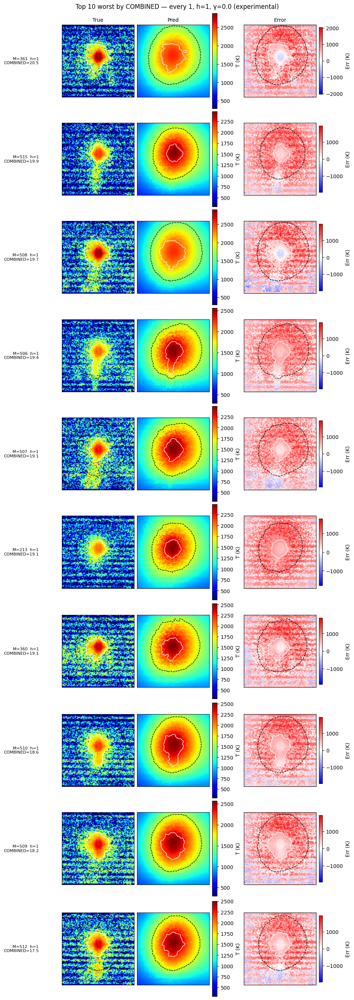

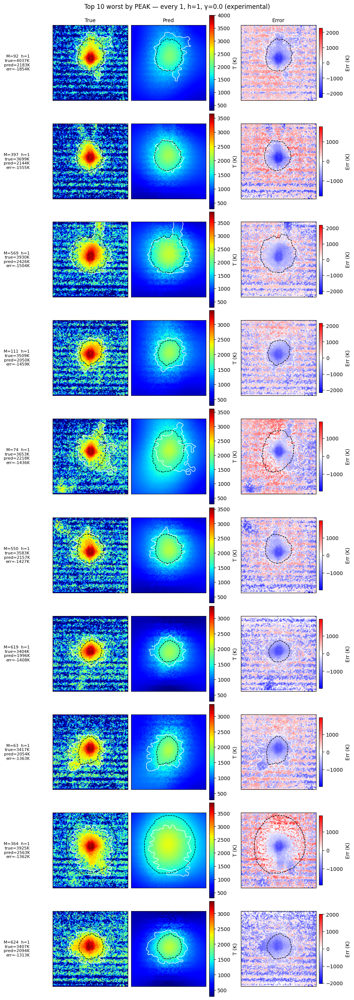

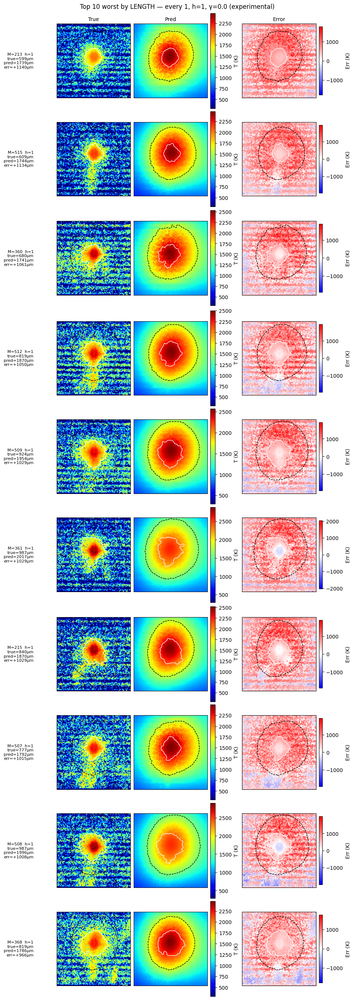

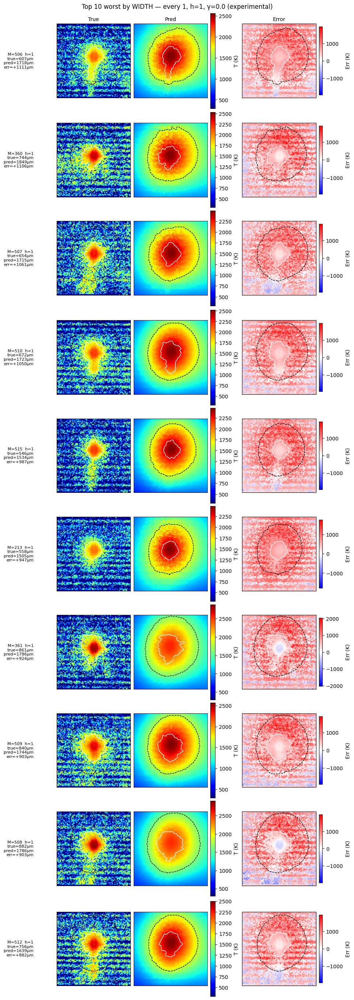

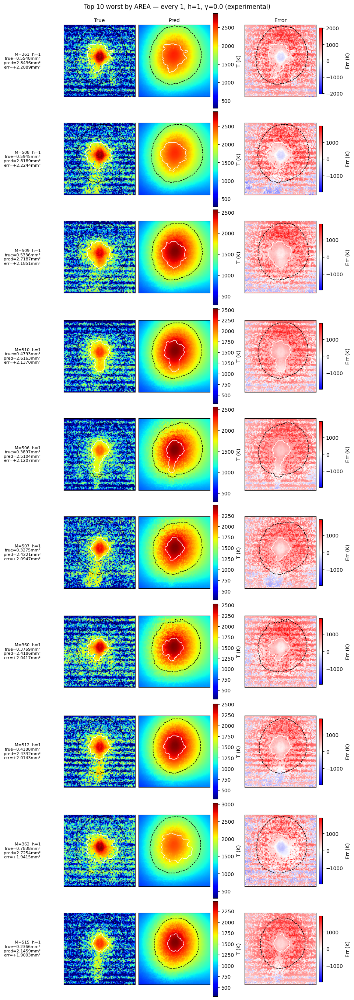

In [24]:
plot_worst("COMBINED")
plot_worst("PEAK")
plot_worst("LENGTH")
plot_worst("WIDTH")
plot_worst("AREA")

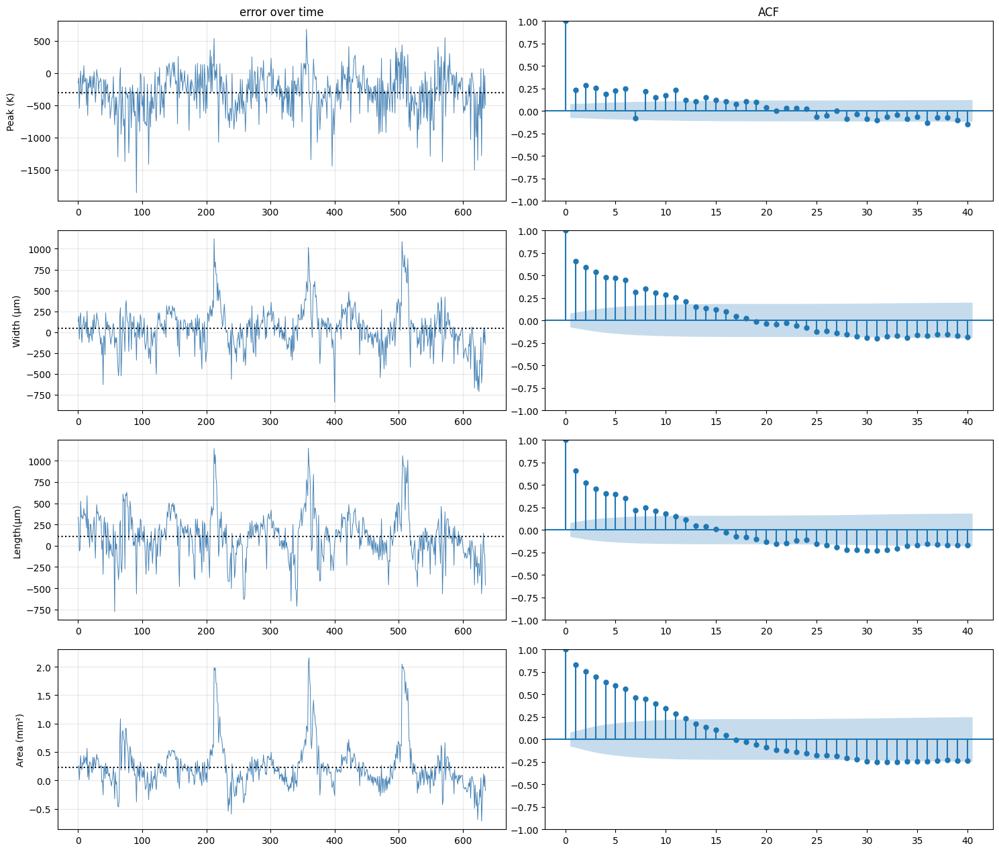

=== Ljung-Box test (H0 = white noise) ===
signal          LB_stat    p-value                 verdict
Peak (K)          397.8   5.92e-72  NOT white (autocorrelated)
Width (μm)       1481.0 4.767e-302  NOT white (autocorrelated)
Length(μm)       1040.7 8.103e-208  NOT white (autocorrelated)
Area (mm²)       2402.8          0  NOT white (autocorrelated)

=== Distribution (mean, std, skew, kurtosis, normality) ===
signal            mean       std    skew    kurt  Shapiro_p
Peak (K)       -299.75    332.43   -0.68    1.41  4.214e-09
Width (μm)       42.22    250.49    0.49    2.43  2.199e-12
Length(μm)      108.31    277.92    0.28    1.46  2.049e-08
Area (mm²)        0.23      0.40    2.00    6.28  2.518e-25


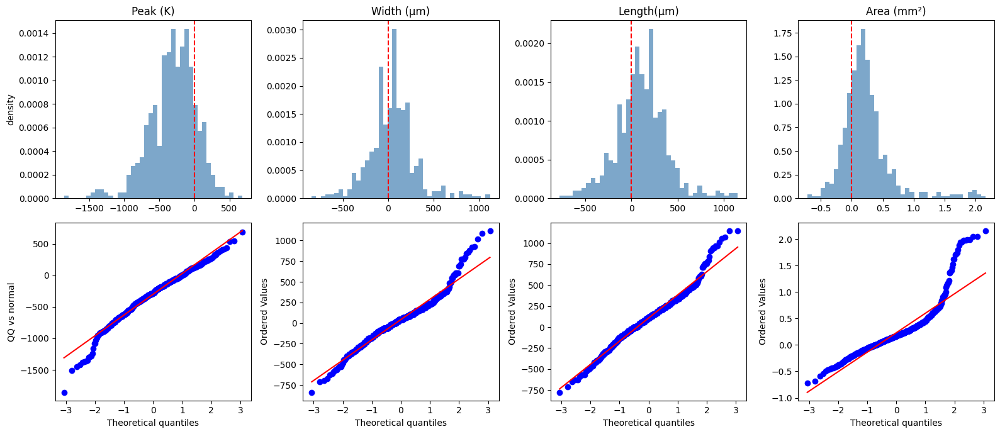

In [19]:
# =========================================================
# Error-signal analysis — are the residuals white noise?
#   ACF, PACF, Ljung-Box, histogram/QQ for peak/length/width/area errors.
#   (run AFTER the ranking cell so e_peak/e_l/e_w/e_area... exist, OR
#    use the SIGNED errors P_err/W_err/L_err/A_err from the fitness cell)
# =========================================================
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats
import pandas as pd

# --- use SIGNED errors (pred - true); white-noise test needs signed, not |err| ---
# if you have P_err,W_err,L_err,A_err from the fitness cell, use those.
# otherwise rebuild signed errors here from cached dicts:
signals = {
    "Peak (K)":   P_err,
    "Width (μm)": W_err,
    "Length(μm)": L_err,
    "Area (mm²)": A_err,
}

# --- time-series plots: signal + ACF + PACF per error ---
n=len(signals)
fig,axes=plt.subplots(n,2,figsize=(15,3.2*n))
for row,(name,sig) in enumerate(signals.items()):
    s=np.asarray(sig); s=s[~np.isnan(s)]
    axes[row,0].plot(s,lw=0.7,color='steelblue'); axes[row,0].axhline(s.mean(),color='k',ls=':')
    axes[row,0].set_ylabel(name); axes[row,0].set_title("error over time" if row==0 else "")
    axes[row,0].grid(alpha=0.3)
    plot_acf(s, ax=axes[row,1], lags=min(40,len(s)//2-1), alpha=0.05)
    axes[row,1].set_title("ACF" if row==0 else "")
    # plot_pacf(s, ax=axes[row,2], lags=min(40,len(s)//2-1), alpha=0.05, method='ywm')
    # axes[row,2].set_title("PACF" if row==0 else "")
plt.tight_layout(); fig.savefig(f"error_acf_{DATA_MODE}.png",dpi=150,bbox_inches="tight"); plt.show()

# --- Ljung-Box test (H0: white noise, no autocorrelation up to lag) ---
print("=== Ljung-Box test (H0 = white noise) ===")
print(f"{'signal':12s} {'LB_stat':>10s} {'p-value':>10s}  {'verdict':>22s}")
for name,sig in signals.items():
    s=np.asarray(sig); s=s[~np.isnan(s)]
    lb=acorr_ljungbox(s, lags=[20], return_df=True)
    stat=lb['lb_stat'].iloc[0]; pval=lb['lb_pvalue'].iloc[0]
    verdict = "white noise (p>0.05)" if pval>0.05 else "NOT white (autocorrelated)"
    print(f"{name:12s} {stat:>10.1f} {pval:>10.4g}  {verdict:>22s}")

# --- distribution / normality ---
print("\n=== Distribution (mean, std, skew, kurtosis, normality) ===")
print(f"{'signal':12s} {'mean':>9s} {'std':>9s} {'skew':>7s} {'kurt':>7s} {'Shapiro_p':>10s}")
for name,sig in signals.items():
    s=np.asarray(sig); s=s[~np.isnan(s)]
    sk=stats.skew(s); ku=stats.kurtosis(s)
    sp = stats.shapiro(s[:5000]).pvalue if len(s)>3 else np.nan   # shapiro caps at 5000
    print(f"{name:12s} {s.mean():>9.2f} {s.std():>9.2f} {sk:>7.2f} {ku:>7.2f} {sp:>10.4g}")

# --- histogram + QQ per signal ---
fig,axes=plt.subplots(2,n,figsize=(4*n,7))
for col,(name,sig) in enumerate(signals.items()):
    s=np.asarray(sig); s=s[~np.isnan(s)]
    axes[0,col].hist(s,bins=40,color='steelblue',alpha=0.7,density=True)
    axes[0,col].set_title(name); axes[0,col].axvline(0,color='r',ls='--')
    stats.probplot(s, dist="norm", plot=axes[1,col])
    axes[1,col].set_title("")
axes[0,0].set_ylabel("density"); axes[1,0].set_ylabel("QQ vs normal")
plt.tight_layout(); fig.savefig(f"error_dist_{DATA_MODE}.png",dpi=150,bbox_inches="tight"); plt.show()


ANALYZING: Peak


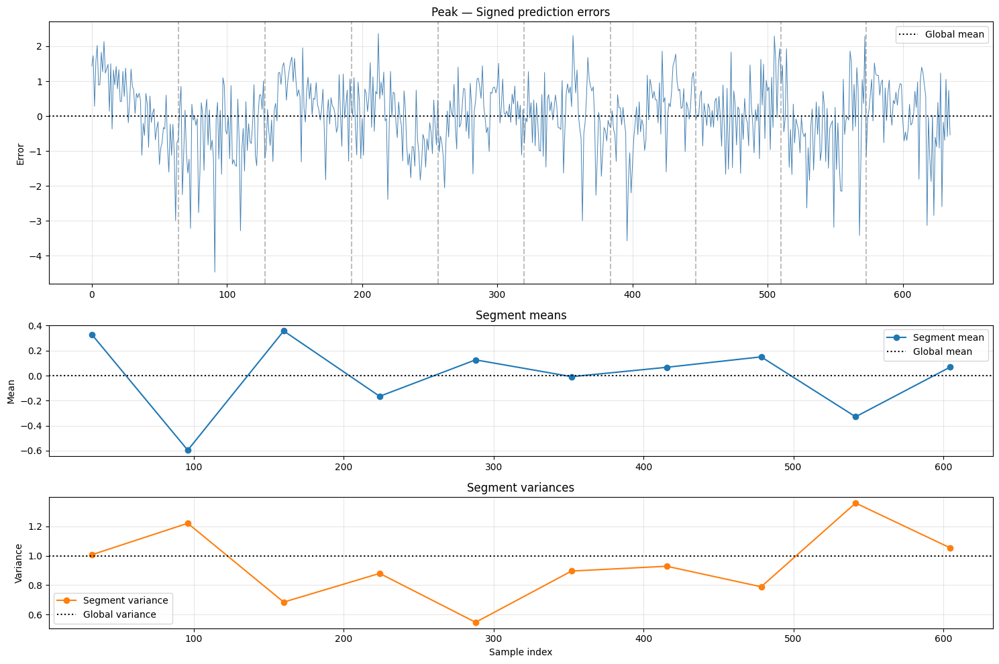

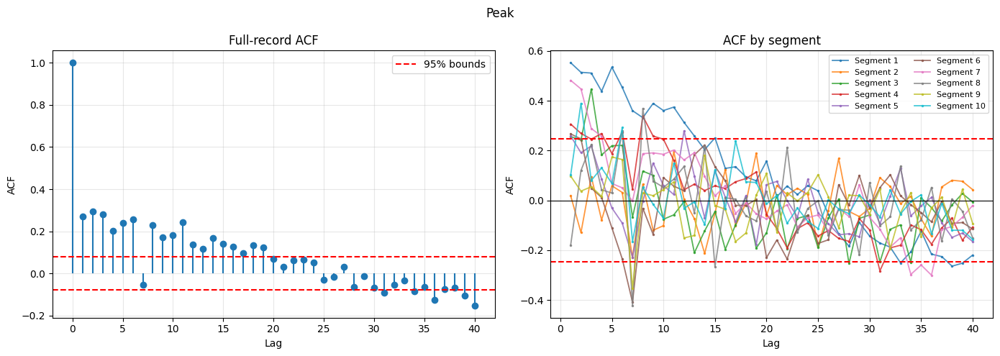

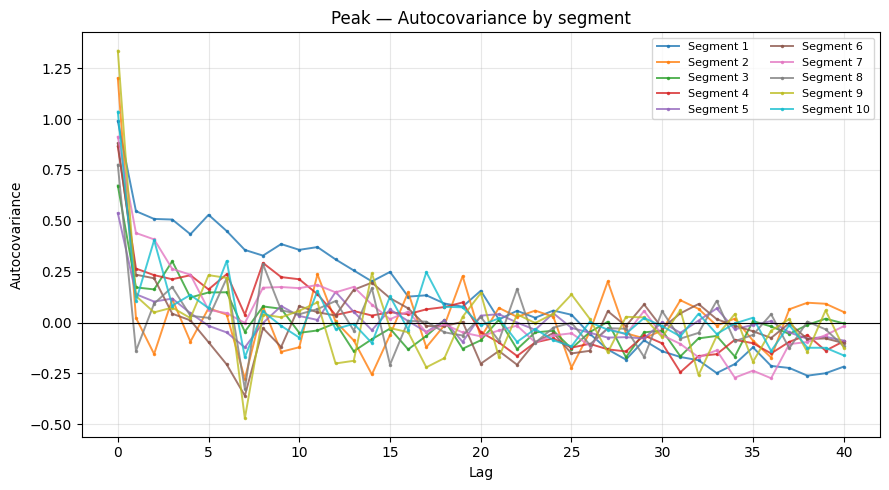


Segment statistics and hypothesis tests:
 Segment      Mean  Variance     ADF_p  KPSS_p      LB_p          Stationarity      Whiteness
       1    0.3292     1.006    0.9734    0.01 6.982e-29         Nonstationary Autocorrelated
       2   -0.5958     1.221 3.628e-11     0.1    0.3247 Stationary-compatible   Not rejected
       3    0.3573    0.6841    0.1336     0.1 0.0003202          Inconclusive Autocorrelated
       4   -0.1652    0.8795  0.004204    0.01 8.019e-05           Conflicting Autocorrelated
       5    0.1262    0.5466 1.618e-07 0.06938   0.06697 Stationary-compatible   Not rejected
       6 -0.008167    0.8954   0.05662     0.1  0.001983          Inconclusive Autocorrelated
       7    0.0667    0.9282   0.06367 0.01989   1.4e-05         Nonstationary Autocorrelated
       8    0.1501    0.7885    0.9883  0.0139 0.0002481         Nonstationary Autocorrelated
       9   -0.3287     1.358   0.02855     0.1    0.1583 Stationary-compatible   Not rejected
      10   0.06768

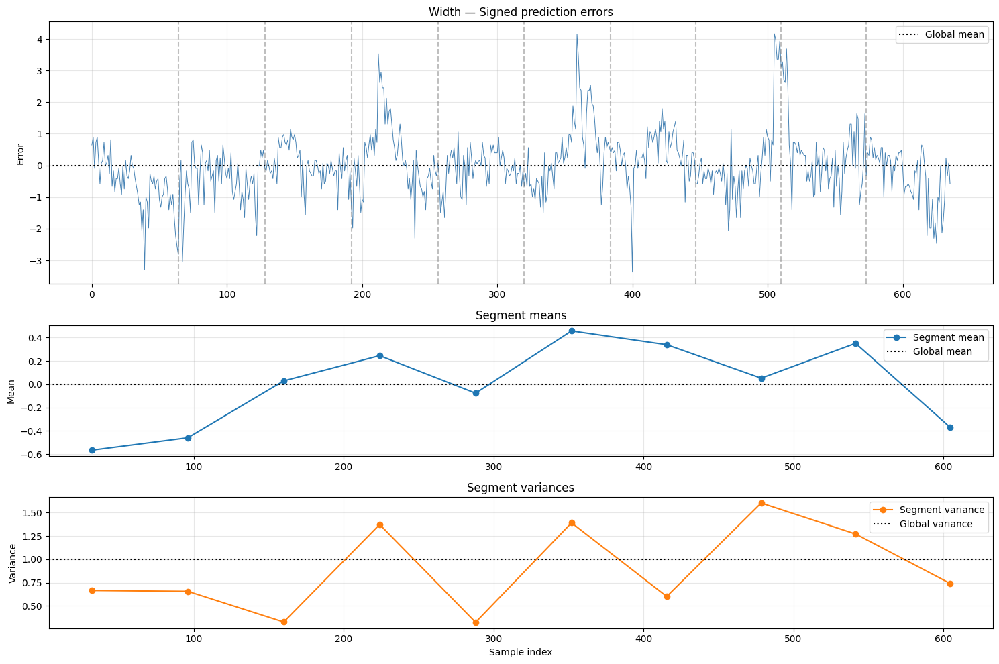

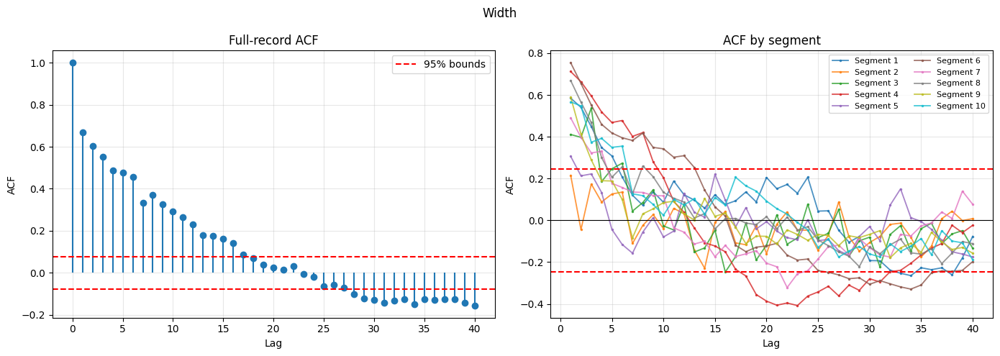

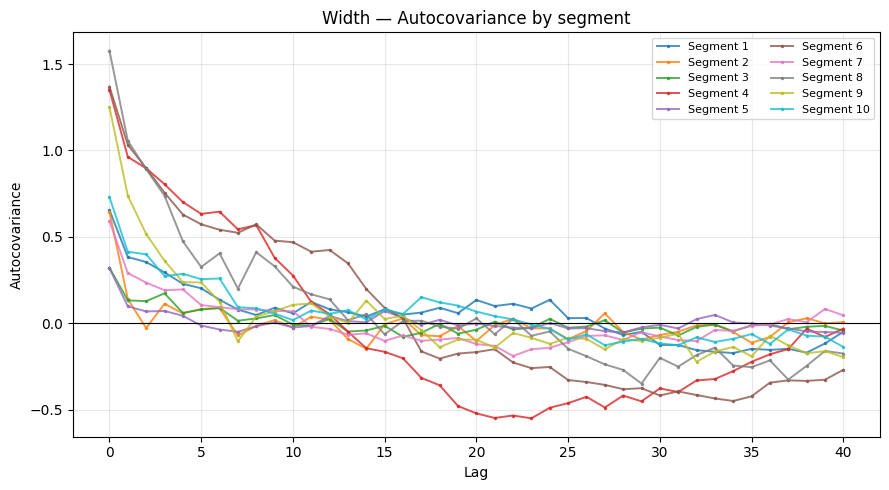


Segment statistics and hypothesis tests:
 Segment    Mean  Variance     ADF_p  KPSS_p      LB_p          Stationarity      Whiteness
       1 -0.5657    0.6652    0.3715    0.01 2.331e-11         Nonstationary Autocorrelated
       2  -0.459    0.6562 4.686e-09     0.1    0.4024 Stationary-compatible   Not rejected
       3 0.02923    0.3259      0.23 0.07518  4.39e-08          Inconclusive Autocorrelated
       4  0.2452     1.373     0.147     0.1   4.5e-35          Inconclusive Autocorrelated
       5 -0.0763    0.3231 8.039e-07     0.1    0.1998 Stationary-compatible   Not rejected
       6  0.4576     1.391    0.0375 0.01296 2.208e-31           Conflicting Autocorrelated
       7  0.3393    0.6009   0.02504     0.1 5.638e-07 Stationary-compatible Autocorrelated
       8 0.05284     1.603         1 0.01611 2.459e-11         Nonstationary Autocorrelated
       9  0.3508     1.271   0.02272 0.06862 0.0001452 Stationary-compatible Autocorrelated
      10 -0.3681    0.7406    0.1078  

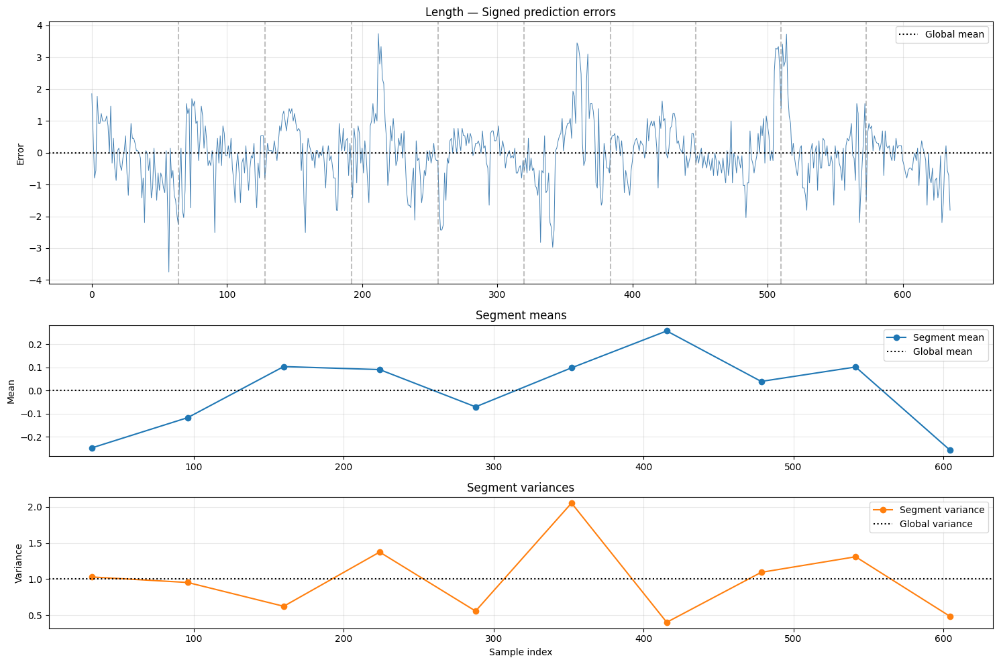

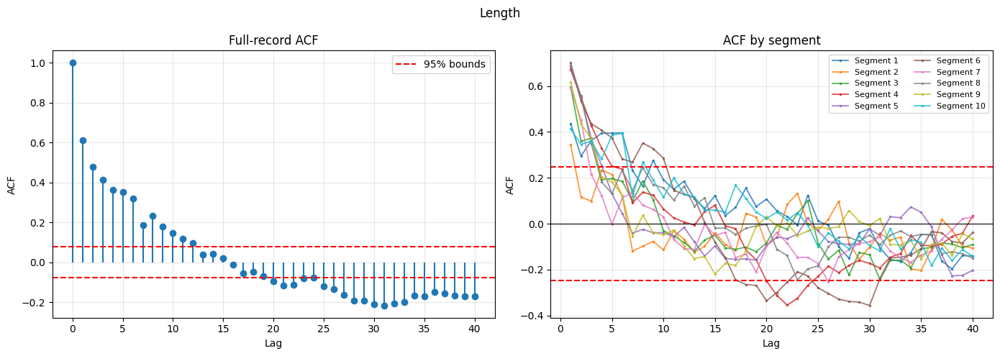

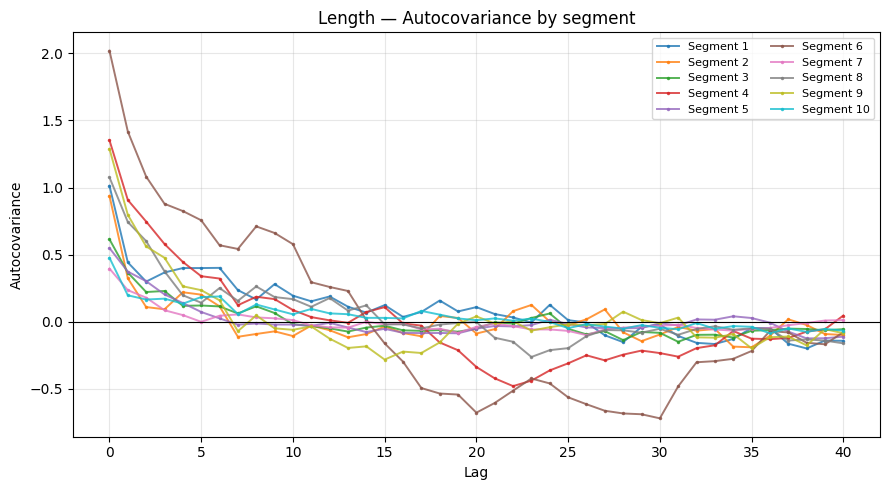


Segment statistics and hypothesis tests:
 Segment     Mean  Variance     ADF_p  KPSS_p      LB_p          Stationarity      Whiteness
       1  -0.2476     1.029    0.7675    0.01 1.923e-10         Nonstationary Autocorrelated
       2  -0.1167    0.9528 8.937e-07     0.1    0.1413 Stationary-compatible   Not rejected
       3   0.1041    0.6237    0.2876 0.09662 3.364e-06          Inconclusive Autocorrelated
       4  0.09102     1.374  0.008807 0.09641 1.587e-11 Stationary-compatible Autocorrelated
       5 -0.07007    0.5573   0.01085     0.1 3.543e-09 Stationary-compatible Autocorrelated
       6  0.09863     2.052   0.01738 0.06694 1.452e-23 Stationary-compatible Autocorrelated
       7   0.2582     0.402   0.02071     0.1 3.372e-05 Stationary-compatible Autocorrelated
       8  0.03989     1.093    0.9911 0.01961   1.2e-09         Nonstationary Autocorrelated
       9   0.1023     1.309  0.004924     0.1 1.994e-07 Stationary-compatible Autocorrelated
      10  -0.2575    0.4838 

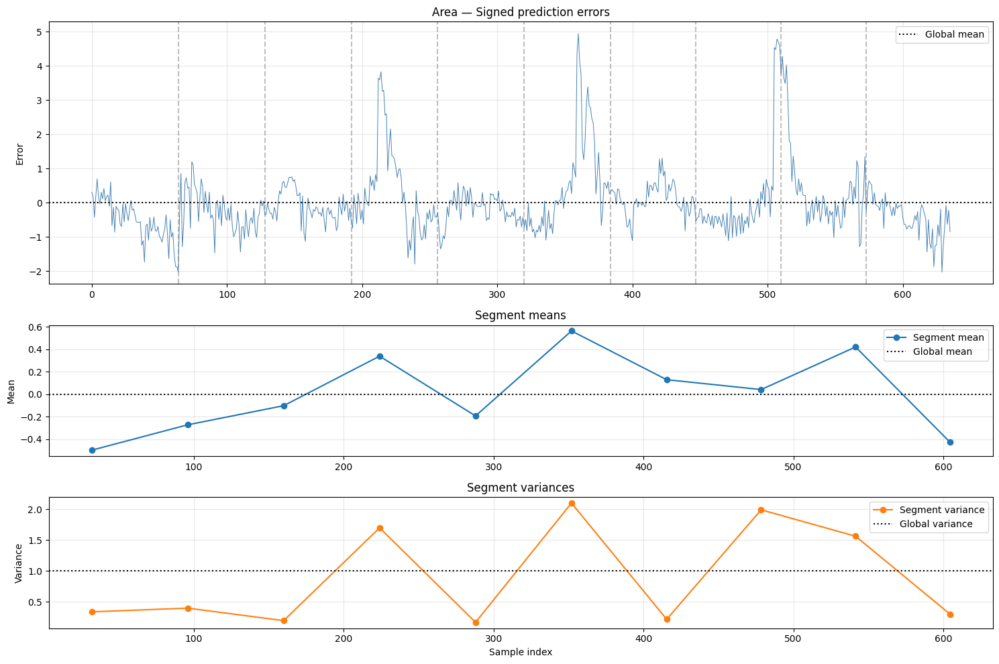

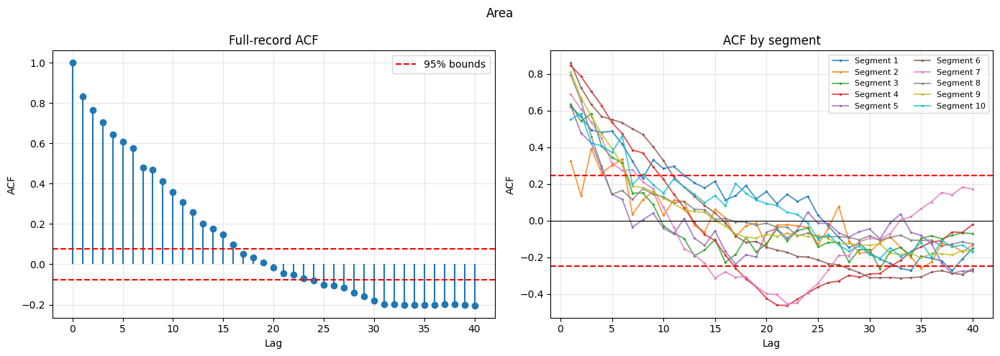

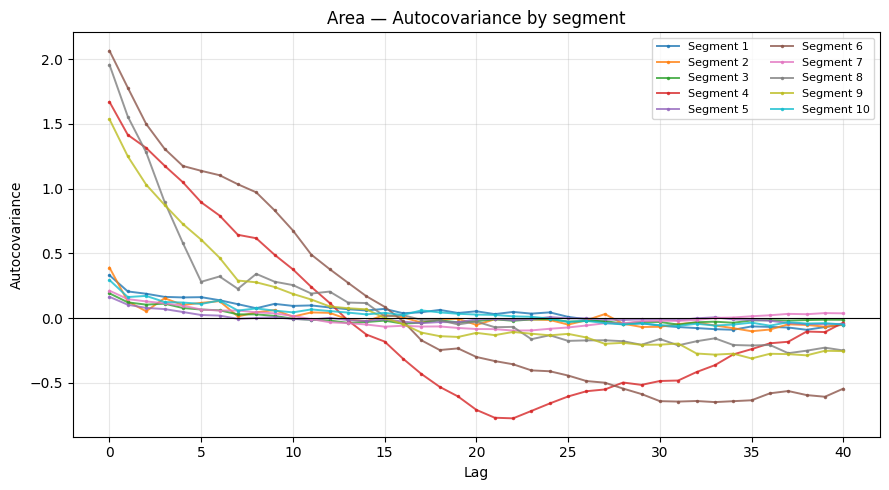


Segment statistics and hypothesis tests:
 Segment    Mean  Variance    ADF_p  KPSS_p      LB_p  Stationarity      Whiteness
       1 -0.4976    0.3362   0.8531    0.01 1.183e-25 Nonstationary Autocorrelated
       2 -0.2719    0.3966   0.6607 0.01692 0.0006527 Nonstationary Autocorrelated
       3 -0.1019     0.194   0.4157 0.09401 1.088e-16  Inconclusive Autocorrelated
       4  0.3387     1.697   0.4616 0.08391 2.708e-46  Inconclusive Autocorrelated
       5 -0.1927    0.1669  0.06284     0.1 2.987e-09  Inconclusive Autocorrelated
       6  0.5632     2.098   0.2145 0.01206 1.499e-41 Nonstationary Autocorrelated
       7  0.1294    0.2153   0.1622     0.1 2.547e-28  Inconclusive Autocorrelated
       8 0.04178     1.989        1 0.01829 3.991e-13 Nonstationary Autocorrelated
       9  0.4203     1.561 0.001108  0.0202 3.094e-20   Conflicting Autocorrelated
      10 -0.4269    0.2986   0.1964    0.01 7.157e-17 Nonstationary Autocorrelated

FULL RECORD SUMMARY
Signal       Mean  Std  

In [28]:

# =========================================================
# SEGMENTED RESIDUAL ANALYSIS — SYSTEM IDENTIFICATION
#
# Diagnostics:
#   1. Error time histories
#   2. Segment means and variances
#   3. Full-record and segment ACF
#   4. Segment autocovariance
#   5. ADF / KPSS stationarity tests
#   6. Ljung-Box whiteness tests
#   7. Distribution and normality
#
# Input: SIGNED prediction errors (predicted - actual)
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from scipy import stats
from statsmodels.tsa.stattools import (
    acf, acovf, adfuller, kpss
)
from statsmodels.stats.diagnostic import acorr_ljungbox

# ---------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------

N_SEGMENTS = 10
MAX_LAG = 40
LB_LAG = 20
ALPHA = 0.05
raw_signals = {
    "Peak":   np.asarray(P_err, dtype=float).ravel(),
    "Width":  np.asarray(W_err, dtype=float).ravel(),
    "Length": np.asarray(L_err, dtype=float).ravel(),
    "Area":   np.asarray(A_err, dtype=float).ravel(),
}

signals = {}

for name, s in raw_signals.items():
    mu = np.nanmean(s)
    sigma = np.nanstd(s, ddof=1)

    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError(f"Cannot standardize {name}: invalid std")

    signals[name] = (s - mu) / sigma

mode = globals().get("DATA_MODE", "data")

# ---------------------------------------------------------
# 2. FUNCTIONS
# ---------------------------------------------------------

def split_segments(s, n_segments):
    """Split the original sequence into contiguous segments."""
    return np.array_split(np.asarray(s), n_segments)


def valid_values(s):
    """Remove nonfinite observations for scalar statistics."""
    s = np.asarray(s, dtype=float)
    return s[np.isfinite(s)]


def segment_acf(s, max_lag):
    """ACF with fixed lag count; NaNs remain where unavailable."""
    result = np.full(max_lag + 1, np.nan)
    s = np.asarray(s, dtype=float)

    # Do not connect measurements across missing-data gaps.
    if not np.isfinite(s).all() or len(s) < 5:
        return result

    if np.var(s) < 1e-20:
        return result

    lag = min(max_lag, len(s) - 1)
    result[:lag + 1] = acf(s, nlags=lag, fft=True)
    return result


def segment_acov(s, max_lag):
    """Biased autocovariance estimate for each segment."""
    result = np.full(max_lag + 1, np.nan)
    s = np.asarray(s, dtype=float)

    if not np.isfinite(s).all() or len(s) < 5:
        return result

    lag = min(max_lag, len(s) - 1)
    result[:lag + 1] = acovf(s, nlag=lag, fft=True)
    return result


def statistical_tests(s, lb_lag):
    """Run ADF, KPSS, and Ljung-Box on one segment."""

    out = {
        "ADF_p": np.nan,
        "KPSS_p": np.nan,
        "LB_p": np.nan,
    }

    s = np.asarray(s, dtype=float)

    if not np.isfinite(s).all():
        return out

    if len(s) < 20 or np.var(s) < 1e-20:
        return out

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        try:
            out["ADF_p"] = adfuller(
                s, regression="c", autolag="AIC"
            )[1]
        except (ValueError, np.linalg.LinAlgError):
            pass

        try:
            out["KPSS_p"] = kpss(
                s, regression="c", nlags="auto"
            )[1]
        except (ValueError, np.linalg.LinAlgError):
            pass

        try:
            lag = min(lb_lag, len(s) - 1)
            out["LB_p"] = acorr_ljungbox(
                s, lags=[lag], return_df=True
            )["lb_pvalue"].iloc[0]
        except (ValueError, np.linalg.LinAlgError):
            pass

    return out


def stationarity_verdict(adf_p, kpss_p, alpha=0.05):
    if not (np.isfinite(adf_p) and np.isfinite(kpss_p)):
        return "Inconclusive"

    if adf_p < alpha and kpss_p > alpha:
        return "Stationary-compatible"
    elif adf_p >= alpha and kpss_p < alpha:
        return "Nonstationary"
    elif adf_p < alpha and kpss_p < alpha:
        return "Conflicting"
    else:
        return "Inconclusive"


# ---------------------------------------------------------
# 3. PROCESS EACH ERROR SIGNAL
# ---------------------------------------------------------

all_results = []
summary_results = []

for name, signal in signals.items():

    print("\n" + "=" * 65)
    print(f"ANALYZING: {name}")
    print("=" * 65)

    N = len(signal)

    if N < 40:
        print("Signal too short for the selected analysis.")
        continue

    segments = split_segments(signal, N_SEGMENTS)
    bounds = np.cumsum([0] + [len(x) for x in segments])

    seg_means = []
    seg_vars = []
    acf_matrix = []
    acov_matrix = []
    rows = []

    # -----------------------------------------------------
    # 3A. SEGMENT STATISTICS
    # -----------------------------------------------------

    for i, seg in enumerate(segments):

        clean = valid_values(seg)

        mean = np.mean(clean) if len(clean) else np.nan
        var = np.var(clean, ddof=1) if len(clean) > 1 else np.nan

        seg_means.append(mean)
        seg_vars.append(var)

        acf_matrix.append(segment_acf(seg, MAX_LAG))
        acov_matrix.append(segment_acov(seg, MAX_LAG))

        tests = statistical_tests(seg, LB_LAG)

        row = {
            "Signal": name,
            "Segment": i + 1,
            "Start": bounds[i],
            "End": bounds[i + 1] - 1,
            "N_valid": len(clean),
            "Mean": mean,
            "Variance": var,
            "Std": np.sqrt(var),
            **tests,
        }

        row["Stationarity"] = stationarity_verdict(
            row["ADF_p"], row["KPSS_p"], ALPHA
        )

        if np.isnan(row["LB_p"]):
            row["Whiteness"] = "Unavailable"
        elif row["LB_p"] < ALPHA:
            row["Whiteness"] = "Autocorrelated"
        else:
            row["Whiteness"] = "Not rejected"

        rows.append(row)
        all_results.append(row)

    df = pd.DataFrame(rows)

    acf_matrix = np.asarray(acf_matrix)
    acov_matrix = np.asarray(acov_matrix)

    # -----------------------------------------------------
    # 3B. PLOT SEGMENT MEANS AND VARIANCES
    # -----------------------------------------------------

    fig, axes = plt.subplots(
        3, 1, figsize=(15, 10),
        gridspec_kw={"height_ratios": [2, 1, 1]}
    )

    t = np.arange(N)

    axes[0].plot(t, signal, lw=0.7, color="steelblue")

    for b in bounds[1:-1]:
        axes[0].axvline(b, color="gray", ls="--", alpha=0.5)

    axes[0].axhline(
        np.nanmean(signal), color="black",
        ls=":", label="Global mean"
    )

    axes[0].set_title(f"{name} — Signed prediction errors")
    axes[0].set_ylabel("Error")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    centers = (bounds[:-1] + bounds[1:]) / 2

    axes[1].plot(
        centers, seg_means, "o-",
        color="tab:blue", label="Segment mean"
    )
    axes[1].axhline(
        np.nanmean(signal), color="black",
        ls=":", label="Global mean"
    )
    axes[1].set_ylabel("Mean")
    axes[1].set_title("Segment means")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    axes[2].plot(
        centers, seg_vars, "o-",
        color="tab:orange", label="Segment variance"
    )
    axes[2].axhline(
        np.nanvar(signal, ddof=1), color="black",
        ls=":", label="Global variance"
    )
    axes[2].set_ylabel("Variance")
    axes[2].set_xlabel("Sample index")
    axes[2].set_title("Segment variances")
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    fig.savefig(
        f"segments_{name.split()[0]}_{mode}.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()

    # -----------------------------------------------------
# 3C. FULL ACF AND SEGMENT ACF — NO HEATMAP
# -----------------------------------------------------

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    whole_acf = segment_acf(signal, MAX_LAG)
    lag_axis = np.arange(MAX_LAG + 1)

# Full-record ACF
    axes[0].stem(lag_axis, whole_acf, basefmt=" ")

    conf = 1.96 / np.sqrt(N)
    axes[0].axhline(conf, ls="--", color="red", label="95% bounds")
    axes[0].axhline(-conf, ls="--", color="red")

    axes[0].set_title("Full-record ACF")
    axes[0].set_xlabel("Lag")
    axes[0].set_ylabel("ACF")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

# Segment ACF curves
    for i, values in enumerate(acf_matrix):
        axes[1].plot(
            lag_axis[1:], values[1:],
            lw=1.3, marker=".",
            markersize=3, alpha=0.8,
            label=f"Segment {i+1}"
        )

# Approximate bounds based on segment lengths
    seg_n = min(len(s) for s in segments)
    seg_conf = 1.96 / np.sqrt(seg_n)

    axes[1].axhline(seg_conf, ls="--", color="red")
    axes[1].axhline(-seg_conf, ls="--", color="red")
    axes[1].axhline(0, color="black", lw=0.8)

    axes[1].set_title("ACF by segment")
    axes[1].set_xlabel("Lag")
    axes[1].set_ylabel("ACF")
    axes[1].grid(alpha=0.3)
    axes[1].legend(fontsize=8, ncol=2)

    plt.suptitle(name)
    plt.tight_layout()

    fig.savefig(
        f"segment_acf_{name.split()[0]}_{mode}.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()

    # -----------------------------------------------------
    # 3D. SEGMENT AUTOCOVARIANCE — NO HEATMAP
    # -----------------------------------------------------

    fig, ax = plt.subplots(figsize=(9, 5))

    for i, values in enumerate(acov_matrix):
        ax.plot(
            lag_axis, values,
            lw=1.4, marker=".",
            markersize=3, alpha=0.8,
            label=f"Segment {i+1}"
        )

    ax.axhline(0, color="black", lw=0.8)

    ax.set_title(f"{name} — Autocovariance by segment")
    ax.set_xlabel("Lag")
    ax.set_ylabel("Autocovariance")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=2)

    plt.tight_layout()

    fig.savefig(
        f"segment_acov_{name.split()[0]}_{mode}.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()

    # -----------------------------------------------------
    # 3E. STATISTICAL TEST RESULTS
    # -----------------------------------------------------

    print("\nSegment statistics and hypothesis tests:")
    print(df[[
        "Segment", "Mean", "Variance",
        "ADF_p", "KPSS_p", "LB_p",
        "Stationarity", "Whiteness"
    ]].to_string(index=False, float_format=lambda x: f"{x:.4g}"))

    # -----------------------------------------------------
    # 3F. FULL-RECORD SUMMARY
    # -----------------------------------------------------

    tests = statistical_tests(signal, LB_LAG)
    clean = valid_values(signal)

    summary_results.append({
        "Signal": name,
        "Mean": np.mean(clean),
        "Std": np.std(clean, ddof=1),
        "Skew": stats.skew(clean),
        "Kurtosis": stats.kurtosis(clean),
        **tests,
        "Stationary_segments": int(
            (df["Stationarity"] == "Stationary-compatible").sum()
        ),
        "Autocorrelated_segments": int(
            (df["Whiteness"] == "Autocorrelated").sum()
        )
    })

# ---------------------------------------------------------
# 4. SAVE RESULTS
# ---------------------------------------------------------

segment_results = pd.DataFrame(all_results)
summary_results = pd.DataFrame(summary_results)

segment_results.to_csv(
    f"segment_residual_tests_{mode}.csv", index=False
)

summary_results.to_csv(
    f"full_residual_summary_{mode}.csv", index=False
)

print("\n" + "=" * 65)
print("FULL RECORD SUMMARY")
print("=" * 65)

print(summary_results.to_string(
    index=False, float_format=lambda x: f"{x:.4g}"
))

print("\nAnalysis completed.")


Anchor frequency: 142.857 Hz


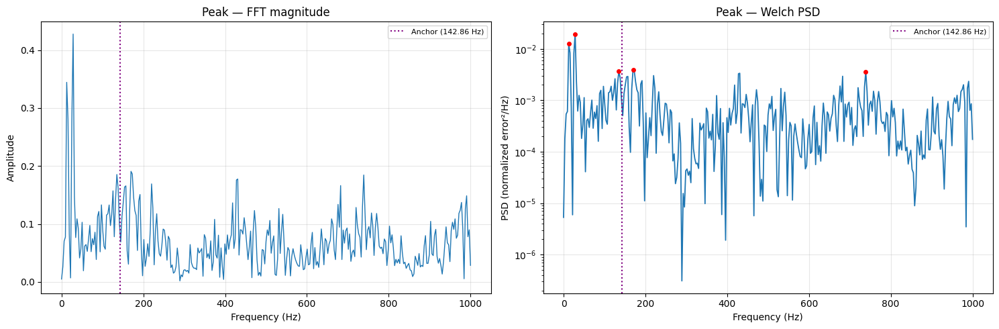

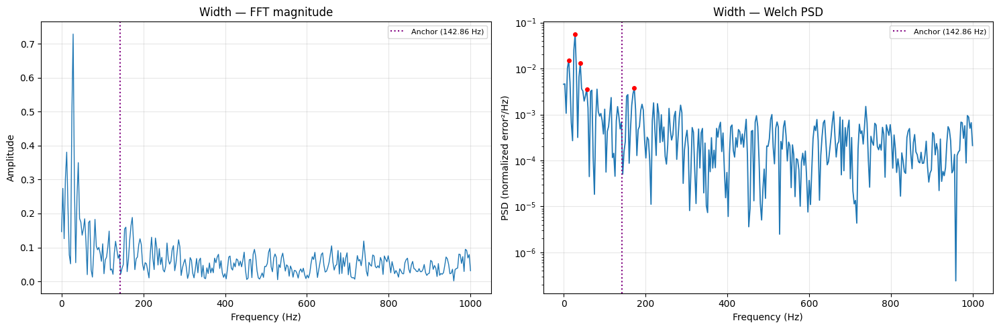

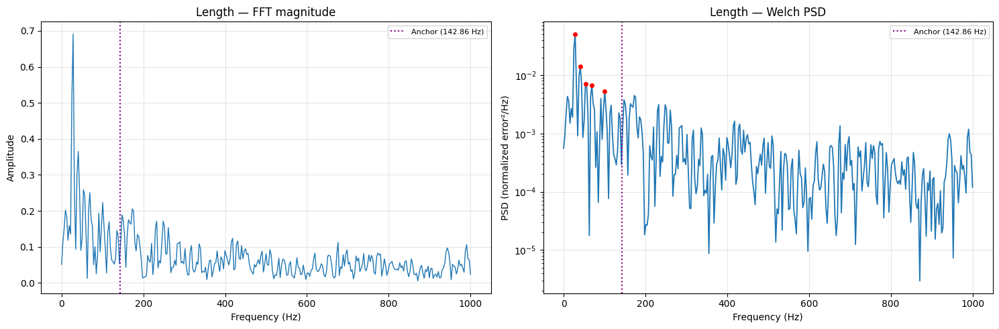

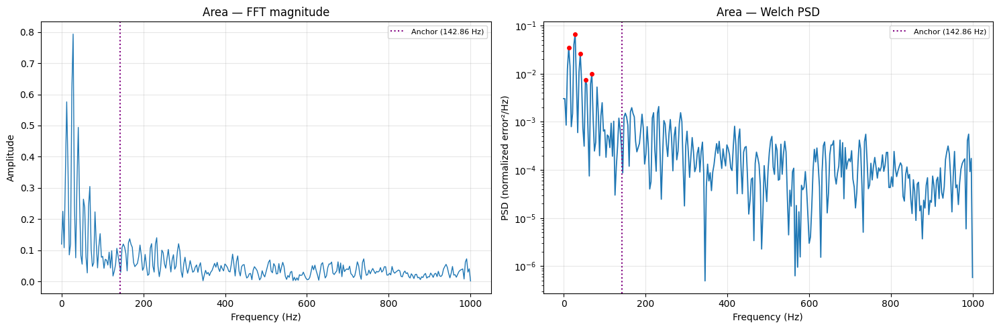

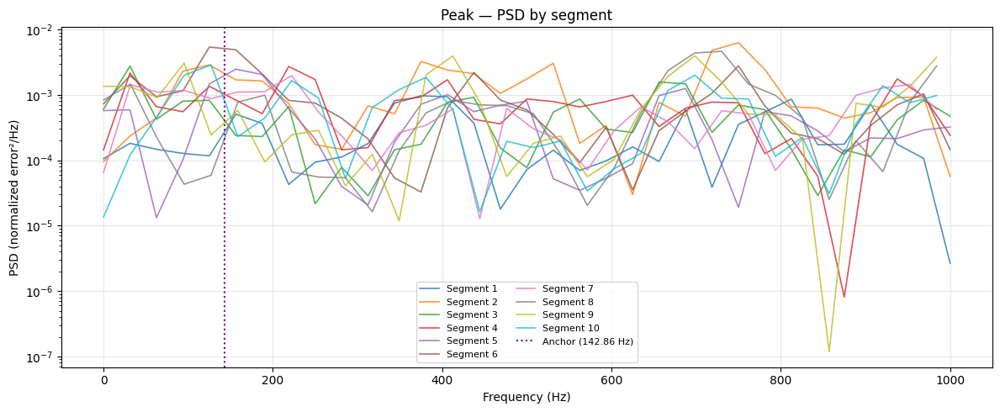

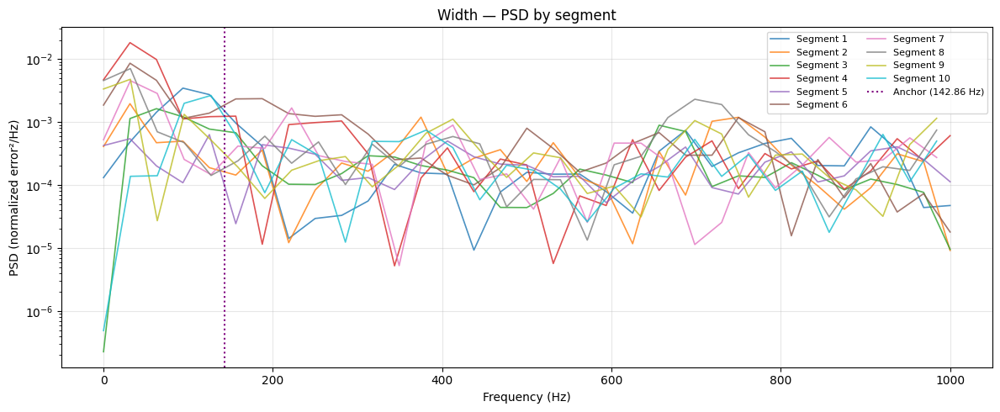

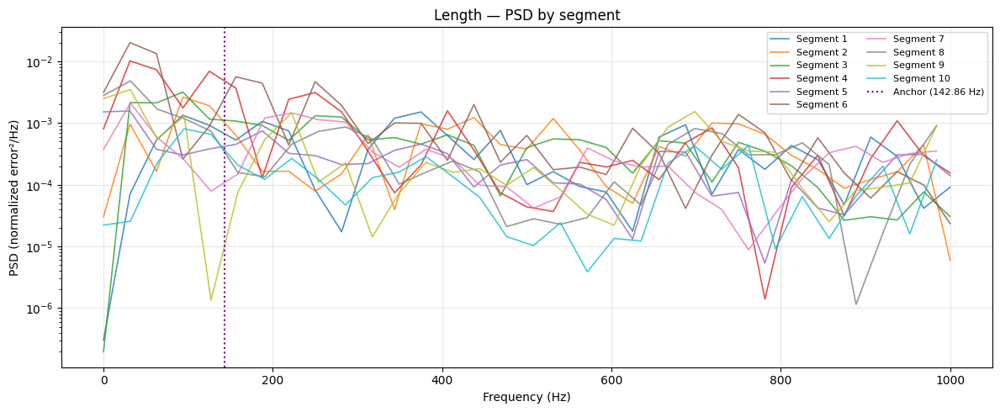

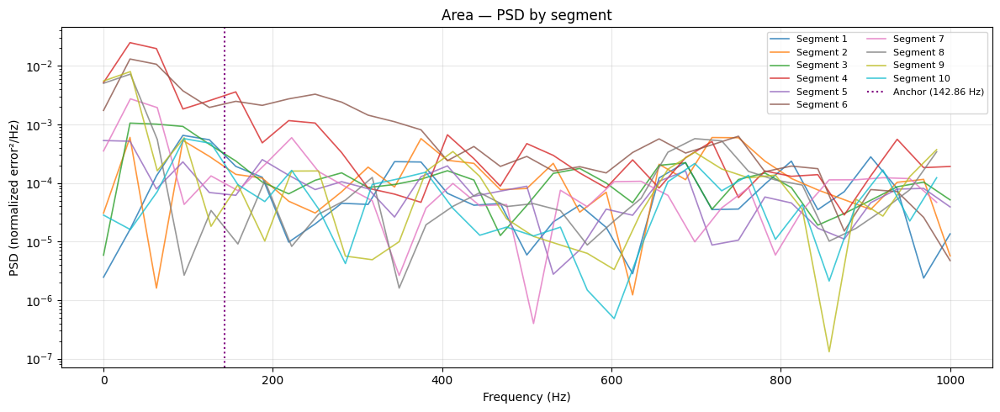


=== DOMINANT FREQUENCIES ===
Signal  Frequency_Hz       PSD
  Peak        28.302  0.019397
  Peak        12.579  0.012538
  Peak        169.81 0.0038572
  Peak        135.22 0.0036396
  Peak        738.99 0.0036121
 Width        28.302  0.056217
 Width        12.579  0.015198
 Width        40.881   0.01299
 Width        172.96 0.0037535
 Width        56.604 0.0035873
Length        28.302   0.05061
Length        40.881  0.014163
Length        53.459 0.0071311
Length        69.182 0.0066392
Length        100.63 0.0052463
  Area        28.302   0.06672
  Area        12.579  0.034997
  Area        40.881  0.025918
  Area        69.182 0.0098425
  Area        53.459 0.0073743

Frequency-domain analysis completed.


In [29]:

# =========================================================
# FREQUENCY-DOMAIN ANALYSIS OF PINN RESIDUALS
#
# FFT, Welch PSD, segmented PSD, dominant frequencies
# and comparison with scan turns / PINN anchoring.
#
# Run after the normalization cell (signals exists).
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import (
    welch, periodogram, find_peaks, detrend
)

# ---------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------

FS = 2000.0         # Hz: REPLACE with actual error sampling rate
N_SEGMENTS = 10
N_DOMINANT = 5

# Use None if unknown.
TURN_IDX = None     # Sample indices of direction changes
ANCHOR_STEPS = 14   # Set None if anchoring is not used

# signals should contain GLOBALLY normalized signed errors.
# Example:
#
# signals = {
#     "Peak": normalized_P_err,
#     "Width": normalized_W_err,
#     "Length": normalized_L_err,
#     "Area": normalized_A_err,
# }

# ---------------------------------------------------------
# 2. EXPECTED FREQUENCIES
# ---------------------------------------------------------

f_turn = None
f_cycle = None
f_anchor = None

if TURN_IDX is not None:
    turns = np.unique(np.asarray(TURN_IDX, dtype=int))
    if len(turns) >= 2:
        turn_dt = np.diff(turns) / FS
        turn_dt = turn_dt[turn_dt > 0]

        if len(turn_dt):
            f_turn = 1 / np.median(turn_dt)
            f_cycle = f_turn / 2

            print(f"Turn-event rate: {f_turn:.3f} Hz")
            print(f"Alternating scan cycle: {f_cycle:.3f} Hz")

if ANCHOR_STEPS is not None:
    f_anchor = FS / ANCHOR_STEPS
    print(f"Anchor frequency: {f_anchor:.3f} Hz")

# ---------------------------------------------------------
# 3. FUNCTIONS
# ---------------------------------------------------------

def get_psd(signal, fs):
    """Welch PSD on a uniformly sampled residual record."""

    s = np.asarray(signal, dtype=float).ravel()

    if not np.all(np.isfinite(s)):
        raise ValueError(
            "Signal contains NaN/Inf. Handle missing samples "
            "without compressing the time axis."
        )

    s = detrend(s, type="constant")

    nperseg = min(2048, len(s))

    f, pxx = welch(
        s,
        fs=fs,
        window="hann",
        nperseg=nperseg,
        noverlap=nperseg // 2,
        detrend="linear",
        scaling="density"
    )

    return f, pxx


def get_fft(signal, fs):
    """One-sided amplitude spectrum of a Hann-windowed signal."""

    s = np.asarray(signal, dtype=float).ravel()
    s = detrend(s, type="constant")

    N = len(s)
    window = np.hanning(N)
    spectrum = np.fft.rfft(s * window)

    frequencies = np.fft.rfftfreq(N, d=1/fs)

    amplitude = 2 * np.abs(spectrum) / np.sum(window)

    amplitude[0] /= 2
    if N % 2 == 0:
        amplitude[-1] /= 2

    return frequencies, amplitude


def dominant_peaks(f, psd, n=5):
    """Find strongest local spectral peaks, excluding DC."""

    valid = (f > 0) & np.isfinite(psd)
    f0 = f[valid]
    p0 = psd[valid]

    if len(p0) < 3:
        return []

    peaks, _ = find_peaks(p0)

    if not len(peaks):
        return []

    ranked = peaks[np.argsort(p0[peaks])[::-1]]

    return [(f0[i], p0[i]) for i in ranked[:n]]


def add_expected_frequencies(ax):
    """Mark scan and anchoring frequencies on the plot."""

    if f_turn is not None:
        ax.axvline(
            f_turn, color="red", ls="--",
            label=f"Turn rate ({f_turn:.2f} Hz)"
        )

    if f_cycle is not None:
        ax.axvline(
            f_cycle, color="green", ls="--",
            label=f"Scan cycle ({f_cycle:.2f} Hz)"
        )

    if f_anchor is not None:
        ax.axvline(
            f_anchor, color="purple", ls=":",
            label=f"Anchor ({f_anchor:.2f} Hz)"
        )


# ---------------------------------------------------------
# 4. FFT AND PSD FOR ALL RESIDUAL SIGNALS
# ---------------------------------------------------------

peak_results = []

for name, signal in signals.items():

    signal = np.asarray(signal, dtype=float).ravel()

    if not np.all(np.isfinite(signal)):
        raise ValueError(f"{name} contains NaN/Inf")

    f_fft, amplitude = get_fft(signal, FS)
    f_psd, psd = get_psd(signal, FS)

    peaks = dominant_peaks(f_psd, psd, N_DOMINANT)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # FFT magnitude
    axes[0].plot(f_fft, amplitude, lw=1.0)
    axes[0].set_title(f"{name} — FFT magnitude")
    axes[0].set_xlabel("Frequency (Hz)")
    axes[0].set_ylabel("Amplitude")
    axes[0].grid(alpha=0.3)

    # Welch PSD
    axes[1].semilogy(f_psd, np.maximum(psd, 1e-20), lw=1.3)

    for freq, power in peaks:
        axes[1].plot(freq, power, "ro", ms=4)

        peak_results.append({
            "Signal": name,
            "Frequency_Hz": freq,
            "PSD": power
        })

    axes[1].set_title(f"{name} — Welch PSD")
    axes[1].set_xlabel("Frequency (Hz)")
    axes[1].set_ylabel("PSD (normalized error²/Hz)")
    axes[1].grid(alpha=0.3)

    for ax in axes:
        add_expected_frequencies(ax)
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# 5. SEGMENTED PSD
# ---------------------------------------------------------

for name, signal in signals.items():

    s = np.asarray(signal, dtype=float).ravel()

    segments = np.array_split(s, N_SEGMENTS)

    fig, ax = plt.subplots(figsize=(12, 5))

    for i, seg in enumerate(segments):

        if len(seg) < 16:
            continue

        f, pxx = get_psd(seg, FS)

        ax.semilogy(
            f,
            np.maximum(pxx, 1e-20),
            lw=1.2,
            alpha=0.8,
            label=f"Segment {i+1}"
        )

    add_expected_frequencies(ax)

    ax.set_title(f"{name} — PSD by segment")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (normalized error²/Hz)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=2)

    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# 6. DOMINANT FREQUENCY TABLE
# ---------------------------------------------------------

frequency_table = pd.DataFrame(peak_results)

print("\n=== DOMINANT FREQUENCIES ===")

if not frequency_table.empty:
    print(frequency_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.5g}"
    ))

    frequency_table.to_csv(
        f"residual_frequencies_{globals().get('DATA_MODE', 'data')}.csv",
        index=False
    )

print("\nFrequency-domain analysis completed.")


# Debug

In [38]:
K0 = 360   # <- a frame index at the turnaround
print(f"{'k':>5} {'vx':>8} {'vy':>8} {'|v|':>7} {'P':>7} {'n_idx':>6} {'pk_true':>8} {'pk_pred':>8}")
for k in range(max(1,K0-4), min(len(tPath),K0+5)):
    if IS_EXP:
        dt=float(tPath[k]-tPath[k-1]); vx=(xPath[k]-xPath[k-1])/dt; vy=(yPath[k]-yPath[k-1])/dt
        P=float(Power[k-1]) if Power.size>1 else float(Power[0])
    else:
        vx,vy=get_safe_velocity(k,vx_path,vy_path); P=float(Power[k]) if Power.size>1 else float(Power[0])
    T_s,idx=_advance(k-1,_seed(k-1))                      # one-step from TRUE k-1
    pt=np.clip(T_nodes_time[idx,k],Tamb,None).max() if len(idx) else np.nan
    pp=(T_s[idx]+Tamb).max() if len(idx) else np.nan
    print(f"{k:>5} {vx:>8.3f} {vy:>8.3f} {np.hypot(vx,vy):>7.3f} {P:>7.1f} {len(idx):>6} {pt:>8.0f} {pp:>8.0f}")

print([get_safe_velocity(k,vx_path,vy_path) for k in (359,360,361)])

    k       vx       vy     |v|       P  n_idx  pk_true  pk_pred
  356    0.000   -0.602   0.602   190.0  12544     2599     2574
  357    0.000   -0.602   0.602   190.0  12544     1961     2644
  358    0.000   -0.602   0.602   190.0  12544     2141     2507
  359    0.000   -0.601   0.601   190.0  12544     2433     2578
  360   -0.180    0.220   0.285   190.0  12544     2452      295
  361    0.000    0.602   0.602   190.0  12544     2910     2571
  362    0.000    0.602   0.602   190.0  12544     3055     2586
  363    0.000    0.602   0.602   190.0  12544     3144     2583
  364    0.000    0.602   0.602   190.0  12544     3925     2579
[(np.float64(0.0), np.float64(-0.60133381869773)), (np.float64(-0.18040247909199522), np.float64(0.22048891129032258)), (np.float64(0.0), np.float64(0.6017661256575801))]


In [43]:
_log=[]; _orig_step_at=_step_at
def _step_at(xL,yL,P,t,vx,vy,idx,prev):
    _log.append((vx,vy,P)); return _orig_step_at(xL,yL,P,t,vx,vy,idx,prev)
def _sv(a,b):
    d=max(float(tPath[b]-tPath[a]),1e-12); return np.array([(xPath[b]-xPath[a])/d,(yPath[b]-yPath[a])/d])
def _cos(u,w): return float(u@w)/(np.linalg.norm(u)*np.linalg.norm(w)+1e-12)
for k in range(2, len(tPath)-1):
    m=k-1; vs=_sv(m,k); v0=_sv(m-1,m); v1=_sv(k,k+1)
    turn = not (_cos(vs,v0)>=TURN_COS or _cos(vs,v1)>=TURN_COS)
    _log.clear(); T_s,idx=_advance(m,_seed(m))
    pt=np.clip(T_nodes_time[idx,k],Tamb,None).max(); pp=(T_s[idx]+Tamb).max()
    if turn or pp < Tamb+100:
        used=sorted(set((round(a[0],2),round(a[1],2)) for a in _log)); Ps=sorted(set(round(a[2],1) for a in _log))
        print(f"{'FAIL' if pp<Tamb+100 else ' ok '} {m}->{k} turn={turn!s:5} seg={np.round(vs,2)} "
              f"prev={np.round(v0,2)} next={np.round(v1,2)} cos(prev)={_cos(vs,v0):+.2f} cos(next)={_cos(vs,v1):+.2f} "
              f"v_used={used} P={Ps} pk_true={pt:.0f} pk_pred={pp:.0f}")
_step_at=_orig_step_at

FAIL 65->66 turn=False seg=[-0.16  0.44] prev=[-0.02 -0.58] next=[0.  0.6] cos(prev)=-0.93 cos(next)=+0.94 v_used=[(-0.16, 0.44)] P=[190.0] pk_true=2302 pk_pred=358
 ok  138->139 turn=True  seg=[-0.18 -0.1 ] prev=[0.  0.6] next=[ 0.  -0.6] cos(prev)=-0.49 cos(next)=+0.49 v_used=[(0.0, -0.6), (0.0, 0.6)] P=[190.0] pk_true=2132 pk_pred=2246
 ok  179->180 turn=True  seg=[0. 0.] prev=[ 0.  -0.6] next=[ 0.  -0.6] cos(prev)=+0.00 cos(next)=+0.00 v_used=[(0.0, -0.6)] P=[190.0] pk_true=2371 pk_pred=2177
 ok  212->213 turn=True  seg=[-0.18 -0.26] prev=[ 0.  -0.6] next=[0.  0.6] cos(prev)=+0.82 cos(next)=-0.82 v_used=[(0.0, -0.6), (0.0, 0.6)] P=[190.0] pk_true=2059 pk_pred=2599
FAIL 286->287 turn=False seg=[-0.1 -0.5] prev=[-0.08  0.52] next=[ 0.  -0.6] cos(prev)=-0.94 cos(next)=+0.98 v_used=[(-0.1, -0.5)] P=[190.0] pk_true=2069 pk_pred=295
 ok  359->360 turn=True  seg=[-0.18  0.22] prev=[ 0.  -0.6] next=[0.  0.6] cos(prev)=-0.77 cos(next)=+0.77 v_used=[(0.0, -0.6), (0.0, 0.6)] P=[190.0] pk_true

Length: using 636 of 636 frames (0 dropped: NaN or true value = 0)
N=636   true: mean 921.2 μm, std 269.5 μm   pred: mean 1029 μm, std 257.3 μm
MAPE 26.51%   RMSE 298.3 μm   bias +108.3 μm   corr ρ 0.444   RangeRatio σp/σt 0.95

R² = -0.225 = 1 - [ bias 0.162 + scale 0.002 + correlation 1.061 ]   (check: -0.225)
   bias term        : constant offset vs the truth's spread
   scale term       : prediction too flat (σp<σt) or too noisy (σp>σt)
   correlation term : prediction doesn't move with the truth (ρ<1)
worst  1% frames (   6) carry  12.1% of SS_res;  R² without them = -0.083
worst  5% frames (  32) carry  38.1% of SS_res;  R² without them = 0.182
worst 10% frames (  64) carry  52.8% of SS_res;  R² without them = 0.290

worst 10 frames:
   t (ms)      true      pred       err
  179.520     679.9      1828     +1149
  106.216     599.2      1746     +1147
  107.213     840.3      1912     +1071
  252.824     776.8      1837     +1060
  256.813     609.2      1618     +1008
  106.714 

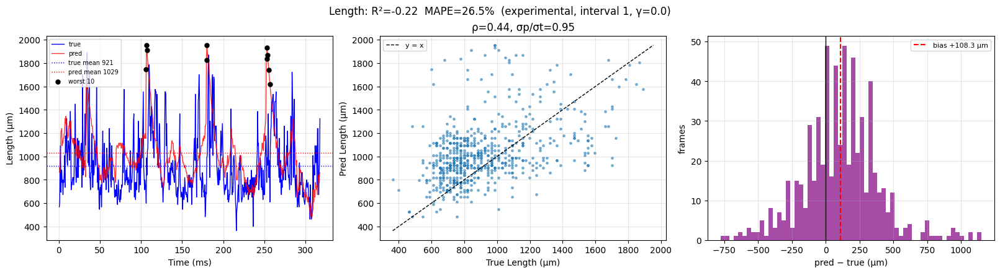

In [26]:
# =========================================================
# Why is R² negative? — decomposition for one quantity (QTY) (run after the peak+pool cell)
#   MSE = (μp-μt)² + (σp-σt)² + 2σpσt(1-ρ)        (exact, population std)
#   R²  = 1 - MSE/σt² = 1 - [bias term + scale term + correlation term]
#   + how much of SS_res comes from the worst frames (outliers)
# =========================================================
QTY = "length"             # "peak" | "length" | "width" | "area"   (arrays from the peak+pool cell)
_Q = {"peak":("Pt","Pp","K","Peak T"), "length":("Lt","Lp","μm","Length"),
      "width":("Wt","Wp","μm","Width"), "area":("At","Ap","mm²","Area")}[QTY]
_yt0=np.asarray(globals()[_Q[0]],float); _yp0=np.asarray(globals()[_Q[1]],float); _t0=np.asarray(tv,float)
_keep=~(np.isnan(_yt0)|np.isnan(_yp0)) & (_yt0>0)          # drop NaN and frames with no true pool (MAPE undefined)
print(f"{_Q[3]}: using {_keep.sum()} of {len(_yt0)} frames ({(~_keep).sum()} dropped: NaN or true value = 0)")
UNIT, QNAME = _Q[2], _Q[3]
yt,yp,tt=_yt0[_keep],_yp0[_keep],_t0[_keep]
e=yp-yt; n=len(e)
mt,mp=yt.mean(),yp.mean(); st,sp=yt.std(),yp.std(); rho=np.corrcoef(yt,yp)[0,1]
mse=np.mean(e**2); r2=1-np.sum(e**2)/np.sum((yt-mt)**2)
b_term=(mp-mt)**2/st**2; s_term=(sp-st)**2/st**2; c_term=2*sp*st*(1-rho)/st**2

print(f"N={n}   true: mean {mt:.4g} {UNIT}, std {st:.4g} {UNIT}   pred: mean {mp:.4g} {UNIT}, std {sp:.4g} {UNIT}")
print(f"MAPE {np.mean(np.abs(e)/yt)*100:.2f}%   RMSE {np.sqrt(mse):.4g} {UNIT}   bias {mp-mt:+.4g} {UNIT}   "
      f"corr ρ {rho:.3f}   RangeRatio σp/σt {sp/st:.2f}")
print(f"\nR² = {r2:.3f} = 1 - [ bias {b_term:.3f} + scale {s_term:.3f} + correlation {c_term:.3f} ]"
      f"   (check: {1-(b_term+s_term+c_term):.3f})")
print("   bias term        : constant offset vs the truth's spread")
print("   scale term       : prediction too flat (σp<σt) or too noisy (σp>σt)")
print("   correlation term : prediction doesn't move with the truth (ρ<1)")

# outliers: share of SS_res from the worst frames
order=np.argsort(e**2)[::-1]; cum=np.cumsum(e[order]**2)/np.sum(e**2)
for q in (1,5,10):
    kq=max(1,int(round(n*q/100)))
    r2_wo=1-np.sum(np.delete(e,order[:kq])**2)/np.sum((np.delete(yt,order[:kq])-np.delete(yt,order[:kq]).mean())**2)
    print(f"worst {q:>2}% frames ({kq:>4}) carry {cum[kq-1]*100:5.1f}% of SS_res;  R² without them = {r2_wo:.3f}")
print("\nworst 10 frames:")
print(f"{'t (ms)':>9} {'true':>9} {'pred':>9} {'err':>9}")
for i in order[:10]: print(f"{tt[i]:>9.3f} {yt[i]:>9.4g} {yp[i]:>9.4g} {e[i]:>+9.4g}")

# plots
fig,ax=plt.subplots(1,3,figsize=(16,4.3),constrained_layout=True)
ax[0].plot(tt,yt,'b-',lw=1,label='true'); ax[0].plot(tt,yp,'r-',lw=1,alpha=.8,label='pred')
ax[0].axhline(mt,color='b',ls=':',lw=1,label=f'true mean {mt:.0f}'); ax[0].axhline(mp,color='r',ls=':',lw=1,label=f'pred mean {mp:.0f}')
ax[0].scatter(tt[order[:10]],yp[order[:10]],s=25,c='k',zorder=5,label='worst 10')
ax[0].set_xlabel("Time (ms)"); ax[0].set_ylabel(f"{QNAME} ({UNIT})"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
lo,hi=min(yt.min(),yp.min()),max(yt.max(),yp.max())
ax[1].scatter(yt,yp,s=6,alpha=.5); ax[1].plot([lo,hi],[lo,hi],'k--',lw=1,label='y = x')
ax[1].set_xlabel(f"True {QNAME} ({UNIT})"); ax[1].set_ylabel(f"Pred {QNAME} ({UNIT})"); ax[1].set_title(f"ρ={rho:.2f}, σp/σt={sp/st:.2f}")
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
ax[2].hist(e,bins=60,color='purple',alpha=.7); ax[2].axvline(0,color='k',lw=1); ax[2].axvline(mp-mt,color='r',ls='--',label=f'bias {mp-mt:+.4g} {UNIT}')
ax[2].set_xlabel(f"pred − true ({UNIT})"); ax[2].set_ylabel("frames"); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
fig.suptitle(f"{QNAME}: R²={r2:.2f}  MAPE={np.mean(np.abs(e)/yt)*100:.1f}%  ({DATA_MODE}, interval {STEP_INTERVAL}, γ={GAMMA})")
plt.show()

case                                        MAPE %  RMSE K  bias K     ρ      R²
A  perfect (ŷ = y)                            0.00     0.0      +0  1.00    1.00
B  constant at the true mean (ŷ = 3000)       3.34   100.0      +0  0.00    0.00
C  correct shape, offset -150 K               5.01   150.0    -150  1.00   -1.25
D  correct shape, offset -50 K                1.67    50.0     -50  1.00    0.75
E  offset -150 K, truth std 500 K             5.14   150.0    -150  1.00    0.91

Hand calculation, case C (ŷ = y - 150):
  errors e_i = -150 for all 20 samples
  SS_res = Σ e_i²       = 20 × 150²          = 450,000
  SS_tot = Σ (y_i - ȳ)² = 20 × 100²          = 200,000   (ȳ = 3000, every |y_i-ȳ| = 100)
  R²     = 1 - SS_res/SS_tot = 1 - 450,000/200,000 = -1.25
  MAPE   = ½(150/2900 + 150/3100) × 100      = 5.01 %
  decomposition: 1 - [bias 2.25 + scale 0.00 + corr 0.00] = -1.25
  -> the prediction follows the truth perfectly (ρ = 1); R² < 0 only because the
     150 K offset is larger th

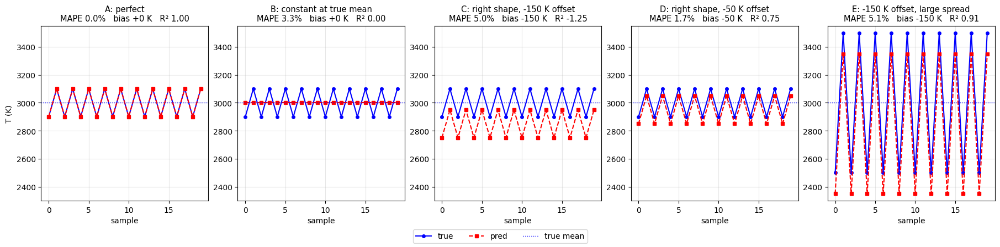

In [3]:
# =========================================================
# Small example: low MAPE but NEGATIVE R²  (20 samples, hand-calculable)
#   truth alternates 2900 / 3100 K  -> mean 3000 K, std 100 K   (like peak T: big mean, small spread)
#   R²   = 1 - SS_res/SS_tot,  SS_res = Σ(y-ŷ)²,  SS_tot = Σ(y-ȳ)²
#   MSE  = bias² + (σp-σt)² + 2σpσt(1-ρ)    ->   R² = 1 - MSE/σt²
# =========================================================
import numpy as np
import matplotlib.pyplot as plt

n = 20
y = np.array([2900, 3100]*10, float)             # truth: mean 3000, std 100 (population)

def metrics(y, yhat):
    e = yhat - y
    ss_res = np.sum(e**2); ss_tot = np.sum((y-y.mean())**2)
    mt, mp, st, sp = y.mean(), yhat.mean(), y.std(), yhat.std()
    rho = np.corrcoef(y, yhat)[0,1] if sp > 0 else 0.0
    return dict(MAPE=np.mean(np.abs(e)/y)*100, RMSE=np.sqrt(np.mean(e**2)), bias=mp-mt,
                rho=rho, R2=1-ss_res/ss_tot, SS_res=ss_res, SS_tot=ss_tot,
                bias_term=(mp-mt)**2/st**2, scale_term=(sp-st)**2/st**2,
                corr_term=2*sp*st*(1-rho)/st**2)

cases = {
    "A  perfect (ŷ = y)":                     y.copy(),
    "B  constant at the true mean (ŷ = 3000)": np.full(n, 3000.0),
    "C  correct shape, offset -150 K":        y - 150,
    "D  correct shape, offset -50 K":         y - 50,
}
print(f"{'case':42s} {'MAPE %':>7} {'RMSE K':>7} {'bias K':>7} {'ρ':>5} {'R²':>7}")
for name, yh in cases.items():
    m = metrics(y, yh)
    print(f"{name:42s} {m['MAPE']:>7.2f} {m['RMSE']:>7.1f} {m['bias']:>+7.0f} {m['rho']:>5.2f} {m['R2']:>7.2f}")

# --- same -150 K error, but on a truth with a LARGE spread (2500/3500, std 500) ---
y2 = np.array([2500, 3500]*10, float)
m2 = metrics(y2, y2-150)
print(f"{'E  offset -150 K, truth std 500 K':42s} {m2['MAPE']:>7.2f} {m2['RMSE']:>7.1f} "
      f"{m2['bias']:>+7.0f} {m2['rho']:>5.2f} {m2['R2']:>7.2f}")

# --- hand calculation for case C ---
yc = y - 150; mc = metrics(y, yc)
print("\nHand calculation, case C (ŷ = y - 150):")
print(f"  errors e_i = -150 for all 20 samples")
print(f"  SS_res = Σ e_i²       = 20 × 150²          = {mc['SS_res']:,.0f}")
print(f"  SS_tot = Σ (y_i - ȳ)² = 20 × 100²          = {mc['SS_tot']:,.0f}   (ȳ = 3000, every |y_i-ȳ| = 100)")
print(f"  R²     = 1 - SS_res/SS_tot = 1 - {mc['SS_res']:,.0f}/{mc['SS_tot']:,.0f} = {mc['R2']:.2f}")
print(f"  MAPE   = ½(150/2900 + 150/3100) × 100      = {mc['MAPE']:.2f} %")
print(f"  decomposition: 1 - [bias {mc['bias_term']:.2f} + scale {mc['scale_term']:.2f} + corr {mc['corr_term']:.2f}]"
      f" = {1-(mc['bias_term']+mc['scale_term']+mc['corr_term']):.2f}")
print("  -> the prediction follows the truth perfectly (ρ = 1); R² < 0 only because the")
print("     150 K offset is larger than the truth's own spread (100 K): (150/100)² = 2.25 > 1")

# --- figure: all 5 cases ---
k = np.arange(n)
plot_cases = [(y,  cases["A  perfect (ŷ = y)"],                      "A: perfect"),
              (y,  cases["B  constant at the true mean (ŷ = 3000)"],  "B: constant at true mean"),
              (y,  cases["C  correct shape, offset -150 K"],          "C: right shape, -150 K offset"),
              (y,  cases["D  correct shape, offset -50 K"],           "D: right shape, -50 K offset"),
              (y2, y2-150,                                            "E: -150 K offset, large spread")]
fig, ax = plt.subplots(1, 5, figsize=(18, 4.4), constrained_layout=True)
ylo = min(min(yy.min(), yh.min()) for yy, yh, _ in plot_cases) - 50
yhi = max(max(yy.max(), yh.max()) for yy, yh, _ in plot_cases) + 50
for a, (yy, yh, ttl) in zip(ax, plot_cases):
    m = metrics(yy, yh)
    a.plot(k, yy, 'bo-', ms=4, label='true'); a.plot(k, yh, 'rs--', ms=4, label='pred')
    a.axhline(yy.mean(), color='b', ls=':', lw=1, label='true mean')
    a.set_title(f"{ttl}\nMAPE {m['MAPE']:.1f}%   bias {m['bias']:+.0f} K   R² {m['R2']:.2f}", fontsize=10.5)
    a.set_xlabel("sample"); a.set_ylim(ylo, yhi); a.grid(alpha=.3)
ax[0].set_ylabel("T (K)")
h_, l_ = ax[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="outside lower center", ncol=3, fontsize=10)
plt.savefig("r2_vs_mape_example.png", dpi=200, bbox_inches="tight")
plt.show()

Length: using 636 of 636 frames (0 dropped: NaN or true value = 0)
N=636   true: mean 921.2 μm, std 269.5 μm   pred: mean 1029 μm, std 257.3 μm
MAPE 26.51%   RMSE 298.3 μm   bias +108.3 μm   corr ρ 0.444   RangeRatio σp/σt 0.95

R² = -0.225 = 1 - [ bias 0.162 + scale 0.002 + correlation 1.061 ]   (check: -0.225)
   bias term        : constant offset vs the truth's spread
   scale term       : prediction too flat (σp<σt) or too noisy (σp>σt)
   correlation term : prediction doesn't move with the truth (ρ<1)
worst  1% frames (   6) carry  12.1% of SS_res;  R² without them = -0.083
worst  5% frames (  32) carry  38.1% of SS_res;  R² without them = 0.182
worst 10% frames (  64) carry  52.8% of SS_res;  R² without them = 0.290

worst 10 frames:
   t (ms)      true      pred       err
  179.520     679.9      1828     +1149
  106.216     599.2      1746     +1147
  107.213     840.3      1912     +1071
  252.824     776.8      1837     +1060
  256.813     609.2      1618     +1008
  106.714 

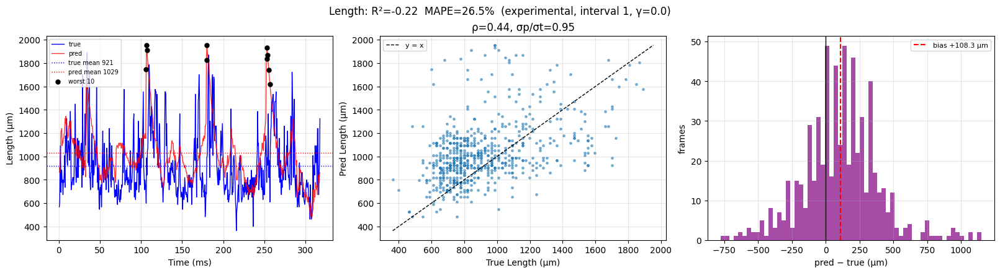

In [25]:
# =========================================================
# Why is R² negative? — decomposition for one quantity (QTY) (run after the peak+pool cell)
#   MSE = (μp-μt)² + (σp-σt)² + 2σpσt(1-ρ)        (exact, population std)
#   R²  = 1 - MSE/σt² = 1 - [bias term + scale term + correlation term]
#   + how much of SS_res comes from the worst frames (outliers)
# =========================================================
QTY = "length"             # "peak" | "length" | "width" | "area"   (arrays from the peak+pool cell)
_Q = {"peak":("Pt","Pp","K","Peak T"), "length":("Lt","Lp","μm","Length"),
      "width":("Wt","Wp","μm","Width"), "area":("At","Ap","mm²","Area")}[QTY]
_yt0=np.asarray(globals()[_Q[0]],float); _yp0=np.asarray(globals()[_Q[1]],float); _t0=np.asarray(tv,float)
_keep=~(np.isnan(_yt0)|np.isnan(_yp0)) & (_yt0>0)          # drop NaN and frames with no true pool (MAPE undefined)
print(f"{_Q[3]}: using {_keep.sum()} of {len(_yt0)} frames ({(~_keep).sum()} dropped: NaN or true value = 0)")
UNIT, QNAME = _Q[2], _Q[3]
yt,yp,tt=_yt0[_keep],_yp0[_keep],_t0[_keep]
e=yp-yt; n=len(e)
mt,mp=yt.mean(),yp.mean(); st,sp=yt.std(),yp.std(); rho=np.corrcoef(yt,yp)[0,1]
mse=np.mean(e**2); r2=1-np.sum(e**2)/np.sum((yt-mt)**2)
b_term=(mp-mt)**2/st**2; s_term=(sp-st)**2/st**2; c_term=2*sp*st*(1-rho)/st**2

print(f"N={n}   true: mean {mt:.4g} {UNIT}, std {st:.4g} {UNIT}   pred: mean {mp:.4g} {UNIT}, std {sp:.4g} {UNIT}")
print(f"MAPE {np.mean(np.abs(e)/yt)*100:.2f}%   RMSE {np.sqrt(mse):.4g} {UNIT}   bias {mp-mt:+.4g} {UNIT}   "
      f"corr ρ {rho:.3f}   RangeRatio σp/σt {sp/st:.2f}")
print(f"\nR² = {r2:.3f} = 1 - [ bias {b_term:.3f} + scale {s_term:.3f} + correlation {c_term:.3f} ]"
      f"   (check: {1-(b_term+s_term+c_term):.3f})")
print("   bias term        : constant offset vs the truth's spread")
print("   scale term       : prediction too flat (σp<σt) or too noisy (σp>σt)")
print("   correlation term : prediction doesn't move with the truth (ρ<1)")

# outliers: share of SS_res from the worst frames
order=np.argsort(e**2)[::-1]; cum=np.cumsum(e[order]**2)/np.sum(e**2)
for q in (1,5,10):
    kq=max(1,int(round(n*q/100)))
    r2_wo=1-np.sum(np.delete(e,order[:kq])**2)/np.sum((np.delete(yt,order[:kq])-np.delete(yt,order[:kq]).mean())**2)
    print(f"worst {q:>2}% frames ({kq:>4}) carry {cum[kq-1]*100:5.1f}% of SS_res;  R² without them = {r2_wo:.3f}")
print("\nworst 10 frames:")
print(f"{'t (ms)':>9} {'true':>9} {'pred':>9} {'err':>9}")
for i in order[:10]: print(f"{tt[i]:>9.3f} {yt[i]:>9.4g} {yp[i]:>9.4g} {e[i]:>+9.4g}")

# plots
fig,ax=plt.subplots(1,3,figsize=(16,4.3),constrained_layout=True)
ax[0].plot(tt,yt,'b-',lw=1,label='true'); ax[0].plot(tt,yp,'r-',lw=1,alpha=.8,label='pred')
ax[0].axhline(mt,color='b',ls=':',lw=1,label=f'true mean {mt:.0f}'); ax[0].axhline(mp,color='r',ls=':',lw=1,label=f'pred mean {mp:.0f}')
ax[0].scatter(tt[order[:10]],yp[order[:10]],s=25,c='k',zorder=5,label='worst 10')
ax[0].set_xlabel("Time (ms)"); ax[0].set_ylabel(f"{QNAME} ({UNIT})"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
lo,hi=min(yt.min(),yp.min()),max(yt.max(),yp.max())
ax[1].scatter(yt,yp,s=6,alpha=.5); ax[1].plot([lo,hi],[lo,hi],'k--',lw=1,label='y = x')
ax[1].set_xlabel(f"True {QNAME} ({UNIT})"); ax[1].set_ylabel(f"Pred {QNAME} ({UNIT})"); ax[1].set_title(f"ρ={rho:.2f}, σp/σt={sp/st:.2f}")
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
ax[2].hist(e,bins=60,color='purple',alpha=.7); ax[2].axvline(0,color='k',lw=1); ax[2].axvline(mp-mt,color='r',ls='--',label=f'bias {mp-mt:+.4g} {UNIT}')
ax[2].set_xlabel(f"pred − true ({UNIT})"); ax[2].set_ylabel("frames"); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
fig.suptitle(f"{QNAME}: R²={r2:.2f}  MAPE={np.mean(np.abs(e)/yt)*100:.1f}%  ({DATA_MODE}, interval {STEP_INTERVAL}, γ={GAMMA})")
plt.show()

Length  N=636  frame = 0.499 ms

1) LAG SCAN  (lag>0: pred is EARLY, lag<0: pred is LATE)
   lag 0           : ρ 0.444   R² -0.225   R² bias-removed -0.063
   best lag -1 (-0.50 ms): ρ 0.462   R² -0.195   R² bias-removed -0.031

2) SMOOTHING  ρ vs moving-average window
   w =   1 frames (  0.50 ms): ρ 0.444
   w =   2 frames (  1.00 ms): ρ 0.494
   w =   3 frames (  1.50 ms): ρ 0.520
   w =   5 frames (  2.49 ms): ρ 0.552
   w =   8 frames (  3.99 ms): ρ 0.580
   w =  12 frames (  5.98 ms): ρ 0.613
   w =  20 frames (  9.97 ms): ρ 0.679
   w =  30 frames ( 14.96 ms): ρ 0.747

3) WITHOUT worst 10% frames: ρ 0.647   R² +0.286   R² bias-removed +0.383

VERDICT
   time shift : no  (best lag -1, ρ gain +0.02)
   noise      : YES  (ρ gain with smoothing +0.30)
   bursts     : YES  (ρ gain without worst 10% +0.20)


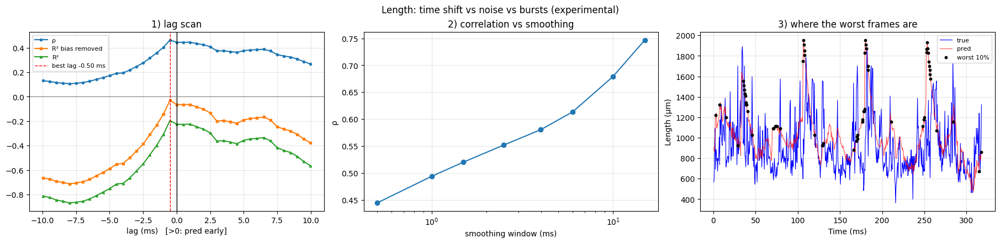

In [22]:
# =========================================================
# Is the low correlation a TIME SHIFT (asynchronization), NOISE, or LOCAL BURSTS?
#   1) lag scan   : shift pred by ±MAX_LAG frames -> ρ(lag), R²(lag), R²_bias_removed(lag)
#                   sharp peak at lag≠0  => pred is the right signal, early/late (async)
#   2) smoothing  : moving average over w frames -> ρ(w)
#                   ρ rises fast with w  => trends agree, frame-to-frame jitter disagrees (noise)
#   3) bursts     : same metrics without the worst BURST_PCT % frames
#   uses the arrays of the peak+pool cell; QTY as in the R² cells
# =========================================================
QTY       = "length"          # "peak" | "length" | "width" | "area"
MAX_LAG   = 20                # frames each side (exp 2 kHz: 1 frame = 0.5 ms)
WINDOWS   = [1,2,3,5,8,12,20,30]
BURST_PCT = 10

_Q = {"peak":("Pt","Pp","K","Peak T"), "length":("Lt","Lp","μm","Length"),
      "width":("Wt","Wp","μm","Width"), "area":("At","Ap","mm²","Area")}[QTY]
yt=np.asarray(globals()[_Q[0]],float); yp=np.asarray(globals()[_Q[1]],float); tt=np.asarray(tv,float)
UNIT,QNAME=_Q[2],_Q[3]
assert not (np.isnan(yt).any() or np.isnan(yp).any()), "NaN in the series - lag scan needs a contiguous series"
dt_ms=float(np.median(np.diff(tt)))

def _m(a,b):
    e=b-a; sst=np.sum((a-a.mean())**2)
    return np.corrcoef(a,b)[0,1], 1-np.sum(e**2)/sst, 1-np.sum((e-e.mean())**2)/sst

# 1) lag scan: lag>0 = prediction compared with LATER truth (pred is early)
lags=np.arange(-MAX_LAG,MAX_LAG+1); rho_l=[]; r2_l=[]; r2b_l=[]
for L in lags:
    a,b=(yt[L:],yp[:len(yp)-L]) if L>=0 else (yt[:L],yp[-L:])
    r,r2,r2b=_m(a,b); rho_l.append(r); r2_l.append(r2); r2b_l.append(r2b)
rho_l,r2_l,r2b_l=map(np.array,(rho_l,r2_l,r2b_l)); i0=MAX_LAG; ib=int(np.argmax(rho_l))
# 2) smoothing scan
def _ma(x,w): return np.convolve(x,np.ones(w)/w,mode='valid')
rho_w=[np.corrcoef(_ma(yt,w),_ma(yp,w))[0,1] for w in WINDOWS]
# 3) without bursts
e=yp-yt; keep=e**2<=np.percentile(e**2,100-BURST_PCT)
r_k,r2_k,r2b_k=_m(yt[keep],yp[keep])

print(f"{QNAME}  N={len(yt)}  frame = {dt_ms:.3f} ms")
print(f"\n1) LAG SCAN  (lag>0: pred is EARLY, lag<0: pred is LATE)")
print(f"   lag 0           : ρ {rho_l[i0]:.3f}   R² {r2_l[i0]:+.3f}   R² bias-removed {r2b_l[i0]:+.3f}")
print(f"   best lag {lags[ib]:+d} ({lags[ib]*dt_ms:+.2f} ms): ρ {rho_l[ib]:.3f}   R² {r2_l[ib]:+.3f}   R² bias-removed {r2b_l[ib]:+.3f}")
print(f"\n2) SMOOTHING  ρ vs moving-average window")
for w,r in zip(WINDOWS,rho_w): print(f"   w = {w:>3} frames ({w*dt_ms:6.2f} ms): ρ {r:.3f}")
print(f"\n3) WITHOUT worst {BURST_PCT}% frames: ρ {r_k:.3f}   R² {r2_k:+.3f}   R² bias-removed {r2b_k:+.3f}")

# verdict
gain_lag=rho_l[ib]-rho_l[i0]; gain_sm=rho_w[-1]-rho_w[0]; gain_b=r_k-rho_l[i0]
print("\nVERDICT")
print(f"   time shift : {'YES' if (lags[ib]!=0 and gain_lag>0.15) else 'no'}  (best lag {lags[ib]:+d}, ρ gain {gain_lag:+.2f})")
print(f"   noise      : {'YES' if gain_sm>0.2 else 'no'}  (ρ gain with smoothing {gain_sm:+.2f})")
print(f"   bursts     : {'YES' if gain_b>0.2 else 'no'}  (ρ gain without worst {BURST_PCT}% {gain_b:+.2f})")

# figure
fig,ax=plt.subplots(1,3,figsize=(18,4.3),constrained_layout=True)
ax[0].plot(lags*dt_ms,rho_l,'o-',ms=3,label='ρ'); ax[0].plot(lags*dt_ms,r2b_l,'s-',ms=3,label='R² bias removed')
ax[0].plot(lags*dt_ms,r2_l,'^-',ms=3,label='R²'); ax[0].axvline(0,color='k',lw=1); ax[0].axhline(0,color='gray',lw=.8)
ax[0].axvline(lags[ib]*dt_ms,color='r',ls='--',lw=1,label=f'best lag {lags[ib]*dt_ms:+.2f} ms')
ax[0].set_xlabel("lag (ms)   [>0: pred early]"); ax[0].set_title("1) lag scan"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].plot(np.array(WINDOWS)*dt_ms,rho_w,'o-'); ax[1].set_xscale('log')
ax[1].set_xlabel("smoothing window (ms)"); ax[1].set_ylabel("ρ"); ax[1].set_title("2) correlation vs smoothing"); ax[1].grid(alpha=.3)
ax[2].plot(tt,yt,'b-',lw=.8,label='true'); ax[2].plot(tt,yp,'r-',lw=.8,alpha=.7,label='pred')
ax[2].scatter(tt[~keep],yp[~keep],s=10,c='k',zorder=5,label=f'worst {BURST_PCT}%')
ax[2].set_xlabel("Time (ms)"); ax[2].set_ylabel(f"{QNAME} ({UNIT})"); ax[2].set_title("3) where the worst frames are")
ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
fig.suptitle(f"{QNAME}: time shift vs noise vs bursts ({DATA_MODE})")
plt.savefig(f"sync_test_{QTY}_{DATA_MODE}.png",dpi=200,bbox_inches="tight"); plt.show()

In [28]:
e=Lp-Lt; burst=e**2>np.percentile(e**2,90)
mask=np.convolve(burst,np.ones(3),'same')>0                 # bursts + 1 frame each side
def nanma(x,w):                                             # moving average ignoring masked frames
    x=np.where(mask,np.nan,x); k=np.ones(w)
    s=np.convolve(np.nan_to_num(x),k,'valid'); c=np.convolve(~np.isnan(x),k,'valid'); return s/np.maximum(c,1)
for w in (1,3,8,20,30):
    a,b=nanma(Lt,w),nanma(Lp,w); ok=~(np.isnan(a)|np.isnan(b))
    print(f"no bursts, w={w:>2}: ρ {np.corrcoef(a[ok],b[ok])[0,1]:.3f}")
ok=~mask[1:]&~mask[:-1]
print(f"lag-1 autocorr of TRUE length (no bursts): {np.corrcoef(Lt[1:][ok],Lt[:-1][ok])[0,1]:.3f}")

no bursts, w= 1: ρ 0.907
no bursts, w= 3: ρ 0.905
no bursts, w= 8: ρ 0.863
no bursts, w=20: ρ 0.824
no bursts, w=30: ρ 0.846
lag-1 autocorr of TRUE length (no bursts): 0.725


In [29]:
_sv=lambda a,b: np.array([(xPath[b]-xPath[a]),(yPath[b]-yPath[a])])/max(float(tPath[b]-tPath[a]),1e-12)
def _same(u,w): nu,nw=np.linalg.norm(u),np.linalg.norm(w); return nu>1e-9 and nw>1e-9 and np.linalg.norm(u-w)<=TURN_TOL*max(nu,nw)
turn_k=[k for k in range(2,len(tPath)-1) if not (_same(_sv(k-1,k),_sv(k-2,k-1)) or _same(_sv(k-1,k),_sv(k,k+1)))]
k_rec=np.round((np.asarray(tv)/1000-tPath[0])/np.median(np.diff(tPath))).astype(int)
for N_AFTER in (2,5,10):                                       # frames excluded after each turn
    near=np.zeros(len(k_rec),bool)
    for kt in turn_k: near|=(k_rec>=kt-1)&(k_rec<=kt+N_AFTER)
    a,b=Lt[~near],Lp[~near]; e=b-a
    print(f"exclude turn-1..turn+{N_AFTER:>2}: {near.sum():>3} frames out ({near.mean()*100:4.1f}%)  "
          f"ρ {np.corrcoef(a,b)[0,1]:.3f}  R² {1-np.sum(e**2)/np.sum((a-a.mean())**2):+.3f}")
burst=(Lp-Lt)**2>np.percentile((Lp-Lt)**2,90); near5=np.zeros(len(k_rec),bool)
for kt in turn_k: near5|=(k_rec>=kt-1)&(k_rec<=kt+5)
print(f"turns found: {len(turn_k)};  share of worst-10% frames lying near a turn (±5): {near5[burst].mean()*100:.0f}%")

exclude turn-1..turn+ 2:  60 frames out ( 9.4%)  ρ 0.466  R² -0.059
exclude turn-1..turn+ 5: 100 frames out (15.7%)  ρ 0.414  R² -0.078
exclude turn-1..turn+10: 164 frames out (25.8%)  ρ 0.382  R² -0.015
turns found: 16;  share of worst-10% frames lying near a turn (±5): 30%


line     k range    N true mean  true σ    bias  MAPE%      ρ      R² worst10%
   0     0-66      61       977     196    +138   25.5  -0.08   -0.96        4
   1    66-139     68       925     254    +108   23.3   0.47   -0.12       10
   2   139-180     36       806     186    +232   37.6  -0.14   -1.77        6
   3   180-213     28       929     238     +93   25.1   0.32   -0.05        0
   4   213-286     68      1083     286     +22   18.7   0.51   +0.05        6
   6   287-360     68       846     255    +101   30.9   0.00   -0.38        8
   7   360-433     68      1012     317    +128   25.3   0.64   +0.21        4
   8   433-448     10       800     139    +141   21.3   0.61   -0.68        0
   9   448-506     53       787     152     +65   20.3   0.21   -0.81        3
  11   507-555     43      1092     271    +100   23.9   0.33   -0.63        7
  12   555-581     21      1022     302     +92   27.2   0.45   +0.10        1
  16   614-636     17       891     214    -219   22

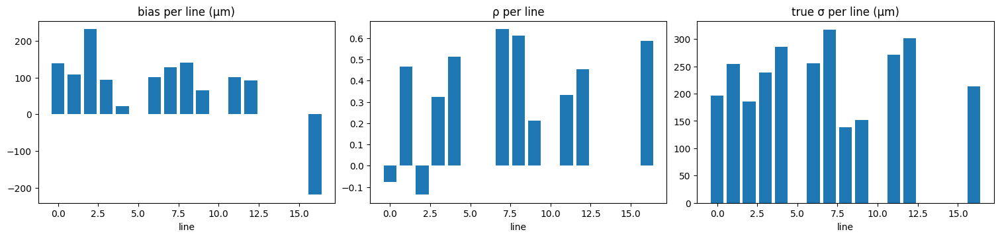

In [30]:
EDGE = 2                                        # frames dropped at each end of a line (turn influence)
bounds=[0]+sorted(turn_k)+[len(tPath)-1]
e_all=(Lp-Lt)**2; worst=e_all>np.percentile(e_all,90)
print(f"{'line':>4} {'k range':>11} {'N':>4} {'true mean':>9} {'true σ':>7} {'bias':>7} {'MAPE%':>6} {'ρ':>6} {'R²':>7} {'worst10%':>8}")
rows=[]
for i in range(len(bounds)-1):
    sel=(k_rec>bounds[i]+EDGE)&(k_rec<bounds[i+1]-EDGE)
    if sel.sum()<10: continue
    a,b=Lt[sel],Lp[sel]; e=b-a
    rho=np.corrcoef(a,b)[0,1] if a.std()>0 and b.std()>0 else np.nan
    r2=1-np.sum(e**2)/np.sum((a-a.mean())**2)
    rows.append((i,a.mean(),a.std(),e.mean(),rho,r2))
    print(f"{i:>4} {bounds[i]:>5}-{bounds[i+1]:<5} {sel.sum():>4} {a.mean():>9.0f} {a.std():>7.0f} {e.mean():>+7.0f} "
          f"{np.mean(np.abs(e)/a)*100:>6.1f} {rho:>6.2f} {r2:>+7.2f} {worst[sel].sum():>8}")
r=np.array(rows)
fig,ax=plt.subplots(1,3,figsize=(15,3.5),constrained_layout=True)
ax[0].bar(r[:,0],r[:,3]); ax[0].set_title("bias per line (μm)"); ax[0].set_xlabel("line")
ax[1].bar(r[:,0],r[:,4]); ax[1].set_title("ρ per line"); ax[1].set_xlabel("line")
ax[2].bar(r[:,0],r[:,2]); ax[2].set_title("true σ per line (μm)"); ax[2].set_xlabel("line")
plt.show()

In [32]:
print(f"{'line':>4} {'N':>4} {'true σ':>7} {'noise σ':>8} {'noise share':>11} {'R²_max':>7} {'lag1 ac':>8}")
for i in range(len(bounds)-1):
    sel=(k_rec>bounds[i]+EDGE)&(k_rec<bounds[i+1]-EDGE)
    if sel.sum()<10: continue
    a=Lt[sel]; d=np.diff(a); sn2=np.var(d)/2; st2=np.var(a)
    print(f"{i:>4} {sel.sum():>4} {np.sqrt(st2):>7.0f} {np.sqrt(sn2):>8.0f} {min(sn2/st2,9.99):>11.2f} "
          f"{1-sn2/st2:>+7.2f} {np.corrcoef(a[1:],a[:-1])[0,1]:>8.2f}")

line    N  true σ  noise σ noise share  R²_max  lag1 ac
   0   61     196      171        0.76   +0.24     0.25
   1   68     254      182        0.51   +0.49     0.43
   2   36     186      123        0.43   +0.57     0.57
   3   28     238      201        0.71   +0.29     0.27
   4   68     286      134        0.22   +0.78     0.78
   6   68     255      140        0.30   +0.70     0.70
   7   68     317      166        0.27   +0.73     0.73
   8   10     139      110        0.63   +0.37     0.34
   9   53     152      115        0.57   +0.43     0.43
  11   43     271      152        0.32   +0.68     0.69
  12   21     302      249        0.68   +0.32     0.32
  16   17     214      163        0.58   +0.42     0.39


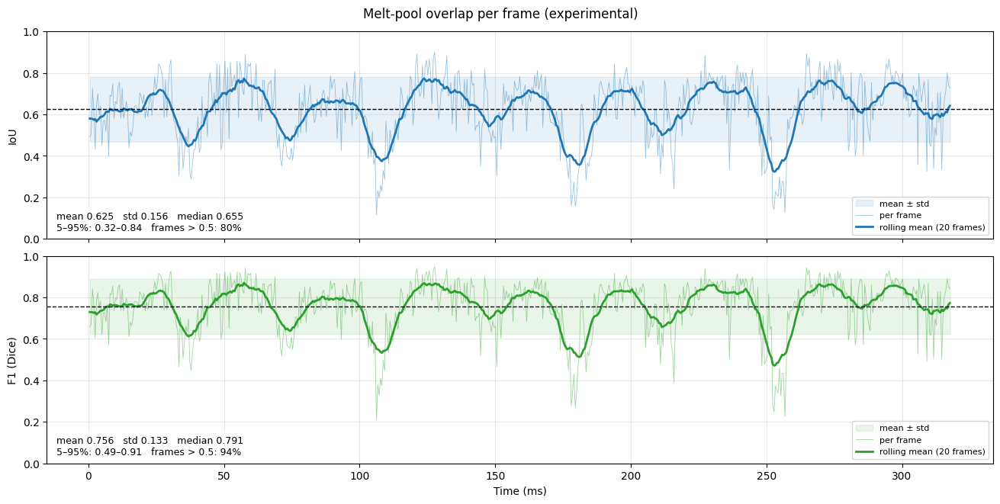

               N   mean    std  median    p05    p95  >0.5 %
IoU          636  0.625  0.156   0.655   0.32   0.84      80
F1 (Dice)    636  0.756  0.133   0.791   0.49   0.91      94


In [22]:
# =========================================================
# IoU and Dice (F1) per frame: time series + statistics + whiteness test  (run after fitness_cell.py)
#   left : per frame, rolling mean, mean ± std band, stats box
#   right: autocorrelation (ACF) with the white-noise 95% band ±1.96/√N
#   Ljung–Box Q over MAX_LAG lags: p > 0.05 -> consistent with white noise
# =========================================================
from scipy.stats import chi2
ROLL    = 20          # frames in the rolling mean (exp: 20 frames = 10 ms)
MAX_LAG = 20          # lags for ACF / Ljung–Box

t_ms = R["t"]*1000
def _roll(x, w):
    v=np.where(np.isnan(x),0,x); c=(~np.isnan(x)).astype(float); k=np.ones(w)
    return np.convolve(v,k,'same')/np.maximum(np.convolve(c,k,'same'),1)
def _acf(x, L):
    x=x[~np.isnan(x)]; x=x-x.mean(); d=np.sum(x**2)
    return np.array([np.sum(x[k:]*x[:len(x)-k])/d for k in range(1,L+1)]), len(x)
def _stats(x):
    v=x[~np.isnan(x)]; r,n=_acf(x,MAX_LAG)
    Q=n*(n+2)*np.sum(r**2/(n-np.arange(1,MAX_LAG+1))); p=chi2.sf(Q,MAX_LAG)
    return dict(n=n,mean=v.mean(),std=v.std(ddof=1),median=np.median(v),p05=np.percentile(v,5),
                p95=np.percentile(v,95),gt05=np.mean(v>0.5)*100,lag1=r[0],Q=Q,p=p,acf=r,
                out=np.mean(np.abs(r)>1.96/np.sqrt(n))*100)

S={name:_stats(R[key]) for key,name in (("IoU","IoU"),("Dice","F1 (Dice)"))}
fig,ax=plt.subplots(2,1,figsize=(13,6.5),sharex=True,constrained_layout=True)
for a,(key,name,col) in zip(ax,[("IoU","IoU","tab:blue"),("Dice","F1 (Dice)","tab:green")]):
    y=R[key]; s=S[name]
    a.fill_between(t_ms,s['mean']-s['std'],s['mean']+s['std'],color=col,alpha=.10,label='mean ± std')
    a.plot(t_ms,y,'-',color=col,lw=.6,alpha=.45,label='per frame')
    a.plot(t_ms,_roll(y,ROLL),'-',color=col,lw=2,label=f'rolling mean ({ROLL} frames)')
    a.axhline(s['mean'],color='k',ls='--',lw=1)
    if "turn_k" in globals():
        for kt in turn_k: a.axvline(tPath[kt]*1000,color='gray',lw=.6,alpha=.5)
    a.text(0.01,0.03,f"mean {s['mean']:.3f}   std {s['std']:.3f}   median {s['median']:.3f}\n"
                     f"5–95%: {s['p05']:.2f}–{s['p95']:.2f}   frames > 0.5: {s['gt05']:.0f}%",
           transform=a.transAxes,fontsize=9,va='bottom',bbox=dict(facecolor='white',alpha=.8,edgecolor='none'))
    a.set_ylim(0,1); a.set_ylabel(name); a.grid(alpha=.3); a.legend(fontsize=8,loc='lower right')
ax[1].set_xlabel("Time (ms)")
fig.suptitle(f"Melt-pool overlap per frame ({DATA_MODE})"
             + ("   grey lines = turnarounds" if "turn_k" in globals() else ""))
plt.savefig(f"iou_f1_over_time_{DATA_MODE}.png",dpi=200,bbox_inches="tight"); plt.show()

print(f"{'':10s} {'N':>5} {'mean':>6} {'std':>6} {'median':>7} {'p05':>6} {'p95':>6} {'>0.5 %':>7}")
for name,s in S.items():
    print(f"{name:10s} {s['n']:>5} {s['mean']:>6.3f} {s['std']:>6.3f} {s['median']:>7.3f} {s['p05']:>6.2f} "
          f"{s['p95']:>6.2f} {s['gt05']:>7.0f}")